<p style="color:#334155; font-size:12px; letter-spacing:1.5px;"><strong>PORTFOLIO DATA SCIENCE · SÉRIES TEMPORELLES · ÉQUATEUR</strong></p>

<h1 style="color:#2563EB; font-weight:700; font-size:34px;">Prévision des ventes<br>et simulation de stock</h1>

De l’historique quotidien à une prévision évaluée, puis à une décision de réapprovisionnement simulée.

<table style="border-collapse:collapse; width:100%; background-color:#F3F4F6; color:#000000;">
<tr><td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><strong>3 000 888</strong><br>observations de ventes</td><td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><strong>54</strong><br>magasins</td><td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><strong>33</strong><br>familles de produits</td><td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><strong>4 × 14 jours</strong><br>validation chronologique</td></tr>
</table>

**Question métier.** Quelles ventes prévoir sur deux semaines, et quel compromis entre service et stock obtenir dans un scénario de réapprovisionnement ?

**Repères de la version évaluée.** RMSLE local corrigé : **0,4038**. Dernière soumission Kaggle acceptée : **0,58880**. Les périodes évaluées diffèrent ; ces deux scores ne sont pas directement comparables. Le score Kaggle est celui attribué par Kaggle à la soumission acceptée ; les résultats locaux sont recalculés dans ce notebook.

> **Portée de l’étude** — Les ventes sont observées par magasin et famille, pas par article. Les stocks réels, ruptures observées, délais fournisseurs et coûts ne sont pas disponibles. La simulation est pédagogique.

Ce notebook s’exécute seul depuis les sept fichiers bruts Kaggle. Les données restent locales et ne sont pas incluses dans le dépôt. Les cellules de code sont repliées à l’ouverture pour faciliter la lecture ; elles restent disponibles pour examiner les calculs.

<h2 style="color:#2563EB; font-weight:700;">Guide de lecture</h2>


<table style="border-collapse:collapse; width:100%; background-color:#F3F4F6; color:#000000;">
<thead>
<tr>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Parcours</th>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Étapes</th>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Ce que l’on cherche à comprendre</th>
</tr>
</thead>
<tbody>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><strong>01 · Cadrer</strong></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><a href="#section-1" style="color:#000000; text-decoration:underline;">1 à 3</a></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Objectif, environnement et dictionnaire des données</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><strong>02 · Fiabiliser</strong></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><a href="#section-4" style="color:#000000; text-decoration:underline;">4 à 8</a></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Qualité, nettoyage et statistiques de toutes les variables</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><strong>03 · Explorer</strong></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><a href="#section-9" style="color:#000000; text-decoration:underline;">9 à 14</a></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Ventes, familles, magasins, promotions et calendrier</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><strong>04 · Prévoir</strong></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><a href="#section-15" style="color:#000000; text-decoration:underline;">15 à 19</a></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Validation, baselines, modèle et erreurs</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><strong>05 · Simuler</strong></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><a href="#section-20" style="color:#000000; text-decoration:underline;">20</a></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Compromis entre service, commande et stock</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><strong>06 · Restituer</strong></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><a href="#section-21" style="color:#000000; text-decoration:underline;">21 à 22</a></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Soumission, résultats, limites et perspectives</td>
</tr>
</tbody>
</table>

**Pour une lecture rapide :** consulter les figures de synthèse des sections 10, 12, 13, 19 et 20, puis le [bilan final](#section-22). Les tableaux détaillés se déplient sans supprimer les données de l’analyse.

<details>
<summary><strong>Afficher les 22 étapes du notebook</strong></summary>

1. [Présentation du projet](#section-1)
2. [Configuration et reproductibilité](#section-2)
3. [Présentation des données](#section-3)
4. [Diagnostic avant nettoyage](#section-4)
5. [Nettoyage et préparation](#section-5)
6. [Vérification après nettoyage](#section-6)
7. [Statistiques descriptives numériques](#section-7)
8. [Statistiques des catégories, dates et identifiants](#section-8)
9. [Exploration globale des ventes](#section-9)
10. [Analyse des 33 familles](#section-10)
11. [Analyse des 54 magasins](#section-11)
12. [Promotions, transactions et pétrole](#section-12)
13. [Calendrier et événements](#section-13)
14. [Synthèse de l’exploration](#section-14)
15. [Protocole de validation](#section-15)
16. [Modèles de référence](#section-16)
17. [Variables du modèle](#section-17)
18. [Modélisation LightGBM](#section-18)
19. [Évaluation et analyse des erreurs](#section-19)
20. [Simulation de stock](#section-20)
21. [Prévisions finales et soumission Kaggle](#section-21)
22. [Conclusion et perspectives](#section-22)

</details>

<hr>

<p style="color:#2563EB; font-size:13px; letter-spacing:1px;"><strong>PARTIE 01 · CADRER</strong></p>

Définir le besoin, le périmètre et les données.

<a id="section-1"></a>

<h2 style="color:#2563EB; font-weight:700;">1. Présentation du projet</h2>

**Question :** Comment prévoir les ventes quotidiennes et étudier leur traduction en besoins de stock ?


<table style="border-collapse:collapse; width:100%; background-color:#F3F4F6; color:#000000;">
<thead>
<tr>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Élément</th>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Choix de l’étude</th>
</tr>
</thead>
<tbody>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Cible</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><code style="background-color:transparent; color:#000000;">sales</code>, ventes observées par date, magasin et famille</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Granularité</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Une série par couple <code style="background-color:transparent; color:#000000;">store_nbr</code>–<code style="background-color:transparent; color:#000000;">family</code> ; aucune prévision au niveau article</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Horizon métier</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">14 jours, évalués sur quatre plis chronologiques</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Horizon Kaggle</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">16 jours, avec un contrôle local complémentaire sur cet horizon</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Modèles</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Naïf hebdomadaire, moyenne des quatre semaines par jour, LightGBM récursif</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Métriques</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">RMSLE pour le classement local ; MAE, WAPE et biais pour compléter la lecture</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Stock</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Scénarios hypothétiques de délai et de stock initial, comparés sur les mêmes ventes</td>
</tr>
</tbody>
</table>

Les ventes peuvent être contraintes par l’assortiment ou des stocks inconnus. Une vente nulle ne prouve pas une rupture ; la demande non servie réelle n’est pas observable.

<a id="section-2"></a>

<h2 style="color:#2563EB; font-weight:700;">2. Configuration et reproductibilité</h2>

**Question :** Comment reproduire les calculs et conserver une présentation cohérente ?

Python 3.12 et les versions de `requirements.txt` constituent l’environnement de référence. L’exécution complète comprend seize entraînements de backtest puis un entraînement final ; sa durée dépend de la machine. Les exports de CSV sont désactivés par défaut.

In [1]:
from pathlib import Path
from importlib.metadata import version
import platform
import gc
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, Markdown, display
from pandas.io.formats.style import Styler
from pandas.api.types import is_bool_dtype, is_datetime64_any_dtype, is_integer_dtype, is_numeric_dtype
from html import escape
import unicodedata
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

HORIZON_JOURS = 14
N_FOLDS = 4
HISTORIQUE_JOURS = 365
RETARDS = (7, 14, 28)
FENETRES_MOBILES = (7, 28)
CLES_SERIE = ["store_nbr", "family"]
EXPORTER_FICHIERS = False
ECRASER_EXPORTS = False

COULEUR_TITRES = "#17324D"
BLEU = COULEUR_TITRES
COULEURS = {
    "ventes": "#1D4ED8", "prevision": "#0F766E", "promotion": "#B45309",
    "manquant": "#B91C1C", "baseline": "#334155",
}
PALETTE = {
    "Naïf saisonnier hebdomadaire": "#334155",
    "Moyenne des 4 semaines par jour": "#B45309",
    "LightGBM récursif": "#0F766E",
}
NOMS_JOURS = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
CMAP_SEQUENTIELLE = LinearSegmentedColormap.from_list("stock_sequentiel", ["#DBEAFE", "#3B82F6", "#17324D"])
CMAP_DIVERGENTE = LinearSegmentedColormap.from_list("stock_divergent", ["#1D4ED8", "#E5E7EB", "#B91C1C"])
sns.set_theme(style="whitegrid", context="notebook", palette=["#1D4ED8", "#0F766E", "#B45309", "#6D28D9", "#334155"])
plt.rcParams.update({
    "figure.dpi": 85, "savefig.dpi": 110, "figure.figsize": (12, 5),
    "axes.titlecolor": COULEUR_TITRES, "axes.titleweight": "bold",
    "axes.labelcolor": "#000000", "text.color": "#000000", "xtick.color": "#000000", "ytick.color": "#000000", "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "grid.alpha": 0.18,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "legend.frameon": False, "axes.formatter.useoffset": False,
})
pd.set_option("display.max_columns", 30)

DOSSIER_BRUT = Path("data/raw/store-sales-time-series-forecasting")
RACINE_PROJET = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / DOSSIER_BRUT / "train.csv").is_file()), None)
if RACINE_PROJET is None:
    raise FileNotFoundError("Placez les fichiers Kaggle dans data/raw/store-sales-time-series-forecasting/.")
RAW_DIR = RACINE_PROJET / DOSSIER_BRUT
PROCESSED_DIR = RACINE_PROJET / "data/processed"
SORTIE = PROCESSED_DIR / "submission.csv"


def nom_simple(value):
    return unicodedata.normalize("NFKD", str(value)).encode("ascii", "ignore").decode().lower().replace(" ", "_")

def afficher_tableau(frame, decimales=3, repliable=None, titre=None):
    """Présentation uniquement : les valeurs du DataFrame restent inchangées."""
    if isinstance(frame, Styler):
        frame = frame.data
    if isinstance(frame, pd.Series):
        frame = frame.to_frame()
    formats = {}
    for column in frame.columns:
        name = nom_simple(column)
        values = frame[column]
        if is_bool_dtype(values.dtype):
            formats[column] = lambda x: "Oui" if x else "Non"
        elif is_datetime64_any_dtype(values.dtype):
            formats[column] = lambda x: x.strftime("%Y-%m-%d")
        elif is_numeric_dtype(values.dtype):
            if name.startswith("part_") or name in {"proportion", "wape", "taux_service", "facteur_stock_initial"} or "_wape" in name:
                formats[column] = "{:.1%}"
            elif "rmsle" in name:
                formats[column] = "{:.4f}"
            elif is_integer_dtype(values.dtype):
                formats[column] = "{:,d}"
            elif name in {"lignes", "avant", "apres", "observations", "effectif", "manquants"}:
                formats[column] = "{:,.0f}"
            else:
                formats[column] = "{:,." + str(decimales) + "f}"
    styled = frame.style.format(formats, decimal=",", thousands="\u202f", na_rep="—", escape="html")
    styled = styled.set_table_styles([
        {"selector": "", "props": [("border-collapse", "collapse"), ("width", "100%"), ("background-color", "#F3F4F6"), ("color", "#000000")]},
        {"selector": "th", "props": [("background-color", "#D1D5DB"), ("color", "#000000"), ("font-weight", "700"), ("padding", "9px 12px"), ("text-align", "left"), ("border-bottom", "2px solid #9CA3AF")]},
        {"selector": "td", "props": [("background-color", "#F3F4F6"), ("color", "#000000"), ("padding", "8px 12px"), ("border-bottom", "1px solid #CBD5E1"), ("font-size", "12px")]},
        {"selector": "tbody tr:nth-child(even) td", "props": [("background-color", "#E5E7EB"), ("color", "#000000")]},
        {"selector": "caption", "props": [("caption-side", "top"), ("text-align", "left"), ("color", "#2563EB"), ("font-weight", "600"), ("padding", "8px 0")]},
    ])
    if isinstance(frame.index, pd.RangeIndex):
        styled = styled.hide(axis="index")
    if titre:
        styled = styled.set_caption(escape(titre))
    content = '<div style="overflow-x:auto; margin:12px 0;">' + styled.to_html() + '</div>'
    if repliable is None:
        repliable = len(frame) > 35
    if repliable:
        label = escape(titre or f"Consulter le tableau complet · {len(frame):,} lignes")
        content = '<details><summary><strong>' + label + '</strong></summary>' + content + '</details>'
    display(HTML(content))

def lecture(texte):
    display(HTML('<div style="border-left:4px solid #0F766E; background:#F0FDFA; padding:12px 16px; margin:12px 0; color:#334155;"><strong style="color:#0F766E;">À retenir</strong><br>' + escape(texte) + '</div>'))

def formater_volume(value, position=None):
    if abs(value) >= 1_000_000:
        return f"{value / 1_000_000:g} M".replace(".", ",")
    if abs(value) >= 1_000:
        return f"{value / 1_000:g} k".replace(".", ",")
    return f"{value:g}"

def exporter_csv_controle(frame, path, **kwargs):
    if not EXPORTER_FICHIERS:
        print(f"Export désactivé : {path.relative_to(RACINE_PROJET).as_posix()} ; résultat disponible en mémoire.")
        return
    if path.exists() and not ECRASER_EXPORTS:
        print(f"Fichier existant conservé : {path.relative_to(RACINE_PROJET).as_posix()} ; activez ECRASER_EXPORTS pour le remplacer.")
        return
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False, **kwargs)
    print(f"Fichier créé : {path.relative_to(RACINE_PROJET).as_posix()}")

environnement = pd.DataFrame([(name, version(name)) for name in ("numpy", "pandas", "lightgbm", "matplotlib", "seaborn", "missingno", "scikit-learn")], columns=["bibliothèque", "version"])
print("Python :", platform.python_version(), "| chemins affichés depuis la racine du projet")
afficher_tableau(environnement, repliable=True, titre="Versions de l’environnement")
print("Exports activés :", EXPORTER_FICHIERS, "| remplacement autorisé :", ECRASER_EXPORTS)


Python : 3.12.0 | chemins affichés depuis la racine du projet


bibliothèque,version
numpy,2.5.3
pandas,3.0.6
lightgbm,4.7.0
matplotlib,3.11.2
seaborn,0.13.2
missingno,0.5.2
scikit-learn,1.9.1


Exports activés : False | remplacement autorisé : False


<a id="section-3"></a>

<h2 style="color:#2563EB; font-weight:700;">3. Présentation des données</h2>

**Question :** Que représente chaque fichier et chaque variable ?

Les fichiers `test.csv` et `sample_submission.csv` décrivent le format de soumission. Leurs ventes réelles ne sont pas disponibles ; le gabarit ne fournit aucune cible d’apprentissage.

In [2]:
FICHIERS_REQUIS = ["train.csv", "test.csv", "stores.csv", "oil.csv", "transactions.csv", "holidays_events.csv", "sample_submission.csv"]
absents = [name for name in FICHIERS_REQUIS if not (RAW_DIR / name).is_file()]
if absents:
    raise FileNotFoundError(f"Fichiers manquants : {absents}")
types_train = {"id": "int32", "store_nbr": "int8", "family": "category", "sales": "float32", "onpromotion": "int16"}
train = pd.read_csv(RAW_DIR / "train.csv", parse_dates=["date"], dtype=types_train)
test = pd.read_csv(RAW_DIR / "test.csv", parse_dates=["date"], dtype={k: v for k, v in types_train.items() if k != "sales"})
stores = pd.read_csv(RAW_DIR / "stores.csv", dtype={"store_nbr": "int8", "city": "category", "state": "category", "type": "category", "cluster": "int8"})
oil = pd.read_csv(RAW_DIR / "oil.csv", parse_dates=["date"])
transactions = pd.read_csv(RAW_DIR / "transactions.csv", parse_dates=["date"])
holidays = pd.read_csv(RAW_DIR / "holidays_events.csv", parse_dates=["date"])
sample_submission = pd.read_csv(RAW_DIR / "sample_submission.csv", dtype={"id": "int32"})
TABLES_BRUTES = {"train": train, "test": test, "stores": stores, "oil": oil, "transactions": transactions, "holidays_events": holidays, "sample_submission": sample_submission}
ROLES_TABLES = {
    "train": "Ventes historiques, une ligne par date–magasin–famille",
    "test": "Exogènes des 16 jours à prévoir ; cible inconnue",
    "stores": "Référentiel, une ligne par magasin",
    "oil": "Prix du pétrole par date ; contexte descriptif",
    "transactions": "Nombre de transactions par date et magasin",
    "holidays_events": "Événements ; plusieurs entrées possibles par date",
    "sample_submission": "Identifiants et format attendus, sans ventes réelles",
}
inventaire = pd.DataFrame([{
    "table": name, "lignes": len(frame), "colonnes": len(frame.columns),
    "mémoire_Mo": frame.memory_usage(deep=True).sum() / 1e6, "rôle": ROLES_TABLES[name],
} for name, frame in TABLES_BRUTES.items()])
afficher_tableau(inventaire)

SENS_VARIABLES = {
    "id": ("Identifiant de ligne", "clé", "Contrôle de soumission, aucun ordre numérique explicatif"),
    "date": ("Date de l’observation", "date", "Calendrier connu ; cible disponible seulement dans train"),
    "store_nbr": ("Code du magasin", "identifiant catégoriel", "Connu à l’avance ; jointure au référentiel"),
    "family": ("Famille de produits", "catégorie", "Connue à l’avance, niveau plus agrégé qu’un article"),
    "sales": ("Ventes observées ; unité selon les produits", "mesure / cible", "Inconnues dans test ; pas du chiffre d’affaires"),
    "onpromotion": ("Nombre de produits en promotion dans la famille", "comptage", "Fourni dans test ; suppose un plan connu en production"),
    "city": ("Ville du magasin", "catégorie", "Référentiel connu ; exploration"),
    "state": ("État ou province du magasin", "catégorie", "Référentiel connu ; exploration"),
    "cluster": ("Code de groupe de magasins", "catégorie", "Un code ne représente pas une mesure continue"),
    "dcoilwtico": ("Prix quotidien du pétrole WTI", "mesure", "Valeurs futures non garanties ; hors modèle retenu"),
    "transactions": ("Nombre de transactions du magasin", "comptage", "Activité observée ; inconnue à l’origine de prévision"),
    "locale": ("Portée National, Regional ou Local", "catégorie", "À rapprocher de la localisation du magasin"),
    "locale_name": ("Nom du territoire concerné", "catégorie", "À rapprocher de city ou state selon la portée"),
    "description": ("Libellé de l’événement", "texte", "Libellés descriptifs ; pas de causalité déduite"),
    "transferred": ("Date initiale transférée ou non", "booléen", "La date initiale transférée n’est pas la date effective"),
}
rows = []
for name, frame in TABLES_BRUTES.items():
    for column in frame.columns:
        if column == "type":
            meaning = ("Type de magasin" if name == "stores" else "Type d’événement", "catégorie", "Référentiel magasin" if name == "stores" else "Holiday, Transfer, Work Day, etc. : à distinguer")
        elif name == "sample_submission" and column == "sales":
            meaning = ("Valeur de gabarit à remplacer par la prévision", "format", "Aucune vente réelle du test")
        else:
            meaning = SENS_VARIABLES[column]
        rows.append({"table": name, "variable": column, "type chargé": str(frame[column].dtype), "définition": meaning[0], "rôle": meaning[1], "disponibilité / précaution": meaning[2]})
dictionnaire_variables = pd.DataFrame(rows)
assert len(dictionnaire_variables) == sum(len(frame.columns) for frame in TABLES_BRUTES.values())
afficher_tableau(dictionnaire_variables)
lecture(f"Les {len(dictionnaire_variables)} colonnes des sept tables ont une définition. Les statistiques de ventes porteront sur l’historique ; les fichiers de soumission restent utilisés pour leurs contrôles de format.")


table,lignes,colonnes,mémoire_Mo,rôle
train,3 000 888,6,"60,020","Ventes historiques, une ligne par date–magasin–famille"
test,28 512,5,"0,458",Exogènes des 16 jours à prévoir ; cible inconnue
stores,54,5,"0,004","Référentiel, une ligne par magasin"
oil,1 218,2,"0,020",Prix du pétrole par date ; contexte descriptif
transactions,83 488,3,"2,004",Nombre de transactions par date et magasin
holidays_events,350,6,"0,087",Événements ; plusieurs entrées possibles par date
sample_submission,28 512,2,"0,342","Identifiants et format attendus, sans ventes réelles"


table,variable,type chargé,définition,rôle,disponibilité / précaution
train,id,int32,Identifiant de ligne,clé,"Contrôle de soumission, aucun ordre numérique explicatif"
train,date,datetime64[us],Date de l’observation,date,Calendrier connu ; cible disponible seulement dans train
train,store_nbr,int8,Code du magasin,identifiant catégoriel,Connu à l’avance ; jointure au référentiel
train,family,category,Famille de produits,catégorie,"Connue à l’avance, niveau plus agrégé qu’un article"
train,sales,float32,Ventes observées ; unité selon les produits,mesure / cible,Inconnues dans test ; pas du chiffre d’affaires
train,onpromotion,int16,Nombre de produits en promotion dans la famille,comptage,Fourni dans test ; suppose un plan connu en production
test,id,int32,Identifiant de ligne,clé,"Contrôle de soumission, aucun ordre numérique explicatif"
test,date,datetime64[us],Date de l’observation,date,Calendrier connu ; cible disponible seulement dans train
test,store_nbr,int8,Code du magasin,identifiant catégoriel,Connu à l’avance ; jointure au référentiel
test,family,category,Famille de produits,catégorie,"Connue à l’avance, niveau plus agrégé qu’un article"


<hr>

<p style="color:#2563EB; font-size:13px; letter-spacing:1px;"><strong>PARTIE 02 · FIABILISER</strong></p>

Contrôler les observations, documenter les traitements et décrire chaque variable.

<a id="section-4"></a>

<h2 style="color:#2563EB; font-weight:700;">4. Diagnostic avant nettoyage</h2>

**Question :** Quels problèmes de qualité existent avant toute transformation ?

Le diagnostic précède le nettoyage. Les écarts sont signalés ; aucune suppression automatique de doublons, de zéros ou de pics n’est appliquée.

In [3]:
qualite_brute = pd.DataFrame([{
    "table": name, "lignes": len(frame), "cellules manquantes": int(frame.isna().sum().sum()),
    "doublons de lignes": int(frame.duplicated().sum()),
    "début": frame["date"].min() if "date" in frame else pd.NaT,
    "fin": frame["date"].max() if "date" in frame else pd.NaT,
} for name, frame in TABLES_BRUTES.items()])
afficher_tableau(qualite_brute)
qualite_colonnes = pd.DataFrame([{
    "table": name, "variable": column, "manquants": int(frame[column].isna().sum()),
    "part manquante": frame[column].isna().mean(), "modalités / valeurs uniques": frame[column].nunique(),
} for name, frame in TABLES_BRUTES.items() for column in frame])
afficher_tableau(qualite_colonnes)

CLES_TRAIN = ["date", "store_nbr", "family"]
assert set(types_train).union({"date"}) == set(train.columns)
assert train["id"].is_unique and test["id"].is_unique
assert train[CLES_TRAIN + ["sales", "onpromotion"]].notna().all().all()
assert not train.duplicated(CLES_TRAIN).any()
assert not test.duplicated(CLES_TRAIN).any()
assert train["sales"].ge(0).all() and train["onpromotion"].ge(0).all()
assert stores["store_nbr"].is_unique
assert oil["date"].is_unique
assert not transactions.duplicated(["date", "store_nbr"]).any()
assert transactions["transactions"].ge(0).all()
dates_observees = pd.DatetimeIndex(train["date"].unique()).sort_values()
calendrier = pd.date_range(dates_observees.min(), dates_observees.max(), freq="D")
dates_absentes = calendrier.difference(dates_observees)
nb_series = train[CLES_SERIE].drop_duplicates().shape[0]
assert len(train) == len(dates_observees) * nb_series
assert train.groupby("date").size().eq(nb_series).all()
print("Dates entièrement absentes :", dates_absentes.strftime("%Y-%m-%d").tolist())
lecture(f"Les {len(train):,} lignes couvrent {nb_series:,} séries et {len(dates_observees):,} dates observées. {len(dates_absentes)} jours du calendrier sont absents : ils restent inconnus. Les événements n’ont pas une clé unique date seule ; plusieurs entrées par jour peuvent être légitimes.")


table,lignes,cellules manquantes,doublons de lignes,début,fin
train,3 000 888,0,0,2013-01-01,2017-08-15
test,28 512,0,0,2017-08-16,2017-08-31
stores,54,0,0,—,—
oil,1 218,43,0,2013-01-01,2017-08-31
transactions,83 488,0,0,2013-01-01,2017-08-15
holidays_events,350,0,0,2012-03-02,2017-12-26
sample_submission,28 512,0,0,—,—


table,variable,manquants,part manquante,modalités / valeurs uniques
train,id,0,"0,0%",3 000 888
train,date,0,"0,0%",1 684
train,store_nbr,0,"0,0%",54
train,family,0,"0,0%",33
train,sales,0,"0,0%",379 610
train,onpromotion,0,"0,0%",362
test,id,0,"0,0%",28 512
test,date,0,"0,0%",16
test,store_nbr,0,"0,0%",54
test,family,0,"0,0%",33


Dates entièrement absentes : ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']


<a id="section-5"></a>

<h2 style="color:#2563EB; font-weight:700;">5. Nettoyage et préparation</h2>

**Question :** Comment préparer les données sans inventer de ventes ?

Les types compacts facilitent le calcul. Le référentiel magasin est joint avec une relation plusieurs-vers-un. Les zéros et valeurs extrêmes sont conservés ; le pétrole n’est pas imputé pour le modèle et les transactions ne sont pas répétées sur les familles.

In [4]:
assert stores["store_nbr"].is_unique, "stores.csv doit contenir une ligne par magasin."

train_clean = train.merge(
    stores,
    on="store_nbr",
    how="left",
    validate="many_to_one",
    indicator=True,
)
non_apparies = int(train_clean["_merge"].ne("both").sum())
print(f"Ventes sans magasin correspondant : {non_apparies:,}")
if non_apparies:
    raise ValueError("Des magasins du train sont absents de stores.csv.")
train_clean = train_clean.drop(columns="_merge")

train_clean["year"] = train_clean["date"].dt.year.astype("int16")
train_clean["month"] = train_clean["date"].dt.month.astype("int8")
train_clean["dayofweek"] = train_clean["date"].dt.dayofweek.astype("int8")
train_clean["is_weekend"] = train_clean["dayofweek"].isin([5, 6])
train_clean = train_clean.sort_values(CLES_TRAIN).reset_index(drop=True)

print(f"Dimensions après enrichissement : {train_clean.shape[0]:,} × {train_clean.shape[1]}")


Ventes sans magasin correspondant : 0


Dimensions après enrichissement : 3,000,888 × 14


In [5]:
regles_nettoyage = pd.DataFrame([
    ("Clés et doublons", "Contrôles bloquants ; aucune suppression aveugle"),
    ("Ventes nulles", "Conservées comme observations"),
    ("Dates absentes", "Non ajoutées à la cible ; NaN uniquement dans les grilles de calcul"),
    ("Valeurs extrêmes", "Conservées et examinées dans les graphiques"),
    ("Référentiel magasin", "Jointure many_to_one, contrôle des lignes non appariées"),
    ("Événements", "Table séparée, portée adaptée au magasin et transferts distingués"),
    ("Pétrole", "Prix originaux conservés ; interpolation éventuelle pour l’affichage seulement"),
    ("Transactions", "Analyse sur une ligne date–magasin après agrégation des ventes"),
], columns=["élément", "traitement"])
afficher_tableau(regles_nettoyage)
exporter_csv_controle(train_clean, PROCESSED_DIR / "train_clean.csv.gz", compression="gzip", date_format="%Y-%m-%d")
lecture("Le nettoyage sécurise les types, les clés et les enrichissements. Il ne supprime aucune vente observée. Le jeu préparé reste en mémoire pour toutes les étapes suivantes.")


élément,traitement
Clés et doublons,Contrôles bloquants ; aucune suppression aveugle
Ventes nulles,Conservées comme observations
Dates absentes,Non ajoutées à la cible ; NaN uniquement dans les grilles de calcul
Valeurs extrêmes,Conservées et examinées dans les graphiques
Référentiel magasin,"Jointure many_to_one, contrôle des lignes non appariées"
Événements,"Table séparée, portée adaptée au magasin et transferts distingués"
Pétrole,Prix originaux conservés ; interpolation éventuelle pour l’affichage seulement
Transactions,Analyse sur une ligne date–magasin après agrégation des ventes


Export désactivé : data/processed/train_clean.csv.gz ; résultat disponible en mémoire.


Les variables calendrier ajoutées sont définies ainsi :


<table style="border-collapse:collapse; width:100%; background-color:#F3F4F6; color:#000000;">
<thead>
<tr>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Variable</th>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Définition</th>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Disponibilité</th>
</tr>
</thead>
<tbody>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><code style="background-color:transparent; color:#000000;">year</code></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Année de la date observée</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Connue pour une date future</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><code style="background-color:transparent; color:#000000;">month</code></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Mois, de 1 à 12</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Connue pour une date future</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><code style="background-color:transparent; color:#000000;">dayofweek</code></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Jour de semaine, de 0 (lundi) à 6 (dimanche)</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Connue pour une date future</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><code style="background-color:transparent; color:#000000;">is_weekend</code></td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Vrai pour samedi et dimanche</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Connue pour une date future</td>
</tr>
</tbody>
</table>

Leurs effectifs et proportions sont décrits dans la section 8. Les variables utilisées par le modèle, dont les retards, sont définies et contrôlées dans la section 17.

<a id="section-6"></a>

<h2 style="color:#2563EB; font-weight:700;">6. Vérification après nettoyage</h2>

**Question :** Les enrichissements ont-ils conservé les ventes et une couverture cohérente ?

contrôle,avant,après
Lignes,3 000 888,3 000 888
Colonnes,6,14
Somme des ventes,1 073 644 952,1 073 644 952
Lignes sans vente,939 130,939 130
Doublons métier,0,0
Cellules manquantes,0,0


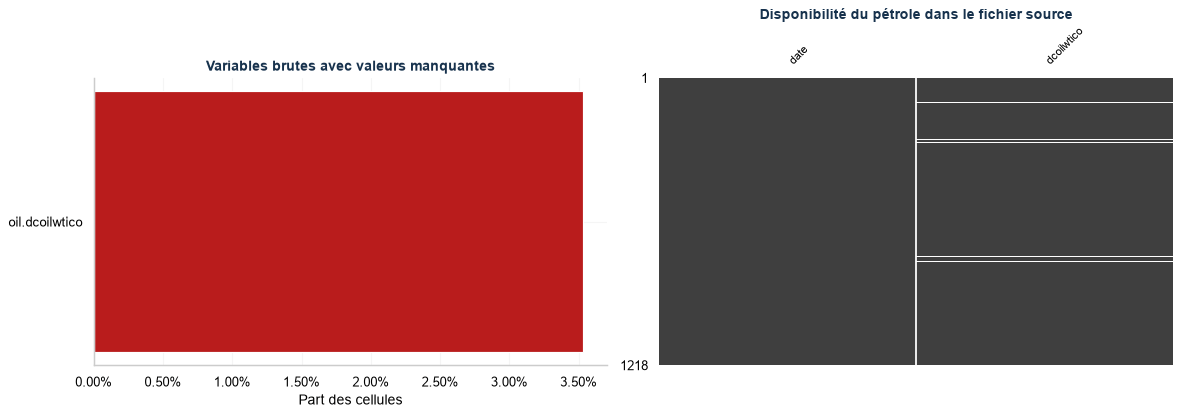

In [6]:
assert len(train_clean) == len(train)
assert not train_clean.duplicated(CLES_TRAIN).any()
assert train_clean[["city", "state", "type", "cluster"]].notna().all().all()
assert np.isclose(train_clean["sales"].to_numpy(dtype=float).sum(), train["sales"].to_numpy(dtype=float).sum())
bilan_nettoyage = pd.DataFrame([
    ("Lignes", len(train), len(train_clean)),
    ("Colonnes", len(train.columns), len(train_clean.columns)),
    ("Somme des ventes", train["sales"].to_numpy(dtype=float).sum(), train_clean["sales"].to_numpy(dtype=float).sum()),
    ("Lignes sans vente", int(train["sales"].eq(0).sum()), int(train_clean["sales"].eq(0).sum())),
    ("Doublons métier", int(train.duplicated(CLES_TRAIN).sum()), int(train_clean.duplicated(CLES_TRAIN).sum())),
    ("Cellules manquantes", int(train.isna().sum().sum()), int(train_clean.isna().sum().sum())),
], columns=["contrôle", "avant", "après"])
afficher_tableau(bilan_nettoyage)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
manquants = qualite_colonnes.loc[qualite_colonnes["manquants"].gt(0)].copy()
axes[0].barh(manquants["table"] + "." + manquants["variable"], manquants["part manquante"], color=COULEURS["manquant"])
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].set(title="Variables brutes avec valeurs manquantes", xlabel="Part des cellules", ylabel="")
msno.matrix(oil, ax=axes[1], sparkline=False, fontsize=9)
axes[1].set_title("Disponibilité du pétrole dans le fichier source", color=COULEUR_TITRES)
fig.tight_layout()
plt.show()
plt.close(fig)
lecture("Les contrôles confirment la conservation des lignes, des volumes et des zéros. Une table sans cellule manquante peut malgré tout avoir des dates entièrement absentes ; la continuité du calendrier est donc contrôlée séparément.")


<a id="section-7"></a>

<h2 style="color:#2563EB; font-weight:700;">7. Statistiques descriptives numériques</h2>

**Question :** Quels sont les niveaux, dispersions et asymétries des mesures ?

Les mesures sont décrites à leur granularité : ventes et promotions par date–magasin–famille, pétrole par date, transactions par date–magasin. Les séries externes sont limitées à la période de ventes pour ces comparaisons.

Couverture et fréquence des valeurs nulles :


,granularité,lignes,renseignées,manquants,part manquante,part de zéros renseignés,valeurs négatives
variable,,,,,,,
sales,date–magasin–famille,3 000 888,3 000 888,0,"0,0%","31,3%",0
onpromotion,date–magasin–famille,3 000 888,3 000 888,0,"0,0%","79,6%",0
dcoilwtico,date renseignée,1 206,1 163,43,"3,6%","0,0%",0
transactions,date–magasin,83 488,83 488,0,"0,0%","0,0%",0


Niveau et dispersion :


,moyenne,médiane,écart-type,écart interquartile,asymétrie
variable,,,,,
sales,"357,776","11,000","1 101,998","195,847","7,359"
onpromotion,"2,603","0,000","12,219","0,000","11,167"
dcoilwtico,"67,926","53,330","25,677","49,400","0,304"
transactions,"1 694,602","1 393,000","963,287","1 033,000","1,518"


Quantiles et valeurs extrêmes :


,minimum,P01,P05,Q1,Q3,P95,P99,maximum
variable,,,,,,,,
sales,"0,000","0,000","0,000","0,000","195,847","1 965,000","5 507,000","124 717,000"
onpromotion,"0,000","0,000","0,000","0,000","0,000","13,000","55,000","741,000"
dcoilwtico,"26,190","29,828","36,820","46,390","95,790","105,225","107,961","110,620"
transactions,"5,000","516,000","654,000","1 046,000","2 079,000","3 712,000","4 862,000","8 359,000"


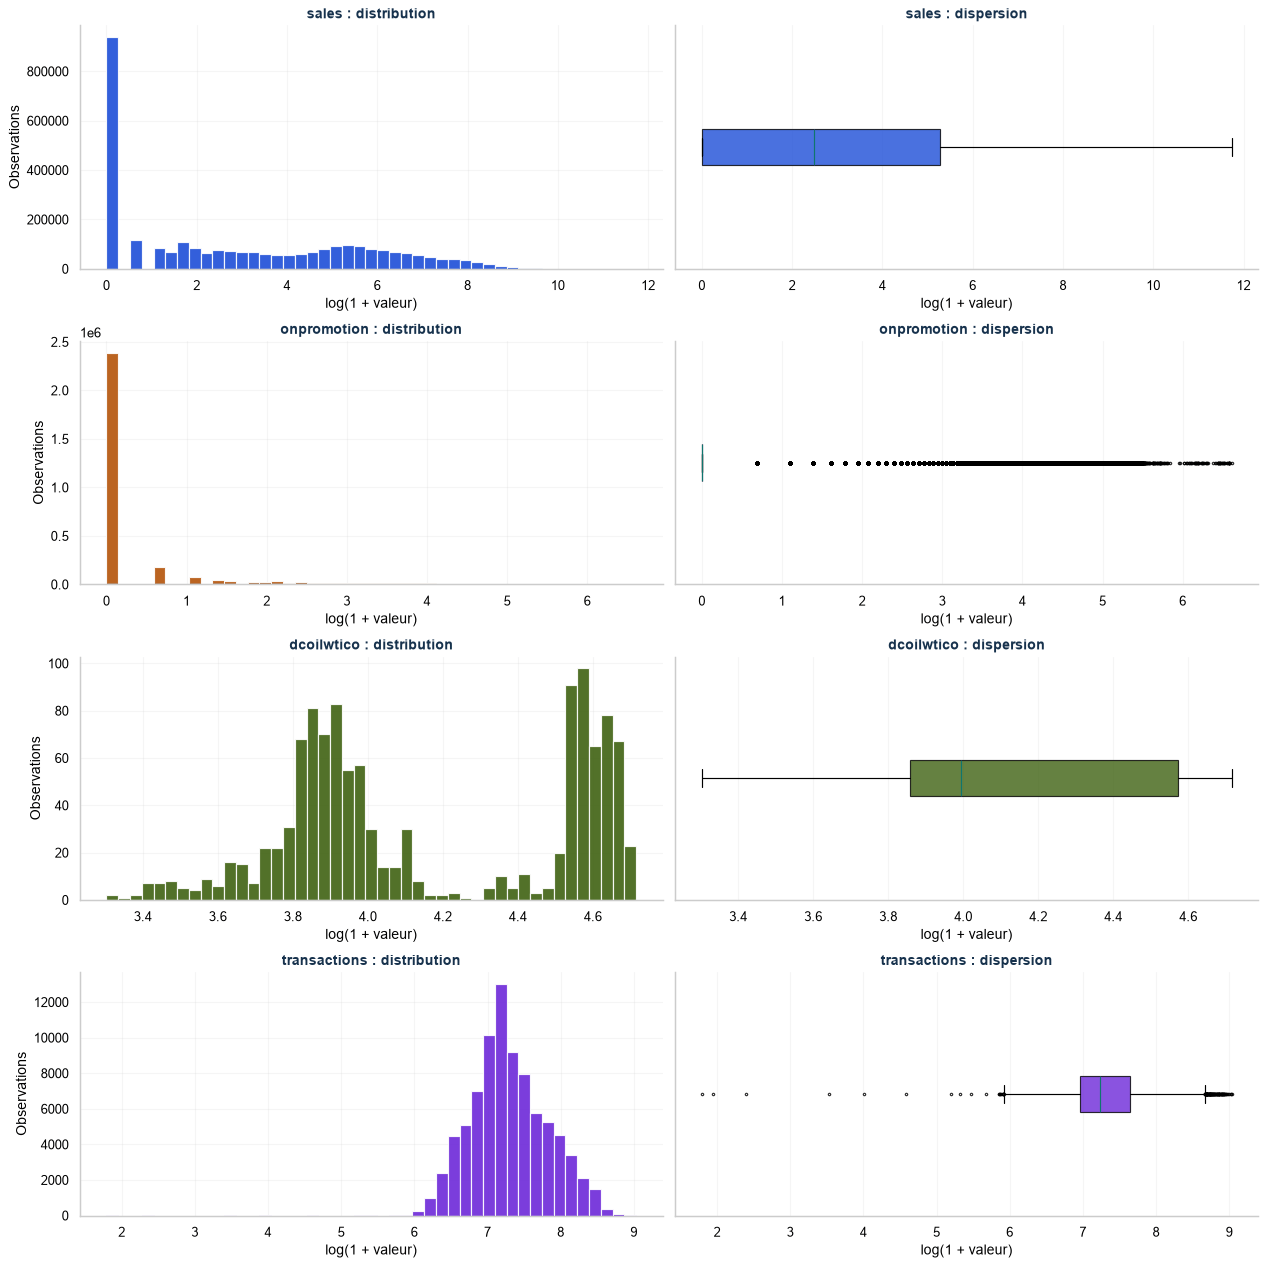

In [7]:
petrole = oil.loc[oil["date"].between(train["date"].min(), train["date"].max())].copy()
transactions_historique = transactions.loc[transactions["date"].between(train["date"].min(), train["date"].max())].copy()
mesures = {
    "sales": (train_clean["sales"], "date–magasin–famille", COULEURS["ventes"]),
    "onpromotion": (train_clean["onpromotion"], "date–magasin–famille", COULEURS["promotion"]),
    "dcoilwtico": (petrole["dcoilwtico"], "date renseignée", "#3F6212"),
    "transactions": (transactions_historique["transactions"], "date–magasin", "#6D28D9"),
}
rows = []
for name, (values, grain, color) in mesures.items():
    observed = values.dropna().astype(float)
    rows.append({
        "variable": name, "granularité": grain, "lignes": len(values), "renseignées": len(observed),
        "manquants": int(values.isna().sum()), "part manquante": values.isna().mean(),
        "moyenne": observed.mean(), "médiane": observed.median(), "écart-type": observed.std(),
        "minimum": observed.min(), "P01": observed.quantile(.01), "P05": observed.quantile(.05),
        "Q1": observed.quantile(.25), "Q3": observed.quantile(.75),
        "P95": observed.quantile(.95), "P99": observed.quantile(.99), "maximum": observed.max(),
        "écart interquartile": observed.quantile(.75) - observed.quantile(.25),
        "asymétrie": observed.skew(), "part de zéros renseignés": observed.eq(0).mean(),
        "valeurs négatives": int(observed.lt(0).sum()),
    })
statistiques_numeriques = pd.DataFrame(rows).set_index("variable")
print("Couverture et fréquence des valeurs nulles :")
afficher_tableau(statistiques_numeriques[["granularité", "lignes", "renseignées", "manquants", "part manquante", "part de zéros renseignés", "valeurs négatives"]])
print("Niveau et dispersion :")
afficher_tableau(statistiques_numeriques[["moyenne", "médiane", "écart-type", "écart interquartile", "asymétrie"]])
print("Quantiles et valeurs extrêmes :")
afficher_tableau(statistiques_numeriques[["minimum", "P01", "P05", "Q1", "Q3", "P95", "P99", "maximum"]])
fig, axes = plt.subplots(4, 2, figsize=(15, 15))
for row, (name, (values, grain, color)) in enumerate(mesures.items()):
    observed = values.dropna().to_numpy(dtype=float)
    axes[row, 0].hist(np.log1p(observed), bins=45, color=color, alpha=.9)
    axes[row, 0].set(title=f"{name} : distribution", xlabel="log(1 + valeur)", ylabel="Observations")
    axes[row, 1].boxplot(np.log1p(observed), orientation="horizontal", patch_artist=True, boxprops={"facecolor": color, "alpha": .8}, flierprops={"markersize": 2, "alpha": .8})
    axes[row, 1].set(title=f"{name} : dispersion", xlabel="log(1 + valeur)", yticks=[])
fig.tight_layout()
plt.show()
plt.close(fig)
lecture(f"La moyenne des ventes ({train_clean['sales'].mean():.2f}) et leur médiane ({train_clean['sales'].median():.2f}) décrivent des aspects différents de la distribution. Les transformations log(1 + valeur) servent à rendre les graphiques lisibles et conservent les zéros. Les points extrêmes du boxplot sont des observations à examiner, pas des erreurs automatiquement supprimées.")


<a id="section-8"></a>

<h2 style="color:#2563EB; font-weight:700;">8. Statistiques des catégories, dates et identifiants</h2>

**Question :** Comment décrire les catégories, les dates, les identifiants et les variables calendrier ?

Un code magasin ou cluster n’est pas une grandeur continue. Ses modalités et sa couverture sont pertinentes ; sa moyenne arithmétique ne l’est pas. Chaque variable source ou créée reçoit un profil adapté à son rôle.

In [8]:
categories_a_decrire = {
    "train_clean": (train_clean, ["store_nbr", "family", "city", "state", "type", "cluster", "year", "month", "dayofweek", "is_weekend"]),
    "stores": (stores, ["store_nbr", "city", "state", "type", "cluster"]),
    "holidays_events": (holidays, ["type", "locale", "locale_name", "description", "transferred"]),
}
profils_categories, frequences = [], []
for table, (frame, columns) in categories_a_decrire.items():
    for column in columns:
        counts = frame[column].value_counts(dropna=False)
        profiles = {"table": table, "variable": column, "renseignées": frame[column].notna().sum(), "manquants": frame[column].isna().sum(), "modalités": frame[column].nunique(), "modalité dominante": str(counts.index[0]), "effectif dominant": int(counts.iloc[0]), "part dominante": counts.iloc[0] / len(frame)}
        profils_categories.append(profiles)
        freq = pd.DataFrame({"table": table, "variable": column, "modalité": counts.index.astype(str), "effectif": counts.to_numpy(), "proportion": counts.to_numpy() / len(frame)})
        frequences.append(freq)
profil_categories = pd.DataFrame(profils_categories)
frequences_categories = pd.concat(frequences, ignore_index=True)
afficher_tableau(profil_categories)
print("Tables de fréquences complètes :")
for table, variable in frequences_categories[["table", "variable"]].drop_duplicates().itertuples(index=False):
    afficher_tableau(frequences_categories.loc[frequences_categories["table"].eq(table) & frequences_categories["variable"].eq(variable), ["modalité", "effectif", "proportion"]], repliable=True, titre=f"Fréquences · {table}.{variable}")

profil_dates = []
for name, frame in TABLES_BRUTES.items():
    if "date" not in frame:
        continue
    dates = pd.DatetimeIndex(frame["date"].dropna().unique()).sort_values()
    expected = pd.date_range(dates.min(), dates.max(), freq="D")
    profil_dates.append({"table": name, "début": dates.min(), "fin": dates.max(), "dates uniques": len(dates), "jours dans l’intervalle": len(expected), "dates absentes": len(expected.difference(dates)), "dates manquantes dans les lignes": frame["date"].isna().sum()})
afficher_tableau(pd.DataFrame(profil_dates))
identifiants = pd.DataFrame([{
    "table": name, "lignes": len(frame), "id uniques": frame["id"].nunique(),
    "id manquants": int(frame["id"].isna().sum()), "id en double": int(frame["id"].duplicated().sum()),
} for name, frame in TABLES_BRUTES.items() if "id" in frame])
afficher_tableau(identifiants)

couverture_variables = dictionnaire_variables[["table", "variable", "rôle"]].copy()
couverture_variables["analyse"] = couverture_variables["rôle"].map({
    "clé": "Unicité et contrôle de format", "date": "Période, continuité et couverture", "identifiant catégoriel": "Effectifs, référentiel et profils magasin", "catégorie": "Modalités et fréquences", "texte": "Modalités et fréquences des descriptions", "booléen": "Effectifs et statut de transfert", "mesure / cible": "Statistiques numériques et distributions", "comptage": "Statistiques numériques et distributions", "mesure": "Statistiques numériques, couverture et distributions", "format": "Contrôle du gabarit, aucune cible réelle",
})
couverture_variables.loc[couverture_variables["table"].eq("test"), "analyse"] = "Schéma, clés et horizon ; réservé à la soumission"
assert couverture_variables["analyse"].notna().all()
afficher_tableau(couverture_variables)
lecture("Les fréquences de localisation calculées sur les ventes reflètent des lignes date–magasin–famille ; celles de stores reflètent des magasins. Les variables calendrier créées sont également décrites. Le gabarit et le test sont contrôlés, sans fournir de ventes observées pour régler le modèle.")


table,variable,renseignées,manquants,modalités,modalité dominante,effectif dominant,part dominante
train_clean,store_nbr,3 000 888,0,54,1,55 572,"1,9%"
train_clean,family,3 000 888,0,33,AUTOMOTIVE,90 936,"3,0%"
train_clean,city,3 000 888,0,22,Quito,1 000 296,"33,3%"
train_clean,state,3 000 888,0,16,Pichincha,1 055 868,"35,2%"
train_clean,type,3 000 888,0,5,D,1 000 296,"33,3%"
train_clean,cluster,3 000 888,0,17,3,389 004,"13,0%"
train_clean,year,3 000 888,0,5,2016,650 430,"21,7%"
train_clean,month,3 000 888,0,12,1,276 210,"9,2%"
train_clean,dayofweek,3 000 888,0,7,1,431 244,"14,4%"
train_clean,is_weekend,3 000 888,0,2,False,2 143 746,"71,4%"


Tables de fréquences complètes :


modalité,effectif,proportion
1,55 572,"1,9%"
2,55 572,"1,9%"
3,55 572,"1,9%"
4,55 572,"1,9%"
5,55 572,"1,9%"
6,55 572,"1,9%"
7,55 572,"1,9%"
8,55 572,"1,9%"
9,55 572,"1,9%"
10,55 572,"1,9%"


modalité,effectif,proportion
AUTOMOTIVE,90 936,"3,0%"
BABY CARE,90 936,"3,0%"
BEAUTY,90 936,"3,0%"
BEVERAGES,90 936,"3,0%"
BOOKS,90 936,"3,0%"
BREAD/BAKERY,90 936,"3,0%"
CELEBRATION,90 936,"3,0%"
CLEANING,90 936,"3,0%"
DAIRY,90 936,"3,0%"
DELI,90 936,"3,0%"


modalité,effectif,proportion
Quito,1 000 296,"33,3%"
Guayaquil,444 576,"14,8%"
Cuenca,166 716,"5,6%"
Santo Domingo,166 716,"5,6%"
Ambato,111 144,"3,7%"
Latacunga,111 144,"3,7%"
Machala,111 144,"3,7%"
Manta,111 144,"3,7%"
Babahoyo,55 572,"1,9%"
Cayambe,55 572,"1,9%"


...

modalité,effectif,proportion
Carnaval,10,"2,9%"
Fundacion de Cuenca,7,"2,0%"
Fundacion de Ibarra,7,"2,0%"
Fundacion de Manta,6,"1,7%"
Provincializacion de Cotopaxi,6,"1,7%"
Cantonizacion de Libertad,6,"1,7%"
Cantonizacion de Riobamba,6,"1,7%"
Cantonizacion del Puyo,6,"1,7%"
Cantonizacion de Guaranda,6,"1,7%"
Provincializacion de Imbabura,6,"1,7%"


modalité,effectif,proportion
False,338,"96,6%"
True,12,"3,4%"


table,début,fin,dates uniques,jours dans l’intervalle,dates absentes,dates manquantes dans les lignes
train,2013-01-01,2017-08-15,1 684,1 688,4,0
test,2017-08-16,2017-08-31,16,16,0,0
oil,2013-01-01,2017-08-31,1 218,1 704,486,0
transactions,2013-01-01,2017-08-15,1 682,1 688,6,0
holidays_events,2012-03-02,2017-12-26,312,2 126,1 814,0


table,lignes,id uniques,id manquants,id en double
train,3 000 888,3 000 888,0,0
test,28 512,28 512,0,0
sample_submission,28 512,28 512,0,0


table,variable,rôle,analyse
train,id,clé,Unicité et contrôle de format
train,date,date,"Période, continuité et couverture"
train,store_nbr,identifiant catégoriel,"Effectifs, référentiel et profils magasin"
train,family,catégorie,Modalités et fréquences
train,sales,mesure / cible,Statistiques numériques et distributions
train,onpromotion,comptage,Statistiques numériques et distributions
test,id,clé,"Schéma, clés et horizon ; réservé à la soumission"
test,date,date,"Schéma, clés et horizon ; réservé à la soumission"
test,store_nbr,identifiant catégoriel,"Schéma, clés et horizon ; réservé à la soumission"
test,family,catégorie,"Schéma, clés et horizon ; réservé à la soumission"


<hr>

<p style="color:#2563EB; font-size:13px; letter-spacing:1px;"><strong>PARTIE 03 · EXPLORER</strong></p>

Lire les rythmes, les différences et les associations dans les ventes.

<a id="section-9"></a>

<h2 style="color:#2563EB; font-weight:700;">9. Exploration globale des ventes</h2>

**Question :** Comment évoluent le niveau global, les zéros et les profils temporels ?

In [9]:
ventes = train_clean[["date", "store_nbr", "family", "sales", "onpromotion"]].copy()


In [10]:
import numpy as np
from IPython.display import Markdown
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

BLEU_VISUEL = COULEUR_TITRES
COULEURS_VISUELLES = {
    "ventes": "#1D4ED8", "tendance": "#0F766E", "evenement": "#B91C1C",
    "promotion": "#B45309", "petrole": "#3F6212", "transactions": "#6D28D9",
    "neutre": "#334155",
}
calendrier_visuel = pd.date_range(ventes["date"].min(), ventes["date"].max(), freq="D")
familles_visuelles = sorted(ventes["family"].astype(str).unique())
magasins_visuels = sorted(ventes["store_nbr"].unique().tolist())
assert len(familles_visuelles) == 33 and len(magasins_visuels) == 54
assert not ventes.duplicated(["date", "store_nbr", "family"]).any()

v_famille_jour = ventes.groupby(["date", "family"], observed=True).agg(
    ventes=("sales", "sum"), promotions=("onpromotion", "sum"),
).reset_index()
v_ventes_familles = v_famille_jour.pivot(index="date", columns="family", values="ventes").reindex(calendrier_visuel)
v_promotions_familles = v_famille_jour.pivot(index="date", columns="family", values="promotions").reindex(calendrier_visuel)
v_tendances_familles = v_ventes_familles.rolling(7, min_periods=7).mean()
v_magasin_jour = ventes.groupby(["date", "store_nbr"], observed=True)["sales"].sum().rename("ventes").reset_index()
v_ventes_magasins = v_magasin_jour.pivot(index="date", columns="store_nbr", values="ventes").reindex(calendrier_visuel)
v_tendances_magasins = v_ventes_magasins.rolling(7, min_periods=7).mean()
v_total_jour = v_ventes_familles.sum(axis=1, min_count=1)
dates_absentes_visuelles = calendrier_visuel.difference(pd.DatetimeIndex(ventes["date"].unique()))
assert v_total_jour.loc[dates_absentes_visuelles].isna().all()
assert np.isclose(v_total_jour.sum(), ventes["sales"].to_numpy(dtype=float).sum(), rtol=1e-6)

v_stores = stores.copy()
v_evenements = holidays.copy()
v_transactions = transactions_historique.copy()
assert v_stores["store_nbr"].is_unique
assert not v_transactions.duplicated(["date", "store_nbr"]).any()
assert not petrole["date"].duplicated().any()
assert v_transactions["transactions"].ge(0).all()
v_stores_index = v_stores.set_index("store_nbr")
v_evenements_periode = v_evenements.loc[v_evenements["date"].between(calendrier_visuel.min(), calendrier_visuel.max())].copy()
v_evenements_effectifs = v_evenements_periode.loc[~v_evenements_periode["transferred"]].copy()
v_nationaux_effectifs = pd.DatetimeIndex(
    v_evenements_effectifs.loc[v_evenements_effectifs["locale"].eq("National"), "date"].drop_duplicates().sort_values()
)

def lecture_visuelle(texte):
    lecture(texte)

def afficher_tableau_visuel(frame):
    afficher_tableau(frame)

def titre_visuel(ax, titre, xlabel=None, ylabel=None):
    ax.set_title(titre, color=BLEU_VISUEL, fontweight="bold", pad=10, loc="left")
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.grid(alpha=0.20)

def grilles_visuelles(elements, titre, dessiner, ylabel, legende=None, note=""):
    elements = list(elements)
    for debut in range(0, len(elements), 9):
        page = elements[debut:debut + 9]
        lignes = int(np.ceil(len(page) / 3))
        fig, axes = plt.subplots(lignes, 3, figsize=(18, 3.5 * lignes + 1.4), squeeze=False)
        for ax, element in zip(axes.flat, page):
            dessiner(ax, element)
            ax.set_ylabel(ylabel, fontsize=9)
            if ax.get_yscale() == "linear":
                ax.set_ylim(bottom=0)
                ax.yaxis.set_major_formatter(plt.FuncFormatter(formater_volume))
            ax.set_facecolor("#FCFDFE")
            ax.tick_params(labelsize=8)
            ax.grid(alpha=0.20)
        for ax in list(axes.flat)[len(page):]:
            ax.remove()
        fig.suptitle(
            f"{titre} — page {debut // 9 + 1}/{int(np.ceil(len(elements) / 9))}",
            color=BLEU_VISUEL, fontweight="bold", fontsize=16, y=0.99,
        )
        if legende:
            fig.legend(handles=legende, loc="upper center", bbox_to_anchor=(0.5, 0.965), ncol=3, frameon=False, fontsize=10)
        fig.tight_layout(rect=(0, 0.055, 1, 0.92 if legende else 0.95))
        if note:
            fig.text(0.5, 0.015, note, ha="center", fontsize=9, color="#475569")
        plt.show()
        plt.close(fig)

def barres_visuelles(ax, valeurs, titre, xlabel, couleur=BLEU_VISUEL):
    valeurs = valeurs.sort_values()
    ax.barh(valeurs.index.astype(str), valeurs.to_numpy(), color=couleur)
    titre_visuel(ax, titre, xlabel)
    ax.grid(axis="y", visible=False)

inventaire_visuel = pd.DataFrame([
    ("Ventes préparées", len(ventes), "date, store_nbr, family, sales, onpromotion", "Cible, séries et promotions"),
    ("Magasins", len(v_stores), ", ".join(v_stores.columns), "Ville, État, type et cluster"),
    ("Pétrole", len(petrole), ", ".join(petrole.columns), "Contexte économique descriptif"),
    ("Événements", len(v_evenements), ", ".join(v_evenements.columns), "Type, portée et dates transférées"),
    ("Transactions", len(v_transactions), ", ".join(v_transactions.columns), "Activité observée par magasin et date"),
], columns=["données", "lignes", "colonnes", "lecture"])
afficher_tableau_visuel(inventaire_visuel)
lecture_visuelle(
    f"La grille couvre {len(calendrier_visuel):,} jours calendaires ; "
    f"{len(dates_absentes_visuelles)} journées sont absentes. Elles sont laissées inconnues. "
    "Les ventes sont des volumes observés, pas du chiffre d’affaires. Les identifiants servent aux rapprochements ; "
    "test.csv et sample_submission.csv restent réservés à la soumission."
)


données,lignes,colonnes,lecture
Ventes préparées,3 000 888,"date, store_nbr, family, sales, onpromotion","Cible, séries et promotions"
Magasins,54,"store_nbr, city, state, type, cluster","Ville, État, type et cluster"
Pétrole,1 206,"date, dcoilwtico",Contexte économique descriptif
Événements,350,"date, type, locale, locale_name, description, transferred","Type, portée et dates transférées"
Transactions,83 488,"date, store_nbr, transactions",Activité observée par magasin et date


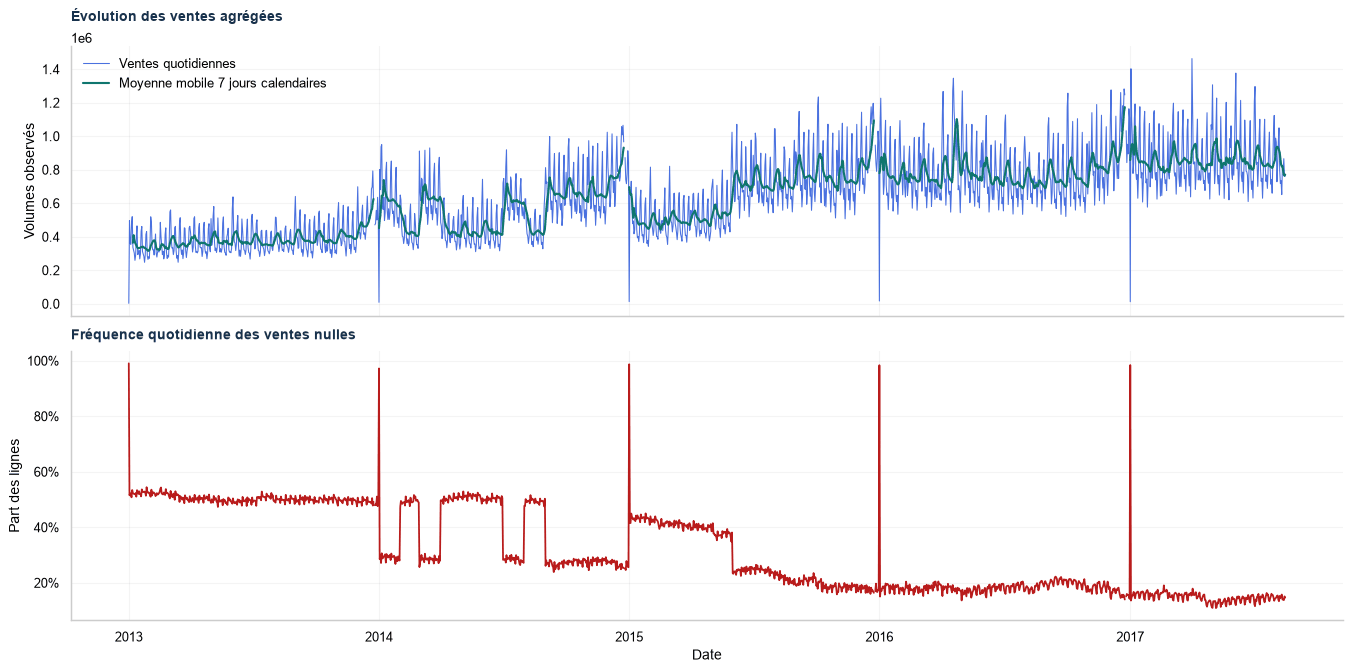

,volume,moyenne_jour,jours_observes
2013,"140 419 008,000","385 766,500",364
2014,"209 474 240,000","575 478,688",364
2015,"240 880 096,000","661 758,500",364
2016,"288 654 528,000","790 834,312",365
2017,"194 217 072,000","855 581,812",227


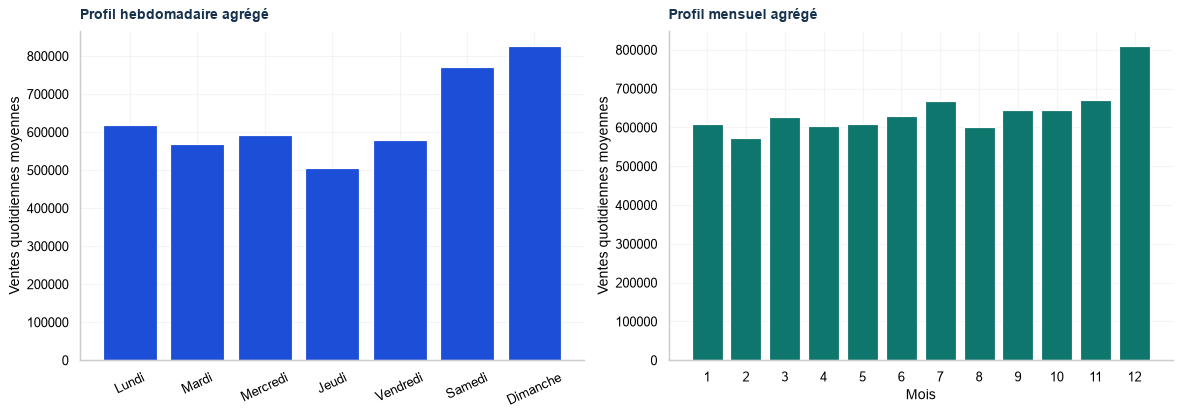

In [11]:
ventes_jour = ventes.groupby("date", observed=True).agg(ventes_totales=("sales", "sum"), part_lignes_zero=("sales", lambda x: x.eq(0).mean())).reindex(calendrier_visuel)
ventes_jour["moyenne_mobile_7j"] = ventes_jour["ventes_totales"].rolling(7, min_periods=7).mean()
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
axes[0].plot(ventes_jour.index, ventes_jour["ventes_totales"], color=COULEURS["ventes"], alpha=.8, linewidth=.9, label="Ventes quotidiennes")
axes[0].plot(ventes_jour.index, ventes_jour["moyenne_mobile_7j"], color=COULEURS["prevision"], linewidth=1.8, label="Moyenne mobile 7 jours calendaires")
titre_visuel(axes[0], "Évolution des ventes agrégées", ylabel="Volumes observés")
axes[0].legend()
axes[1].plot(ventes_jour.index, ventes_jour["part_lignes_zero"], color=COULEURS["manquant"])
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
titre_visuel(axes[1], "Fréquence quotidienne des ventes nulles", "Date", "Part des lignes")
fig.tight_layout()
plt.show()
plt.close(fig)
lecture(f"Les ventes nulles représentent {ventes['sales'].eq(0).mean():.1%} des lignes. Les moyennes mobiles utilisent le calendrier ; les dates absentes interrompent la courbe au lieu d’ajouter des ventes nulles.")

couverture_annuelle = v_total_jour.groupby(v_total_jour.index.year).agg(volume="sum", moyenne_jour="mean", jours_observes="count")
afficher_tableau(couverture_annuelle)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
profil_jour = v_total_jour.groupby(v_total_jour.index.dayofweek).mean().reindex(range(7))
axes[0].bar(NOMS_JOURS, profil_jour, color=COULEURS["ventes"])
axes[0].tick_params(axis="x", rotation=25)
titre_visuel(axes[0], "Profil hebdomadaire agrégé", ylabel="Ventes quotidiennes moyennes")
profil_mois = v_total_jour.groupby(v_total_jour.index.month).mean().reindex(range(1, 13))
axes[1].bar(range(1, 13), profil_mois, color=COULEURS["prevision"])
axes[1].set_xticks(range(1, 13))
titre_visuel(axes[1], "Profil mensuel agrégé", "Mois", "Ventes quotidiennes moyennes")
fig.tight_layout()
plt.show()
plt.close(fig)
lecture("Les niveaux moyens par jour évitent de comparer uniquement des totaux sur des durées différentes. Les profils mensuels mélangent saisonnalité, tendance et composition des magasins ; 2017 est une année partielle.")


<a id="section-10"></a>

<h2 style="color:#2563EB; font-weight:700;">10. Analyse des 33 familles</h2>

**Question :** Quels comportements distinguent chacune des 33 familles ?

Toutes les familles sont affichées en grilles de neuf panneaux maximum. Les échelles restent propres à chaque série ; les marqueurs d’événements sont des repères descriptifs.

<h3 style="color:#2563EB; font-weight:700;">10.1. Évolution quotidienne et volumes</h3>

**Question :** Quelles familles dominent le volume et changent de niveau ?

<h3 style="color:#2563EB; font-weight:700;">Vue de synthèse · Les trajectoires de six familles</h3>

Cette figure résume les points de lecture ; les analyses détaillées suivent.

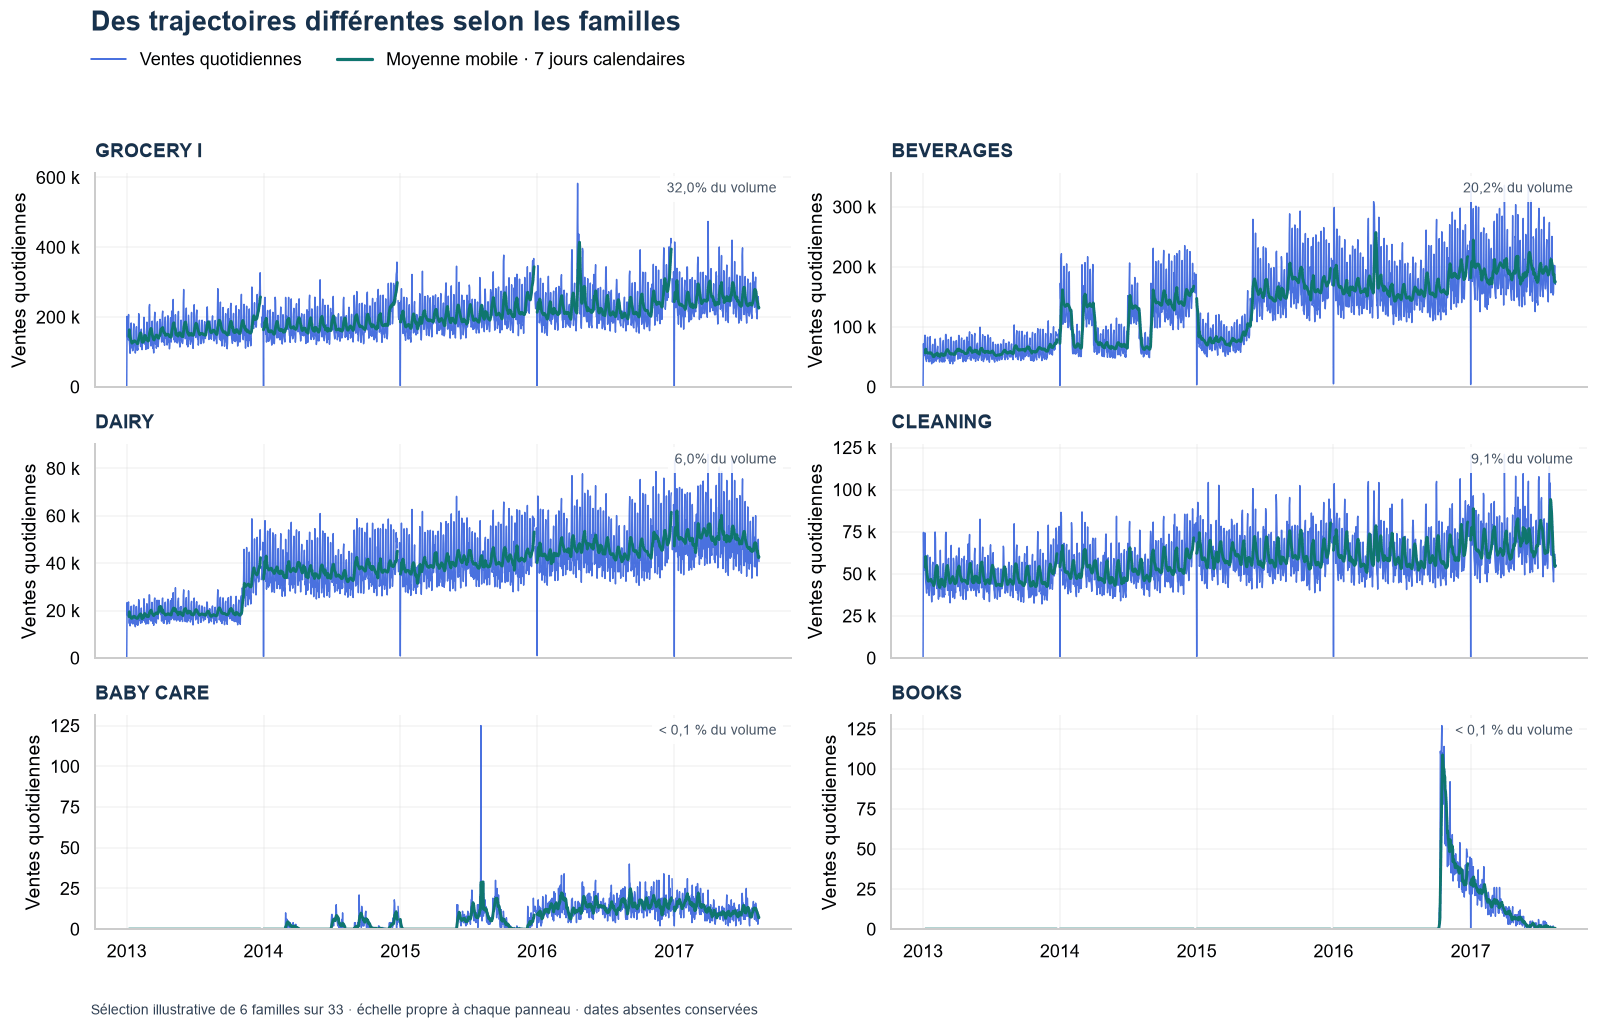

In [12]:
familles_synthese = ["GROCERY I", "BEVERAGES", "DAIRY", "CLEANING", "BABY CARE", "BOOKS"]
fig, axes = plt.subplots(3, 2, figsize=(14, 9), dpi=115, sharex=True)
for ax, famille in zip(axes.flat, familles_synthese):
    serie = v_ventes_familles[famille]
    tendance = serie.rolling(7, min_periods=7).mean()
    ax.plot(serie.index, serie, color=COULEURS["ventes"], alpha=.8, lw=.9)
    ax.plot(tendance.index, tendance, color=COULEURS["prevision"], lw=1.8)
    titre_visuel(ax, famille, ylabel="Ventes quotidiennes")
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(formater_volume))
    poids = serie.sum() / v_total_jour.sum()
    etiquette_poids = "< 0,1 % du volume" if 0 < poids < .001 else f"{poids:.1%} du volume".replace(".", ",")
    ax.text(.98, .91, etiquette_poids, transform=ax.transAxes, ha="right", fontsize=9, color="#475569", bbox={"facecolor":"white", "edgecolor":"none", "alpha":.9})
fig.suptitle("Des trajectoires différentes selon les familles", color=COULEUR_TITRES, fontweight="bold", fontsize=17, x=.06, ha="left", y=.99)
fig.legend(handles=[Line2D([0], [0], color=COULEURS["ventes"], lw=1, label="Ventes quotidiennes"), Line2D([0], [0], color=COULEURS["prevision"], lw=2, label="Moyenne mobile · 7 jours calendaires")], loc="upper left", bbox_to_anchor=(.05, .965), ncol=2)
fig.tight_layout(rect=(0, .055, 1, .92))
fig.text(.06, .02, "Sélection illustrative de 6 familles sur 33 · échelle propre à chaque panneau · dates absentes conservées", fontsize=9, color="#334155")
plt.show()
plt.close(fig)
lecture("Les familles ont des niveaux, des périodes actives et des trajectoires différents. Cette sélection illustre des profils contrastés ; toutes les familles restent représentées dans les grilles suivantes.")


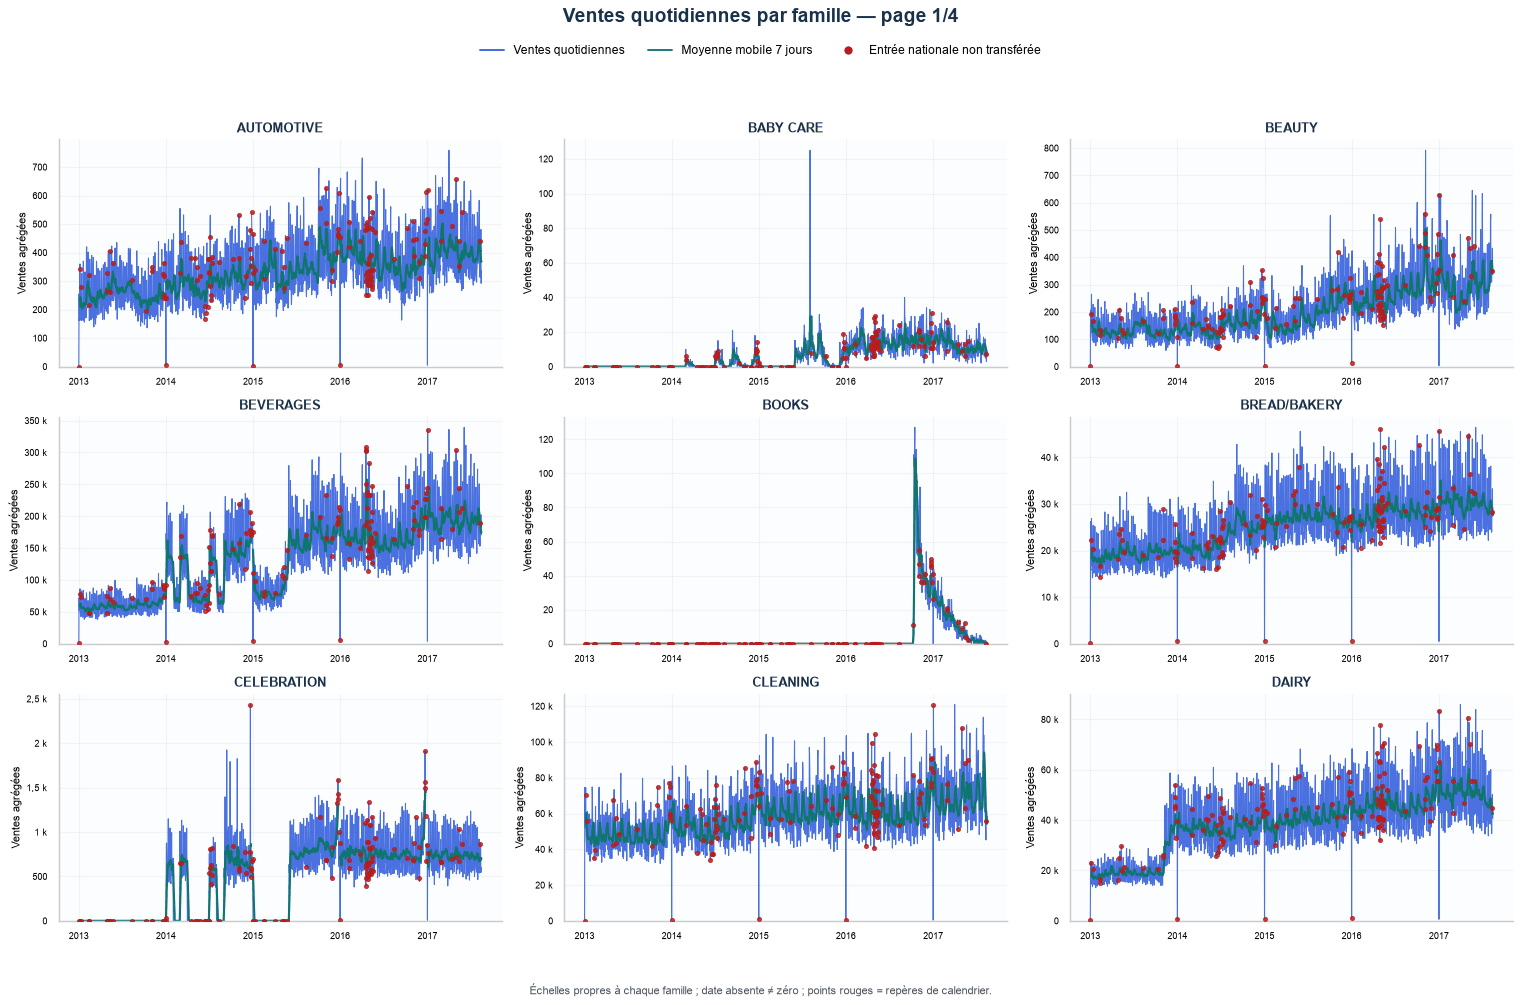

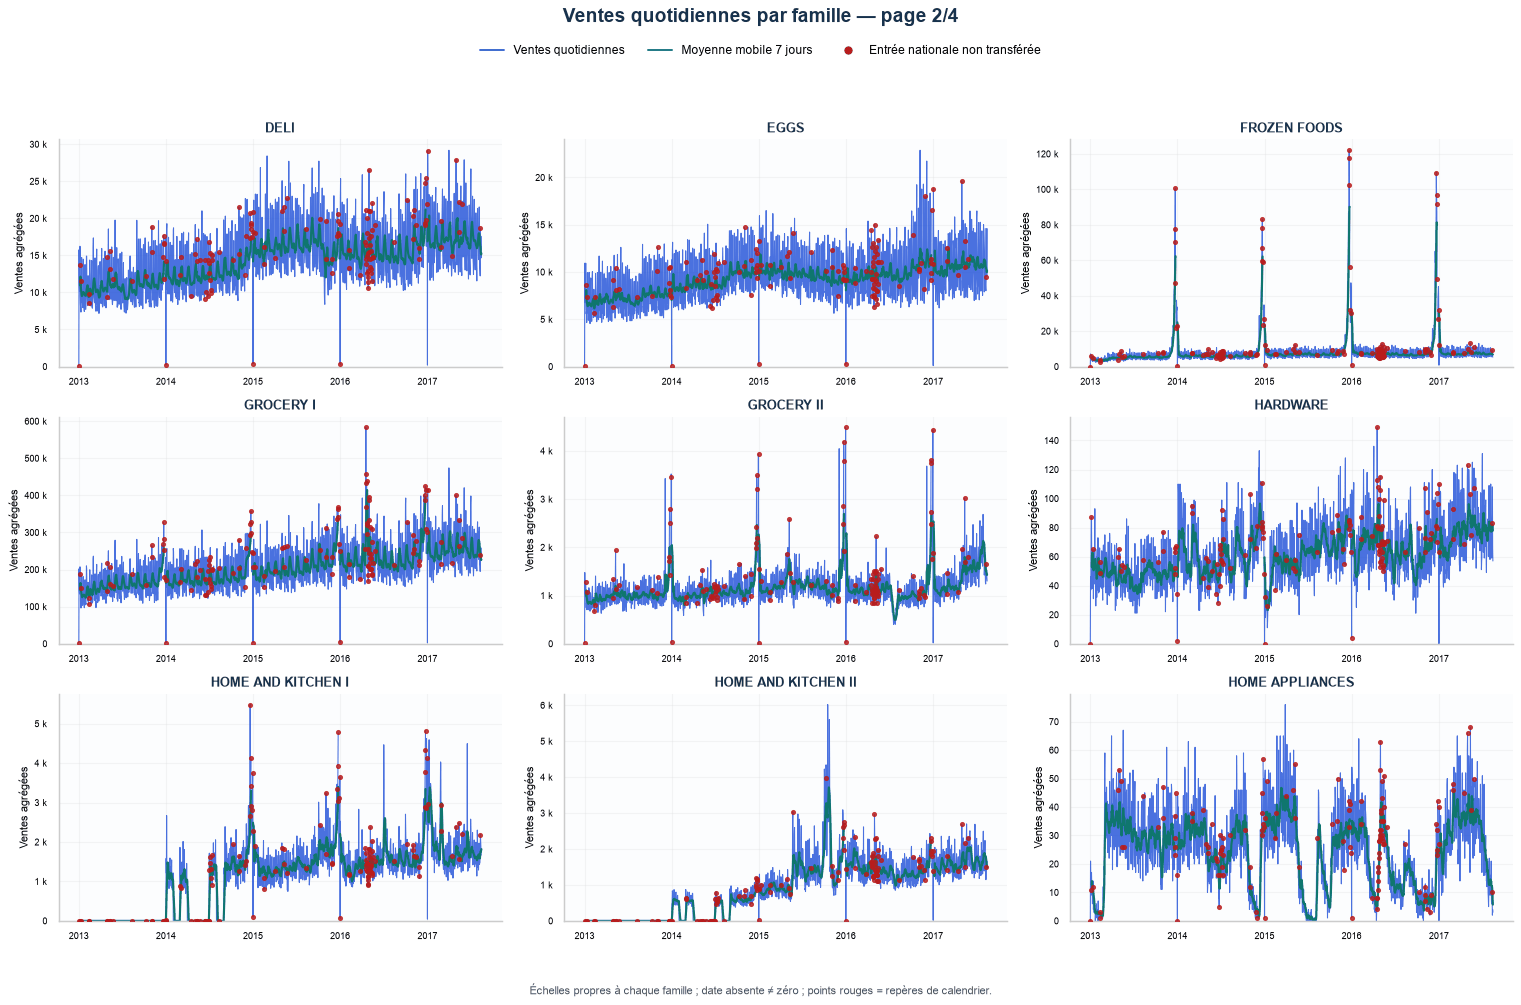

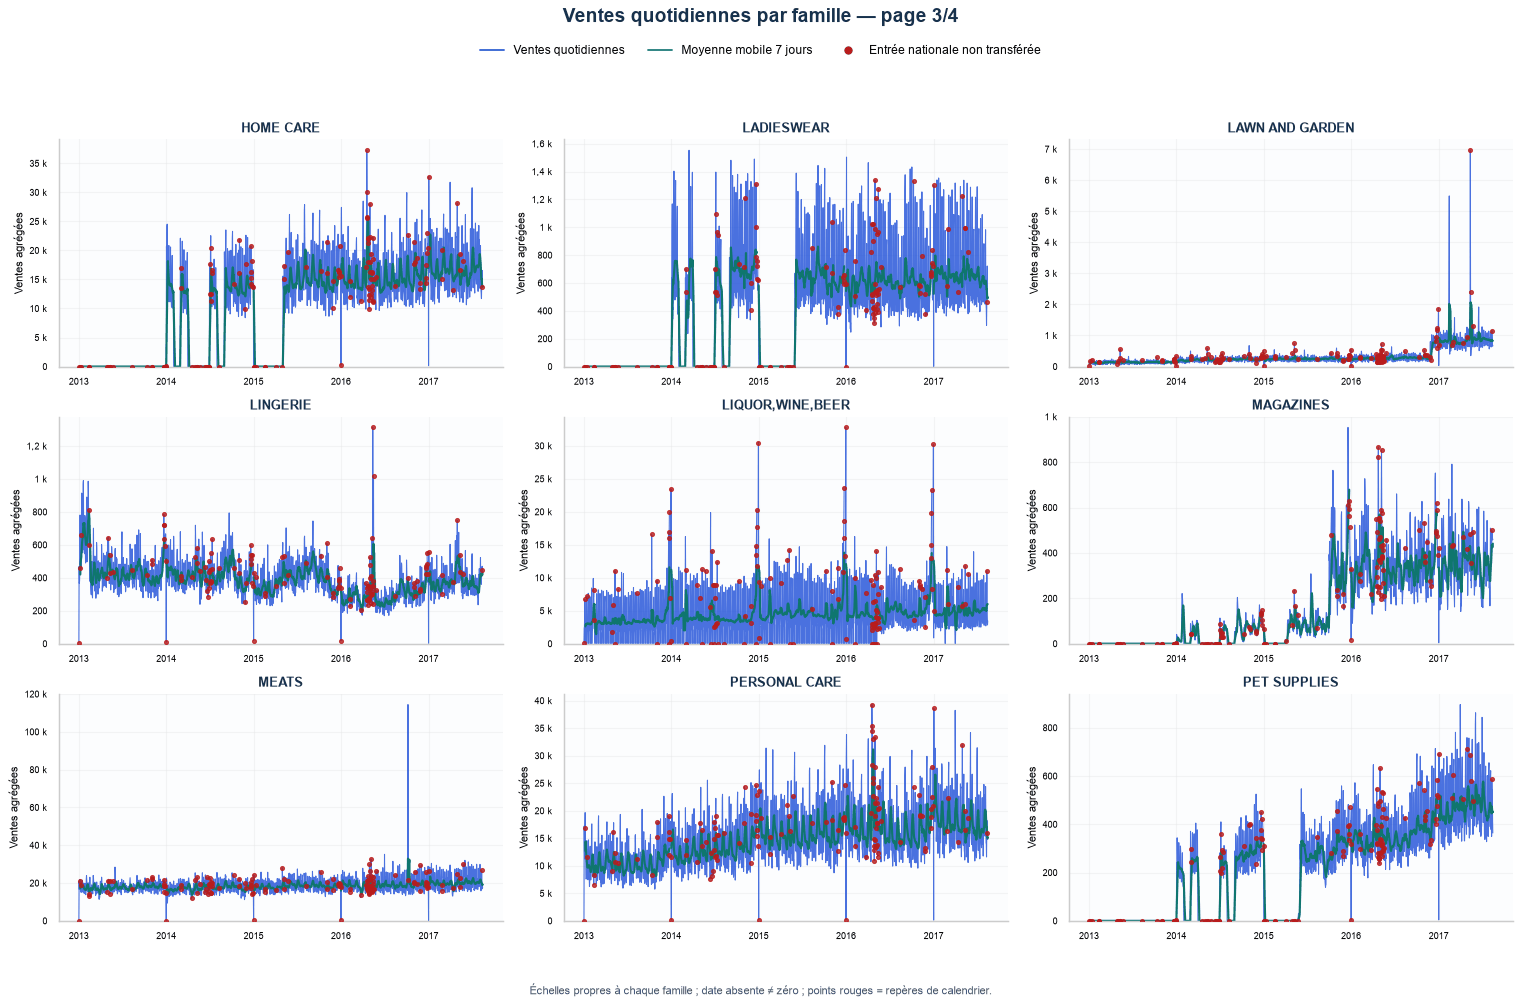

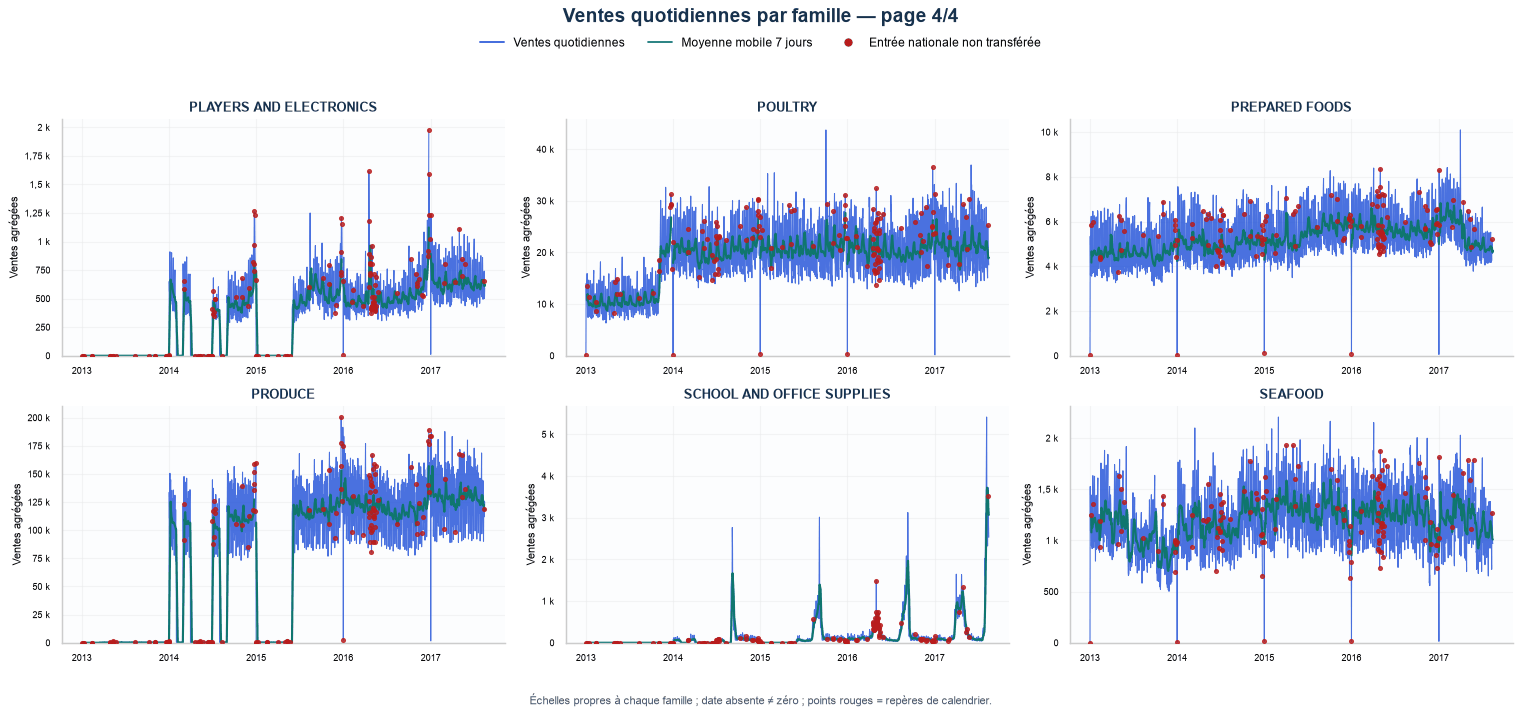

,volume,moyenne,mediane,part_zeros,observations
family,,,,,
GROCERY I,"343 462 720,000","3 776,972","3 185,000","8,1%",90 936
BEVERAGES,"216 954 480,000","2 385,793","1 784,000","8,1%",90 936
PRODUCE,"122 704 688,000","1 349,352","398,290","28,4%",90 936
CLEANING,"97 521 288,000","1 072,417","938,000","8,1%",90 936
DAIRY,"64 487 708,000","709,155","520,000","8,1%",90 936
BREAD/BAKERY,"42 133 944,000","463,336","401,000","8,1%",90 936
POULTRY,"31 876 004,000","350,532","205,743","8,1%",90 936
MEATS,"31 086 468,000","341,850","224,936","8,1%",90 936
PERSONAL CARE,"24 592 052,000","270,433","222,000","8,1%",90 936


In [13]:
def dessiner_famille(ax, famille):
    serie = v_ventes_familles[famille]
    ax.plot(serie.index, serie, color=COULEURS_VISUELLES["ventes"], linewidth=.9, alpha=.8)
    ax.plot(serie.index, v_tendances_familles[famille], color=COULEURS_VISUELLES["tendance"], linewidth=1.8)
    dates_marquees = v_nationaux_effectifs.intersection(serie.dropna().index)
    ax.scatter(dates_marquees, serie.loc[dates_marquees], color=COULEURS_VISUELLES["evenement"], s=11, alpha=.8, zorder=3)
    ax.set_title(famille, color=BLEU_VISUEL, fontweight="bold", fontsize=11)

legende_familles = [
    Line2D([0], [0], color=COULEURS_VISUELLES["ventes"], label="Ventes quotidiennes"),
    Line2D([0], [0], color=COULEURS_VISUELLES["tendance"], label="Moyenne mobile 7 jours"),
    Line2D([0], [0], linestyle="", marker="o", color=COULEURS_VISUELLES["evenement"], label="Entrée nationale non transférée"),
]
grilles_visuelles(
    familles_visuelles, "Ventes quotidiennes par famille", dessiner_famille, "Ventes agrégées",
    legende_familles, "Échelles propres à chaque famille ; date absente ≠ zéro ; points rouges = repères de calendrier."
)
v_resume_familles = ventes.assign(vente_nulle=ventes["sales"].eq(0)).groupby("family", observed=True).agg(
    volume=("sales", "sum"), moyenne=("sales", "mean"), mediane=("sales", "median"),
    part_zeros=("vente_nulle", "mean"), observations=("sales", "size"),
)
afficher_tableau_visuel(v_resume_familles.sort_values("volume", ascending=False).round(3))
lecture_visuelle(
    f"La famille {v_resume_familles['volume'].idxmax()} contribue le plus au volume agrégé. "
    f"La fréquence des lignes nulles varie de {v_resume_familles['part_zeros'].min():.1%} "
    f"à {v_resume_familles['part_zeros'].max():.1%} selon la famille. "
    "Les panneaux doivent être lus avec leurs propres échelles ; les coïncidences avec les points rouges "
    "ne suffisent pas à expliquer les variations."
)


<h3 style="color:#2563EB; font-weight:700;">10.2. Distribution dans chaque famille</h3>

**Question :** Les ventes sont-elles concentrées sur zéro, de petits volumes ou des pics ?

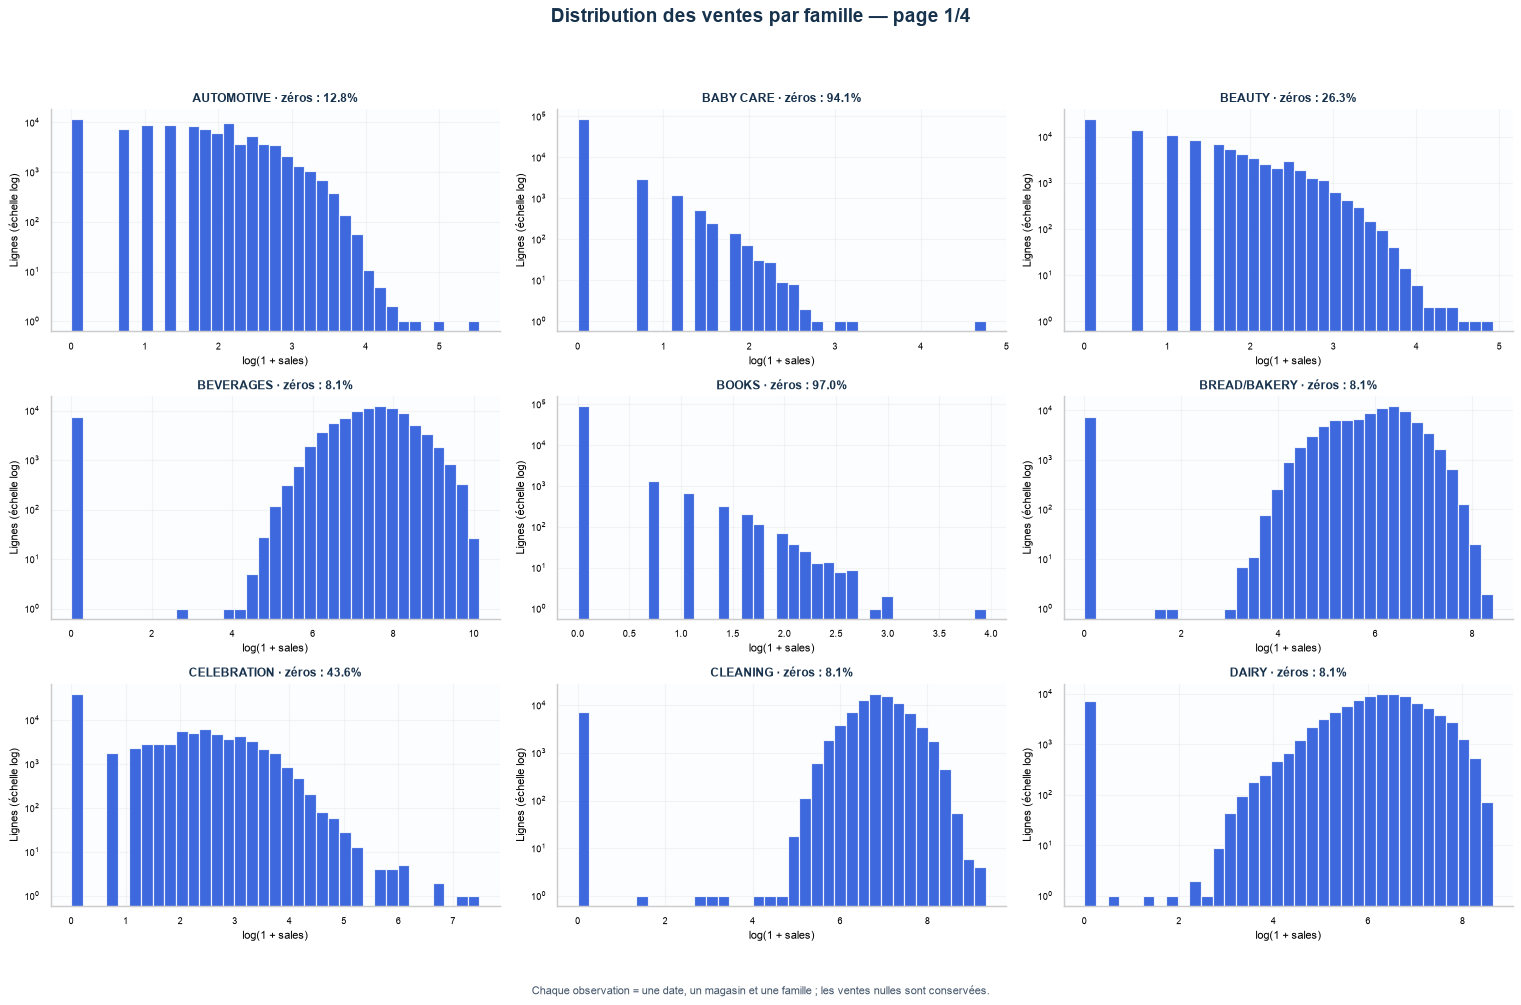

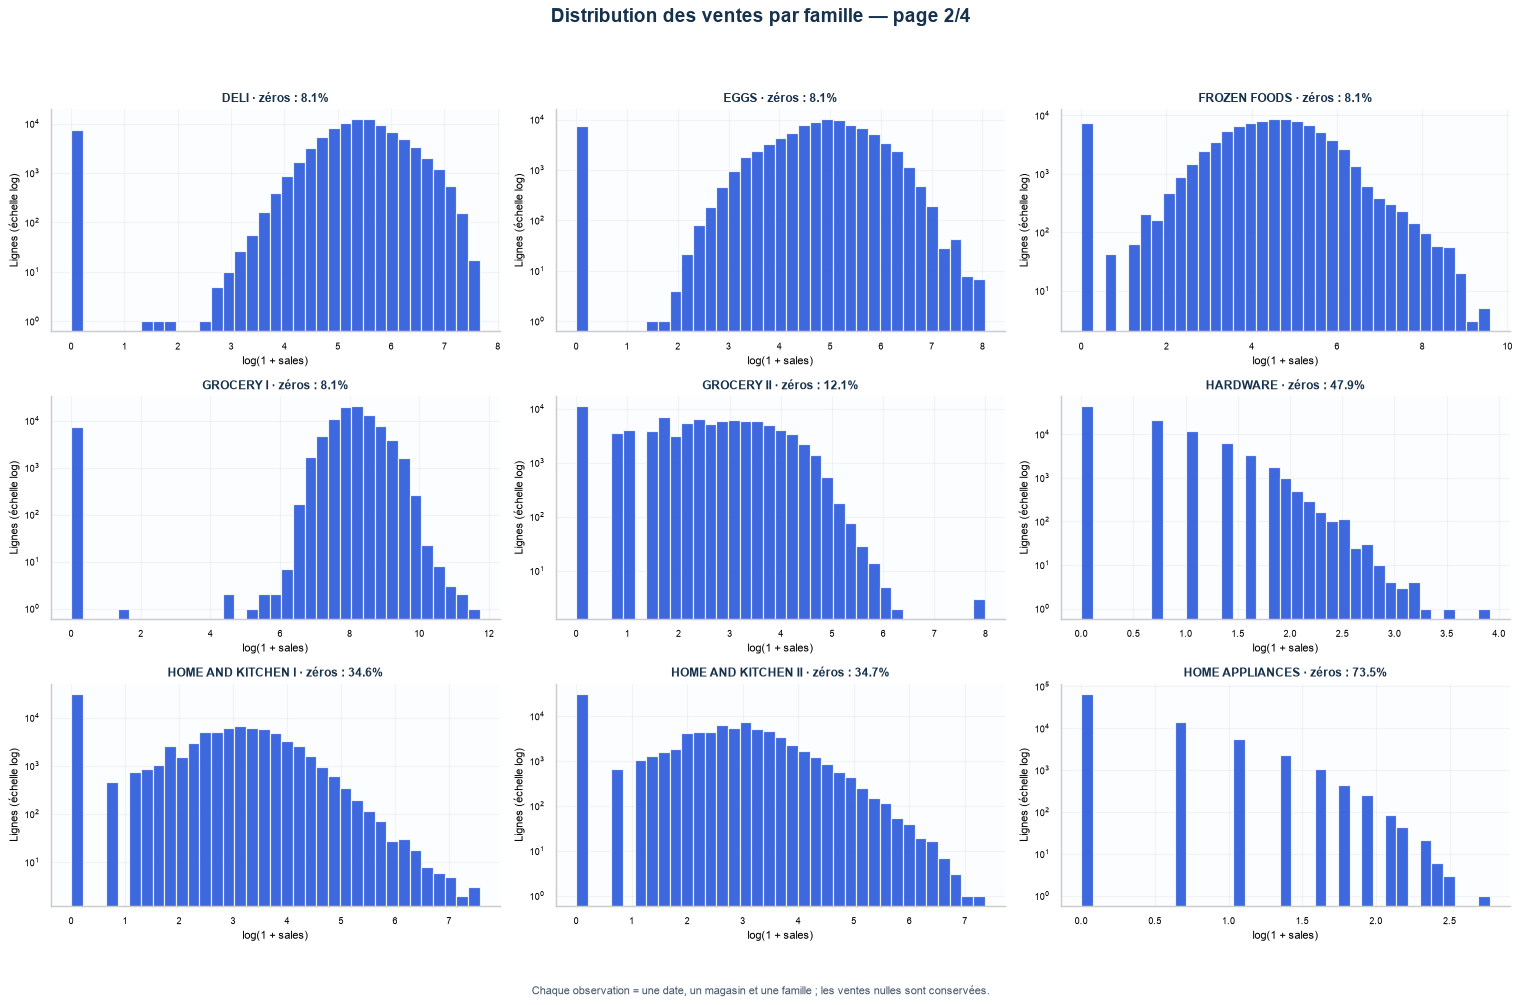

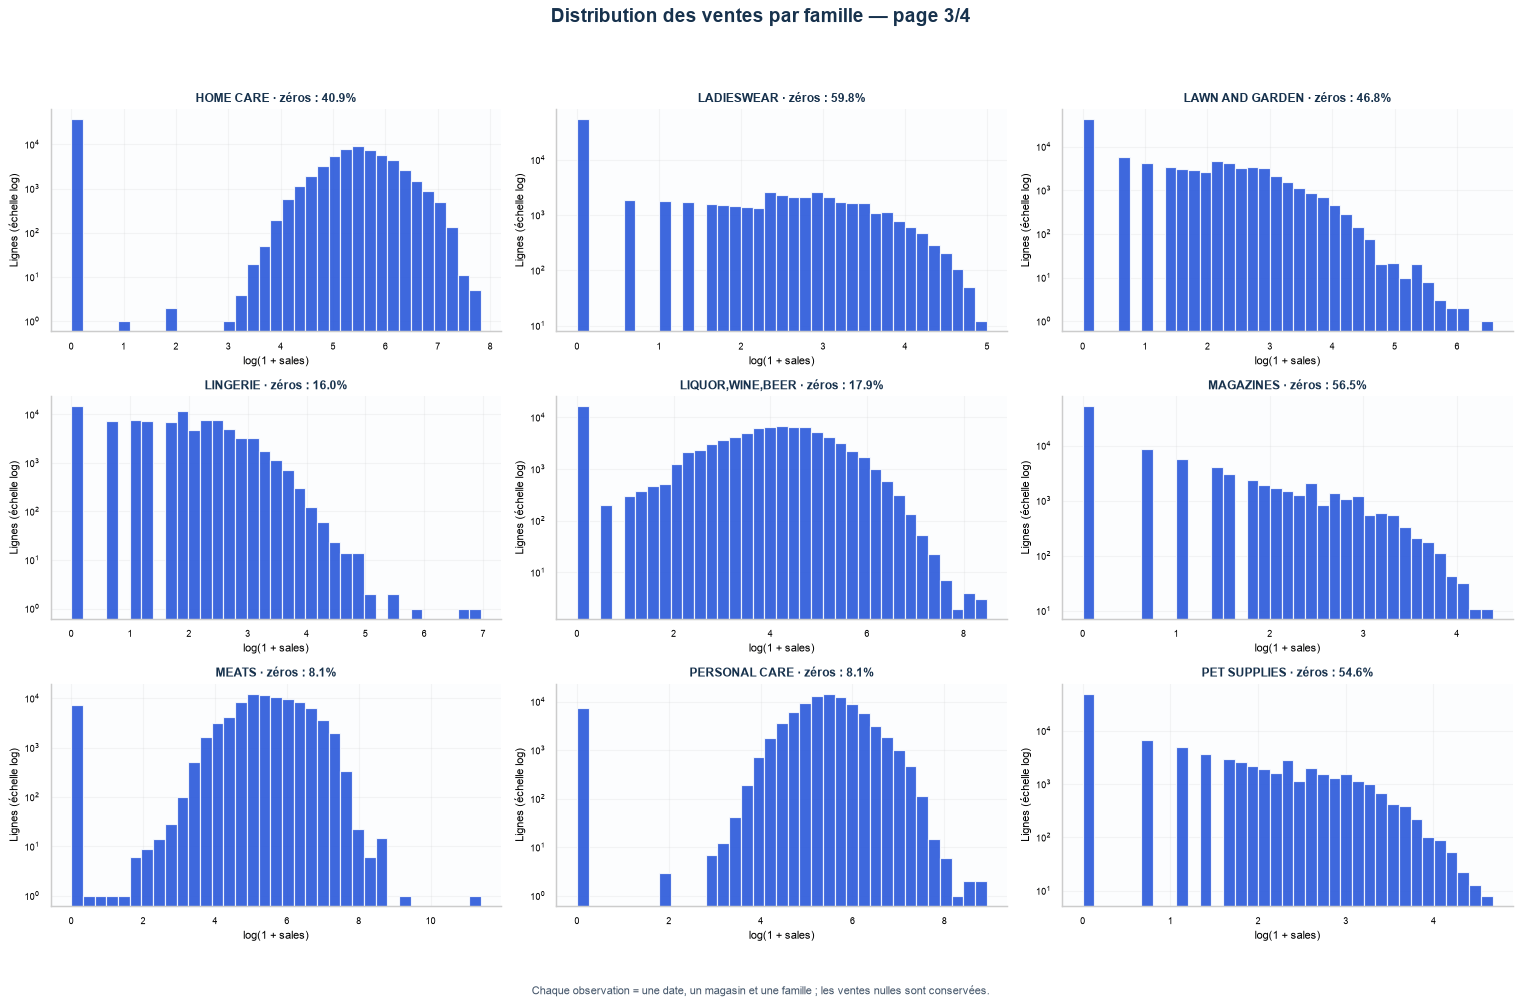

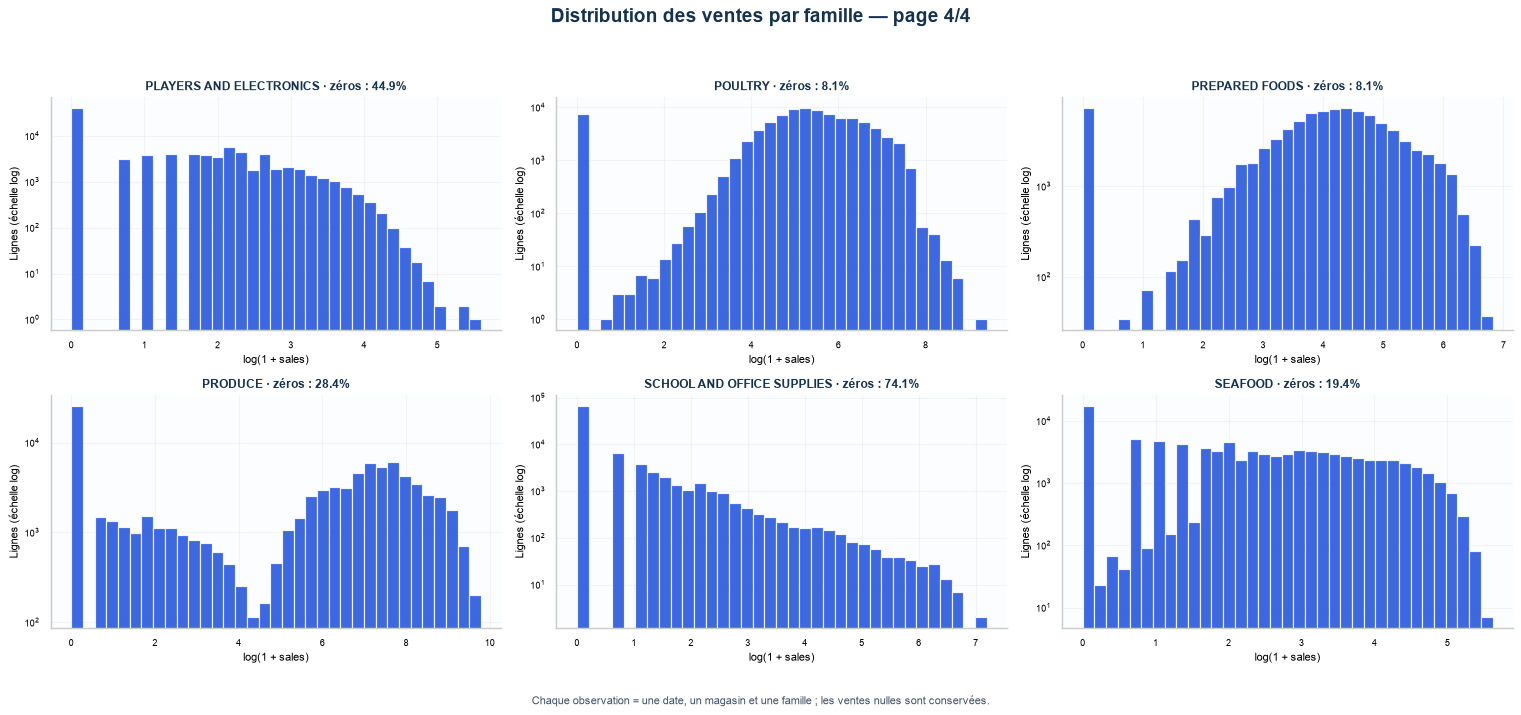

In [14]:
v_groupes_familles = ventes.groupby("family", observed=True, sort=False)
def dessiner_distribution_famille(ax, famille):
    valeurs = v_groupes_familles.get_group(famille)["sales"].to_numpy(dtype=float)
    ax.hist(np.log1p(valeurs), bins=35, color=COULEURS_VISUELLES["ventes"], alpha=0.85)
    ax.set_yscale("log")
    ax.set_xlabel("log(1 + sales)", fontsize=9)
    ax.set_title(f"{famille} · zéros : {(valeurs == 0).mean():.1%}", color=BLEU_VISUEL, fontweight="bold", fontsize=10)

grilles_visuelles(
    familles_visuelles, "Distribution des ventes par famille", dessiner_distribution_famille,
    "Lignes (échelle log)", note="Chaque observation = une date, un magasin et une famille ; les ventes nulles sont conservées."
)
lecture_visuelle(
    f"La médiane vaut zéro dans {int(v_resume_familles['mediane'].eq(0).sum())} familles. "
    "La hauteur des premières classes permet de distinguer la fréquence des petits volumes de la présence de pics. "
    "Une grande valeur n’est pas automatiquement une erreur : elle peut correspondre à un magasin, une promotion ou une période particulière."
)


<h3 style="color:#2563EB; font-weight:700;">10.3. Zéros, pics et périodes actives</h3>

**Question :** Quels profils atypiques méritent un examen contextualisé ?

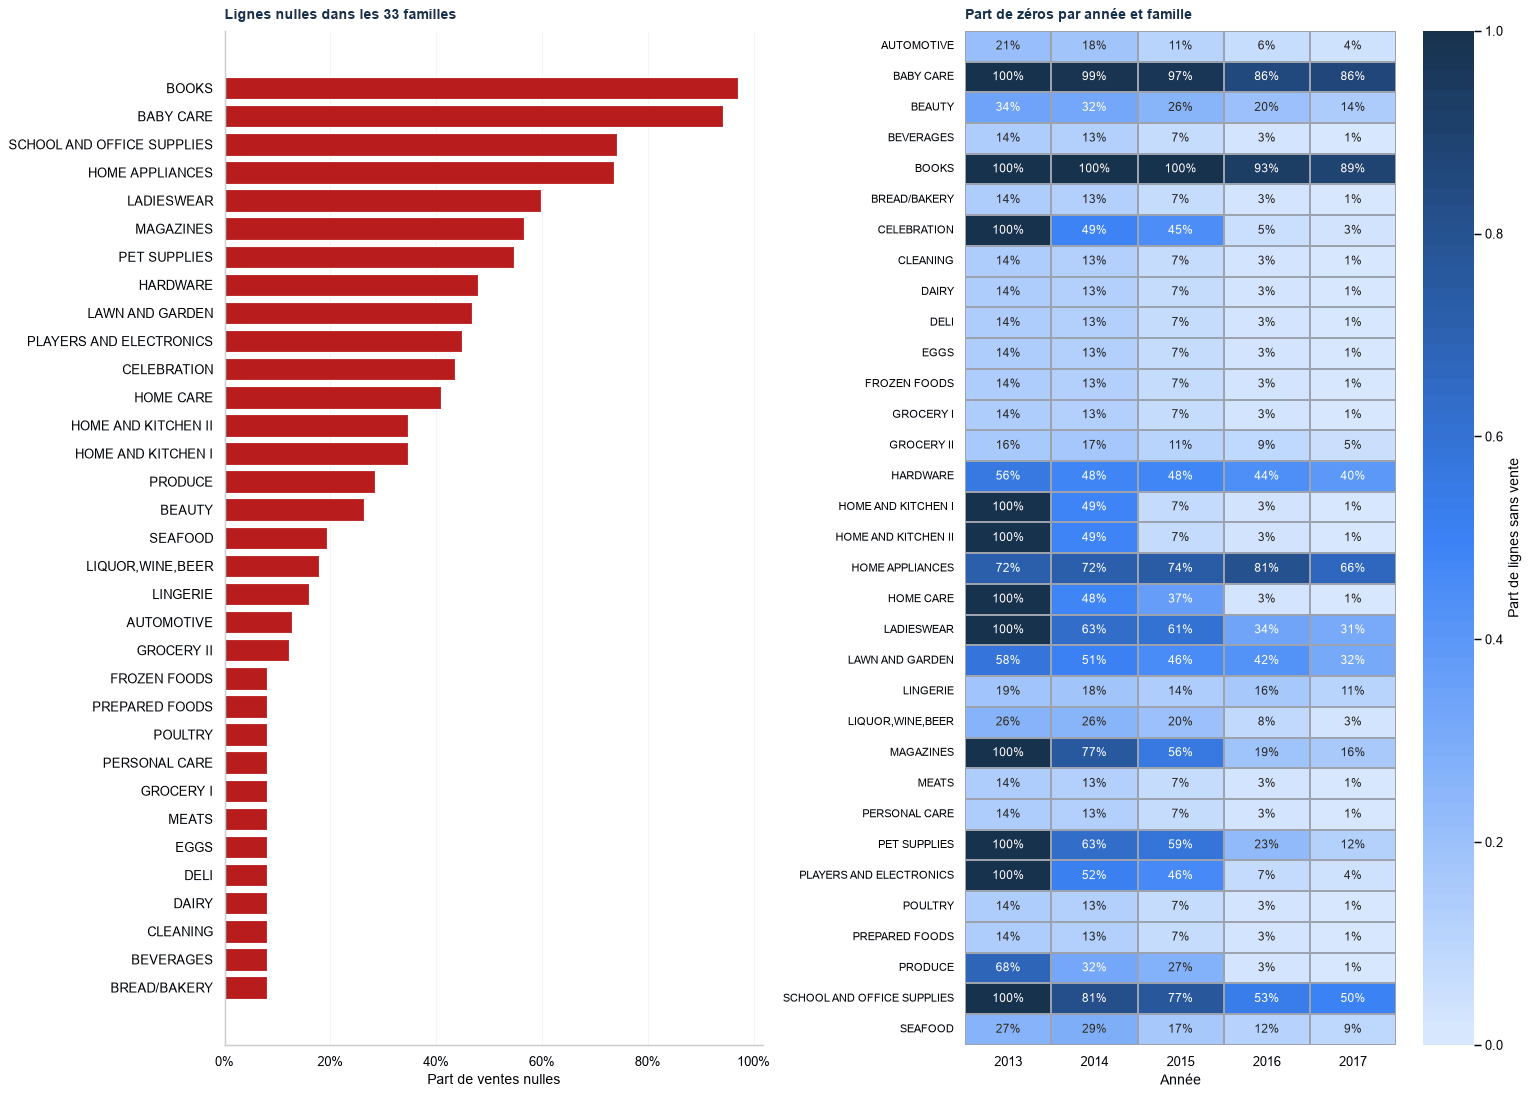

In [15]:
v_zeros_annee = ventes.assign(annee=ventes["date"].dt.year, vente_nulle=ventes["sales"].eq(0)).groupby(
    ["family", "annee"], observed=True
)["vente_nulle"].mean().unstack("annee").reindex(familles_visuelles)
fig, axes = plt.subplots(1, 2, figsize=(18, 13))
barres_visuelles(axes[0], v_resume_familles["part_zeros"], "Lignes nulles dans les 33 familles", "Part de ventes nulles", COULEURS_VISUELLES["evenement"])
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
sns.heatmap(v_zeros_annee, annot=True, fmt=".0%", cmap=CMAP_SEQUENTIELLE, linecolor="#9CA3AF", linewidths=.4, vmin=0, vmax=1,
            yticklabels=True, cbar_kws={"label": "Part de lignes sans vente"}, ax=axes[1])
titre_visuel(axes[1], "Part de zéros par année et famille", "Année")
axes[1].set_ylabel("")
axes[1].tick_params(axis="y", labelsize=9)
fig.tight_layout()
plt.show()
plt.close(fig)
lecture_visuelle(
    "La carte met en évidence les changements dans la fréquence des ventes nulles sans les assimiler à des ruptures. "
    "L’année 2017 est partielle ; une évolution peut aussi refléter l’assortiment ou l’activité des magasins."
)


,date_pic,maximum_jour,mediane_jours_positifs,rapport_pic_mediane_positive,volume_total,premiere_vente_positive,derniere_vente_positive
family,,,,,,,
SCHOOL AND OFFICE SUPPLIES,2017-08-06,"5 415,000","86,000","62,970","269 316,000",2014-01-02,2017-08-15
LAWN AND GARDEN,2017-05-13,"6 963,000","235,000","29,630","548 842,000",2013-01-01,2017-08-15
FROZEN FOODS,2015-12-22,"122 042,906","5 998,140","20,350","14 073 888,000",2013-01-01,2017-08-15
BABY CARE,2015-08-04,"125,000","10,000","12,500","10 051,000",2014-03-01,2017-08-15
"LIQUOR,WINE,BEER",2015-12-31,"32 791,000","3 683,500","8,900","7 746 640,000",2013-01-01,2017-08-15
BOOKS,2016-10-16,"127,000","16,000","7,940","6 438,000",2016-10-08,2017-08-13
MEATS,2016-10-07,"114 430,281","17 753,000","6,450","31 086 470,000",2013-01-01,2017-08-15
HOME AND KITCHEN II,2015-10-17,"6 020,000","1 238,000","4,860","1 520 670,125",2014-01-01,2017-08-15
BEAUTY,2016-11-06,"792,000","183,000","4,330","337 893,000",2013-01-01,2017-08-15


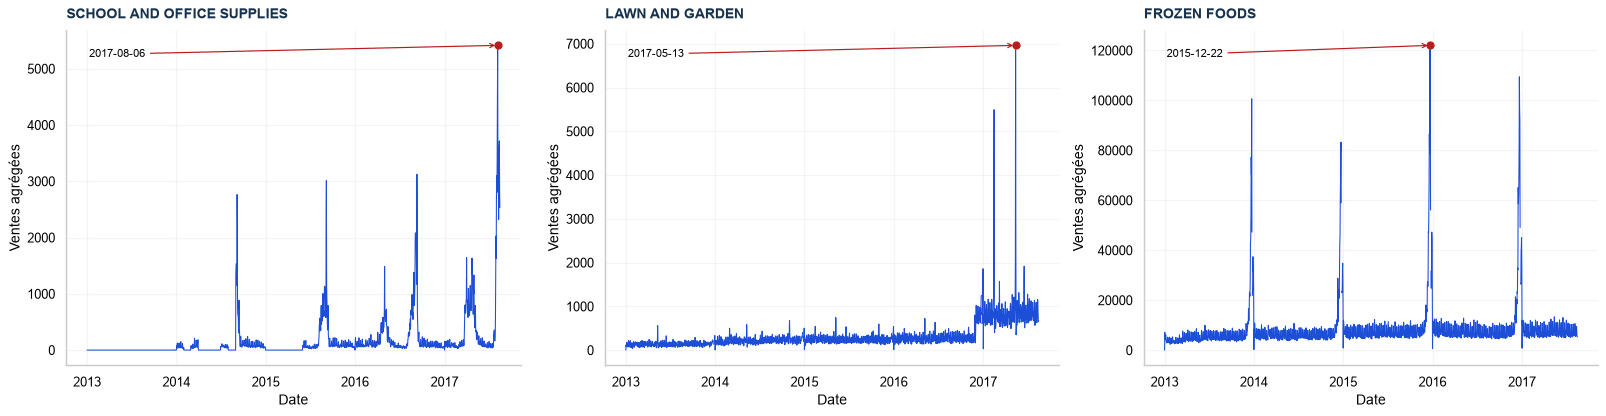

In [16]:
v_pics = pd.DataFrame({
    "date_pic": v_ventes_familles.idxmax(),
    "maximum_jour": v_ventes_familles.max(),
    "mediane_jours_positifs": v_ventes_familles.where(v_ventes_familles.gt(0)).median(),
})
v_pics["rapport_pic_mediane_positive"] = v_pics["maximum_jour"] / v_pics["mediane_jours_positifs"].replace(0, np.nan)
v_pics["volume_total"] = v_resume_familles["volume"]
v_pics["premiere_vente_positive"] = pd.Series({
    famille: v_ventes_familles.index[v_ventes_familles[famille].gt(0)].min() for famille in familles_visuelles
})
v_pics["derniere_vente_positive"] = pd.Series({
    famille: v_ventes_familles.index[v_ventes_familles[famille].gt(0)].max() for famille in familles_visuelles
})
v_pics = v_pics.sort_values("rapport_pic_mediane_positive", ascending=False)
afficher_tableau_visuel(v_pics.round({colonne: 2 for colonne in v_pics.select_dtypes(include='number').columns}))
v_exemples_pics = v_pics.dropna(subset=["rapport_pic_mediane_positive"]).head(3).index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, famille in zip(axes, v_exemples_pics):
    serie = v_ventes_familles[famille]
    date_pic = v_pics.loc[famille, "date_pic"]
    ax.plot(serie.index, serie, color=COULEURS_VISUELLES["ventes"], linewidth=.9)
    ax.scatter([date_pic], [serie.loc[date_pic]], color=COULEURS_VISUELLES["evenement"], s=35, zorder=3)
    ax.annotate(str(date_pic.date()), xy=(date_pic, serie.loc[date_pic]), xytext=(0.05, 0.92),
                textcoords="axes fraction", arrowprops={"arrowstyle": "->", "color": "#B91C1C"}, fontsize=9)
    titre_visuel(ax, famille, "Date", "Ventes agrégées")
fig.tight_layout()
plt.show()
plt.close(fig)
lecture_visuelle(
    "Ces trois exemples sont sélectionnés pour leur contraste entre maximum et médiane des jours positifs, "
    "pas pour représenter l’ensemble du jeu. Un petit niveau de référence peut gonfler ce rapport. "
    "Les premières ventes positives restent des indices d’activité, pas des dates d’ouverture confirmées."
)


<a id="section-11"></a>

<h2 style="color:#2563EB; font-weight:700;">11. Analyse des 54 magasins</h2>

**Question :** Comment diffèrent les 54 magasins et leurs caractéristiques ?

<h3 style="color:#2563EB; font-weight:700;">11.1. Courbes de tous les magasins</h3>

**Question :** Quels changements de niveau et périodes sans ventes observe-t-on ?

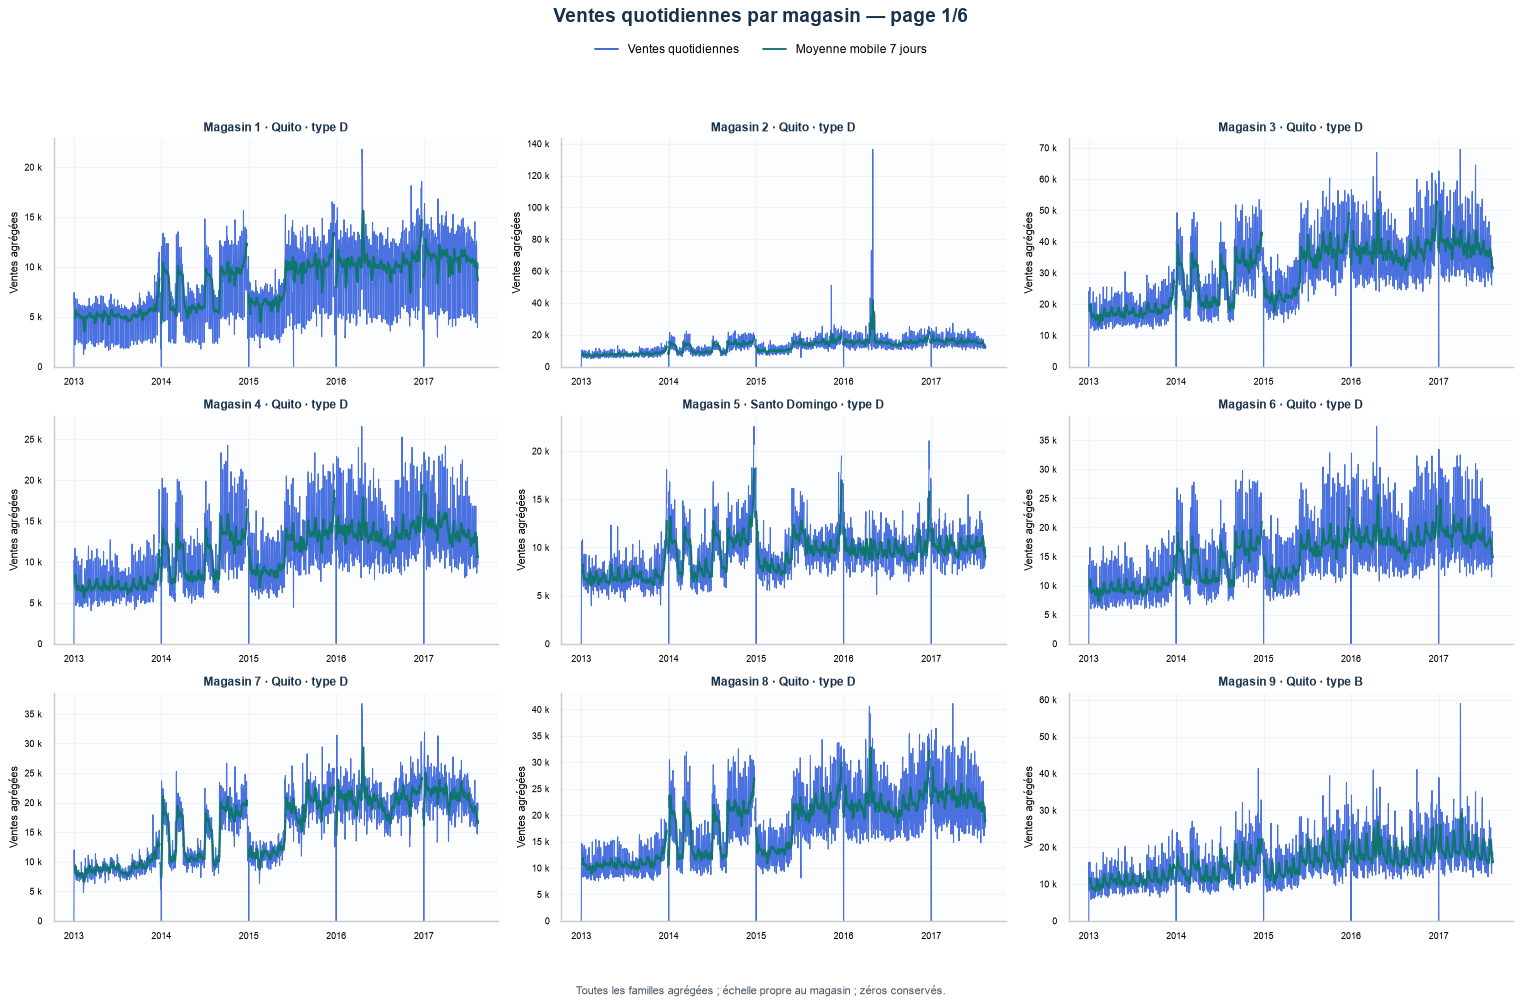

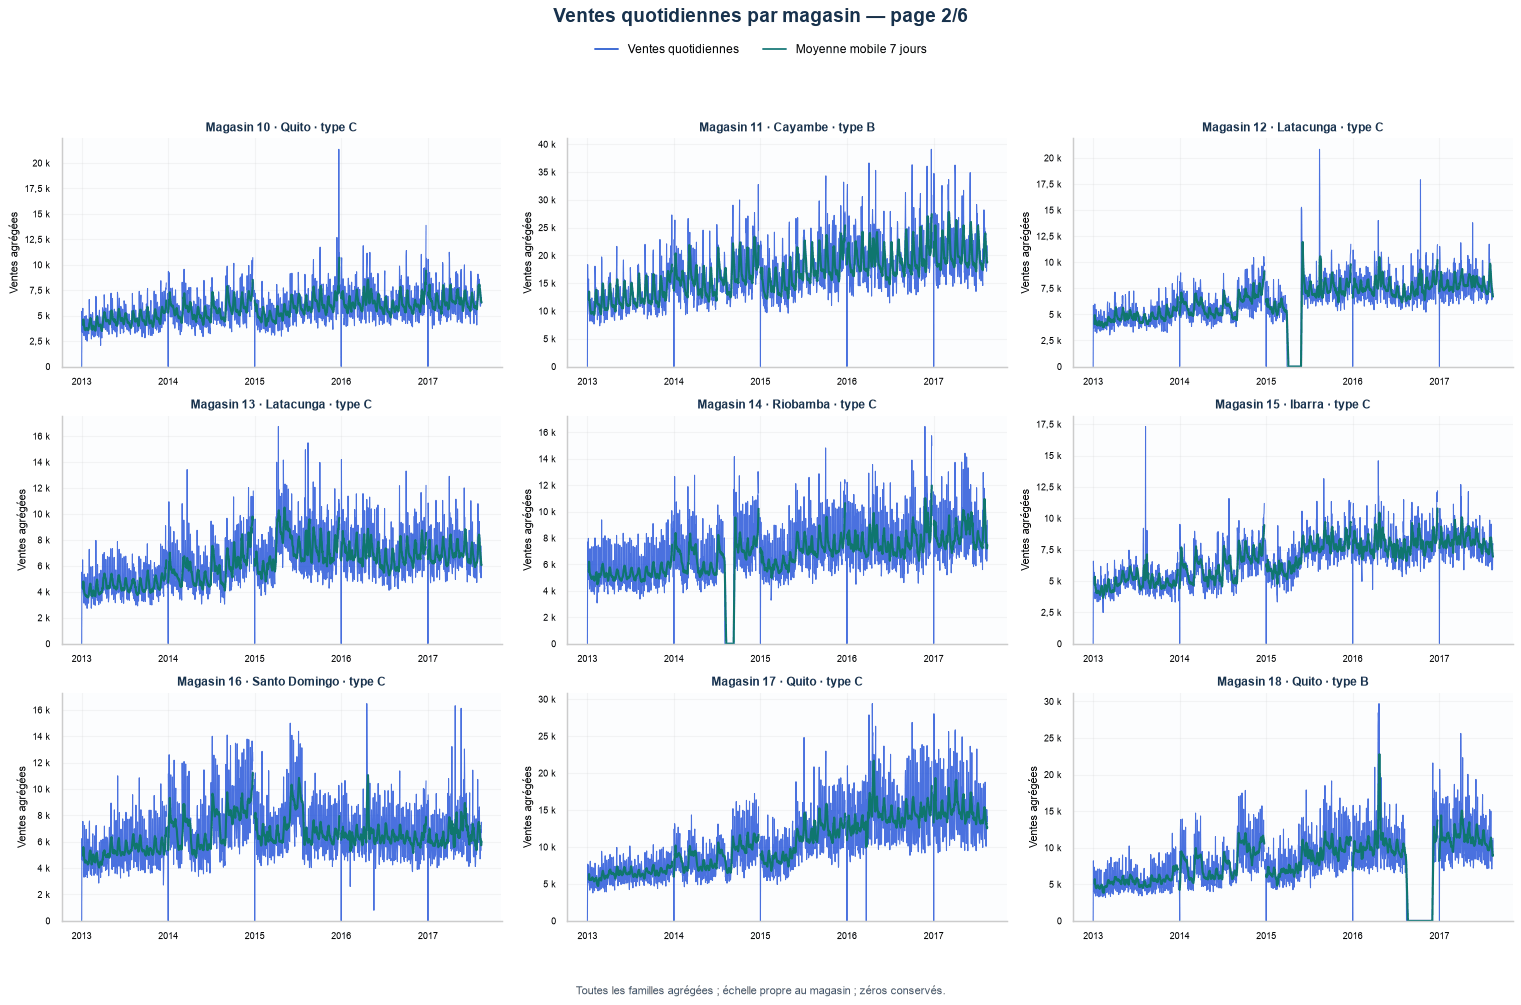

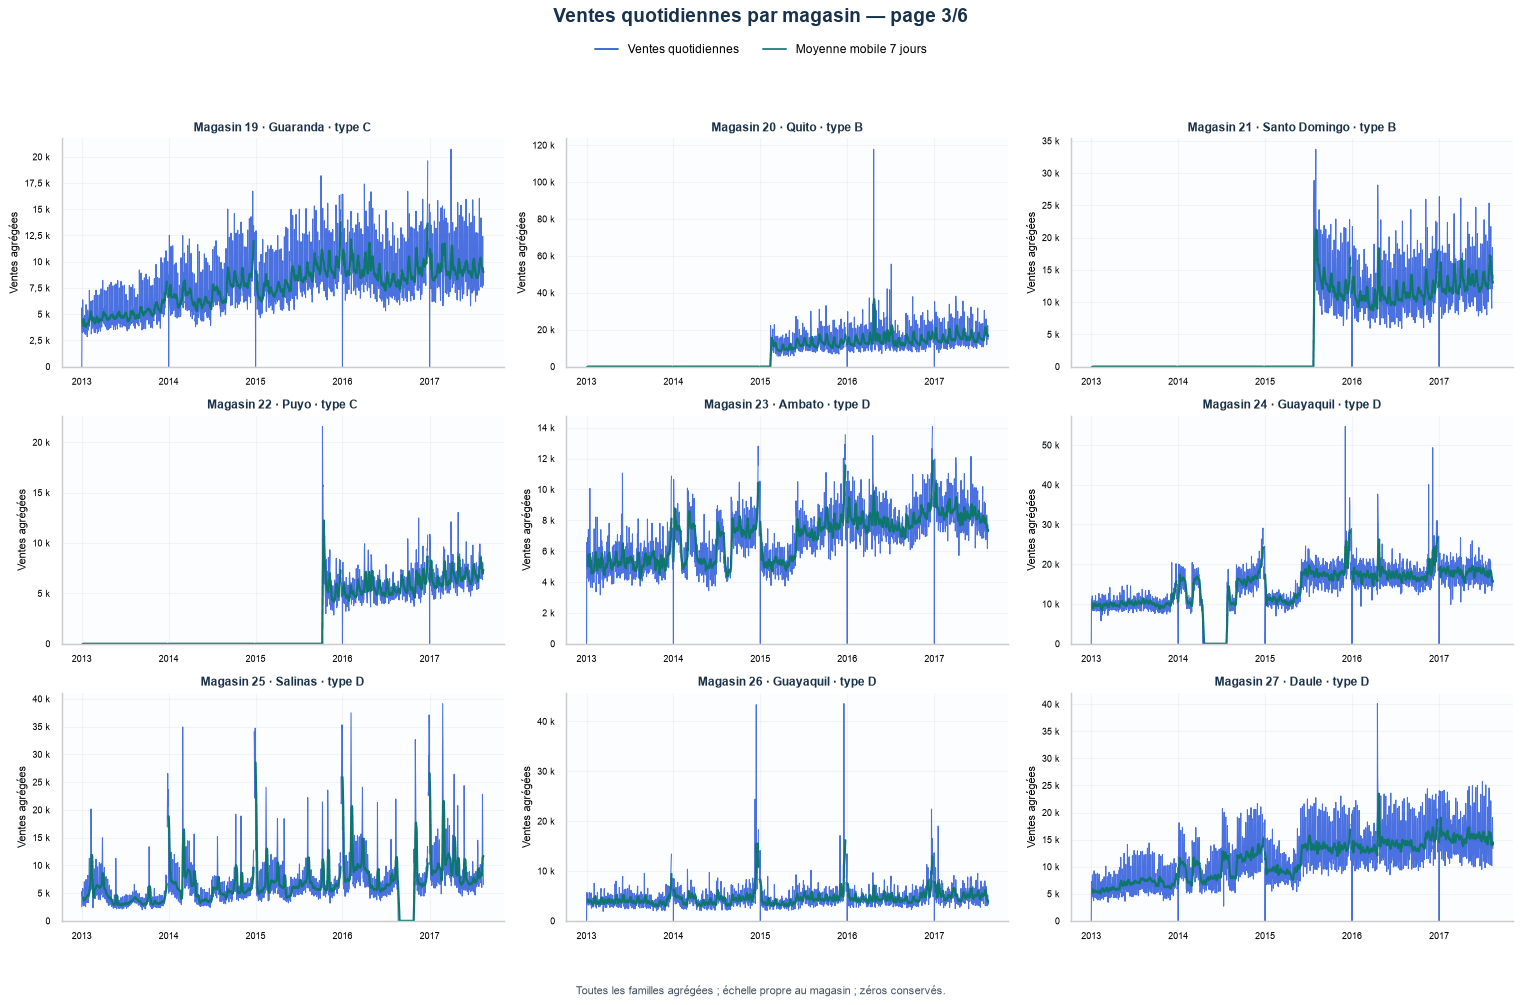

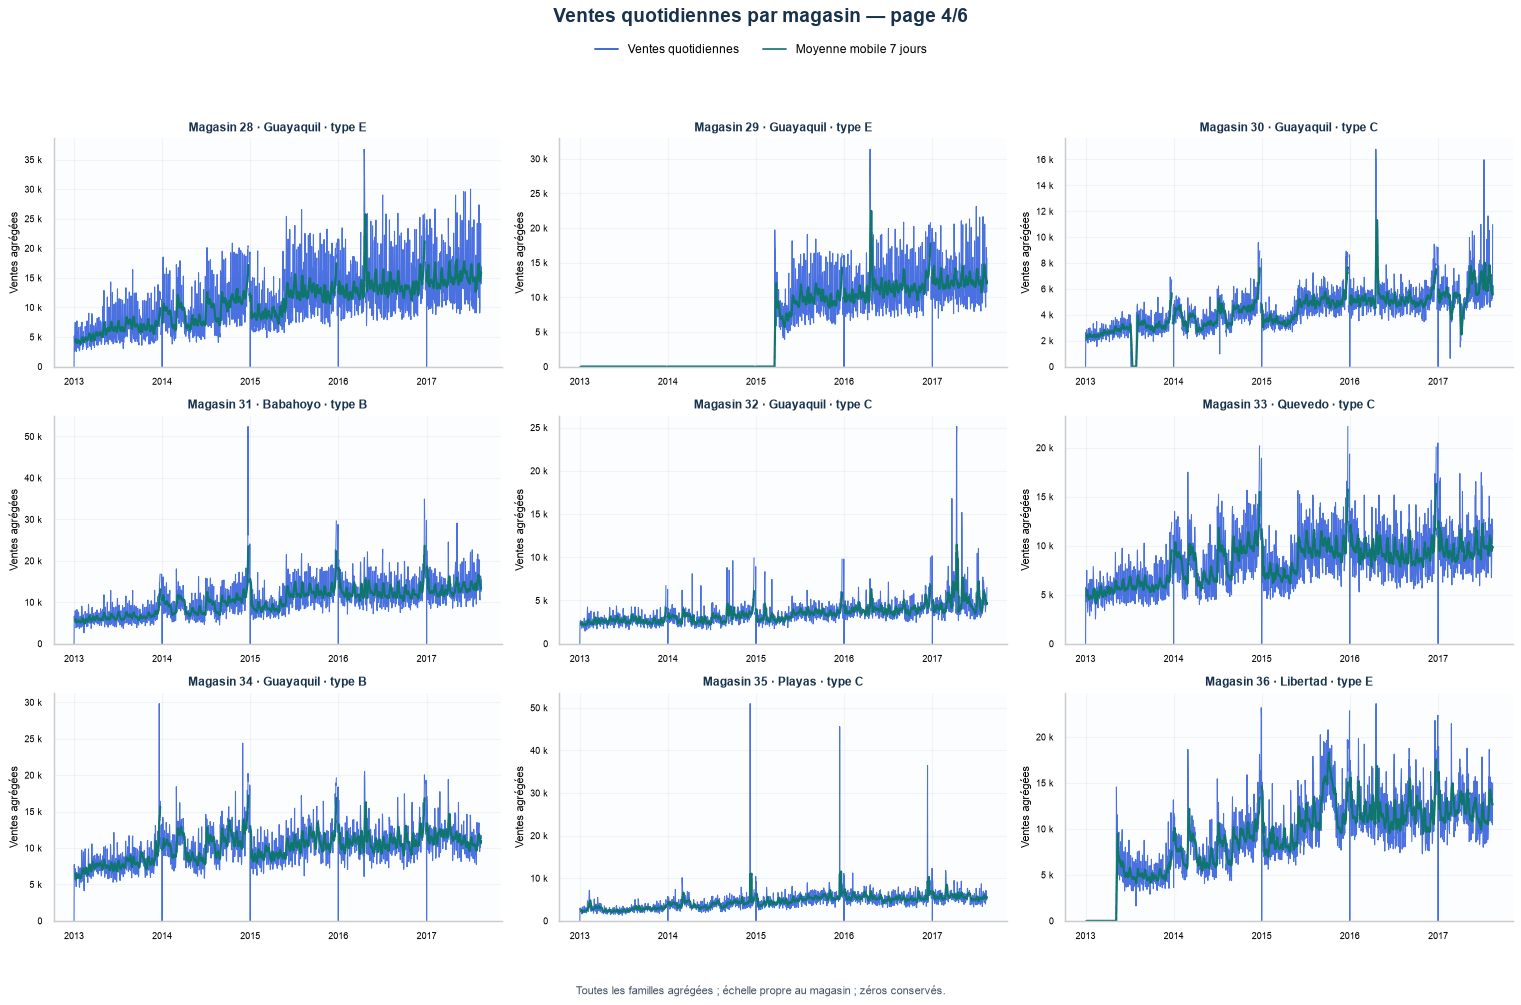

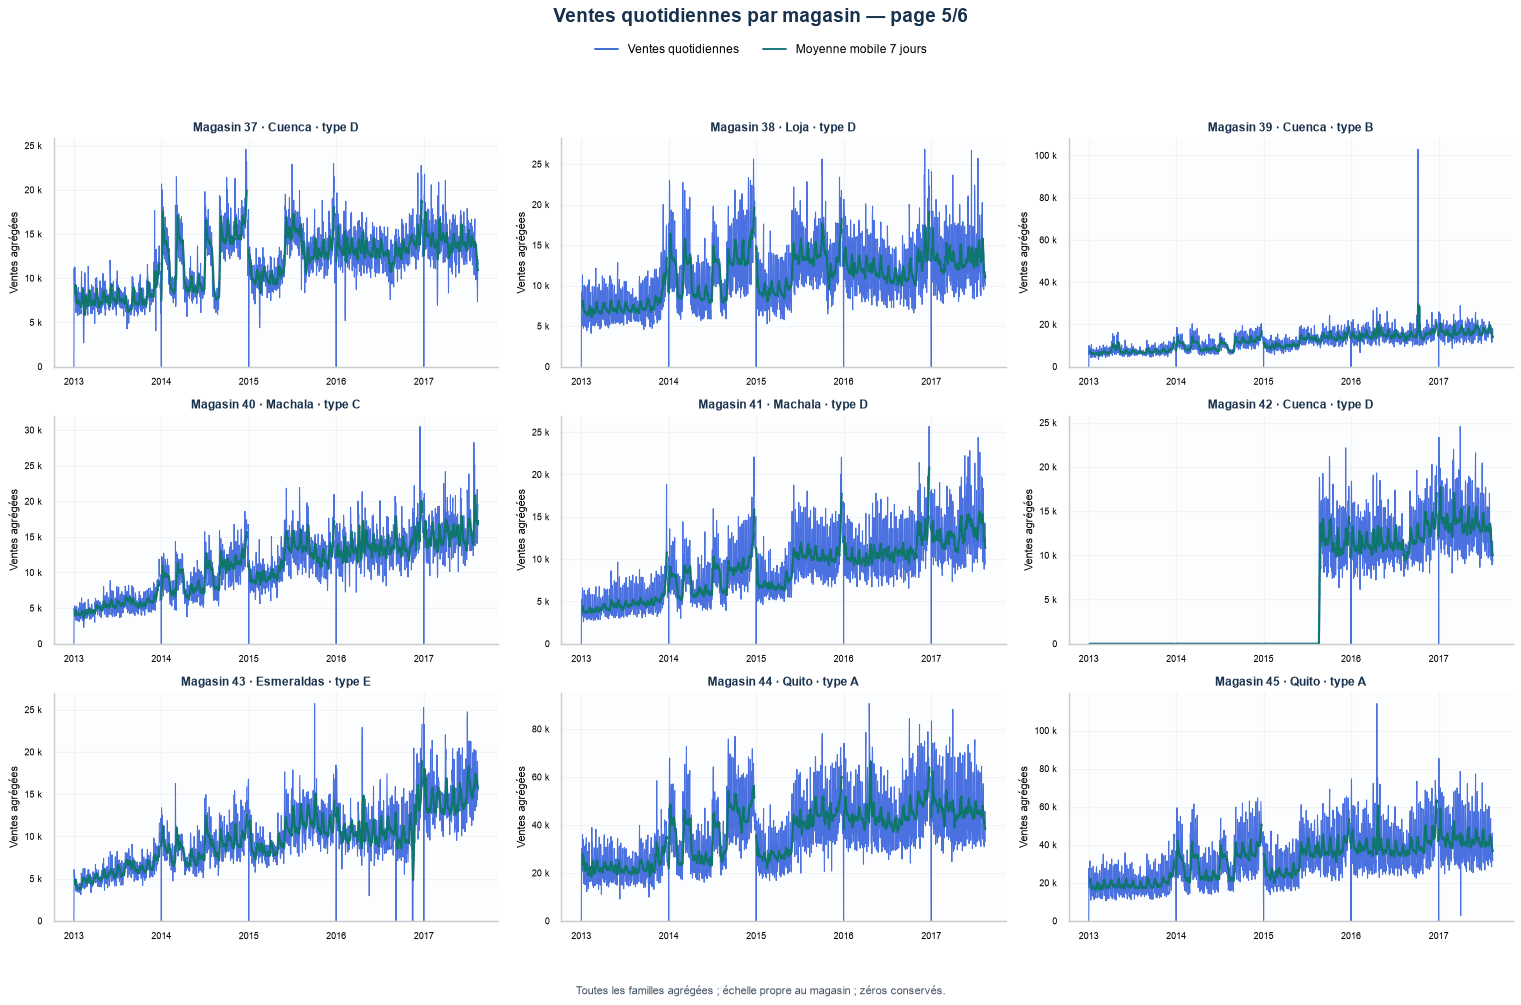

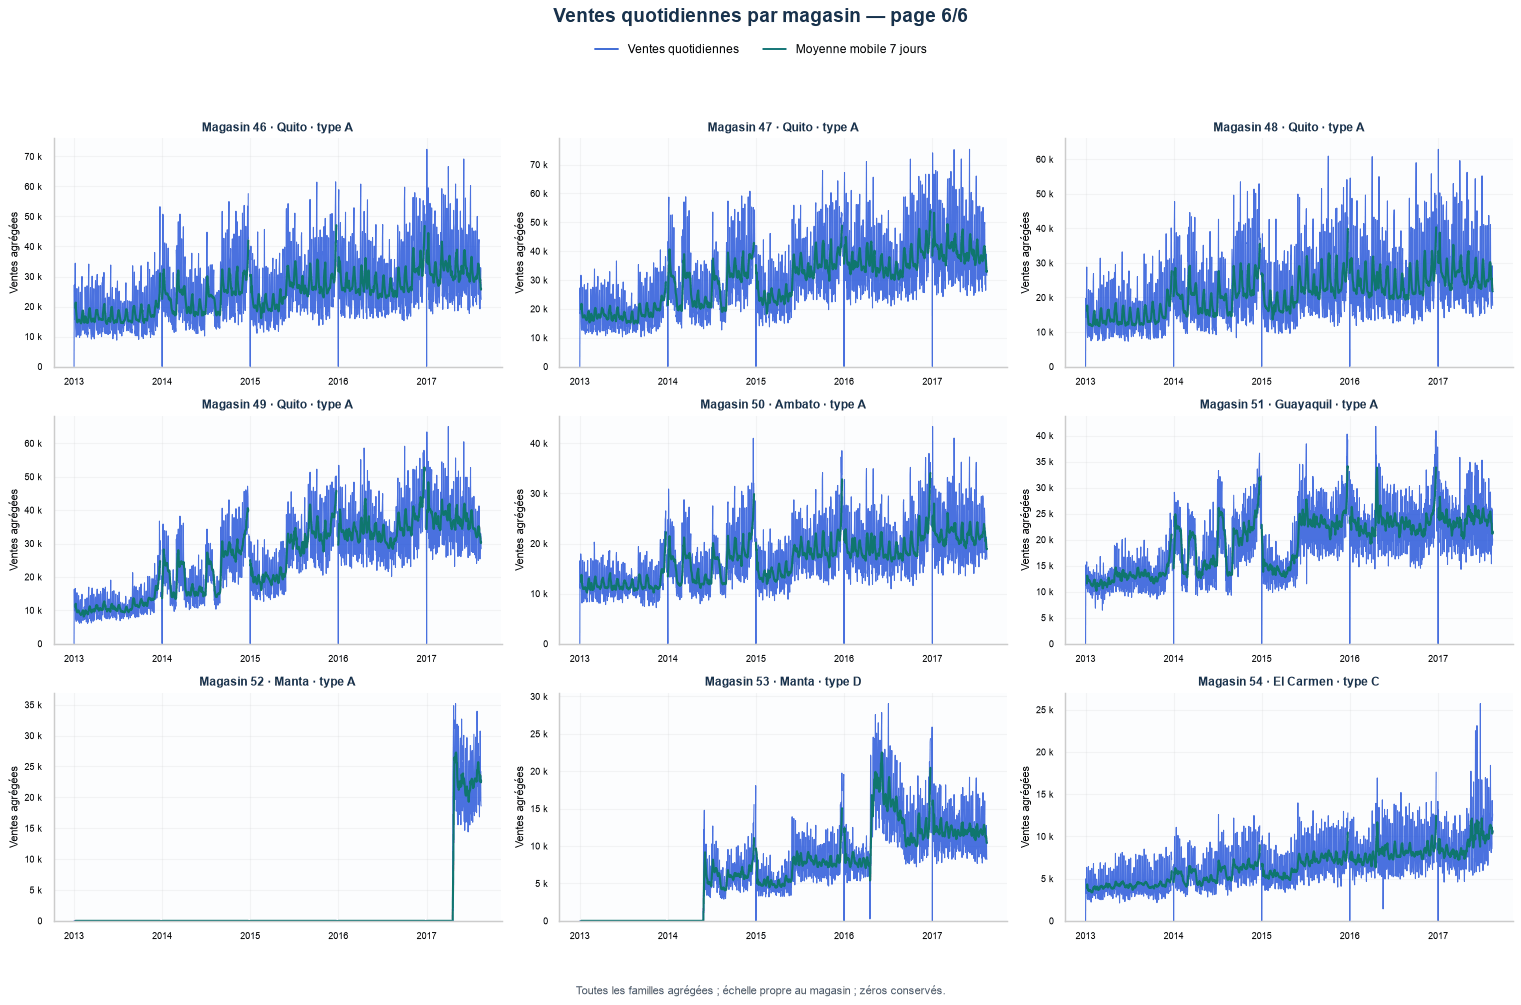

,volume,moyenne_jour,jours_observes,city,state,type,cluster
store_nbr,,,,,,,
44,"62 087 552,000","36 869,102",1 684,Quito,Pichincha,A,5
45,"54 498 012,000","32 362,240",1 684,Quito,Pichincha,A,11
47,"50 948 312,000","30 254,340",1 684,Quito,Pichincha,A,14
3,"50 481 908,000","29 977,381",1 684,Quito,Pichincha,D,8
49,"43 420 100,000","25 783,900",1 684,Quito,Pichincha,A,11
46,"41 896 064,000","24 878,900",1 684,Quito,Pichincha,A,14
48,"35 933 132,000","21 337,961",1 684,Quito,Pichincha,A,14
51,"32 911 490,000","19 543,641",1 684,Guayaquil,Guayas,A,17
8,"30 494 284,000","18 108,250",1 684,Quito,Pichincha,D,8


In [17]:
def dessiner_magasin(ax, magasin):
    ax.plot(v_ventes_magasins.index, v_ventes_magasins[magasin], color=COULEURS_VISUELLES["ventes"], linewidth=.9, alpha=.8)
    ax.plot(v_tendances_magasins.index, v_tendances_magasins[magasin], color=COULEURS_VISUELLES["tendance"], linewidth=1.8)
    ref = v_stores_index.loc[magasin]
    ax.set_title(f"Magasin {magasin} · {ref['city']} · type {ref['type']}", color=BLEU_VISUEL, fontweight="bold", fontsize=10)

grilles_visuelles(
    magasins_visuels, "Ventes quotidiennes par magasin", dessiner_magasin, "Ventes agrégées",
    legende_familles[:2], "Toutes les familles agrégées ; échelle propre au magasin ; zéros conservés."
)
v_resume_magasins = v_magasin_jour.groupby("store_nbr")["ventes"].agg(volume="sum", moyenne_jour="mean", jours_observes="size")
v_resume_magasins = v_resume_magasins.join(v_stores_index, validate="one_to_one")
afficher_tableau_visuel(v_resume_magasins.sort_values("volume", ascending=False).round(2))
lecture_visuelle(
    f"Le magasin {int(v_resume_magasins['volume'].idxmax())} a le volume agrégé le plus élevé sur la période. "
    "Les longues périodes nulles et les changements de niveau doivent être rapprochés du calendrier et de la première vente positive, "
    "sans conclure automatiquement à des ruptures."
)


<h3 style="color:#2563EB; font-weight:700;">11.2. Ville, État, type et cluster</h3>

**Question :** Les moyennes sont-elles comparables en tenant compte des effectifs ?

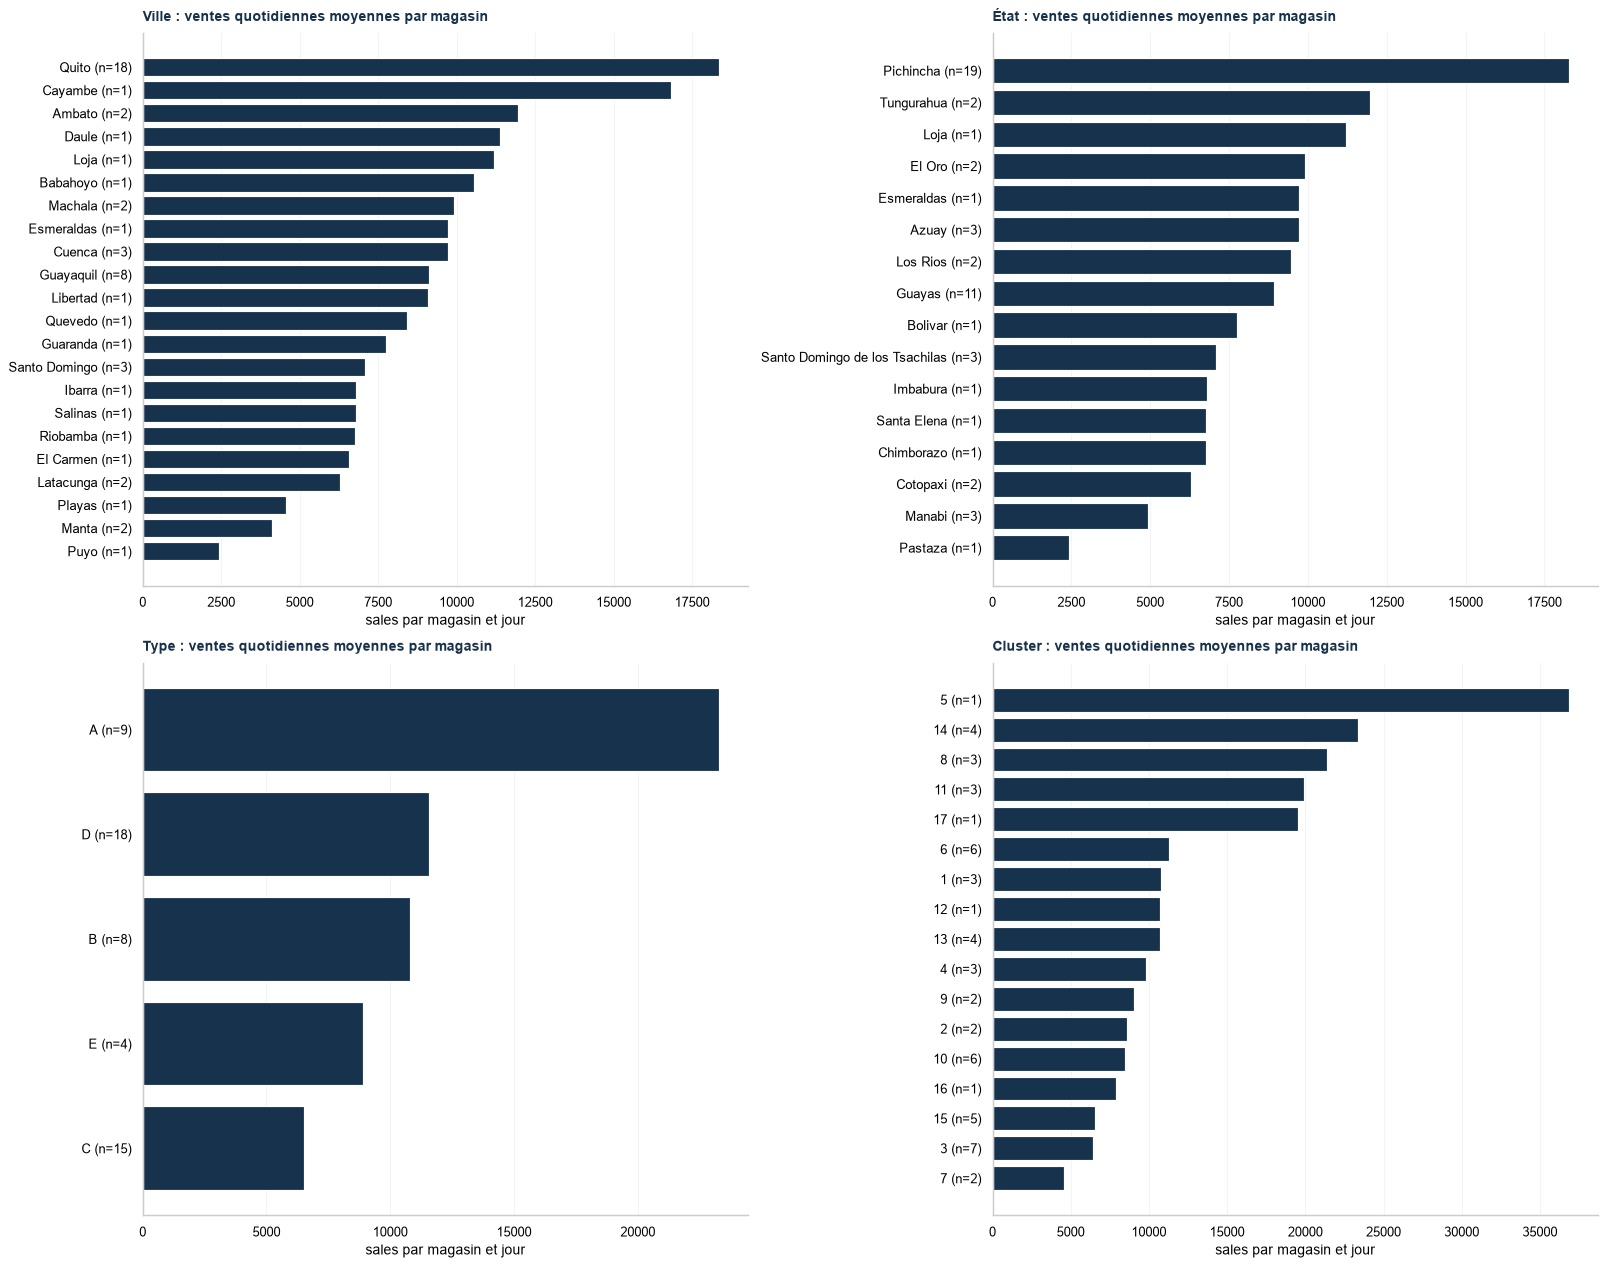

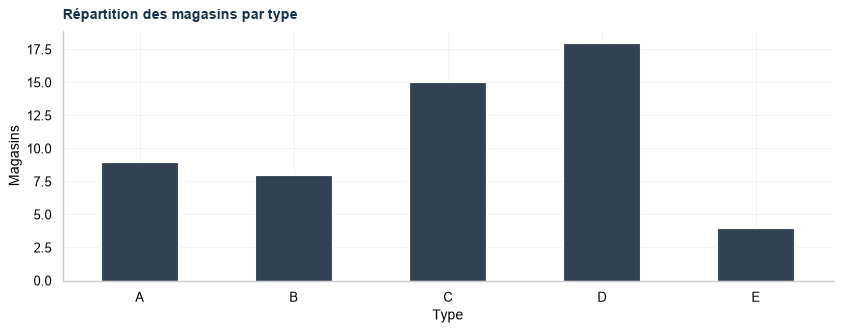

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(19, 15))
for ax, variable, label in zip(axes.flat, ("city", "state", "type", "cluster"), ("Ville", "État", "Type", "Cluster")):
    moyenne = v_resume_magasins.groupby(variable)["moyenne_jour"].mean()
    effectifs = v_stores.groupby(variable).size()
    moyenne.index = pd.Index([f"{valeur} (n={int(effectifs.loc[valeur])})" for valeur in moyenne.index])
    barres_visuelles(ax, moyenne, f"{label} : ventes quotidiennes moyennes par magasin", "sales par magasin et jour")
fig.tight_layout()
plt.show()
plt.close(fig)
fig, ax = plt.subplots(figsize=(10, 4))
v_stores.groupby("type").size().sort_index().plot.bar(ax=ax, color=COULEURS_VISUELLES["neutre"], rot=0)
titre_visuel(ax, "Répartition des magasins par type", "Type", "Magasins")
fig.tight_layout()
plt.show()
plt.close(fig)
lecture_visuelle(
    f"Le référentiel comprend {v_stores['city'].nunique()} villes, {v_stores['state'].nunique()} États, "
    f"{v_stores['type'].nunique()} types et {v_stores['cluster'].nunique()} clusters. "
    "Les effectifs sont indiqués dans les libellés. Ces catégories peuvent aussi refléter taille, assortiment et ancienneté ; "
    "elles n’expliquent pas à elles seules les différences de ventes."
)


<h3 style="color:#2563EB; font-weight:700;">11.3. Fréquence des zéros et première vente positive</h3>

**Question :** Une activité tardive peut-elle expliquer un profil de zéros ?

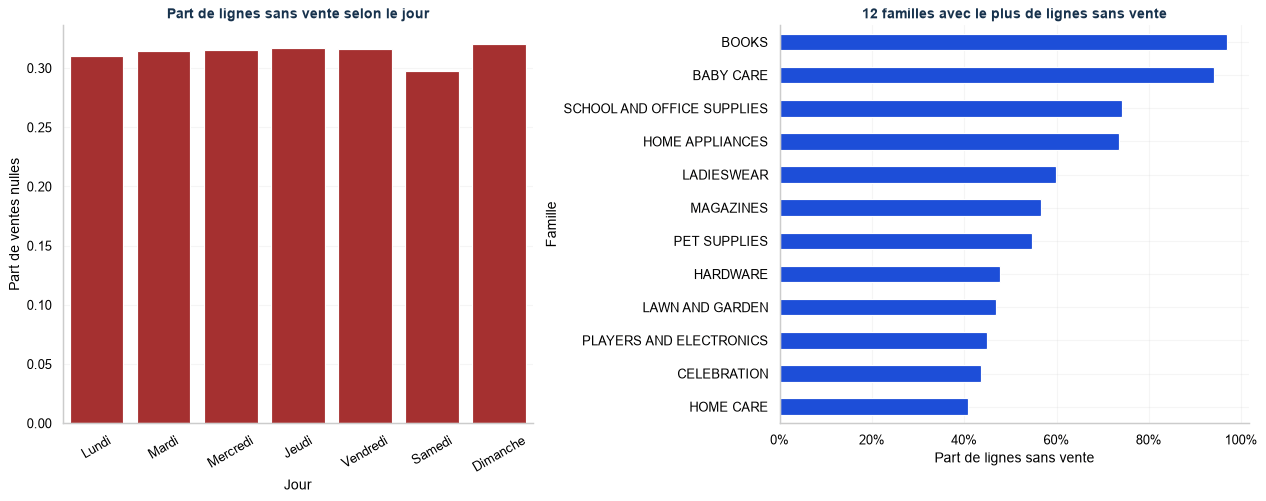

In [19]:
NOMS_JOURS = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
ventes_analyse = ventes.assign(
    jour_semaine=ventes["date"].dt.dayofweek,
    vente_nulle=ventes["sales"].eq(0),
)

zero_par_jour = (
    ventes_analyse.groupby("jour_semaine", observed=True)["vente_nulle"]
    .mean()
    .reindex(range(7))
)
zero_par_famille = (
    ventes_analyse.groupby("family", observed=True)["vente_nulle"]
    .mean()
    .sort_values(ascending=False)
    .head(12)
    .sort_values()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(
    x=[NOMS_JOURS[jour] for jour in zero_par_jour.index],
    y=zero_par_jour.values,
    color=COULEURS["manquant"],
    ax=axes[0],
)
axes[0].set(title="Part de lignes sans vente selon le jour", xlabel="Jour", ylabel="Part de ventes nulles")
axes[0].tick_params(axis="x", rotation=30)

zero_par_famille.plot.barh(ax=axes[1], color=COULEURS["ventes"])
axes[1].set(title="12 familles avec le plus de lignes sans vente", xlabel="Part de lignes sans vente", ylabel="Famille")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda valeur, _: f"{valeur:.0%}"))
sns.despine()
plt.tight_layout()
plt.show()


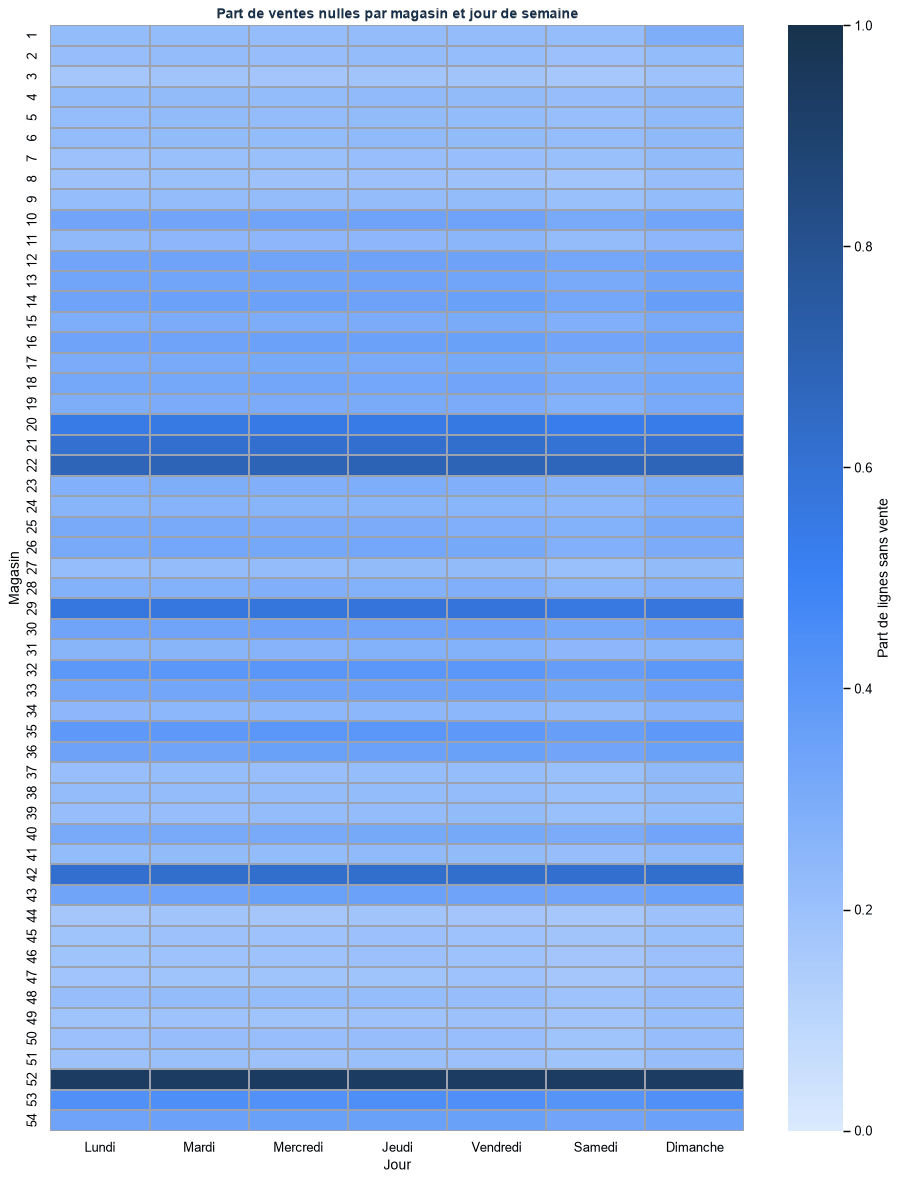

In [20]:
zero_magasin_jour = (
    ventes_analyse.groupby(["store_nbr", "jour_semaine"], observed=True)["vente_nulle"]
    .mean()
    .unstack("jour_semaine")
    .reindex(columns=range(7))
)
zero_magasin_jour.columns = NOMS_JOURS

fig, ax = plt.subplots(figsize=(11, 14))
sns.heatmap(
    zero_magasin_jour,
    cmap=CMAP_SEQUENTIELLE, linecolor="#9CA3AF", linewidths=.4,
    vmin=0,
    vmax=1,
    ax=ax,
    cbar_kws={"label": "Part de lignes sans vente"},
)
ax.set(title="Part de ventes nulles par magasin et jour de semaine", xlabel="Jour", ylabel="Magasin")
plt.tight_layout()
plt.show()


In [21]:
resume_magasin = ventes_analyse.groupby("store_nbr", observed=True).agg(
    part_lignes_zero=("vente_nulle", "mean"),
    lignes_positives=("sales", lambda serie: serie.gt(0).sum()),
    jours_observes=("date", "nunique"),
)
ventes_positives = ventes.loc[ventes["sales"].gt(0)]
premiere_vente = ventes_positives.groupby("store_nbr")["date"].min()
derniere_vente = ventes_positives.groupby("store_nbr")["date"].max()
resume_magasin["premiere_vente_positive"] = premiere_vente
resume_magasin["derniere_vente_positive"] = derniere_vente

resume_magasin = resume_magasin.sort_values("part_lignes_zero", ascending=False)
afficher_tableau(resume_magasin.head(10).style.format({"part_lignes_zero": "{:.1%}"}))
if 52 in resume_magasin.index:
    print("Détail magasin 52 :")
    afficher_tableau(resume_magasin.loc[[52]].style.format({"part_lignes_zero": "{:.1%}"}))


,part_lignes_zero,lignes_positives,jours_observes,premiere_vente_positive,derniere_vente_positive
store_nbr,,,,,
52,"93,5%",3 590,1 684,2017-04-20,2017-08-15
22,"68,5%",17 478,1 684,2015-10-09,2017-08-15
42,"62,2%",20 997,1 684,2015-08-21,2017-08-15
21,"61,3%",21 506,1 684,2015-07-24,2017-08-15
29,"57,2%",23 775,1 684,2015-03-20,2017-08-15
20,"54,5%",25 301,1 684,2015-02-13,2017-08-15
53,"43,2%",31 544,1 684,2014-05-29,2017-08-15
32,"39,6%",33 577,1 684,2013-01-02,2017-08-15
35,"39,1%",33 834,1 684,2013-01-02,2017-08-15


Détail magasin 52 :


,part_lignes_zero,lignes_positives,jours_observes,premiere_vente_positive,derniere_vente_positive
store_nbr,,,,,
52,"93,5%",3 590,1 684,2017-04-20,2017-08-15


In [22]:
lignes_magasin_52 = ventes.loc[ventes["store_nbr"].eq(52)].copy()
premiere_vente_52 = lignes_magasin_52.loc[
    lignes_magasin_52["sales"].gt(0), "date"
].min()

if pd.isna(premiere_vente_52):
    print("Aucune vente positive observée pour le magasin 52.")
else:
    lignes_magasin_52["periode_relative"] = lignes_magasin_52["date"].ge(premiere_vente_52).map(
        {False: "Avant la première vente positive", True: "À partir de la première vente positive"}
    )
    comparaison_52 = (
        lignes_magasin_52.groupby("periode_relative", observed=True)
        .agg(
            part_lignes_zero=("sales", lambda serie: serie.eq(0).mean()),
            ventes_mediane=("sales", "median"),
            observations=("sales", "size"),
            premiere_date=("date", "min"),
            derniere_date=("date", "max"),
        )
    )
    print(f"Première vente positive observée : {premiere_vente_52.date()}")
    afficher_tableau(comparaison_52.style.format({"part_lignes_zero": "{:.1%}"}))


Première vente positive observée : 2017-04-20


,part_lignes_zero,ventes_mediane,observations,premiere_date,derniere_date
periode_relative,,,,,
Avant la première vente positive,"100,0%","0,000",51 678,2013-01-01,2017-04-19
À partir de la première vente positive,"7,8%","58,500",3 894,2017-04-20,2017-08-15


La première vente positive est un indice d’activité, pas une date d’ouverture confirmée. Les zéros ne sont pas transformés en ruptures observées.

<a id="section-12"></a>

<h2 style="color:#2563EB; font-weight:700;">12. Promotions, transactions et pétrole</h2>

**Question :** Quelles associations descriptives relient les ventes aux autres mesures ?

Les comparaisons ne contrôlent pas tous les facteurs de magasin, de période ou de sélection des promotions. Elles ne démontrent pas de causalité. Le pétrole et les transactions ne sont pas utilisés comme prédicteurs futurs dans le modèle retenu.

<h3 style="color:#2563EB; font-weight:700;">12.1. Promotions : fréquence, évolution et comparaisons</h3>

**Question :** Que montre chaque famille, avec et sans promotion ?

<h3 style="color:#2563EB; font-weight:700;">Vue de synthèse · Ventes et promotions</h3>

Cette figure résume les points de lecture ; les analyses détaillées suivent.

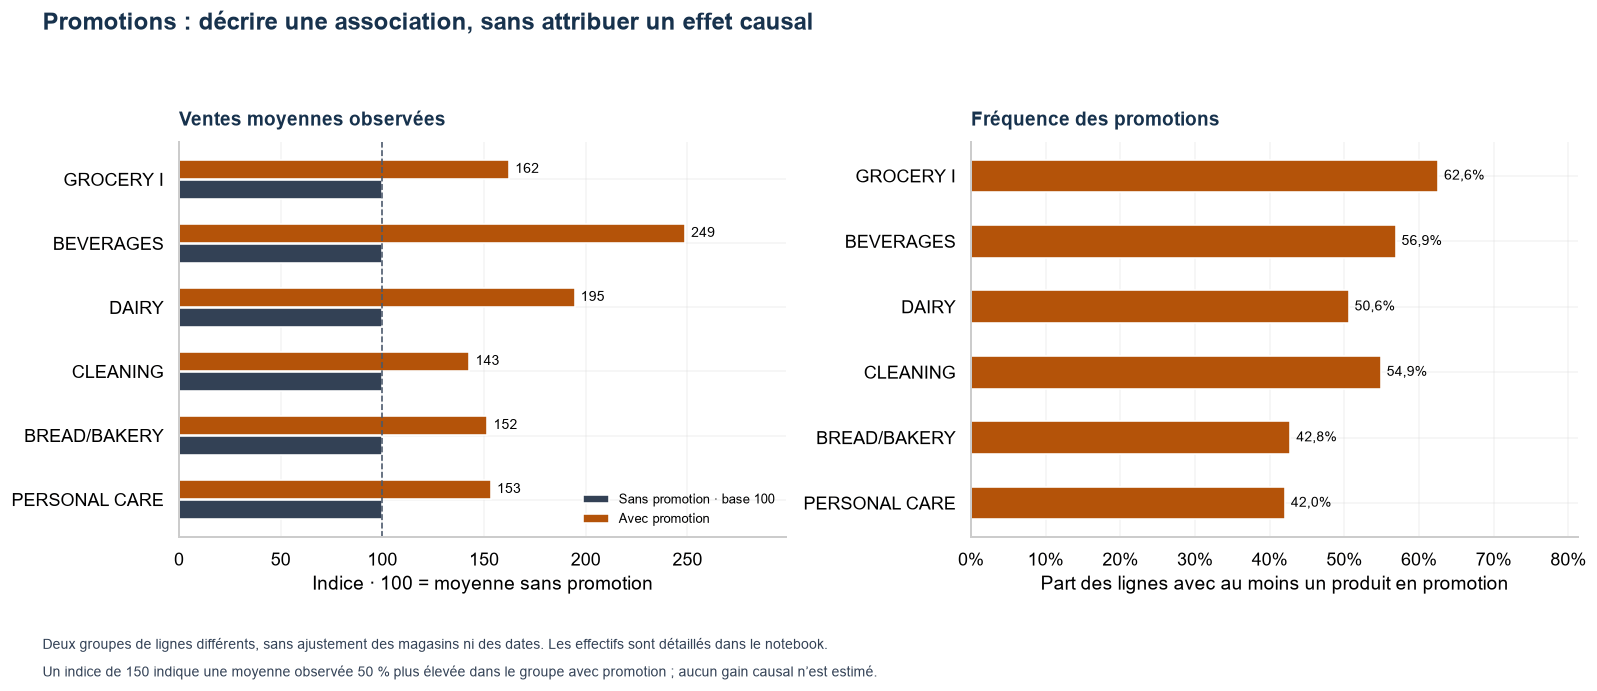

In [23]:
familles_promo_synthese = ["GROCERY I", "BEVERAGES", "DAIRY", "CLEANING", "BREAD/BAKERY", "PERSONAL CARE"]
promo_resume = ventes.assign(en_promotion=ventes["onpromotion"].gt(0)).groupby(["family", "en_promotion"], observed=True)["sales"].agg(moyenne="mean", observations="size")
promo_moyennes = promo_resume["moyenne"].unstack("en_promotion").reindex(familles_promo_synthese)
promo_effectifs = promo_resume["observations"].unstack("en_promotion").reindex(familles_promo_synthese)
promo_indice = 100 * promo_moyennes[True] / promo_moyennes[False].replace(0, np.nan)
promo_frequence = promo_effectifs[True] / promo_effectifs.sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=115)
positions = np.arange(len(familles_promo_synthese))
axes[0].barh(positions + .16, np.full(len(positions), 100), height=.3, color=COULEURS["baseline"], label="Sans promotion · base 100")
axes[0].barh(positions - .16, promo_indice, height=.3, color=COULEURS["promotion"], label="Avec promotion")
axes[0].set_yticks(positions, familles_promo_synthese)
axes[0].invert_yaxis()
axes[0].axvline(100, color="#475569", lw=1, linestyle="--")
axes[0].set_xlim(0, promo_indice.max() * 1.2)
for pos, value in zip(positions, promo_indice):
    axes[0].text(value + 3, pos - .16, f"{value:.0f}", va="center", fontsize=9)
titre_visuel(axes[0], "Ventes moyennes observées", "Indice · 100 = moyenne sans promotion")
axes[0].legend(loc="lower right", fontsize=8)
axes[1].barh(positions, promo_frequence, color=COULEURS["promotion"], height=.5)
axes[1].set_yticks(positions, familles_promo_synthese)
axes[1].invert_yaxis()
axes[1].set_xlim(0, min(1, promo_frequence.max() * 1.3))
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
for pos, value in zip(positions, promo_frequence):
    axes[1].text(value + .008, pos, f"{value:.1%}".replace(".", ","), va="center", fontsize=9)
titre_visuel(axes[1], "Fréquence des promotions", "Part des lignes avec au moins un produit en promotion")
fig.suptitle("Promotions : décrire une association, sans attribuer un effet causal", color=COULEUR_TITRES, fontweight="bold", fontsize=15, x=.03, ha="left", y=.99)
fig.tight_layout(rect=(0, .12, 1, .93))
fig.text(.03, .065, "Deux groupes de lignes différents, sans ajustement des magasins ni des dates. Les effectifs sont détaillés dans le notebook.", fontsize=9, color="#334155")
fig.text(.03, .025, "Un indice de 150 indique une moyenne observée 50 % plus élevée dans le groupe avec promotion ; aucun gain causal n’est estimé.", fontsize=9, color="#334155")
plt.show()
plt.close(fig)
lecture("L’indice permet de comparer les associations entre familles malgré des niveaux de ventes différents. Il ne mesure pas l’effet d’une promotion : les magasins, les dates et la sélection des promotions peuvent aussi expliquer les écarts.")


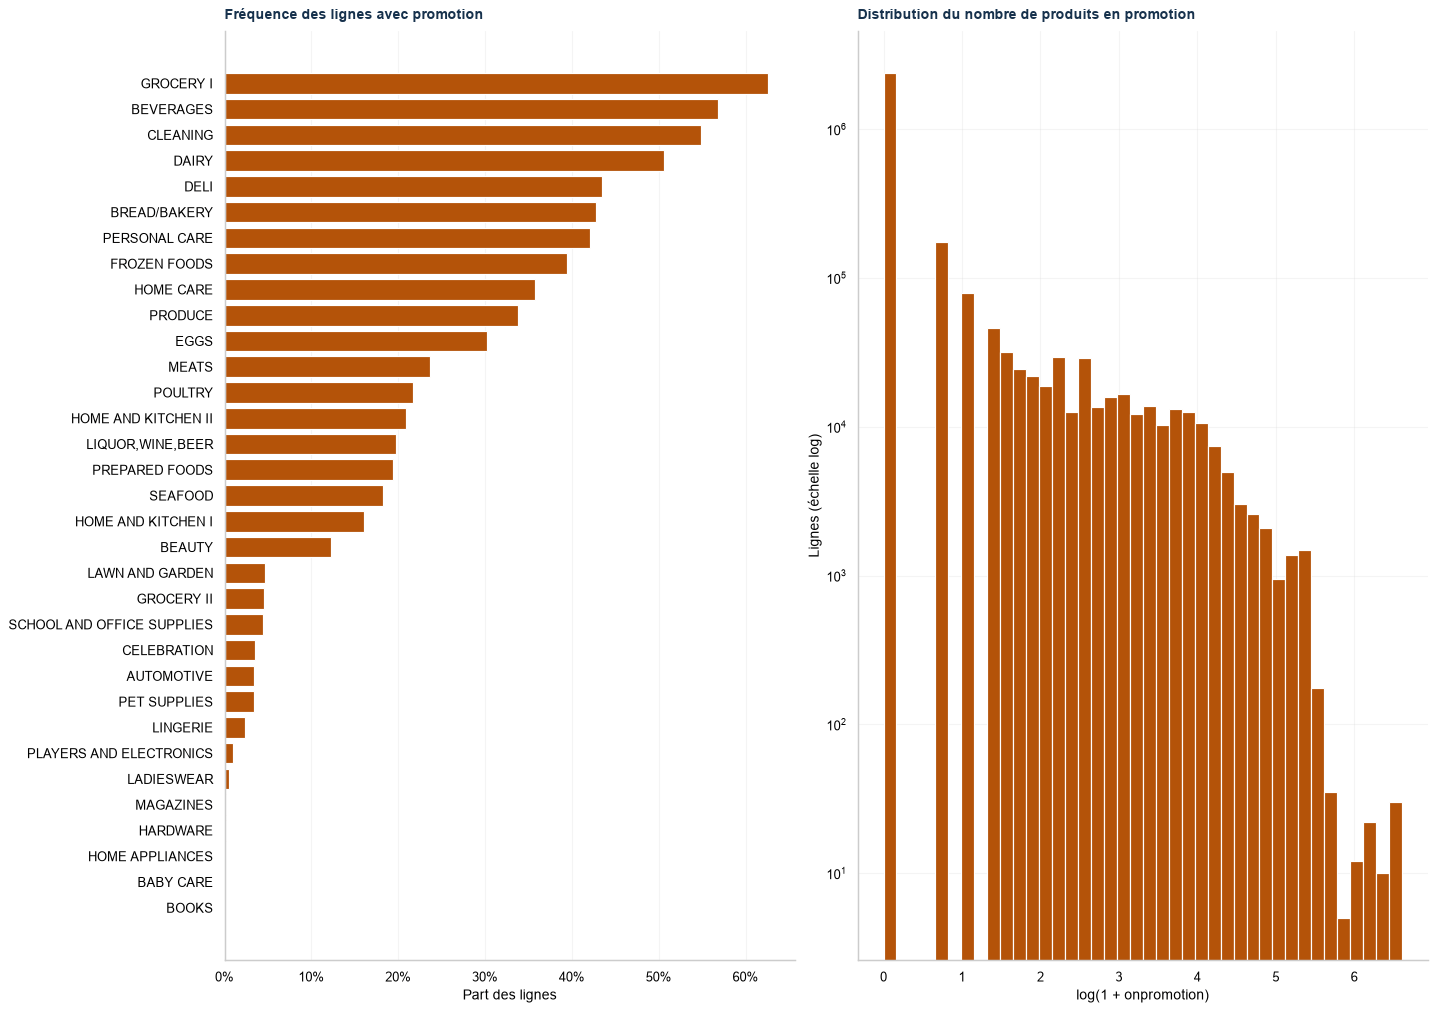

,part_lignes_promo,moyenne_onpromotion,maximum_onpromotion
family,,,
GROCERY I,"62,6%","21,057",741
BEVERAGES,"56,9%","9,974",342
CLEANING,"54,9%","7,271",285
DAIRY,"50,6%","8,013",167
DELI,"43,4%","6,415",81
BREAD/BAKERY,"42,8%","3,643",104
PERSONAL CARE,"42,0%","2,715",99
FROZEN FOODS,"39,4%","1,382",33
HOME CARE,"35,8%","2,169",71


In [24]:
v_resume_promotions = ventes.assign(en_promotion=ventes["onpromotion"].gt(0)).groupby("family", observed=True).agg(
    part_lignes_promo=("en_promotion", "mean"),
    moyenne_onpromotion=("onpromotion", "mean"), maximum_onpromotion=("onpromotion", "max"),
)
fig, axes = plt.subplots(1, 2, figsize=(17, 12))
barres_visuelles(axes[0], v_resume_promotions["part_lignes_promo"], "Fréquence des lignes avec promotion", "Part des lignes", COULEURS_VISUELLES["promotion"])
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
valeurs_promotions = ventes["onpromotion"].to_numpy(dtype=float)
axes[1].hist(np.log1p(valeurs_promotions), bins=40, color=COULEURS_VISUELLES["promotion"])
axes[1].set_yscale("log")
titre_visuel(axes[1], "Distribution du nombre de produits en promotion", "log(1 + onpromotion)", "Lignes (échelle log)")
fig.tight_layout()
plt.show()
plt.close(fig)
afficher_tableau_visuel(v_resume_promotions.sort_values("part_lignes_promo", ascending=False).round(3))
lecture_visuelle(
    f"Au total, {ventes['onpromotion'].gt(0).mean():.1%} des lignes ont au moins un produit en promotion. "
    "Les différences par famille montrent qu’une moyenne globale peut masquer des populations très différentes."
)


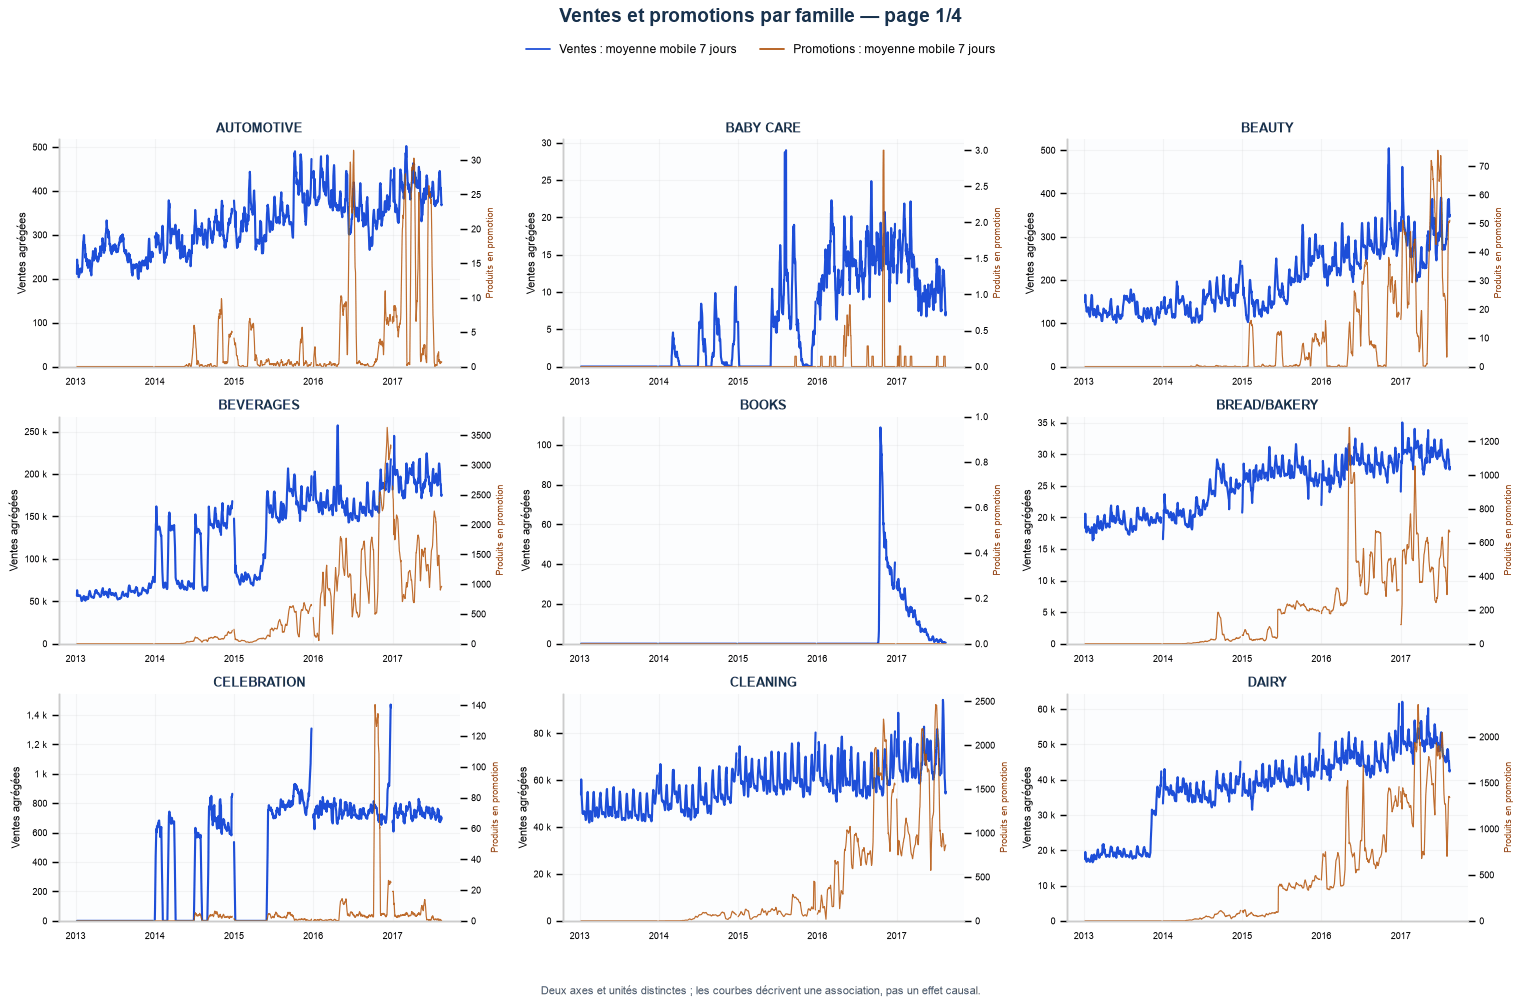

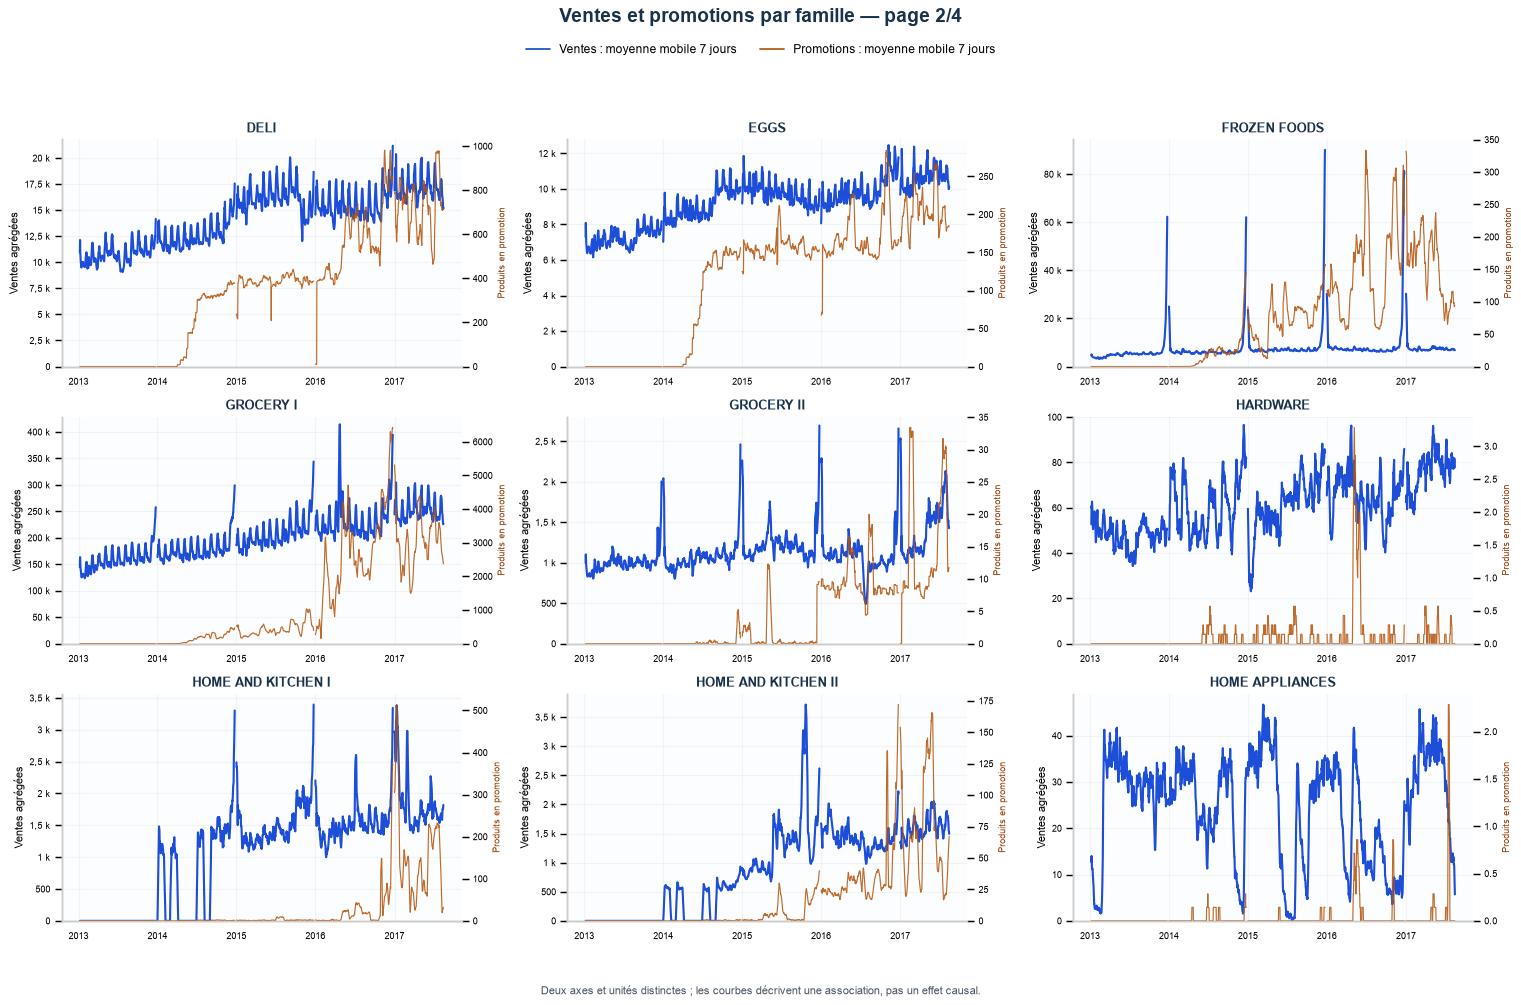

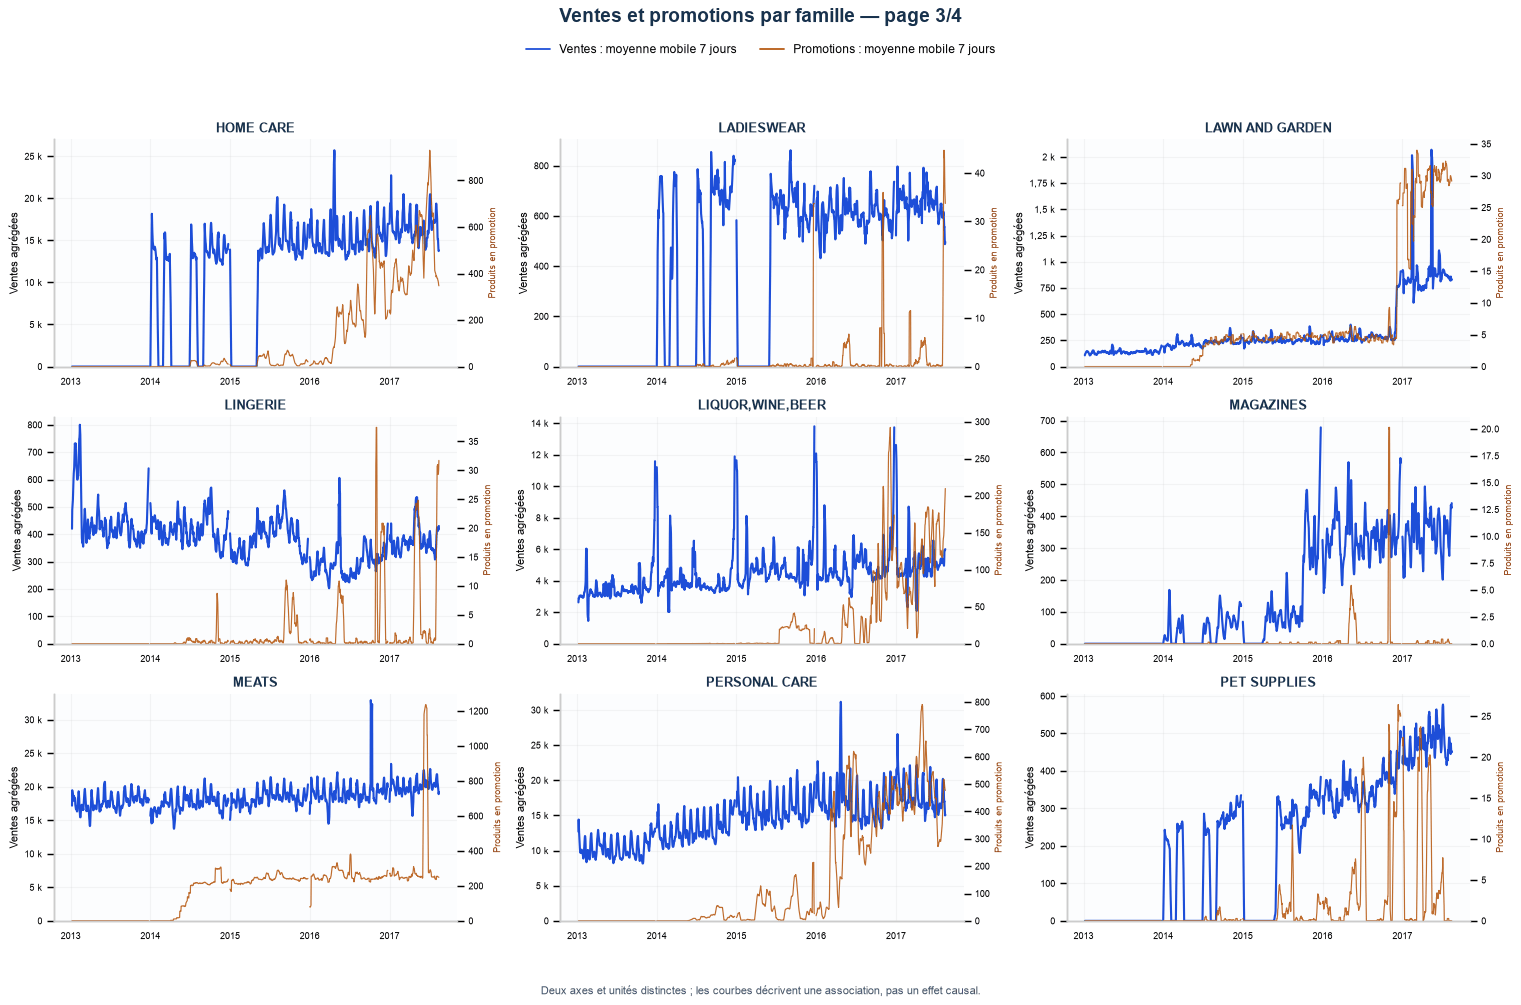

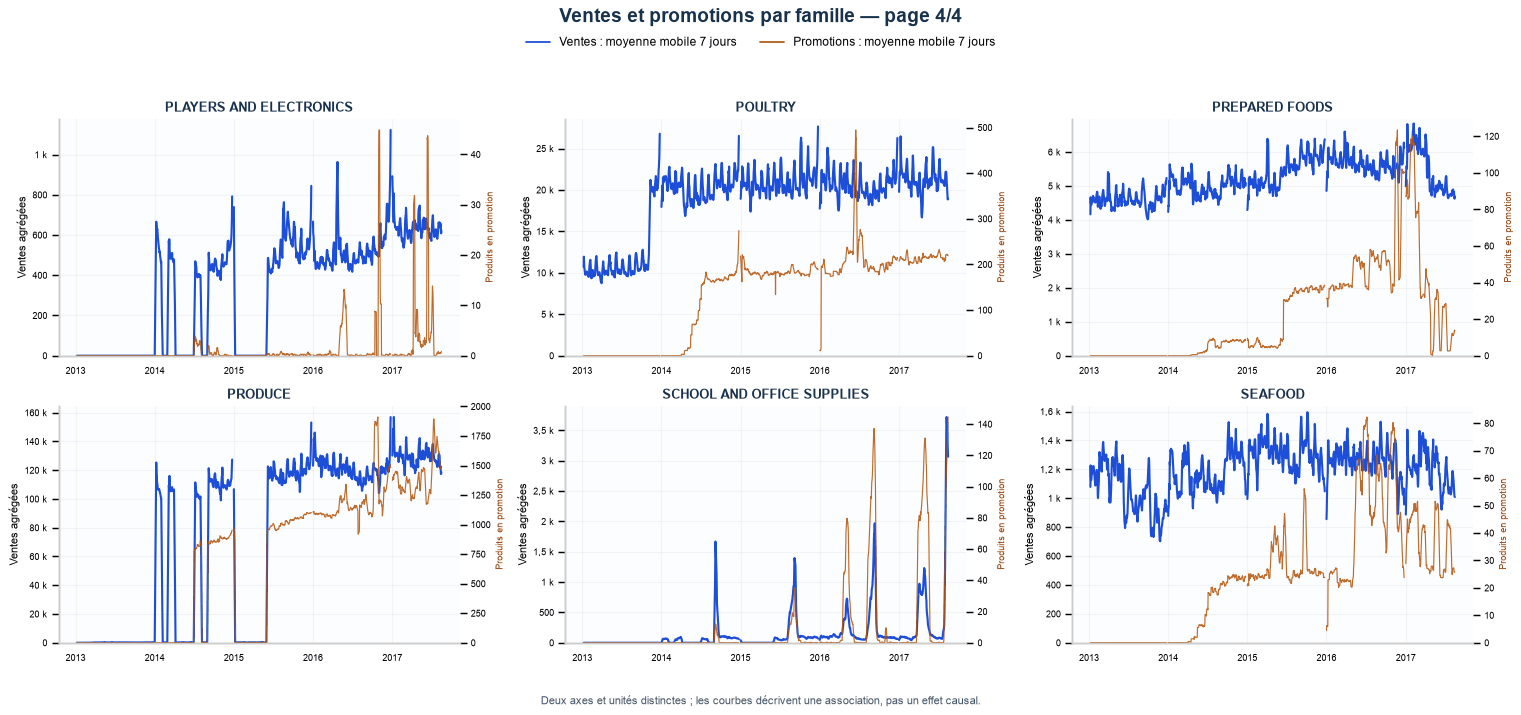

In [25]:
def dessiner_promotion_famille(ax, famille):
    ax.plot(v_tendances_familles.index, v_tendances_familles[famille],
            color=COULEURS_VISUELLES["ventes"], linewidth=1.8)
    ax_promo = ax.twinx()
    ax_promo.plot(v_promotions_familles.index, v_promotions_familles[famille].rolling(7, min_periods=7).mean(),
                  color=COULEURS_VISUELLES["promotion"], linewidth=1, alpha=0.85)
    ax_promo.set_ylabel("Produits en promotion", fontsize=8, color="#92400E")
    ax_promo.tick_params(axis="y", labelsize=8)
    ax_promo.grid(visible=False)
    maximum_promo = v_promotions_familles[famille].rolling(7, min_periods=7).mean().max()
    ax_promo.set_ylim(0, max(1, maximum_promo * 1.05))
    ax.set_title(famille, color=BLEU_VISUEL, fontweight="bold", fontsize=11)

grilles_visuelles(
    familles_visuelles, "Ventes et promotions par famille", dessiner_promotion_famille, "Ventes agrégées",
    [
        Line2D([0], [0], color=COULEURS_VISUELLES["ventes"], label="Ventes : moyenne mobile 7 jours"),
        Line2D([0], [0], color=COULEURS_VISUELLES["promotion"], label="Promotions : moyenne mobile 7 jours"),
    ],
    "Deux axes et unités distinctes ; les courbes décrivent une association, pas un effet causal."
)
lecture_visuelle(
    "Les grilles permettent de repérer une variation simultanée ou un changement de disponibilité des promotions. "
    "Le ciblage des promotions, le magasin et la période peuvent expliquer les différences observées."
)


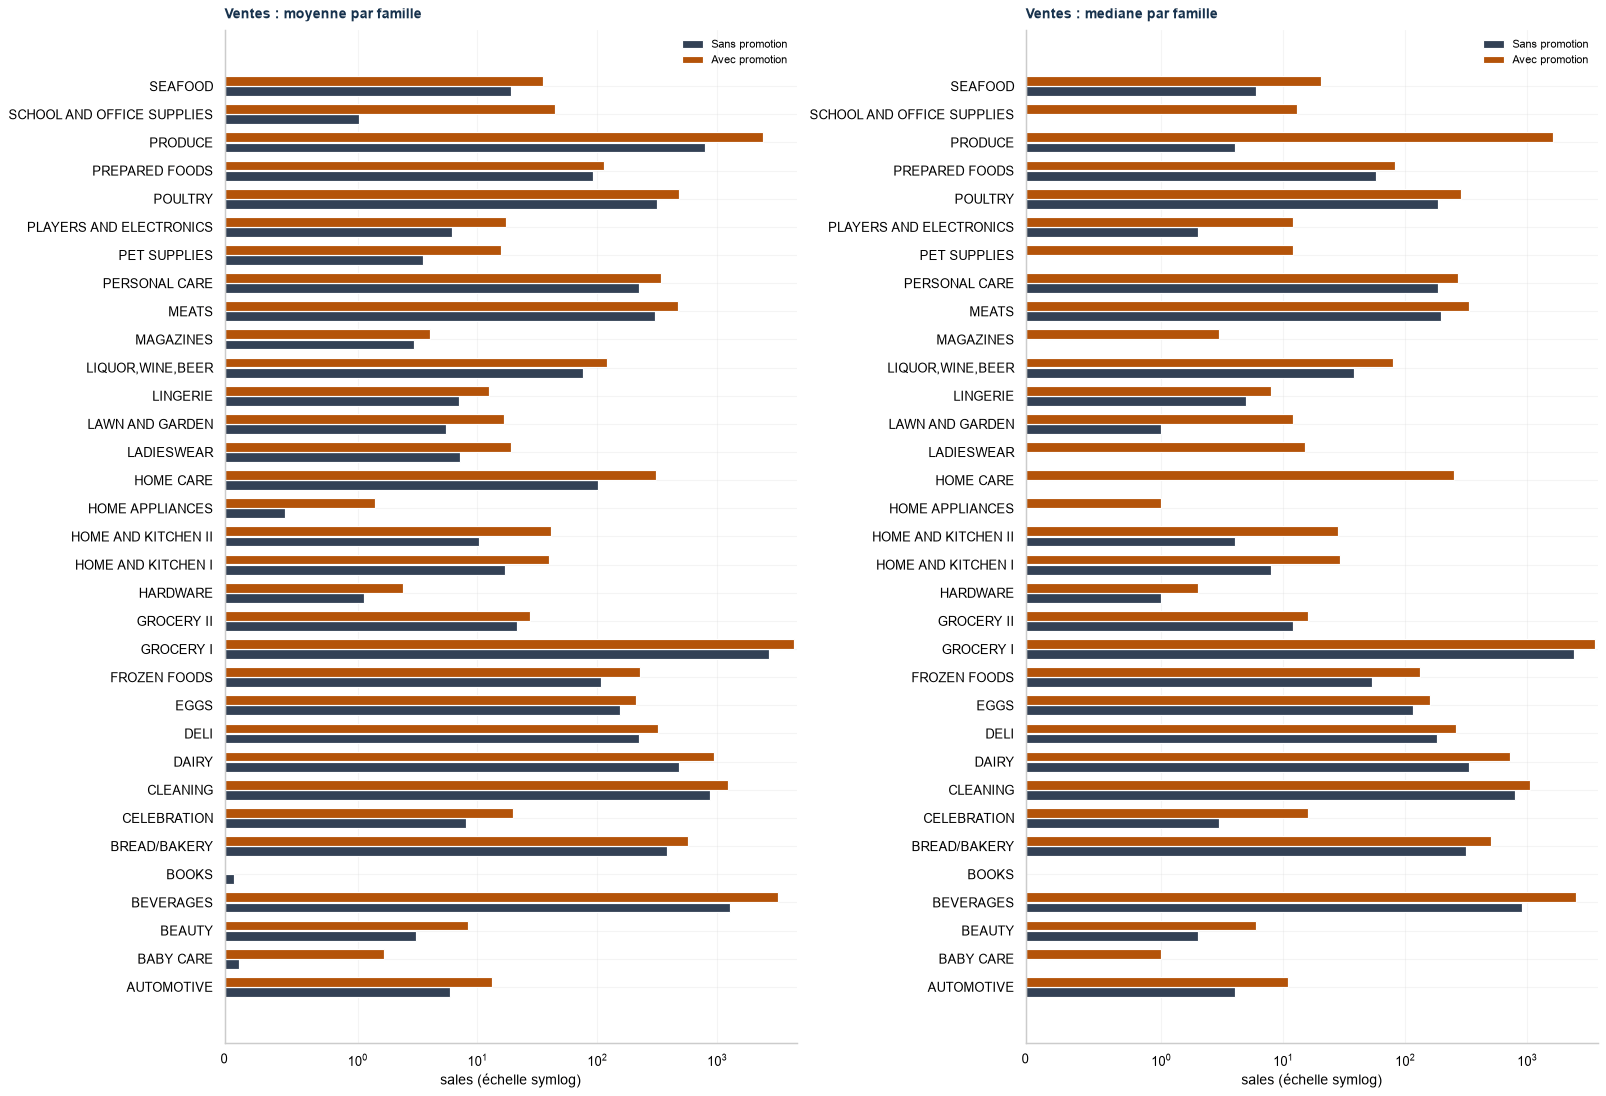

family,en_promotion,moyenne,mediane,observations
AUTOMOTIVE,Non,"5,853","4,000",87 882
AUTOMOTIVE,Oui,"13,242","11,000",3 054
BABY CARE,Non,"0,110","0,000",90 883
BABY CARE,Oui,"1,660","1,000",53
BEAUTY,Non,"3,078","2,000",79 819
BEAUTY,Oui,"8,291","6,000",11 117
BEVERAGES,Non,"1 292,273","910,000",39 231
BEVERAGES,Oui,"3 215,498","2 505,000",51 705
BOOKS,Non,"0,071","0,000",90 936
BREAD/BAKERY,Non,"379,513","312,886",52 040


In [26]:
v_comparaison_promo = ventes.assign(en_promotion=ventes["onpromotion"].gt(0)).groupby(
    ["family", "en_promotion"], observed=True
)["sales"].agg(moyenne="mean", mediane="median", observations="size").reset_index()
fig, axes = plt.subplots(1, 2, figsize=(19, 13))
for ax, metrique in zip(axes, ("moyenne", "mediane")):
    matrice = v_comparaison_promo.pivot(index="family", columns="en_promotion", values=metrique).reindex(familles_visuelles)
    positions = np.arange(len(matrice))
    ax.barh(positions - 0.18, matrice.get(False), height=0.35, color=COULEURS_VISUELLES["neutre"], label="Sans promotion")
    ax.barh(positions + 0.18, matrice.get(True), height=0.35, color=COULEURS_VISUELLES["promotion"], label="Avec promotion")
    ax.set_yticks(positions, matrice.index.astype(str))
    ax.set_xscale("symlog", linthresh=1)
    titre_visuel(ax, f"Ventes : {metrique} par famille", "sales (échelle symlog)")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
plt.close(fig)
afficher_tableau_visuel(v_comparaison_promo.round(3))
lecture_visuelle(
    "La comparaison conserve les familles sans observations dans l’un des groupes comme valeurs manquantes. "
    "Elle distingue moyenne et médiane pour montrer l’influence des grosses ventes. "
    "Elle ne contrôle pas les magasins, les saisons ou la sélection des promotions ; aucun gain causal n’est estimé."
)


<h3 style="color:#2563EB; font-weight:700;">12.2. Transactions : couverture et activité</h3>

**Question :** Les ventes et les transactions sont-elles comparées sur les mêmes dates–magasins ?

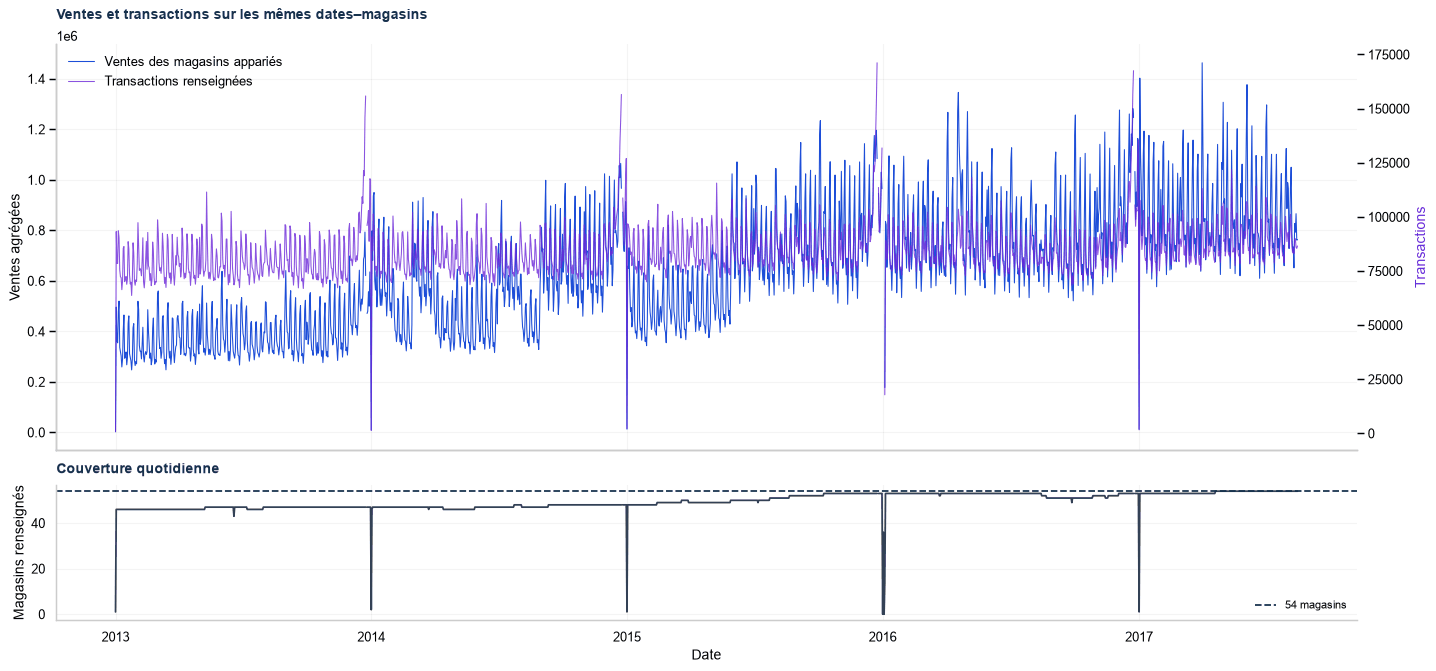

,transactions
count,"83 488,000"
mean,"1 694,602"
std,"963,287"
min,"5,000"
25%,"1 046,000"
50%,"1 393,000"
75%,"2 079,000"
max,"8 359,000"


In [27]:
v_transactions_periode = v_transactions.loc[v_transactions["date"].between(calendrier_visuel.min(), calendrier_visuel.max())]
v_paires_transactions = v_magasin_jour.merge(
    v_transactions_periode, on=["date", "store_nbr"], how="left", validate="one_to_one"
)
assert len(v_paires_transactions) == len(v_magasin_jour)
v_couverture_transactions = v_paires_transactions.groupby("date")["transactions"].count().reindex(calendrier_visuel)
v_paires_renseignees = v_paires_transactions.dropna(subset=["transactions"])
v_transactions_jour = v_paires_renseignees.groupby("date")[["ventes", "transactions"]].sum().reindex(calendrier_visuel)
fig, axes = plt.subplots(2, 1, figsize=(17, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
axes[0].plot(v_transactions_jour.index, v_transactions_jour["ventes"], color=COULEURS_VISUELLES["ventes"], linewidth=.9, label="Ventes des magasins appariés")
ax_trans = axes[0].twinx()
ax_trans.plot(v_transactions_jour.index, v_transactions_jour["transactions"], color=COULEURS_VISUELLES["transactions"], linewidth=.9, alpha=.8, label="Transactions renseignées")
titre_visuel(axes[0], "Ventes et transactions sur les mêmes dates–magasins", ylabel="Ventes agrégées")
ax_trans.set_ylabel("Transactions", color=COULEURS_VISUELLES["transactions"])
ax_trans.grid(visible=False)
h1, l1 = axes[0].get_legend_handles_labels()
h2, l2 = ax_trans.get_legend_handles_labels()
axes[0].legend(h1 + h2, l1 + l2, loc="upper left")
axes[1].plot(v_couverture_transactions.index, v_couverture_transactions, color=COULEURS_VISUELLES["neutre"])
axes[1].axhline(len(magasins_visuels), linestyle="--", color=BLEU_VISUEL, label="54 magasins")
titre_visuel(axes[1], "Couverture quotidienne", "Date", "Magasins renseignés")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()
plt.close(fig)
afficher_tableau_visuel(v_transactions["transactions"].describe().rename("transactions").to_frame())
lecture_visuelle(
    f"Les transactions sont renseignées sur {v_paires_transactions['transactions'].notna().mean():.1%} "
    "des dates–magasins observées dans les ventes. Une ligne absente n’est pas remplacée par zéro. "
    "La comparaison supérieure conserve seulement les mêmes magasins appariés ; une couverture variable peut encore modifier l’agrégat."
)


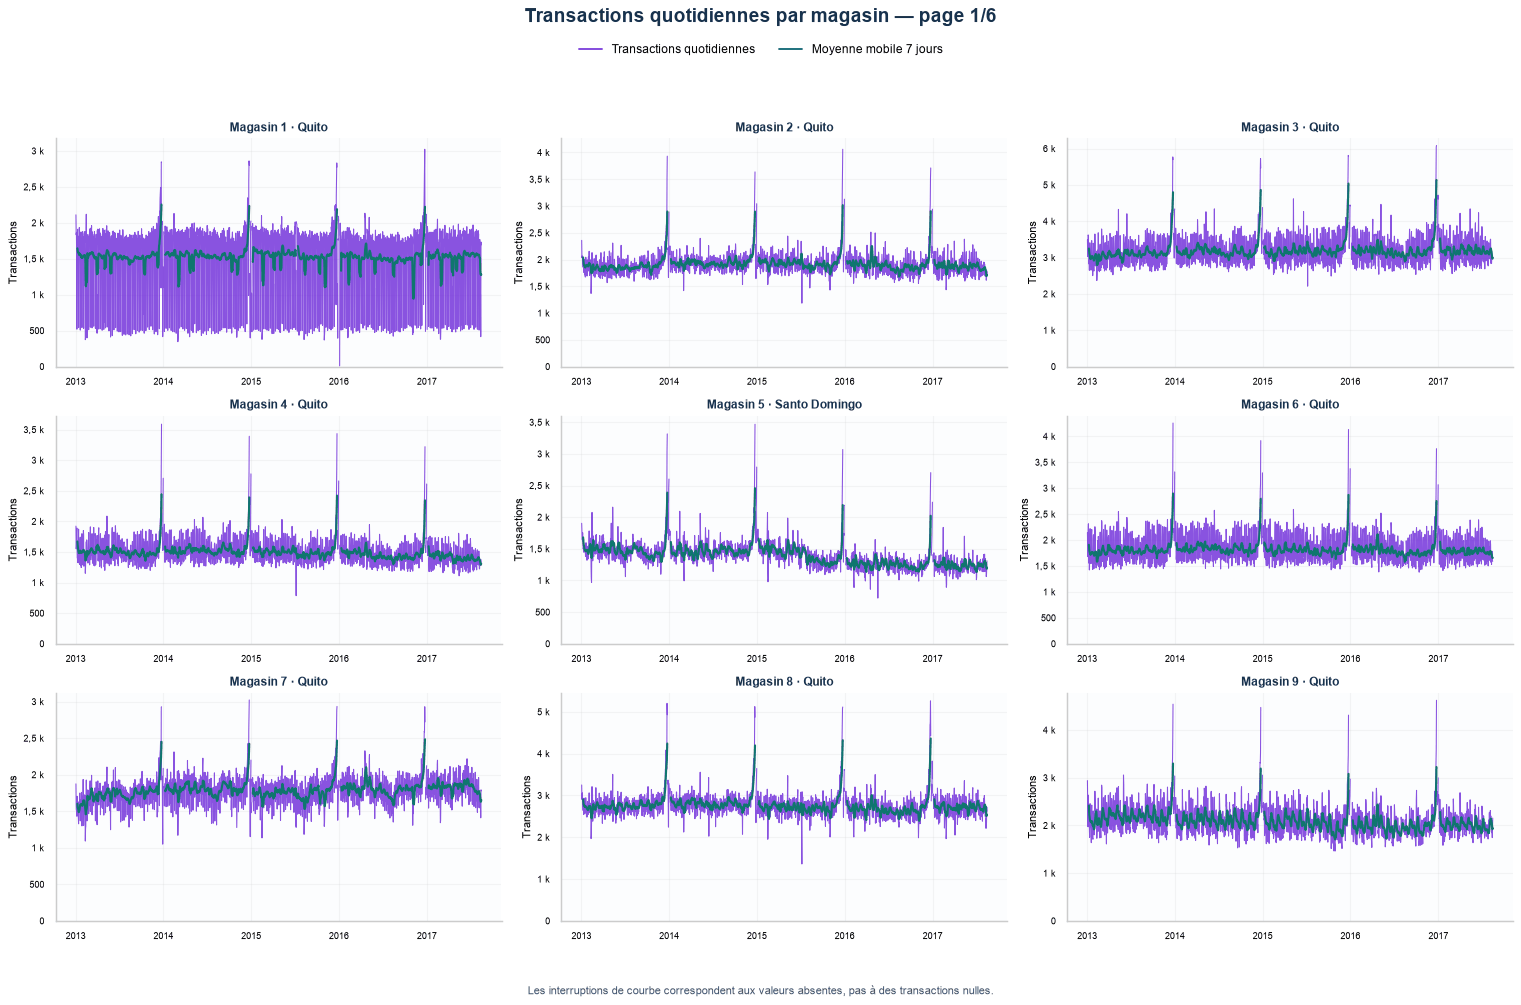

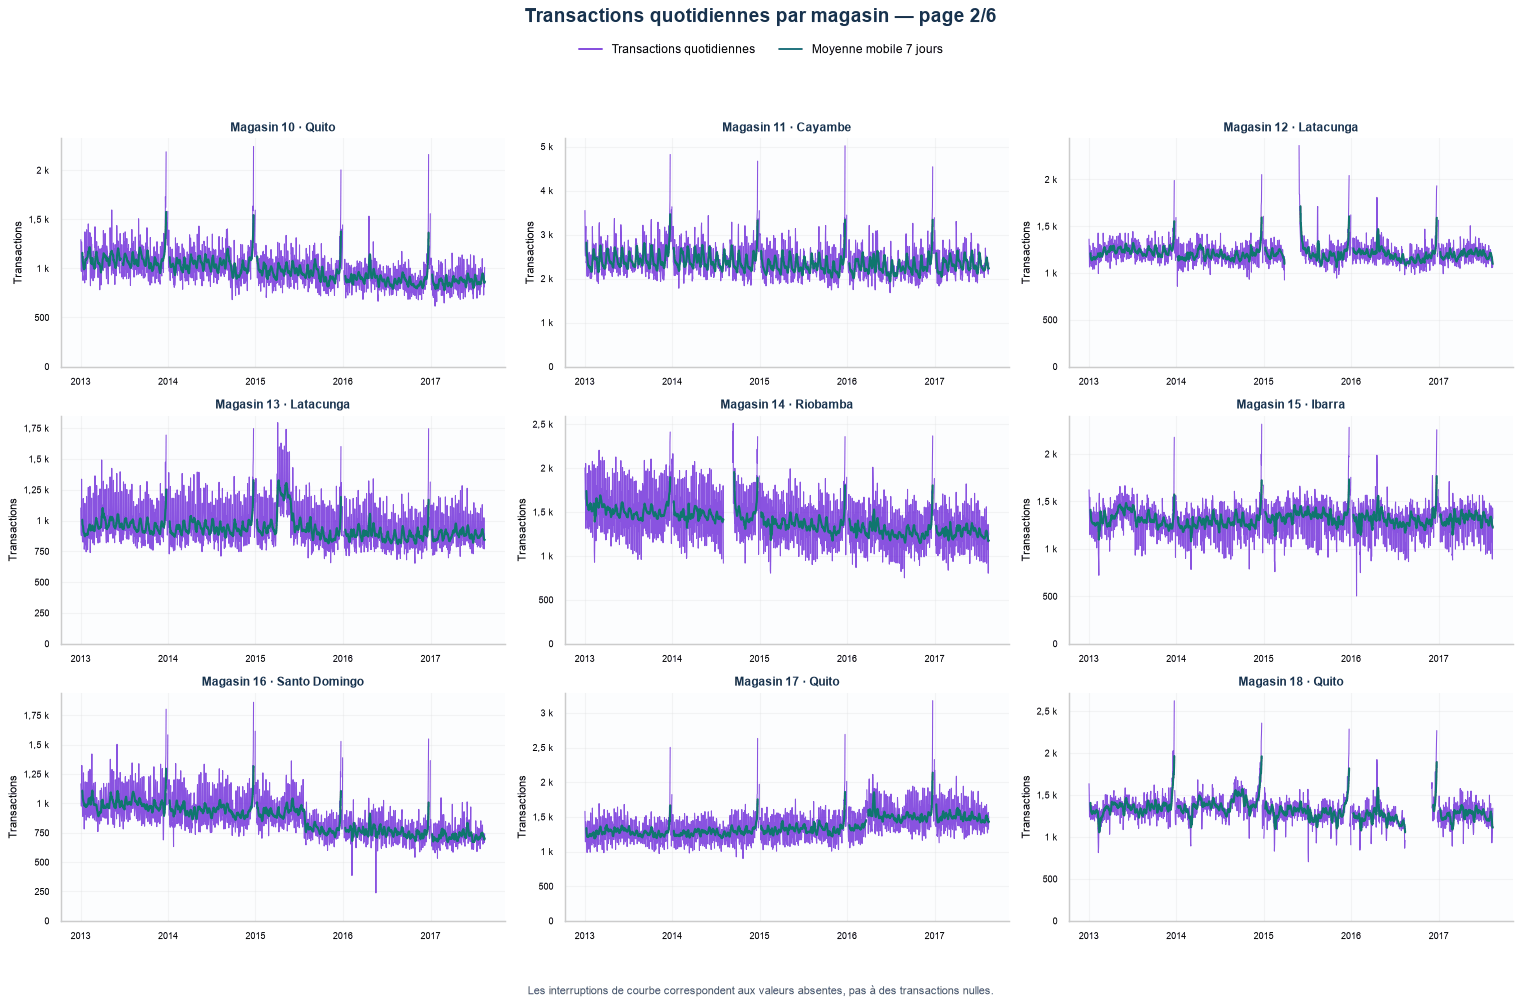

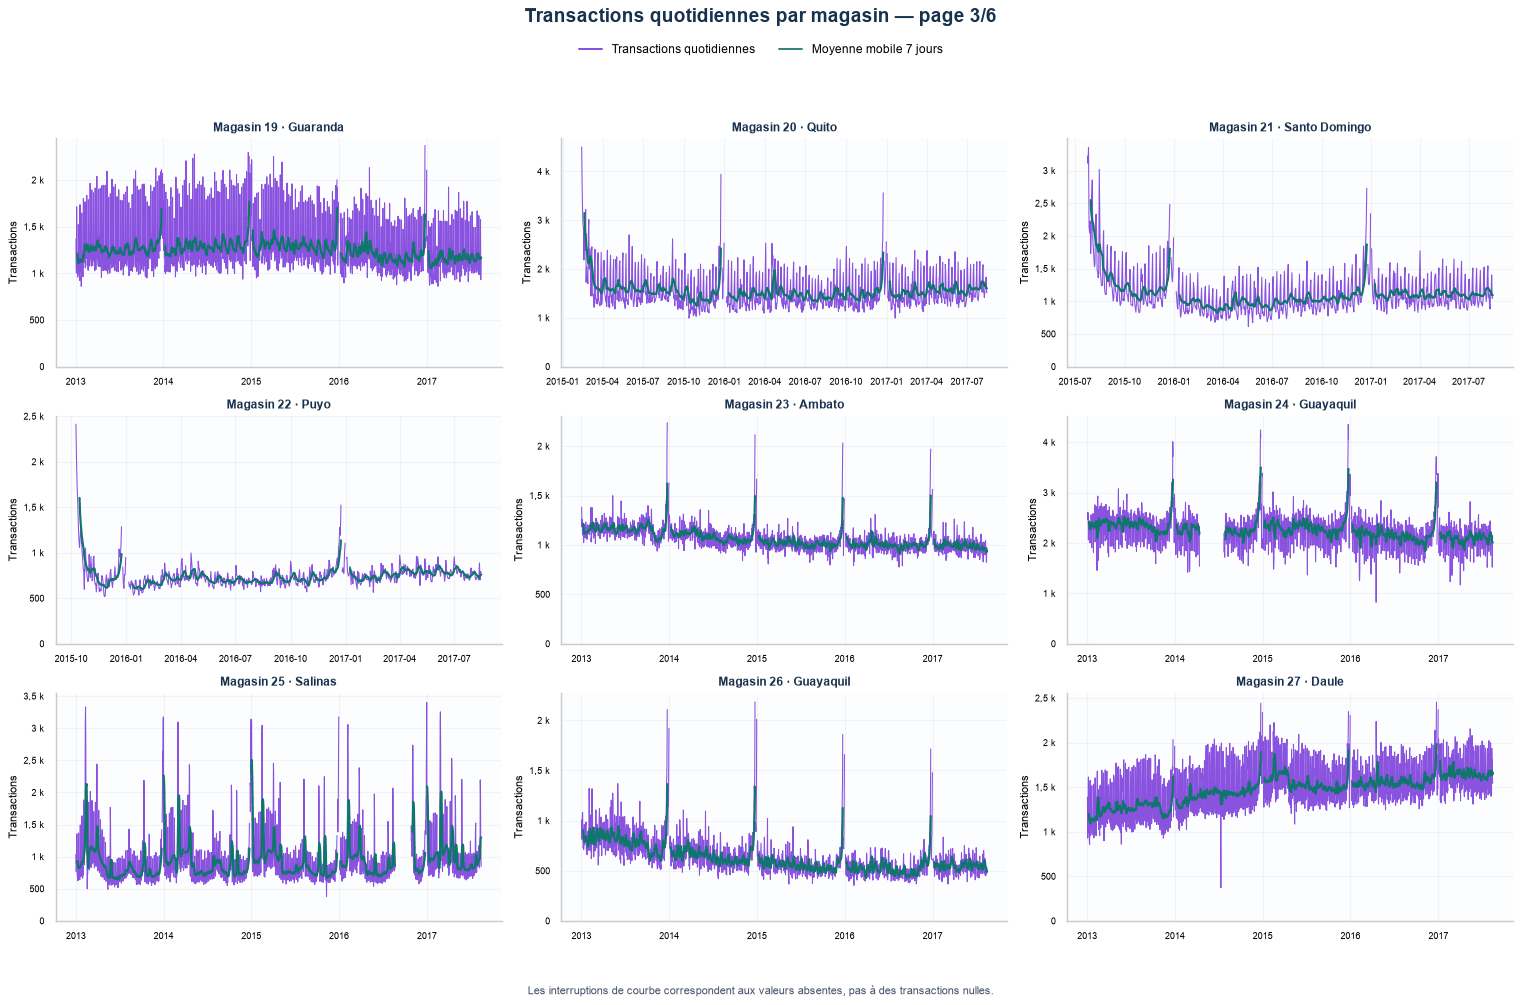

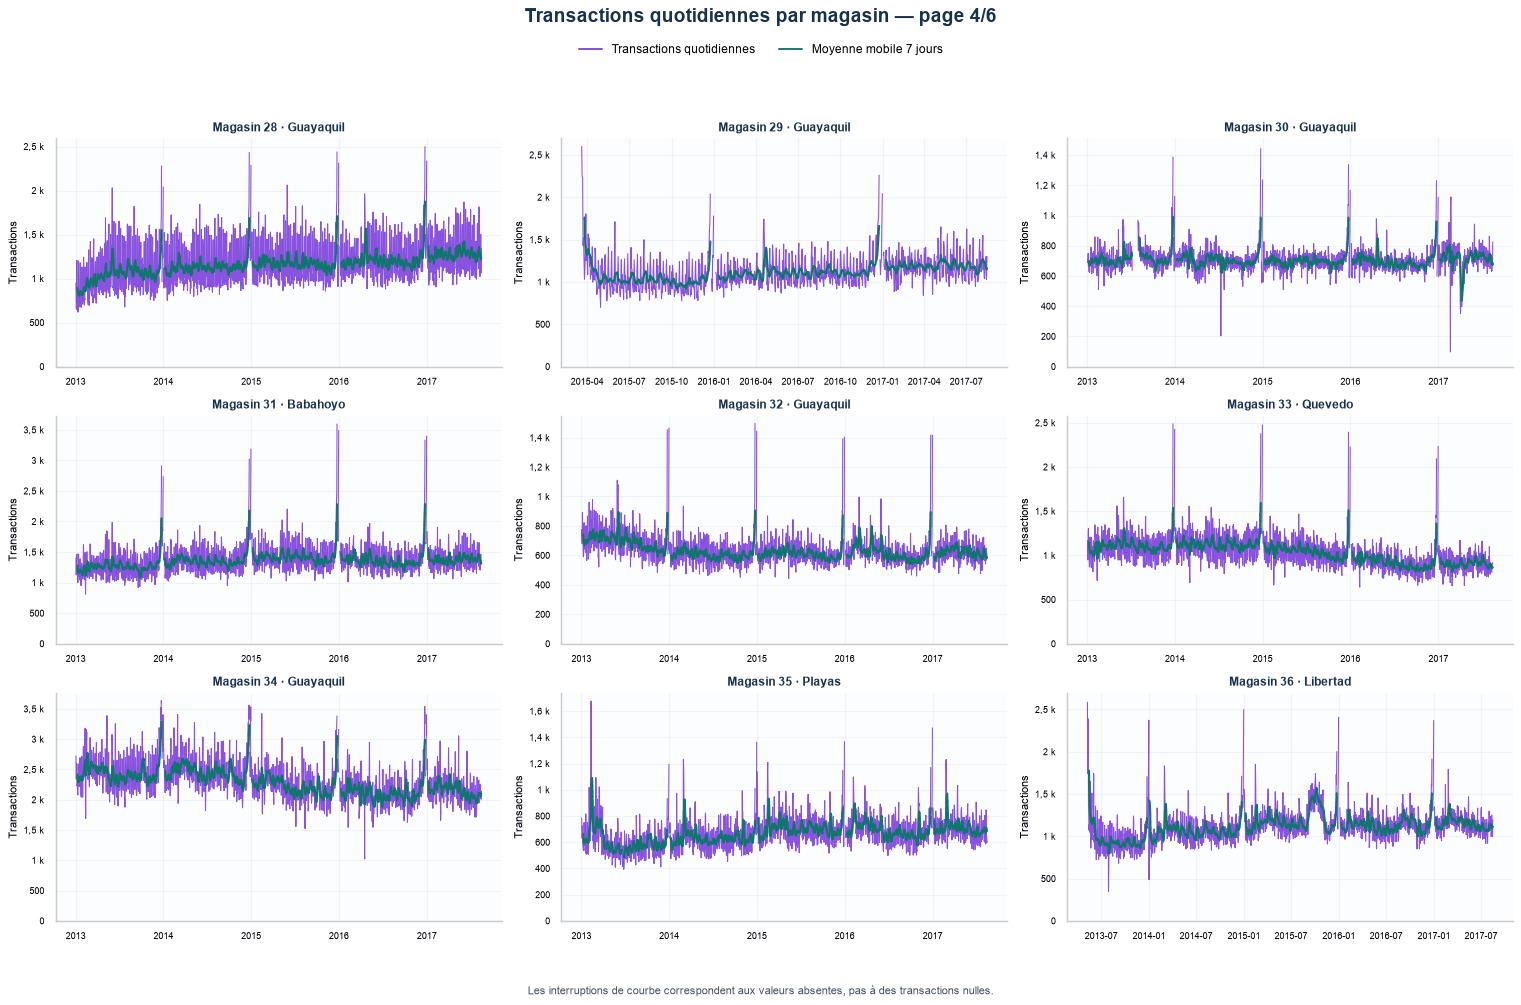

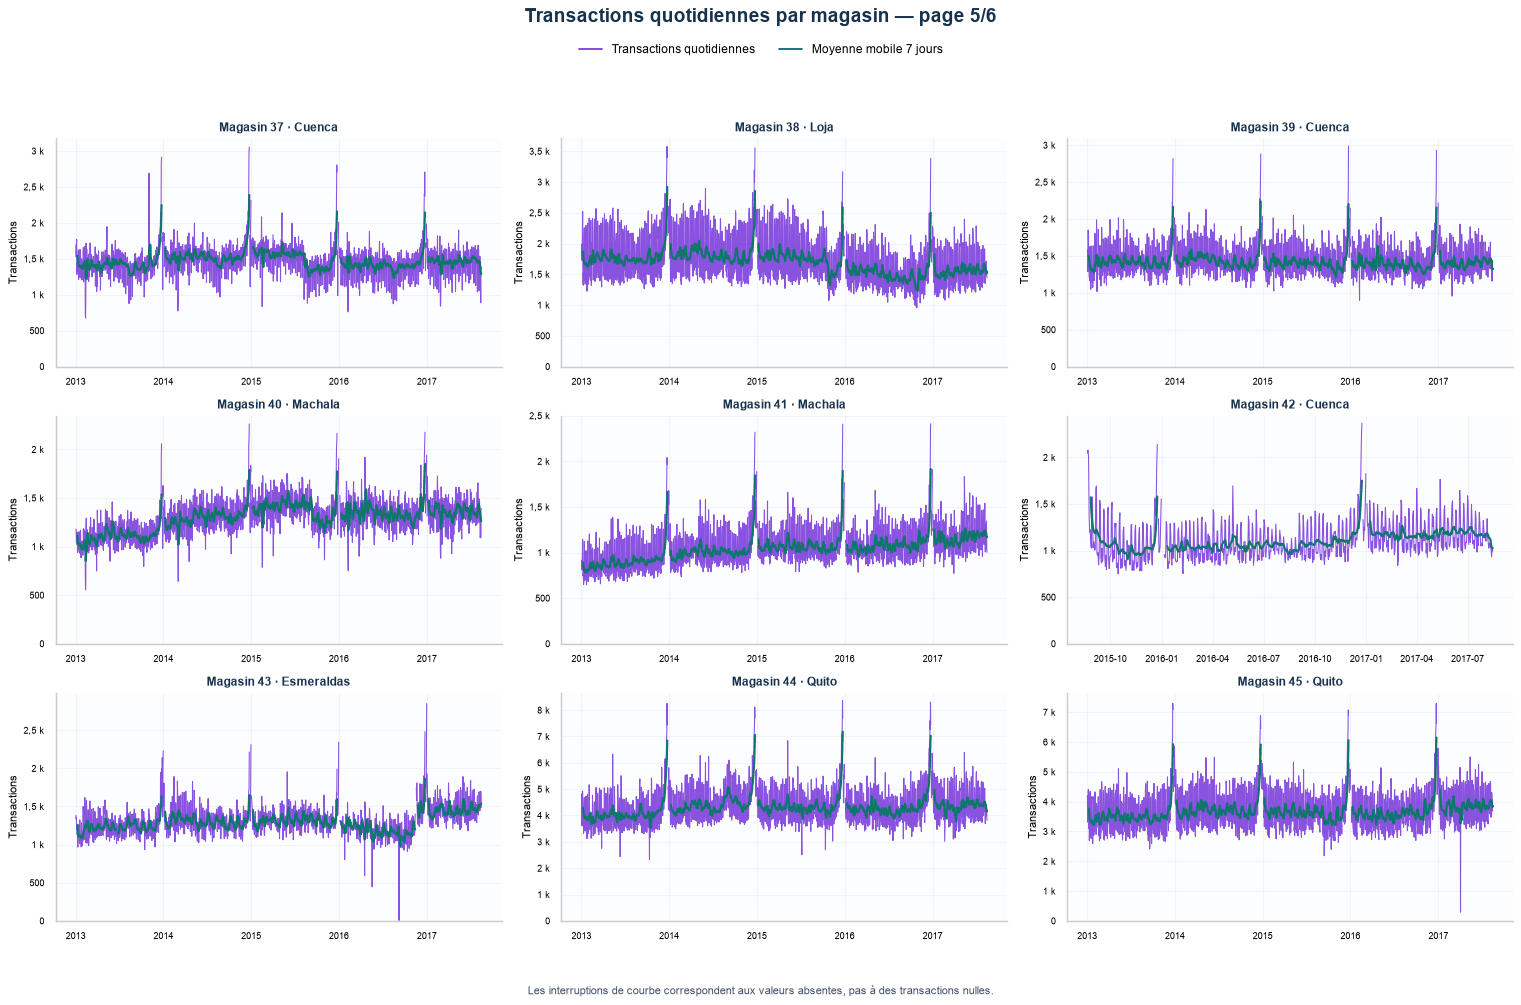

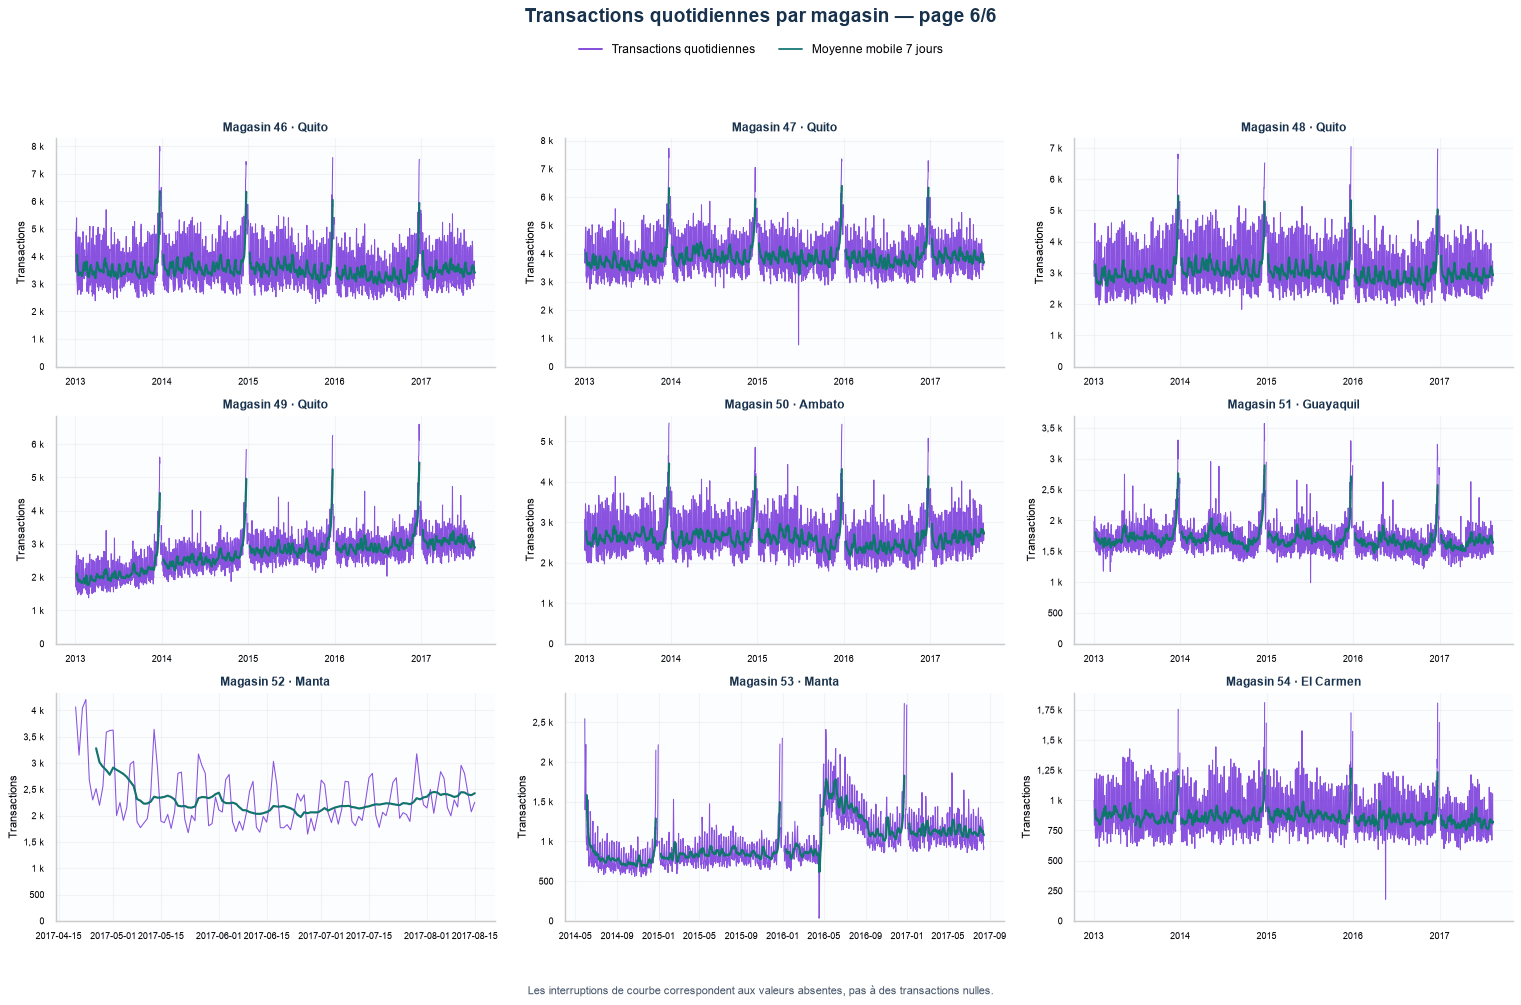

In [28]:
v_transactions_magasins = v_transactions_periode.pivot(
    index="date", columns="store_nbr", values="transactions"
).reindex(index=calendrier_visuel, columns=magasins_visuels)
v_tendances_transactions = v_transactions_magasins.rolling(7, min_periods=7).mean()
def dessiner_transactions_magasin(ax, magasin):
    ax.plot(v_transactions_magasins.index, v_transactions_magasins[magasin],
            color=COULEURS_VISUELLES["transactions"], linewidth=.9, alpha=.8)
    ax.plot(v_tendances_transactions.index, v_tendances_transactions[magasin],
            color=COULEURS_VISUELLES["tendance"], linewidth=1.8)
    ax.set_title(f"Magasin {magasin} · {v_stores_index.loc[magasin, 'city']}", color=BLEU_VISUEL, fontweight="bold", fontsize=10)

grilles_visuelles(
    magasins_visuels, "Transactions quotidiennes par magasin", dessiner_transactions_magasin, "Transactions",
    [
        Line2D([0], [0], color=COULEURS_VISUELLES["transactions"], label="Transactions quotidiennes"),
        Line2D([0], [0], color=COULEURS_VISUELLES["tendance"], label="Moyenne mobile 7 jours"),
    ],
    "Les interruptions de courbe correspondent aux valeurs absentes, pas à des transactions nulles."
)
lecture_visuelle(
    "Les courbes peuvent aider à contextualiser un changement d’activité ou des données non renseignées. "
    "Elles décrivent l’historique disponible et ne fournissent pas des transactions connues à l’avance pour le test."
)


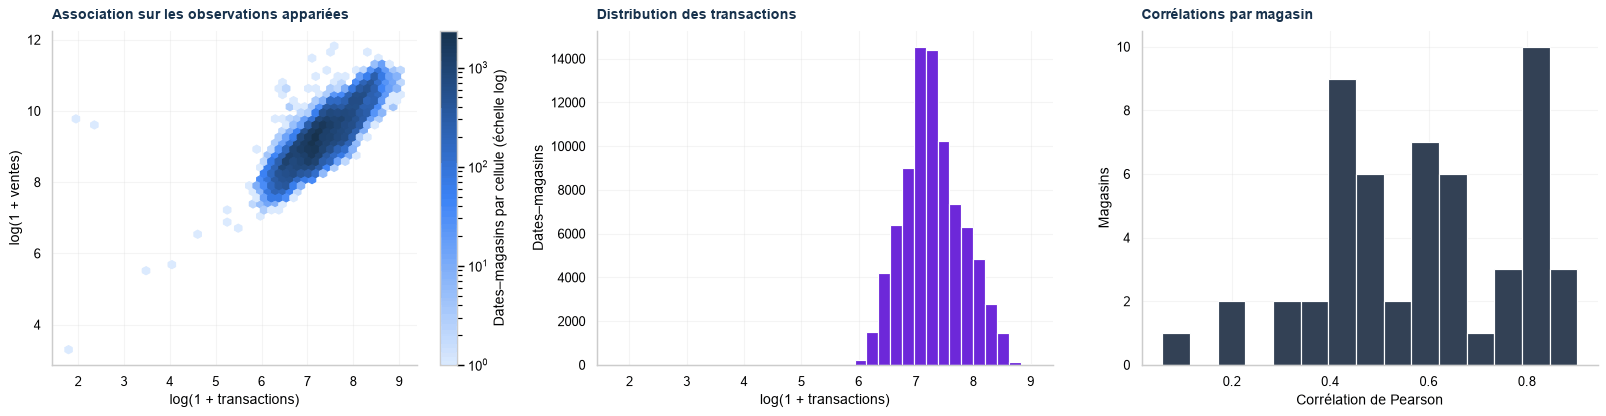

,corrélation descriptive
23,"0,059"
18,"0,222"
24,"0,224"
8,"0,322"
2,"0,333"
5,"0,350"
32,"0,374"
7,"0,398"
33,"0,404"
10,"0,406"


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
hexagones = axes[0].hexbin(
    np.log1p(v_paires_renseignees["transactions"]), np.log1p(v_paires_renseignees["ventes"]),
    gridsize=45, mincnt=1, bins="log", cmap=CMAP_SEQUENTIELLE,
)
fig.colorbar(hexagones, ax=axes[0], label="Dates–magasins par cellule (échelle log)")
titre_visuel(axes[0], "Association sur les observations appariées", "log(1 + transactions)", "log(1 + ventes)")
axes[1].hist(np.log1p(v_transactions["transactions"]), bins=35, color=COULEURS_VISUELLES["transactions"])
titre_visuel(axes[1], "Distribution des transactions", "log(1 + transactions)", "Dates–magasins")
v_correlations_magasins = pd.Series({
    magasin: frame["ventes"].corr(frame["transactions"])
    for magasin, frame in v_paires_renseignees.groupby("store_nbr")
}, name="corrélation descriptive")
axes[2].hist(v_correlations_magasins.dropna(), bins=15, color=COULEURS_VISUELLES["neutre"])
titre_visuel(axes[2], "Corrélations par magasin", "Corrélation de Pearson", "Magasins")
fig.tight_layout()
plt.show()
plt.close(fig)
afficher_tableau_visuel(v_correlations_magasins.sort_values().round(3).to_frame())
lecture_visuelle(
    f"La corrélation descriptive médiane entre ventes et transactions par magasin vaut {v_correlations_magasins.median():.3f}. "
    "Le volume d’activité peut faire évoluer les deux variables ensemble. Une corrélation historique ne prouve "
    "ni causalité ni disponibilité des transactions à l’origine d’une prévision."
)


<h3 style="color:#2563EB; font-weight:700;">12.3. Pétrole : valeurs et contexte économique</h3>

**Question :** Quels prix manquent et comment visualiser la série sans les confondre avec des données disponibles pour prévoir ?

,prix du pétrole
count,"1 163,000"
mean,"67,926"
std,"25,677"
min,"26,190"
25%,"46,390"
50%,"53,330"
75%,"95,790"
max,"110,620"


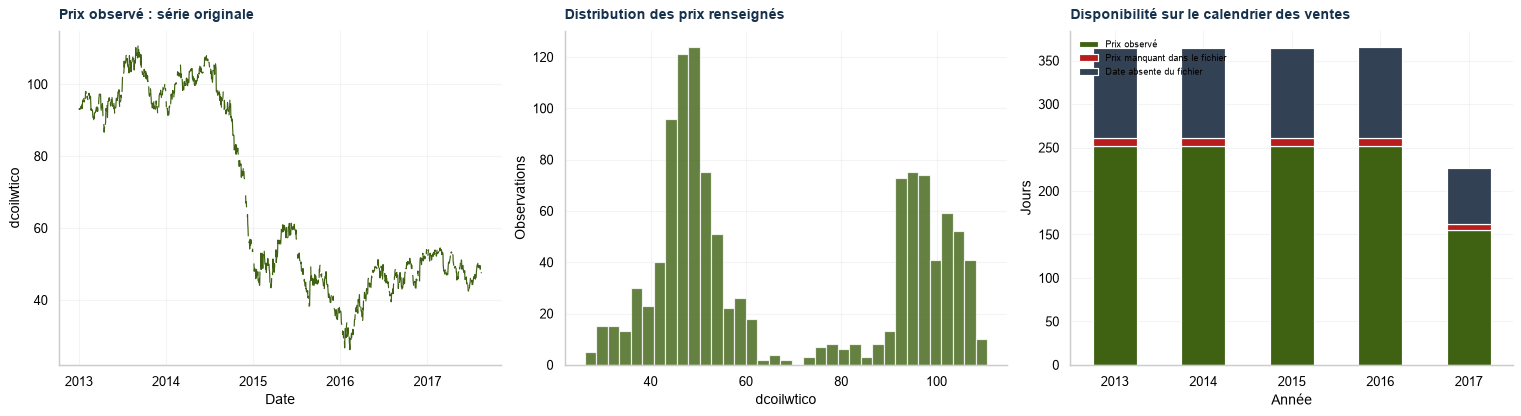

In [30]:
v_petrole_original = petrole.set_index("date")["dcoilwtico"].reindex(calendrier_visuel)
v_petrole_affichage = v_petrole_original.interpolate(method="time", limit_area="inside")
v_dates_fichier_petrole = calendrier_visuel.isin(petrole["date"])
v_statut_petrole = pd.Series(
    np.where(~v_dates_fichier_petrole, "Date absente du fichier",
             np.where(v_petrole_original.isna(), "Prix manquant dans le fichier", "Prix observé")),
    index=calendrier_visuel, name="statut",
)
assert v_petrole_original.loc[v_petrole_original.notna()].equals(
    v_petrole_affichage.loc[v_petrole_original.notna()]
)
afficher_tableau_visuel(petrole["dcoilwtico"].describe().rename("prix du pétrole").to_frame())
v_disponibilite_petrole = pd.crosstab(v_statut_petrole.index.year, v_statut_petrole)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(v_petrole_original.index, v_petrole_original, color=COULEURS_VISUELLES["petrole"], linewidth=1)
titre_visuel(axes[0], "Prix observé : série originale", "Date", "dcoilwtico")
axes[1].hist(petrole["dcoilwtico"].dropna(), bins=35, color=COULEURS_VISUELLES["petrole"], alpha=0.8)
titre_visuel(axes[1], "Distribution des prix renseignés", "dcoilwtico", "Observations")
ordre_statuts = ["Prix observé", "Prix manquant dans le fichier", "Date absente du fichier"]
v_disponibilite_petrole.reindex(columns=ordre_statuts, fill_value=0).plot.bar(
    stacked=True, ax=axes[2], color=["#3F6212", "#B91C1C", "#334155"], rot=0,
)
titre_visuel(axes[2], "Disponibilité sur le calendrier des ventes", "Année", "Jours")
axes[2].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()
plt.close(fig)
lecture_visuelle(
    f"Le fichier pétrole contient {int(petrole['dcoilwtico'].isna().sum())} prix manquants. "
    f"Sur le calendrier des ventes, {int((~v_dates_fichier_petrole).sum())} dates ne figurent pas dans ce fichier. "
    "Les histogrammes utilisent uniquement les prix renseignés. L’année 2017 couvre ici une période partielle."
)


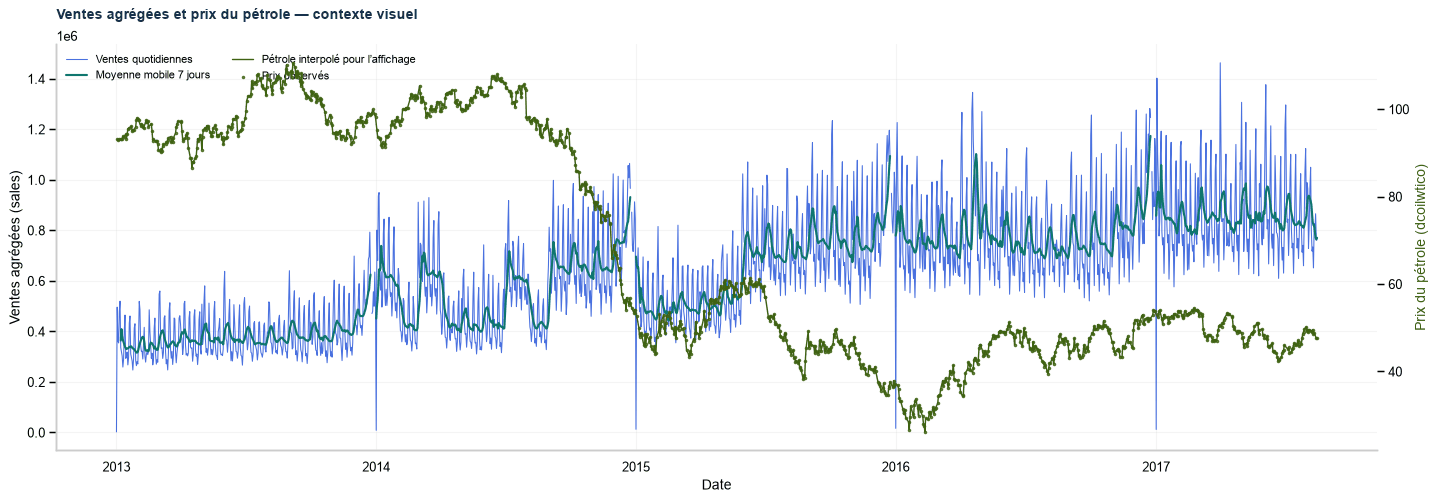

In [31]:
fig, ax = plt.subplots(figsize=(17, 6))
ax.plot(v_total_jour.index, v_total_jour, color=COULEURS_VISUELLES["ventes"], linewidth=.9, alpha=.8, label="Ventes quotidiennes")
ax.plot(v_total_jour.index, v_total_jour.rolling(7, min_periods=7).mean(),
        color=COULEURS_VISUELLES["tendance"], linewidth=1.8, label="Moyenne mobile 7 jours")
ax_petrole = ax.twinx()
ax_petrole.plot(v_petrole_affichage.index, v_petrole_affichage, color=COULEURS_VISUELLES["petrole"],
               linewidth=1.2, label="Pétrole interpolé pour l’affichage")
ax_petrole.scatter(v_petrole_original.dropna().index, v_petrole_original.dropna(),
                  color=COULEURS_VISUELLES["petrole"], s=4, alpha=.8, label="Prix observés")
titre_visuel(ax, "Ventes agrégées et prix du pétrole — contexte visuel", "Date", "Ventes agrégées (sales)")
ax_petrole.set_ylabel("Prix du pétrole (dcoilwtico)", color=COULEURS_VISUELLES["petrole"])
ax_petrole.grid(visible=False)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax_petrole.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", ncol=2, fontsize=9)
fig.tight_layout()
plt.show()
plt.close(fig)
lecture_visuelle(
    "La courbe de contexte conserve les interruptions des ventes aux dates absentes. "
    "L’interpolation du pétrole relie rétrospectivement des prix connus pour rendre la figure lisible ; "
    "elle ne serait pas nécessairement disponible à l’origine d’une prévision. Les deux séries "
    "évoluent aussi sous l’effet du temps et d’autres facteurs : ce graphique ne prouve pas une relation causale."
)


<a id="section-13"></a>

<h2 style="color:#2563EB; font-weight:700;">13. Calendrier et événements</h2>

**Question :** Quels rythmes calendaires et événements sont visibles dans les ventes ?

<h3 style="color:#2563EB; font-weight:700;">13.1. Profils hebdomadaires de toutes les familles</h3>

**Question :** Le profil global se retrouve-t-il dans chaque famille ?

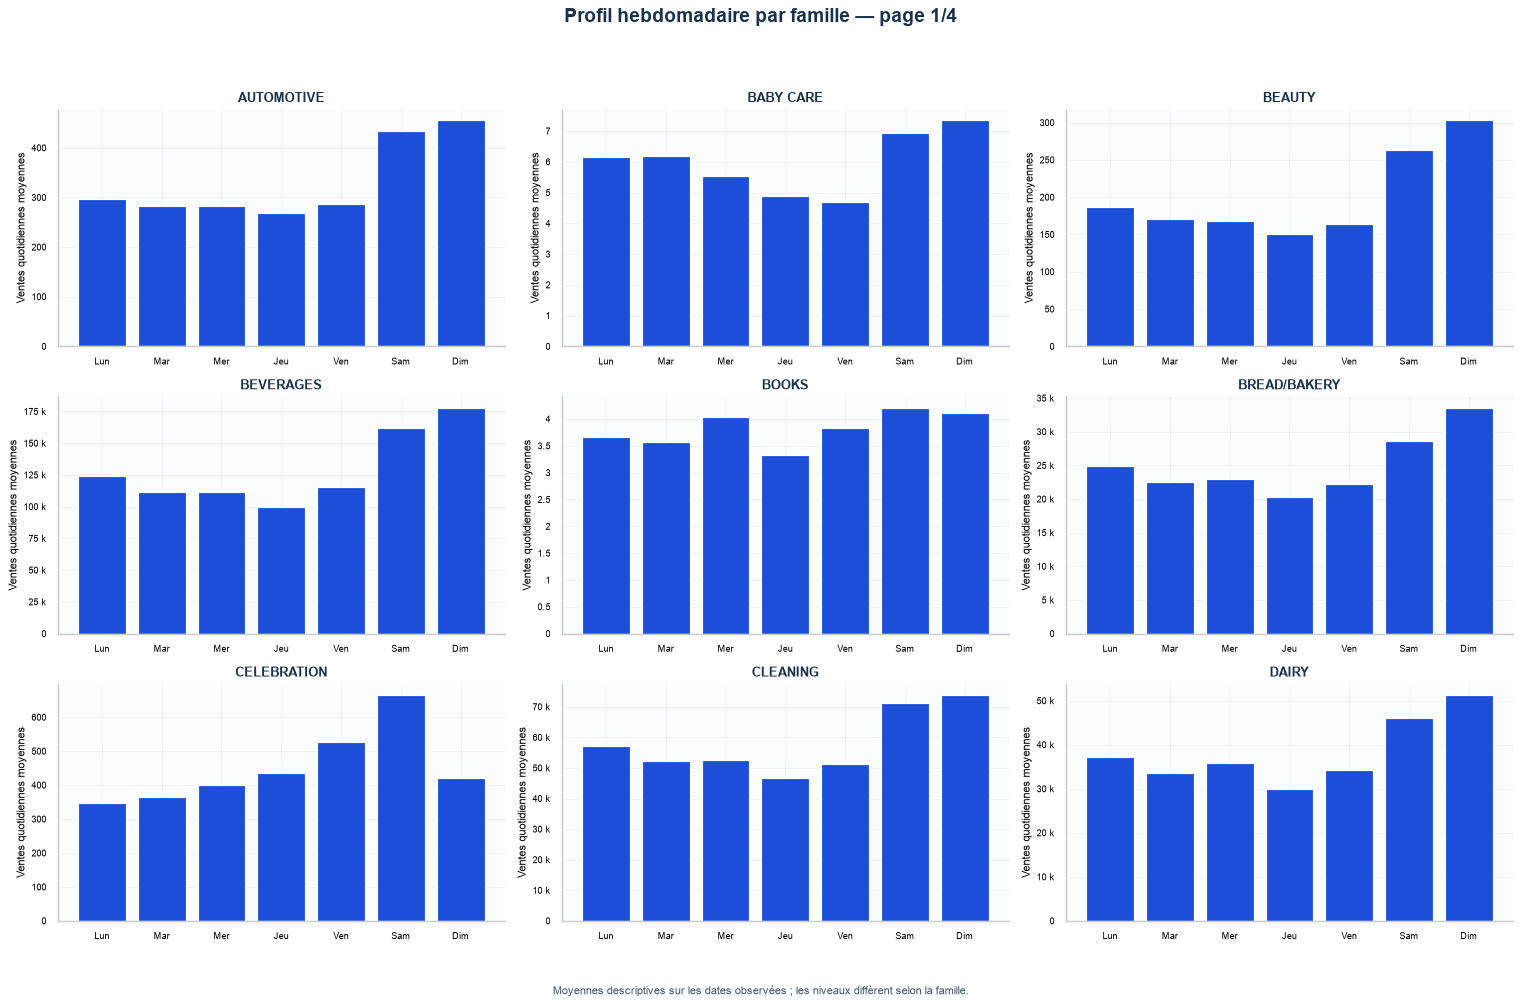

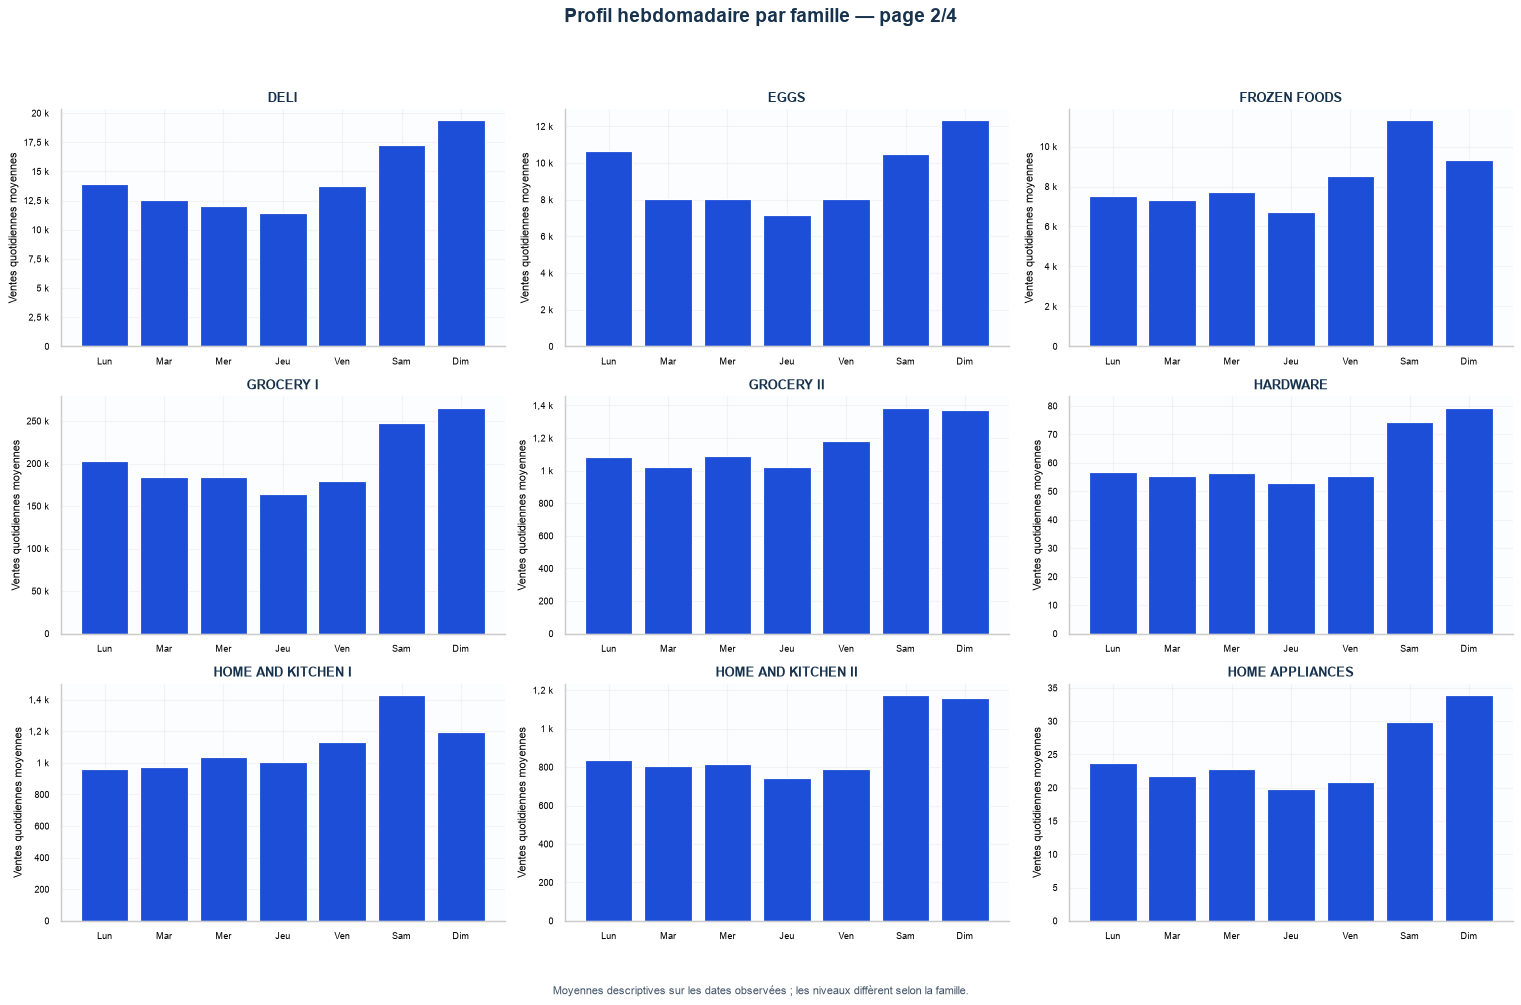

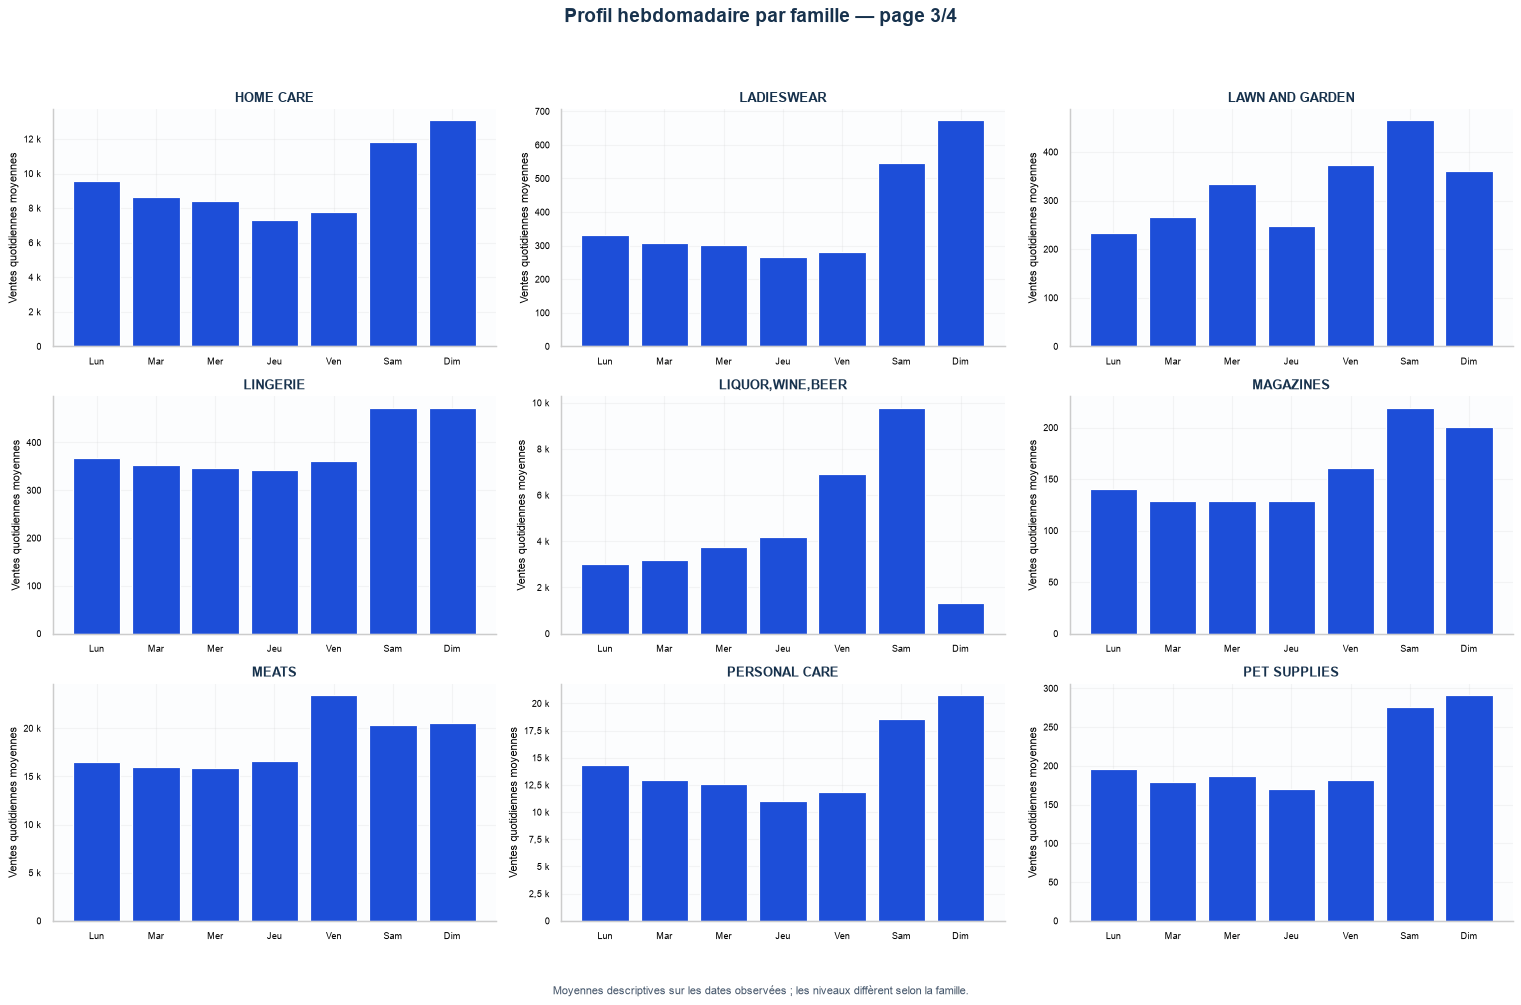

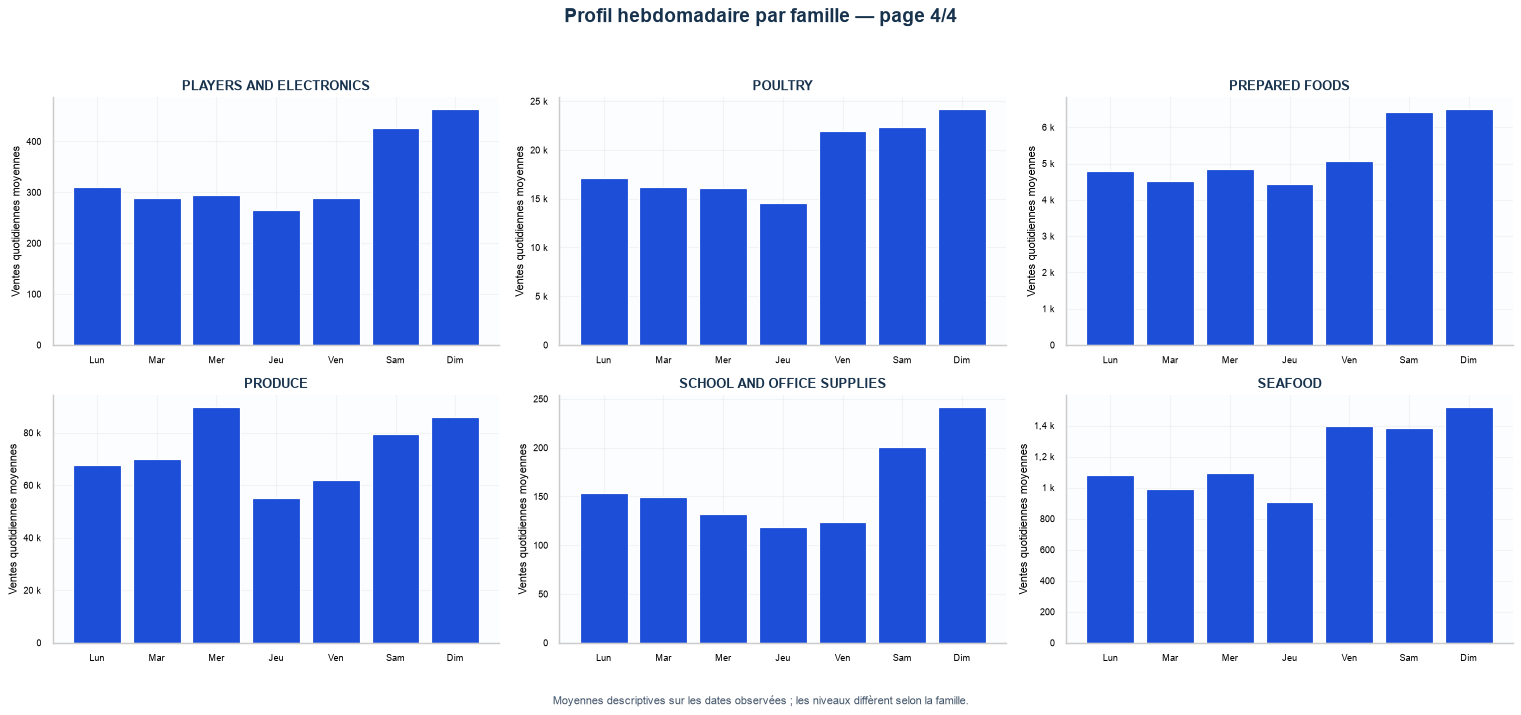

In [32]:
v_famille_calendrier = v_famille_jour.assign(
    jour_semaine=v_famille_jour["date"].dt.dayofweek,
    mois=v_famille_jour["date"].dt.month,
    annee=v_famille_jour["date"].dt.year,
)
v_profil_hebdo = v_famille_calendrier.groupby(["family", "jour_semaine"], observed=True)["ventes"].mean().unstack("jour_semaine").reindex(columns=range(7))
def dessiner_semaine_famille(ax, famille):
    ax.bar(range(7), v_profil_hebdo.loc[famille], color=COULEURS_VISUELLES["ventes"])
    ax.set_xticks(range(7), ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"])
    ax.set_title(famille, color=BLEU_VISUEL, fontweight="bold", fontsize=11)

grilles_visuelles(
    familles_visuelles, "Profil hebdomadaire par famille", dessiner_semaine_famille, "Ventes quotidiennes moyennes",
    note="Moyennes descriptives sur les dates observées ; les niveaux diffèrent selon la famille."
)
v_profil_total_hebdo = v_total_jour.groupby(v_total_jour.index.dayofweek).mean()
lecture_visuelle(
    f"Sur l’agrégat, le jour le plus élevé est {NOMS_JOURS[int(v_profil_total_hebdo.idxmax())].lower()} "
    f"et le plus faible est {NOMS_JOURS[int(v_profil_total_hebdo.idxmin())].lower()}. "
    "Les grilles permettent de vérifier si ce profil est partagé par les familles."
)


<h3 style="color:#2563EB; font-weight:700;">13.2. Profils mensuels et cartes de chaleur</h3>

**Question :** Quelles variations de calendrier restent visibles après normalisation ?

<h3 style="color:#2563EB; font-weight:700;">Vue de synthèse · Les rythmes hebdomadaires et mensuels</h3>

Cette figure résume les points de lecture ; les analyses détaillées suivent.

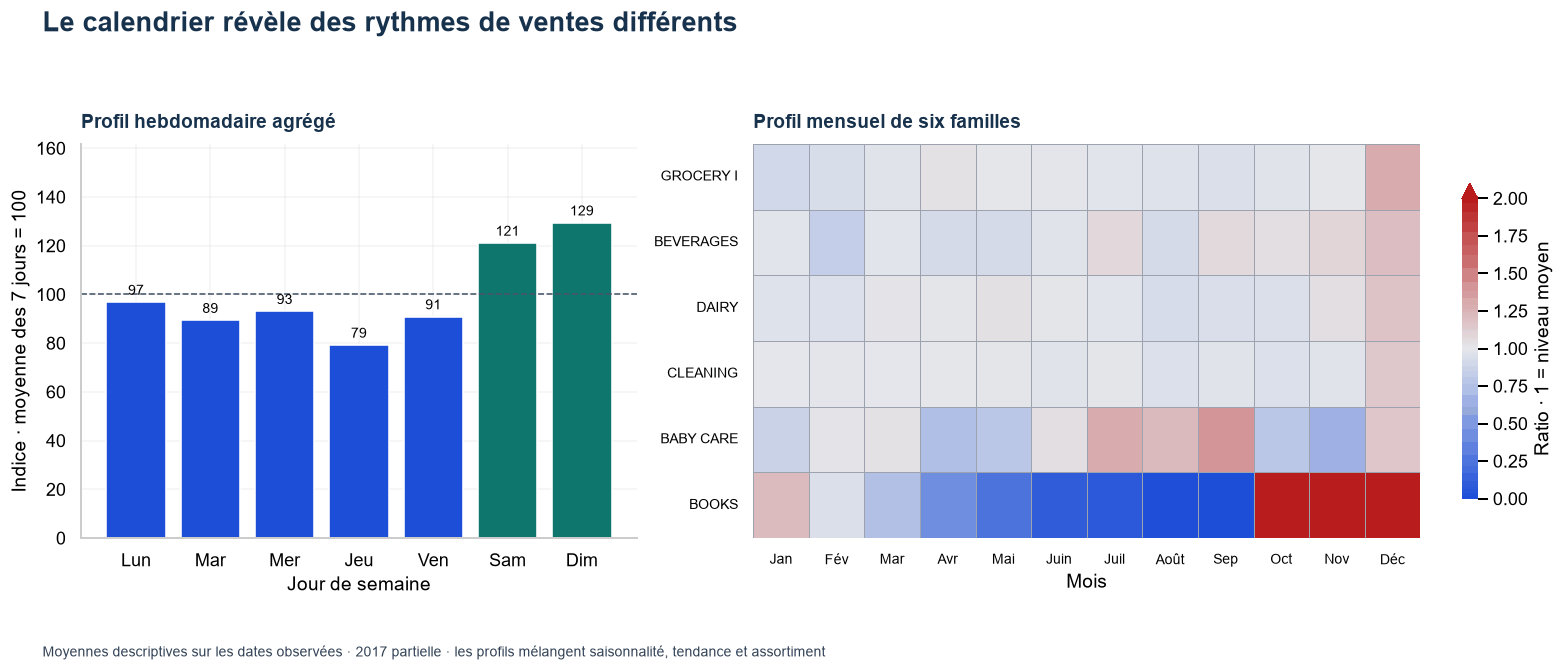

In [33]:
familles_calendrier_synthese = ["GROCERY I", "BEVERAGES", "DAIRY", "CLEANING", "BABY CARE", "BOOKS"]
profil_global = v_total_jour.groupby(v_total_jour.index.dayofweek).mean().reindex(range(7))
profil_global_indice = 100 * profil_global / profil_global.mean()
profil_mois_synthese = v_famille_calendrier.groupby(["family", "mois"], observed=True)["ventes"].mean().unstack("mois").reindex(index=familles_calendrier_synthese, columns=range(1, 13))
profil_mois_synthese = profil_mois_synthese.div(profil_mois_synthese.mean(axis=1).replace(0, np.nan), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=115, gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].bar(range(7), profil_global_indice, color=[COULEURS["ventes"]] * 5 + [COULEURS["prevision"]] * 2)
axes[0].set_xticks(range(7), ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"])
axes[0].axhline(100, color="#475569", lw=1, linestyle="--")
axes[0].set_ylim(0, profil_global_indice.max() * 1.25)
for pos, value in enumerate(profil_global_indice):
    axes[0].text(pos, value + 3, f"{value:.0f}", ha="center", fontsize=9)
titre_visuel(axes[0], "Profil hebdomadaire agrégé", "Jour de semaine", "Indice · moyenne des 7 jours = 100")
sns.heatmap(profil_mois_synthese, cmap=CMAP_DIVERGENTE, linecolor="#9CA3AF", center=1, vmin=0, vmax=2, linewidths=.6, xticklabels=["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"], yticklabels=True, cbar_kws={"label": "Ratio · 1 = niveau moyen", "extend": "max", "shrink": .8}, ax=axes[1])
axes[1].tick_params(axis="y", rotation=0, labelsize=9)
titre_visuel(axes[1], "Profil mensuel de six familles", "Mois")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=0, labelsize=9)
fig.suptitle("Le calendrier révèle des rythmes de ventes différents", color=COULEUR_TITRES, fontweight="bold", fontsize=17, x=.03, ha="left", y=.99)
fig.tight_layout(rect=(0, .12, 1, .93))
fig.text(.03, .055, "Moyennes descriptives sur les dates observées · 2017 partielle · les profils mélangent saisonnalité, tendance et assortiment", fontsize=9, color="#334155")
plt.show()
plt.close(fig)
lecture("Les indices comparent des profils, sans confondre le niveau des familles. La lecture du calendrier doit tenir compte des dates observées et des changements de composition ; aucun effet causal n’est déduit.")


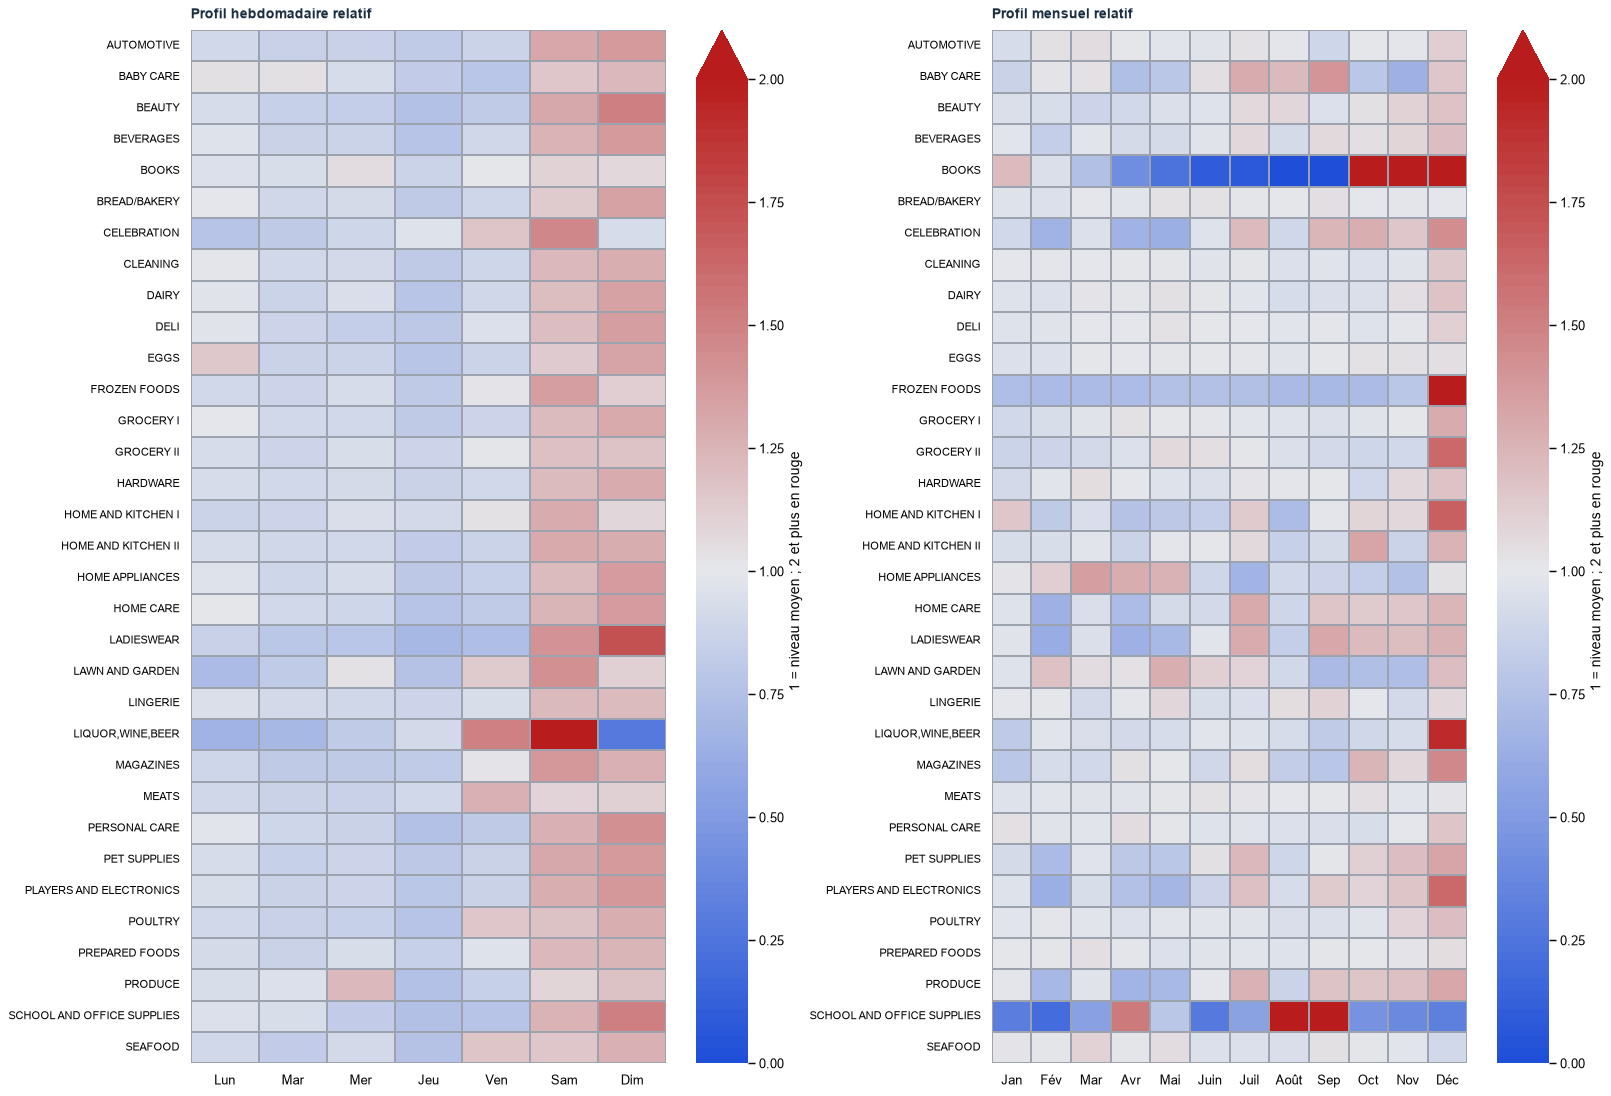

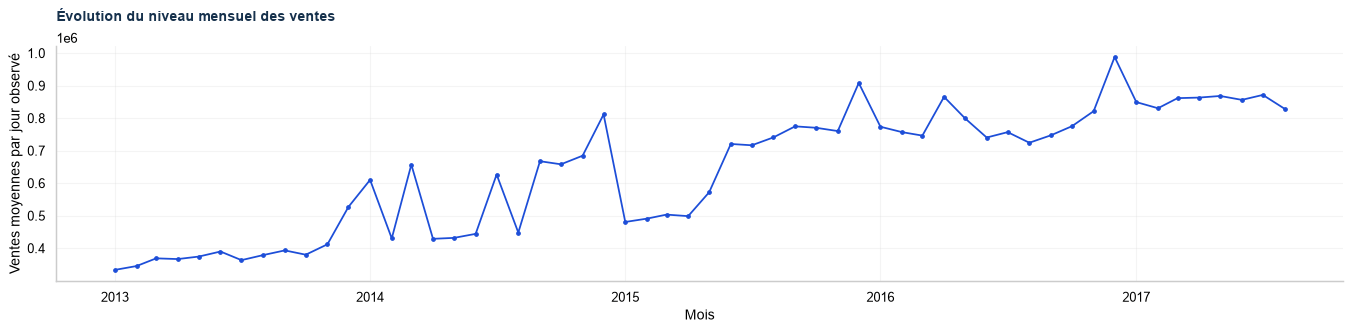

In [34]:
v_profil_mensuel = v_famille_calendrier.groupby(["family", "mois"], observed=True)["ventes"].mean().unstack("mois").reindex(columns=range(1, 13))
v_hebdo_relatif = v_profil_hebdo.div(v_profil_hebdo.mean(axis=1).replace(0, np.nan), axis=0)
v_mois_relatif = v_profil_mensuel.div(v_profil_mensuel.mean(axis=1).replace(0, np.nan), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(19, 13))
for ax, matrice, labels, titre in [
    (axes[0], v_hebdo_relatif, ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"], "Profil hebdomadaire relatif"),
    (axes[1], v_mois_relatif, ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"], "Profil mensuel relatif"),
]:
    sns.heatmap(matrice.reindex(familles_visuelles), cmap=CMAP_DIVERGENTE, linecolor="#9CA3AF", linewidths=.4, center=1, vmin=0, vmax=2,
                xticklabels=labels, yticklabels=True, cbar_kws={"label": "1 = niveau moyen ; 2 et plus en rouge", "extend": "max"}, ax=ax)
    titre_visuel(ax, titre)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=9)
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()
plt.close(fig)
v_mois_total = v_total_jour.resample("MS").agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(v_mois_total.index, v_mois_total["mean"], color=COULEURS_VISUELLES["ventes"], marker="o", markersize=3)
titre_visuel(ax, "Évolution du niveau mensuel des ventes", "Mois", "Ventes moyennes par jour observé")
fig.tight_layout()
plt.show()
plt.close(fig)
lecture_visuelle(
    "Une valeur de 1,5 signifie un niveau moyen 50 % plus élevé que la moyenne des catégories calendaires "
    "de cette famille, pas une hausse causée par le calendrier. La carte mensuelle mélange saisonnalité, tendance et "
    "changements d’assortiment. Les dates observées, dont une année 2017 partielle, n’ont pas toutes la même couverture."
)


<h3 style="color:#2563EB; font-weight:700;">13.3. Types, portée et transferts des événements</h3>

**Question :** Quelles entrées représentent la date initiale ou la date effective ?

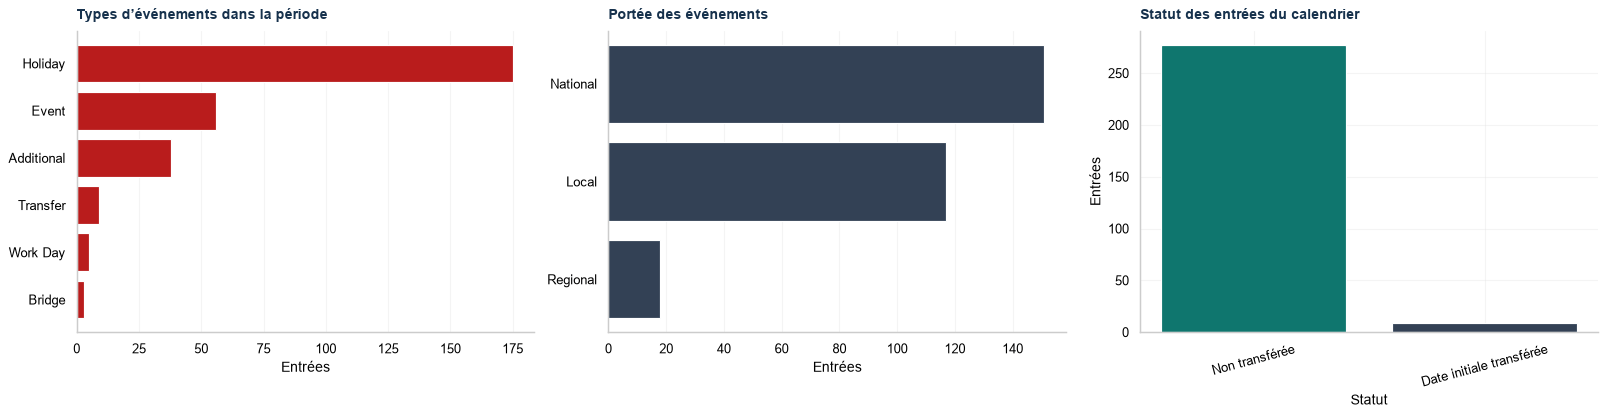

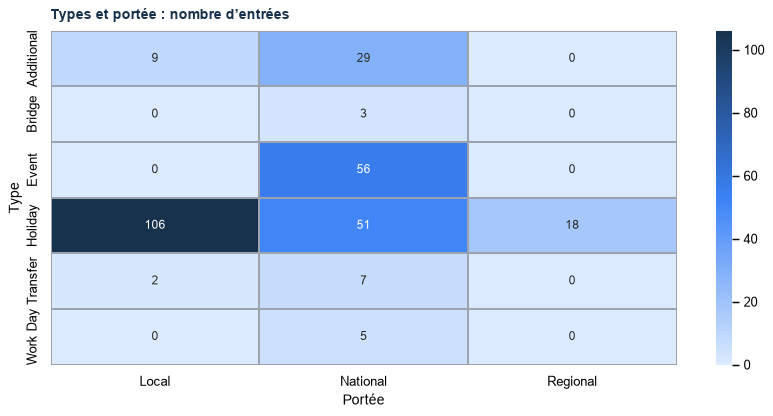

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
barres_visuelles(axes[0], v_evenements_periode.groupby("type").size(), "Types d’événements dans la période", "Entrées", COULEURS_VISUELLES["evenement"])
barres_visuelles(axes[1], v_evenements_periode.groupby("locale").size(), "Portée des événements", "Entrées", COULEURS_VISUELLES["neutre"])
v_comptage_transferts = v_evenements_periode.groupby("transferred").size().reindex([False, True], fill_value=0)
axes[2].bar(["Non transférée", "Date initiale transférée"], v_comptage_transferts, color=["#0F766E", "#334155"])
titre_visuel(axes[2], "Statut des entrées du calendrier", "Statut", "Entrées")
axes[2].tick_params(axis="x", rotation=15)
fig.tight_layout()
plt.show()
plt.close(fig)
fig, ax = plt.subplots(figsize=(10, 5))
v_type_portee = pd.crosstab(v_evenements_periode["type"], v_evenements_periode["locale"])
sns.heatmap(v_type_portee, annot=True, fmt="d", cmap=CMAP_SEQUENTIELLE, linecolor="#9CA3AF", linewidths=.4, ax=ax)
titre_visuel(ax, "Types et portée : nombre d’entrées", "Portée", "Type")
fig.tight_layout()
plt.show()
plt.close(fig)
lecture_visuelle(
    f"Dans la période de ventes, {int(v_evenements_periode['transferred'].sum())} entrées correspondent à une date initiale transférée. "
    "Elles sont exclues des marqueurs rouges des familles ; les lignes de type Transfer restent présentes à la date reportée. "
    "Work Day et Event ne sont pas assimilés à un magasin fermé."
)


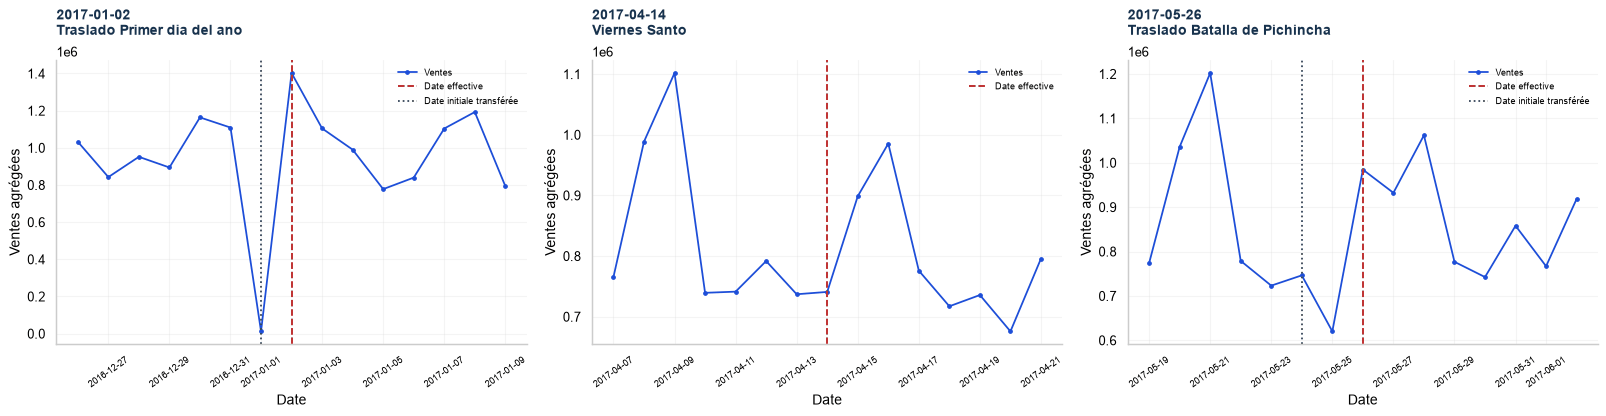

In [36]:
v_dates_zoom_evenements = [pd.Timestamp("2017-01-02"), pd.Timestamp("2017-04-14"), pd.Timestamp("2017-05-26")]
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, date_evenement in zip(axes, v_dates_zoom_evenements):
    contexte = v_total_jour.loc[date_evenement - pd.Timedelta(days=7):date_evenement + pd.Timedelta(days=7)]
    ax.plot(contexte.index, contexte, color=COULEURS_VISUELLES["ventes"], marker=".", label="Ventes")
    ax.axvline(date_evenement, color=COULEURS_VISUELLES["evenement"], linestyle="--", label="Date effective")
    initiales = v_evenements_periode.loc[
        v_evenements_periode["locale"].eq("National") & v_evenements_periode["transferred"]
        & v_evenements_periode["date"].between(contexte.index.min(), contexte.index.max()), "date"
    ].drop_duplicates()
    for date_initiale in initiales:
        ax.axvline(date_initiale, color="#334155", linestyle=":", label="Date initiale transférée")
    ligne_evenement = v_evenements_effectifs.loc[
        v_evenements_effectifs["locale"].eq("National") & v_evenements_effectifs["date"].eq(date_evenement)
    ].iloc[0]
    titre_visuel(ax, f"{date_evenement.date()}\n{ligne_evenement['description']}", "Date", "Ventes agrégées")
    ax.tick_params(axis="x", rotation=35, labelsize=8)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)
lecture_visuelle(
    "Le 1er janvier et le 24 mai 2017 sont des dates initiales transférées ; les lignes effectives "
    "se situent ici aux 2 janvier et 26 mai. La variation des ventes autour de ces repères peut aussi dépendre "
    "du jour de semaine, des promotions et de la période."
)


<h3 style="color:#2563EB; font-weight:700;">13.4. Rapprochement des événements aux magasins concernés</h3>

**Question :** Les événements locaux et régionaux sont-ils associés aux bons magasins ?

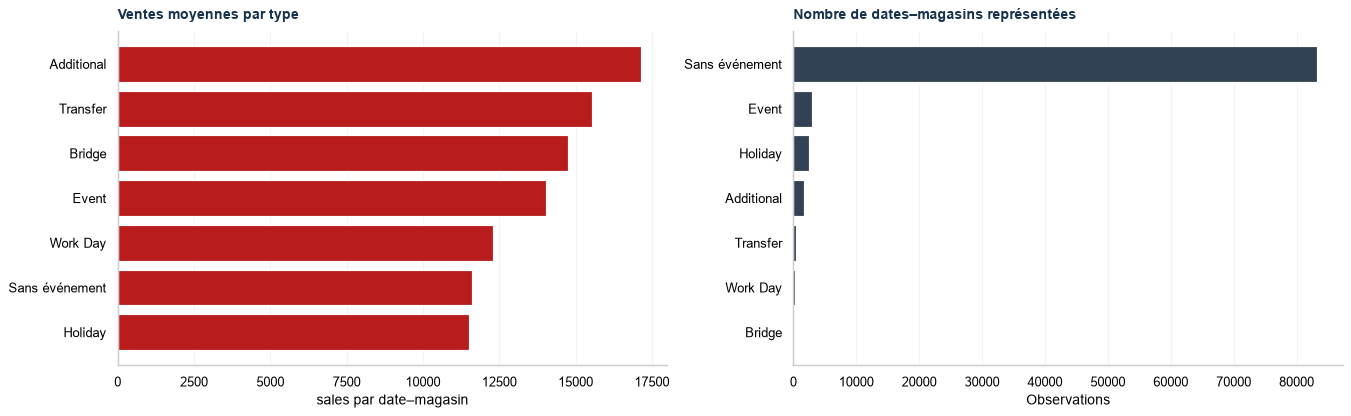

,moyenne,mediane,dates_magasins
type,,,
Additional,"17 144,960","14 526,010","1 678,000"
Bridge,"14 742,780","11 650,240","162,000"
Event,"14 025,810","10 986,340","2 970,000"
Holiday,"11 518,320","8 455,290","2 435,000"
Transfer,"15 524,240","12 007,530","389,000"
Work Day,"12 281,200","9 532,330","270,000"
Sans événement,"11 618,300","9 210,160","83 216,000"


In [37]:
v_lignes_calendrier_magasin = []
for evenement in v_evenements_effectifs.itertuples(index=False):
    if evenement.locale == "National":
        magasins_concernes = v_stores["store_nbr"]
    elif evenement.locale == "Regional":
        magasins_concernes = v_stores.loc[v_stores["state"].eq(evenement.locale_name), "store_nbr"]
    else:
        magasins_concernes = v_stores.loc[v_stores["city"].eq(evenement.locale_name), "store_nbr"]
    v_lignes_calendrier_magasin.extend(
        {"date": evenement.date, "store_nbr": int(magasin), "type": evenement.type}
        for magasin in magasins_concernes
    )
v_calendrier_magasin = pd.DataFrame(v_lignes_calendrier_magasin).drop_duplicates(["date", "store_nbr", "type"])
v_ventes_par_type_evenement = v_calendrier_magasin.merge(
    v_magasin_jour, on=["date", "store_nbr"], how="inner", validate="many_to_one"
)
v_dates_magasin_evenement = v_calendrier_magasin[["date", "store_nbr"]].drop_duplicates()
v_sans_evenement = v_magasin_jour.merge(v_dates_magasin_evenement.assign(evenement=True),
    on=["date", "store_nbr"], how="left", validate="one_to_one")
v_sans_evenement = v_sans_evenement.loc[v_sans_evenement["evenement"].isna()]
v_resume_types = v_ventes_par_type_evenement.groupby("type")["ventes"].agg(moyenne="mean", mediane="median", dates_magasins="size")
v_resume_types.loc["Sans événement"] = [
    v_sans_evenement["ventes"].mean(), v_sans_evenement["ventes"].median(), len(v_sans_evenement)
]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
barres_visuelles(axes[0], v_resume_types["moyenne"], "Ventes moyennes par type", "sales par date–magasin", COULEURS_VISUELLES["evenement"])
barres_visuelles(axes[1], v_resume_types["dates_magasins"], "Nombre de dates–magasins représentées", "Observations", COULEURS_VISUELLES["neutre"])
fig.tight_layout()
plt.show()
plt.close(fig)
afficher_tableau_visuel(v_resume_types.round(2))
lecture_visuelle(
    "Une date–magasin peut relever de plusieurs types, mais une même combinaison date–magasin–type est dédupliquée. "
    "Les catégories ne sont donc pas exclusives et leurs volumes ne doivent pas être additionnés. "
    "Les moyennes ne corrigent pas les différences de magasins ni de dates ; elles restent descriptives."
)


<a id="section-14"></a>

<h2 style="color:#2563EB; font-weight:700;">14. Synthèse de l’exploration</h2>

**Question :** Quels enseignements guideront les choix à tester localement ?

In [38]:
v_synthese_exploration = pd.DataFrame([
    ("Familles", f"{len(familles_visuelles)} profils ; {v_resume_familles['volume'].idxmax()} a le volume agrégé le plus élevé.",
     "Comparer aussi les petites familles, les distributions et les périodes actives."),
    ("Calendrier", f"Le niveau agrégé moyen est maximal le {NOMS_JOURS[int(v_profil_total_hebdo.idxmax())].lower()}.",
     "Les profils mensuels mélangent tendance, saisonnalité et couverture partielle."),
    ("Promotions", f"{ventes['onpromotion'].gt(0).mean():.1%} des lignes ont au moins un produit en promotion.",
     "Comparer à famille, magasin et période comparables avant d’interpréter un effet."),
    ("Magasins", f"{len(magasins_visuels)} magasins répartis sur {v_stores['city'].nunique()} villes.",
     "Conserver les effectifs et le contexte d’activité pour lire les moyennes."),
    ("Pétrole", f"{int(petrole['dcoilwtico'].isna().sum())} prix manquants dans le fichier original.",
     "Interpolation limitée à l’affichage ; aucune valeur future ajoutée au modèle."),
    ("Événements", f"{int(v_evenements_periode['transferred'].sum())} dates initiales transférées dans la période.",
     "Utiliser le type, la portée et la date effective ; les catégories peuvent se chevaucher."),
    ("Transactions", f"{v_paires_transactions['transactions'].notna().mean():.1%} des dates–magasins sont appariées.",
     "Activité historique seulement ; aucune fusion répétant le nombre par famille."),
    ("Zéros et pics", f"{ventes['sales'].eq(0).mean():.1%} des lignes ont une vente nulle.",
     "Ni zéro ni pic ne suffit à prouver une rupture ou une erreur de données."),
], columns=["donnée", "observation calculée", "interprétation et limite"])
afficher_tableau_visuel(v_synthese_exploration)
lecture_visuelle(
    "L’exploration couvre chaque famille et chaque magasin tout en conservant les vues globales. "
    "Les hypothèses suggérées par les graphiques pourront être testées séparément sur le backtest local ; "
    "aucune performance supplémentaire ni économie réelle n’est déduite de ces seules visualisations."
)


donnée,observation calculée,interprétation et limite
Familles,33 profils ; GROCERY I a le volume agrégé le plus élevé.,"Comparer aussi les petites familles, les distributions et les périodes actives."
Calendrier,Le niveau agrégé moyen est maximal le dimanche.,"Les profils mensuels mélangent tendance, saisonnalité et couverture partielle."
Promotions,20.4% des lignes ont au moins un produit en promotion.,"Comparer à famille, magasin et période comparables avant d’interpréter un effet."
Magasins,54 magasins répartis sur 22 villes.,Conserver les effectifs et le contexte d’activité pour lire les moyennes.
Pétrole,43 prix manquants dans le fichier original.,Interpolation limitée à l’affichage ; aucune valeur future ajoutée au modèle.
Événements,9 dates initiales transférées dans la période.,"Utiliser le type, la portée et la date effective ; les catégories peuvent se chevaucher."
Transactions,91.8% des dates–magasins sont appariées.,Activité historique seulement ; aucune fusion répétant le nombre par famille.
Zéros et pics,31.3% des lignes ont une vente nulle.,Ni zéro ni pic ne suffit à prouver une rupture ou une erreur de données.


Les graphiques de l’ensemble de l’historique servent à comprendre le jeu. Ils ne constituent pas une évaluation indépendante. Les variantes de modèle sont comparées avec des apprentissages antérieurs à chaque horizon, et les périodes de validation ayant servi au choix ne sont pas présentées comme un test final intouché.

Les futures analyses pourront isoler l’apport des événements ou des caractéristiques des magasins. Aucune amélioration de score n’est déduite des seules associations visuelles.

<hr>

<p style="color:#2563EB; font-size:13px; letter-spacing:1px;"><strong>PARTIE 04 · PRÉVOIR</strong></p>

Comparer des méthodes avec une validation chronologique explicite.

<a id="section-15"></a>

<h2 style="color:#2563EB; font-weight:700;">15. Protocole de validation</h2>

**Question :** Comment mesurer une prévision sans utiliser les ventes futures pendant l’apprentissage ?

Quatre origines chronologiques sont définies à la fin de l’historique. Les baselines sont figées à chaque origine ; LightGBM réutilise uniquement ses propres prévisions pendant l’horizon.

In [39]:
donnees = train_clean[["date", "store_nbr", "family", "sales", "onpromotion"]].copy()
donnees["store_nbr"] = donnees["store_nbr"].astype("category")
donnees = donnees.sort_values(["date", *CLES_SERIE]).reset_index(drop=True)
DATE_MAX = donnees["date"].max()
DATE_PREMIERE_VALIDATION = DATE_MAX - pd.Timedelta(days=HORIZON_JOURS * N_FOLDS - 1)


In [40]:
assert donnees["sales"].notna().all(), "La cible contient des valeurs manquantes."
assert donnees["sales"].ge(0).all(), "La cible contient des ventes négatives."
assert not donnees.duplicated(["date", *CLES_SERIE]).any(), "Doublons date-magasin-famille détectés."

nb_dates = donnees["date"].nunique()
nb_series = donnees[CLES_SERIE].drop_duplicates().shape[0]
lignes_attendues = nb_dates * nb_series
print(f"Dates : {nb_dates:,} | séries magasin-famille : {nb_series:,}")
print(f"Lignes observées : {len(donnees):,} | lignes attendues si grille complète : {lignes_attendues:,}")
assert len(donnees) == lignes_attendues, "La grille n'est pas complète ; examiner les dates/séries manquantes avant le backtest."
dates_observees = pd.DatetimeIndex(donnees["date"].unique()).sort_values()
calendrier = pd.date_range(dates_observees.min(), dates_observees.max(), freq="D")
dates_absentes = calendrier.difference(dates_observees)
print("Dates entièrement absentes :", dates_absentes.strftime("%Y-%m-%d").tolist())
print("Contrôles réussis : toutes les séries aux dates observées, cible non négative, aucune clé en double.")
print("Le calendrier historique contient des dates absentes ; elles ne sont pas imputées à zéro.")


Dates : 1,684 | séries magasin-famille : 1,782
Lignes observées : 3,000,888 | lignes attendues si grille complète : 3,000,888
Dates entièrement absentes : ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']
Contrôles réussis : toutes les séries aux dates observées, cible non négative, aucune clé en double.
Le calendrier historique contient des dates absentes ; elles ne sont pas imputées à zéro.


In [41]:
DATE_MAX = donnees["date"].max()
DATE_PREMIERE_VALIDATION = DATE_MAX - pd.Timedelta(days=HORIZON_JOURS * N_FOLDS - 1)
plis = []
for numero in range(N_FOLDS):
    debut = DATE_PREMIERE_VALIDATION + pd.Timedelta(days=numero * HORIZON_JOURS)
    fin = debut + pd.Timedelta(days=HORIZON_JOURS - 1)
    plis.append(
        {
            "pli": numero + 1,
            "fin_entrainement": debut - pd.Timedelta(days=1),
            "debut_validation": debut,
            "fin_validation": fin,
        }
    )

plis_validation = pd.DataFrame(plis)
assert plis_validation.iloc[0]["fin_entrainement"] < plis_validation.iloc[0]["debut_validation"]
assert (plis_validation["fin_validation"] - plis_validation["debut_validation"]).dt.days.eq(HORIZON_JOURS - 1).all()
assert plis_validation["debut_validation"].iloc[1:].reset_index(drop=True).eq(
    plis_validation["fin_validation"].iloc[:-1].reset_index(drop=True) + pd.Timedelta(days=1)
).all()
afficher_tableau(plis_validation)


pli,fin_entrainement,debut_validation,fin_validation
1,2017-06-20,2017-06-21,2017-07-04
2,2017-07-04,2017-07-05,2017-07-18
3,2017-07-18,2017-07-19,2017-08-01
4,2017-08-01,2017-08-02,2017-08-15


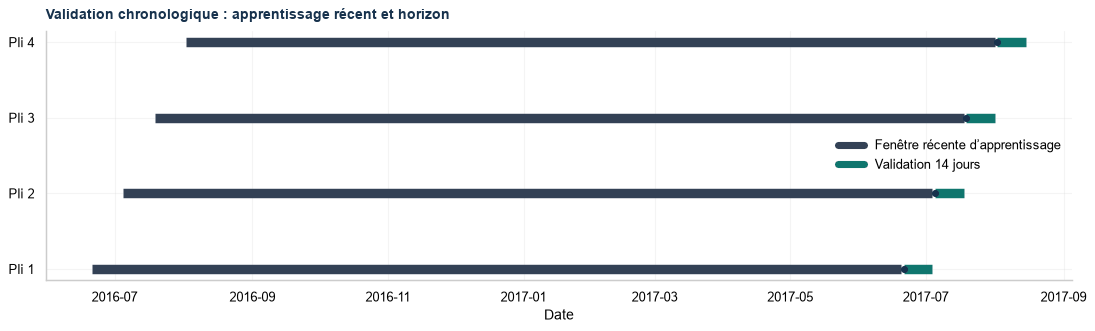

In [42]:
fig, ax = plt.subplots(figsize=(13, 4))
for row in plis_validation.itertuples(index=False):
    origin = row.debut_validation
    ax.plot([origin - pd.Timedelta(days=365), row.fin_entrainement], [row.pli, row.pli], color=COULEURS["baseline"], linewidth=8, solid_capstyle="butt")
    ax.plot([origin, row.fin_validation], [row.pli, row.pli], color=COULEURS["prevision"], linewidth=8, solid_capstyle="butt")
    ax.scatter(origin, row.pli, color=COULEUR_TITRES, s=25, zorder=3)
ax.set_yticks(range(1, N_FOLDS + 1), [f"Pli {i}" for i in range(1, N_FOLDS + 1)])
titre_visuel(ax, "Validation chronologique : apprentissage récent et horizon", "Date", "")
ax.legend(handles=[Line2D([0], [0], color=COULEURS["baseline"], lw=6, label="Fenêtre récente d’apprentissage"), Line2D([0], [0], color=COULEURS["prevision"], lw=6, label="Validation 14 jours")])
fig.tight_layout()
plt.show()
plt.close(fig)
lecture("La fenêtre récente est illustrée ici ; les mêmes origines serviront à comparer 365 jours et tout l’historique. Les quatre plis de 16 jours couvrent une autre période : on compare les fenêtres d’apprentissage à horizon identique.")



<table style="border-collapse:collapse; width:100%; background-color:#F3F4F6; color:#000000;">
<thead>
<tr>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Mesure</th>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Interprétation</th>
</tr>
</thead>
<tbody>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">RMSLE</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Écart quadratique sur <code style="background-color:transparent; color:#000000;">log(1 + sales)</code> ; plus bas est meilleur</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">MAE</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Erreur absolue moyenne dans l’unité des ventes</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">WAPE</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Somme des erreurs absolues divisée par le volume réel ; indéfini si volume nul</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Biais moyen</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Prévision moins réel ; positif = surestimation, négatif = sous-estimation</td>
</tr>
</tbody>
</table>

Les scores globaux présentés sont des **moyennes des scores des quatre plis**. Les petits volumes peuvent rendre le WAPE très instable ; le volume et la MAE sont toujours conservés pour l’interprétation.

<a id="section-16"></a>

<h2 style="color:#2563EB; font-weight:700;">16. Modèles de référence</h2>

**Question :** Quel niveau de performance obtient-on avec des règles simples ?

In [43]:
predictions_plis = []
for pli in plis:
    debut = pli["debut_validation"]
    fin = pli["fin_validation"]
    historique = donnees.loc[donnees["date"].lt(debut)].copy()
    evaluation = donnees.loc[donnees["date"].between(debut, fin)].copy()
    dates_necessaires = pd.date_range(debut - pd.Timedelta(days=28), fin, freq="D")
    assert dates_necessaires.isin(dates_observees).all(), "Date absente dans une référence ou une validation."
    assert len(evaluation) == HORIZON_JOURS * nb_series

    derniere_semaine = historique.loc[
        historique["date"].ge(debut - pd.Timedelta(days=7))
    ].copy()
    derniere_semaine["jour_semaine"] = derniere_semaine["date"].dt.dayofweek
    derniere_semaine = (
        derniere_semaine.sort_values("date")
        .drop_duplicates(CLES_SERIE + ["jour_semaine"], keep="last")
        [CLES_SERIE + ["jour_semaine", "sales"]]
        .rename(columns={"sales": "pred_saisonnier"})
    )

    quatre_semaines = historique.loc[
        historique["date"].ge(debut - pd.Timedelta(days=28))
    ].copy()
    quatre_semaines["jour_semaine"] = quatre_semaines["date"].dt.dayofweek
    moyenne_jour = (
        quatre_semaines.groupby(CLES_SERIE + ["jour_semaine"], observed=True)["sales"]
        .mean()
        .rename("pred_moyenne_4_semaines")
        .reset_index()
    )

    evaluation["jour_semaine"] = evaluation["date"].dt.dayofweek
    evaluation = evaluation.rename(columns={"sales": "ventes_reelles"})
    evaluation = evaluation.merge(
        derniere_semaine, on=CLES_SERIE + ["jour_semaine"], how="left", validate="many_to_one"
    ).merge(
        moyenne_jour, on=CLES_SERIE + ["jour_semaine"], how="left", validate="many_to_one"
    )
    assert evaluation[["pred_saisonnier", "pred_moyenne_4_semaines"]].notna().all().all(), "Une baseline n'a pas trouvé de référence."
    evaluation["pli"] = pli["pli"]
    predictions_plis.append(evaluation)

predictions = pd.concat(predictions_plis, ignore_index=True)
print(f"Lignes de validation : {len(predictions):,}")
print(f"Plis : {predictions['pli'].nunique()} | lignes par pli : {predictions.groupby('pli').size().tolist()}")


Lignes de validation : 99,792
Plis : 4 | lignes par pli : [24948, 24948, 24948, 24948]


In [44]:
METHODES = {
    "Naïf saisonnier hebdomadaire": "pred_saisonnier",
    "Moyenne des 4 semaines par jour": "pred_moyenne_4_semaines",
}

def calculer_metriques(frame: pd.DataFrame, colonne_prediction: str) -> dict[str, float]:
    reel = frame["ventes_reelles"].to_numpy(dtype=float)
    predit = np.clip(frame[colonne_prediction].to_numpy(dtype=float), 0, None)
    erreur_absolue = np.abs(reel - predit)
    rmsle = np.sqrt(np.mean((np.log1p(reel) - np.log1p(predit)) ** 2))
    wape = erreur_absolue.sum() / reel.sum() if reel.sum() else np.nan
    return {"MAE": erreur_absolue.mean(), "RMSLE": rmsle, "WAPE": wape}

lignes_scores = []
for numero_pli, frame_pli in predictions.groupby("pli", sort=True):
    for nom, colonne in METHODES.items():
        lignes_scores.append({"pli": numero_pli, "baseline": nom, **calculer_metriques(frame_pli, colonne)})
scores_par_pli = pd.DataFrame(lignes_scores)
scores_moyens = (
    scores_par_pli.groupby("baseline", as_index=False)[["MAE", "RMSLE", "WAPE"]]
    .mean()
)
print("Scores par pli :")
afficher_tableau(scores_par_pli.round(4))
print("Moyenne des quatre plis :")
afficher_tableau(scores_moyens.sort_values("RMSLE").round(4))


Scores par pli :


pli,baseline,MAE,RMSLE,WAPE
1,Naïf saisonnier hebdomadaire,"86,053","0,5290","17,8%"
1,Moyenne des 4 semaines par jour,"71,294","0,4314","14,8%"
2,Naïf saisonnier hebdomadaire,"93,163","0,5158","19,8%"
2,Moyenne des 4 semaines par jour,"57,951","0,4208","12,3%"
3,Naïf saisonnier hebdomadaire,"73,103","0,5320","15,2%"
3,Moyenne des 4 semaines par jour,"69,188","0,4526","14,4%"
4,Naïf saisonnier hebdomadaire,"106,476","0,6007","23,2%"
4,Moyenne des 4 semaines par jour,"80,262","0,5194","17,5%"


Moyenne des quatre plis :


baseline,MAE,RMSLE,WAPE
Moyenne des 4 semaines par jour,"69,674","0,4561","14,7%"
Naïf saisonnier hebdomadaire,"89,698","0,5444","19,0%"


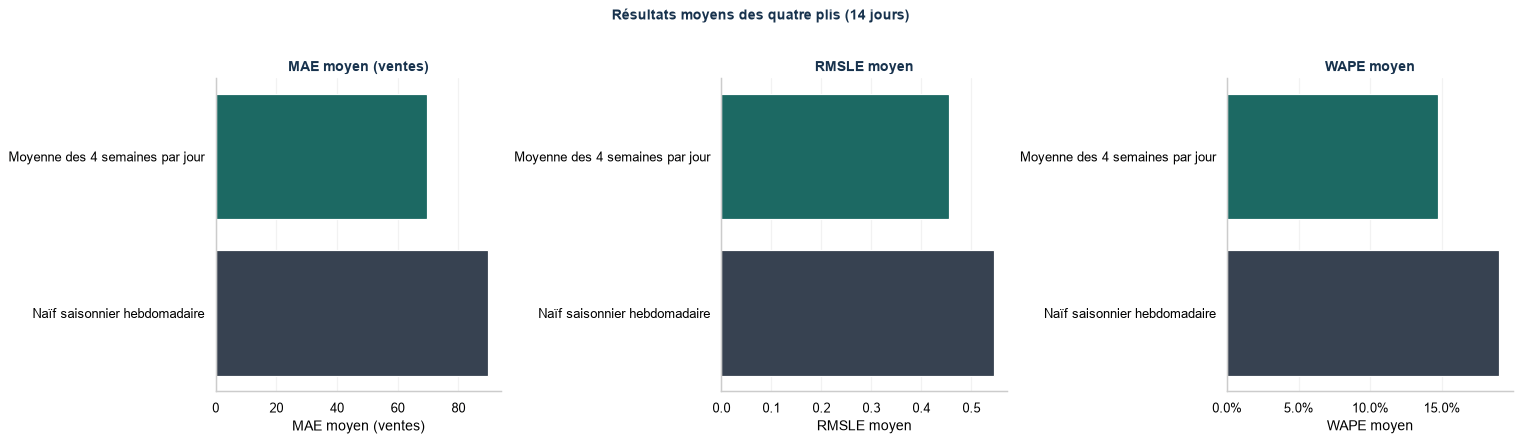

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

BLEU = COULEUR_TITRES
COULEURS_BASELINES = {
    "Naïf saisonnier hebdomadaire": "#334155",
    "Moyenne des 4 semaines par jour": "#0F766E",
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metriques_visuelles = [
    ("MAE", "MAE moyen (ventes)"),
    ("RMSLE", "RMSLE moyen"),
    ("WAPE", "WAPE moyen"),
]
for axe, (metrique, titre) in zip(axes, metriques_visuelles):
    sns.barplot(
        data=scores_moyens,
        x=metrique,
        y="baseline",
        hue="baseline",
        palette=COULEURS_BASELINES,
        legend=False,
        ax=axe,
    )
    axe.set_title(titre, color=BLEU, fontweight="bold")
    axe.set_xlabel(titre)
    axe.set_ylabel("")
    if metrique == "WAPE":
        axe.xaxis.set_major_formatter(PercentFormatter(1))
    axe.grid(axis="x", alpha=0.25)
    axe.grid(axis="y", visible=False)

fig.suptitle("Résultats moyens des quatre plis (14 jours)", color=BLEU, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


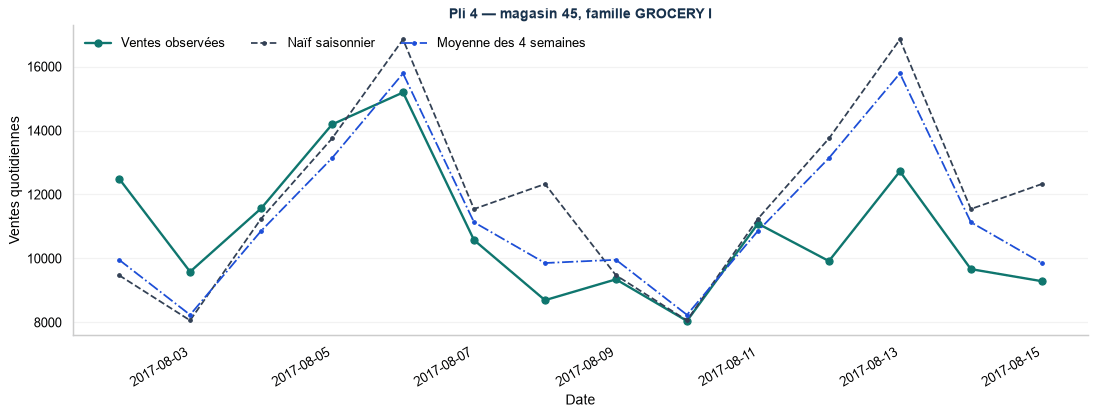

In [46]:
dernier_pli = predictions.loc[predictions["pli"].eq(N_FOLDS)].copy()
volume_par_serie = (
    dernier_pli.groupby(CLES_SERIE, observed=True)["ventes_reelles"]
    .sum()
    .sort_values(ascending=False)
)
magasin_exemple, famille_exemple = volume_par_serie.index[0]
exemple = dernier_pli.loc[
    dernier_pli["store_nbr"].eq(magasin_exemple)
    & dernier_pli["family"].eq(famille_exemple)
].sort_values("date")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(
    exemple["date"],
    exemple["ventes_reelles"],
    color="#0F766E",
    marker="o",
    linewidth=2,
    label="Ventes observées",
)
ax.plot(
    exemple["date"],
    exemple["pred_saisonnier"],
    color="#334155",
    linestyle="--",
    marker=".",
    label="Naïf saisonnier",
)
ax.plot(
    exemple["date"],
    exemple["pred_moyenne_4_semaines"],
    color="#1D4ED8",
    linestyle="-.",
    marker=".",
    label="Moyenne des 4 semaines",
)
ax.set_title(
    f"Pli {N_FOLDS} — magasin {magasin_exemple}, famille {famille_exemple}",
    color=BLEU,
    fontweight="bold",
)
ax.set_xlabel("Date")
ax.set_ylabel("Ventes quotidiennes")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [47]:
meilleure_baseline = scores_moyens.sort_values("RMSLE").iloc[0]
lecture(f"La meilleure baseline selon le RMSLE moyen est {meilleure_baseline['baseline']} ({meilleure_baseline['RMSLE']:.4f}). Ces prévisions sont obtenues à partir des 28 jours précédant chaque origine, sans lire les ventes réelles de l’horizon.")


<a id="section-17"></a>

<h2 style="color:#2563EB; font-weight:700;">17. Variables du modèle</h2>

**Question :** Quelles variables sont réellement disponibles au moment de prévoir ?

Les retards et moyennes mobiles utilisent uniquement des jours strictement antérieurs à la cible. La grille calendaire conserve les jours absents comme NaN ; elle ne crée aucune cible. Les lignes aux variables incomplètes sont exclues de l’apprentissage.

In [48]:
FEATURES = (
    CLES_SERIE
    + ["onpromotion", "jour_semaine", "mois", "jour_annee", "weekend"]
    + [f"retard_{lag}" for lag in RETARDS]
    + [f"moyenne_mobile_{fenetre}" for fenetre in FENETRES_MOBILES]
)

def construire_features_historiques(frame: pd.DataFrame) -> pd.DataFrame:
    resultat = frame.sort_values(["date", *CLES_SERIE]).copy()
    assert not resultat.duplicated(["date", *CLES_SERIE]).any()
    calendrier = pd.date_range(resultat["date"].min(), resultat["date"].max(), freq="D")
    grille = resultat.pivot(index="date", columns=CLES_SERIE, values="sales").reindex(calendrier)
    # Les journées absentes deviennent NaN dans la grille de calcul seulement.
    # On restitue uniquement les lignes réellement observées, sans inventer de cible.
    positions_dates = grille.index.get_indexer(resultat["date"])
    positions_series = grille.columns.get_indexer(pd.MultiIndex.from_frame(resultat[CLES_SERIE]))
    assert (positions_dates >= 0).all() and (positions_series >= 0).all()
    for lag in RETARDS:
        resultat[f"retard_{lag}"] = grille.shift(lag).to_numpy()[positions_dates, positions_series]
    for fenetre in FENETRES_MOBILES:
        moyenne = grille.shift(1).rolling(fenetre, min_periods=fenetre).mean()
        resultat[f"moyenne_mobile_{fenetre}"] = moyenne.to_numpy()[positions_dates, positions_series]
    resultat["jour_semaine"] = resultat["date"].dt.dayofweek.astype("int8")
    resultat["mois"] = resultat["date"].dt.month.astype("int8")
    resultat["jour_annee"] = resultat["date"].dt.dayofyear.astype("int16")
    resultat["weekend"] = resultat["jour_semaine"].isin([5, 6]).astype("int8")
    return resultat


def construire_features_future(
    date_future: pd.Timestamp,
    exogenes: pd.DataFrame,
    historique: pd.DataFrame,
) -> pd.DataFrame:
    colonnes = ["date", *CLES_SERIE, "onpromotion"]
    if "id" in exogenes.columns:
        colonnes = ["id", *colonnes]
    futur = exogenes.loc[exogenes["date"].eq(date_future), colonnes].copy()
    assert not historique.duplicated(["date", *CLES_SERIE]).any()
    assert historique["date"].lt(date_future).all(), "L'historique contient une date future."
    futur["jour_semaine"] = futur["date"].dt.dayofweek.astype("int8")
    futur["mois"] = futur["date"].dt.month.astype("int8")
    futur["jour_annee"] = futur["date"].dt.dayofyear.astype("int16")
    futur["weekend"] = futur["jour_semaine"].isin([5, 6]).astype("int8")
    for lag in RETARDS:
        reference = historique.loc[
            historique["date"].eq(date_future - pd.Timedelta(days=lag)), CLES_SERIE + ["sales"]
        ].rename(columns={"sales": f"retard_{lag}"})
        futur = futur.merge(reference, on=CLES_SERIE, how="left", validate="one_to_one")
    for fenetre in FENETRES_MOBILES:
        observations = historique.loc[
            historique["date"].ge(date_future - pd.Timedelta(days=fenetre))
            & historique["date"].lt(date_future)
        ]
        resume = observations.groupby(CLES_SERIE, observed=True)["sales"].agg(["mean", "count"])
        moyenne = resume["mean"].where(resume["count"].eq(fenetre))
        moyenne = moyenne.rename(f"moyenne_mobile_{fenetre}").reset_index()
        futur = futur.merge(moyenne, on=CLES_SERIE, how="left", validate="one_to_one")
    if futur.empty or futur[FEATURES].isna().any().any():
        raise ValueError(f"Historique calendaire incomplet pour le {date_future.date()}")
    return futur


In [49]:
features_historiques = construire_features_historiques(donnees)
DATES_OBSERVEES = pd.DatetimeIndex(donnees["date"].unique()).sort_values()
NB_SERIES = donnees[CLES_SERIE].drop_duplicates().shape[0]
audit_features = pd.DataFrame({
    "variable": FEATURES,
    "manquants": [features_historiques[c].isna().sum() for c in FEATURES],
    "part manquante": [features_historiques[c].isna().mean() for c in FEATURES],
})
afficher_tableau(audit_features)
afficher_tableau(features_historiques[[c for c in FEATURES if c not in CLES_SERIE]].describe(percentiles=[.05, .25, .5, .75, .95]).T)
disponibilite_features = pd.DataFrame([
    ("Magasin et famille", "Connus à l’origine", "Identifiants catégoriels"),
    ("Calendrier", "Connu pour chaque jour futur", "Jour de semaine, mois, jour de l’année et week-end"),
    ("Promotions", "Fournies par le concours", "En production : plan connu à l’avance nécessaire"),
    ("Retards 7/14/28 jours", "Historique puis prévisions récursives", "Pas de décalage par rang de ligne"),
    ("Moyennes mobiles 7/28 jours", "Dates antérieures seulement", "Fenêtre complète exigée"),
    ("Pétrole / transactions", "Futur non garanti", "Exploration seulement, hors FEATURES"),
], columns=["groupe", "disponibilité", "précaution"])
afficher_tableau(disponibilite_features)

# Vérification de cohérence à une origine réelle, y compris après une date absente.
date_controle = pd.Timestamp("2017-01-02")
historique_controle = donnees.loc[donnees["date"].lt(date_controle), ["date", *CLES_SERIE, "sales"]]
references_controle = donnees.loc[donnees["date"].eq(date_controle)]
historique_reconstruit = construire_features_historiques(donnees.loc[donnees["date"].le(date_controle)])
row = historique_reconstruit.loc[historique_reconstruit["date"].eq(date_controle)]
assert len(row) == NB_SERIES
assert row["moyenne_mobile_28"].isna().all(), "La date absente du 25 décembre doit empêcher une fenêtre complète."
del historique_controle, references_controle, historique_reconstruit, row
lecture("Le diagnostic montre quelles lignes sont inutilisables au début de série ou autour de dates absentes. L’assertion vérifie qu’une moyenne sur 28 jours n’ignore pas silencieusement le jour manquant du calendrier.")


variable,manquants,part manquante
store_nbr,0,"0,0%"
family,0,"0,0%"
onpromotion,0,"0,0%"
jour_semaine,0,"0,0%"
mois,0,"0,0%"
jour_annee,0,"0,0%"
weekend,0,"0,0%"
retard_7,19 602,"0,7%"
retard_14,32 076,"1,1%"
retard_28,57 024,"1,9%"


,count,mean,std,min,5%,25%,50%,75%,95%,max
onpromotion,"3 000 888,000","2,603","12,219","0,000","0,000","0,000","0,000","0,000","13,000","741,000"
jour_semaine,"3 000 888,000","2,997","2,001","0,000","0,000","1,000","3,000","5,000","6,000","6,000"
mois,"3 000 888,000","6,208","3,386","1,000","1,000","3,000","6,000","9,000","12,000","12,000"
jour_annee,"3 000 888,000","173,389","103,439","1,000","17,000","85,000","169,000","259,250","344,000","366,000"
weekend,"3 000 888,000","0,286","0,452","0,000","0,000","0,000","0,000","1,000","1,000","1,000"
retard_7,"2 981 286,000","357,174","1 100,572","0,000","0,000","0,000","11,000","195,000","1 961,568","124 717,000"
retard_14,"2 968 812,000","356,833","1 100,470","0,000","0,000","0,000","11,000","195,000","1 959,000","124 717,000"
retard_28,"2 943 864,000","355,891","1 098,701","0,000","0,000","0,000","10,000","194,089","1 952,000","124 717,000"
moyenne_mobile_7,"2 938 518,000","355,372","1 040,938","0,000","0,000","0,000","12,000","201,571","2 020,286","29 937,286"
moyenne_mobile_28,"2 751 408,000","351,981","1 021,631","0,000","0,000","0,250","12,250","201,393","2 014,952","15 552,250"


groupe,disponibilité,précaution
Magasin et famille,Connus à l’origine,Identifiants catégoriels
Calendrier,Connu pour chaque jour futur,"Jour de semaine, mois, jour de l’année et week-end"
Promotions,Fournies par le concours,En production : plan connu à l’avance nécessaire
Retards 7/14/28 jours,Historique puis prévisions récursives,Pas de décalage par rang de ligne
Moyennes mobiles 7/28 jours,Dates antérieures seulement,Fenêtre complète exigée
Pétrole / transactions,Futur non garanti,"Exploration seulement, hors FEATURES"


<a id="section-18"></a>

<h2 style="color:#2563EB; font-weight:700;">18. Modélisation LightGBM</h2>

**Question :** LightGBM améliore-t-il les baselines et quelle fenêtre d’apprentissage retenir ?

Le modèle apprend `log(1 + sales)`, puis ses prévisions sont retranscrites dans l’unité d’origine et bornées à zéro. Les mêmes paramètres sont utilisés pour comparer les historiques. La sélection repose sur le RMSLE local à 14 jours ; 16 jours sert de contrôle complémentaire.


<table style="border-collapse:collapse; width:100%; background-color:#F3F4F6; color:#000000;">
<thead>
<tr>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Paramètre</th>
  <th  style="text-align:right;background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Valeur</th>
</tr>
</thead>
<tbody>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Nombre d’arbres</td>
  <td  style="text-align:right;background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">120</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Taux d’apprentissage</td>
  <td  style="text-align:right;background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">0,05</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Nombre de feuilles</td>
  <td  style="text-align:right;background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">31</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Fraction de variables / observations</td>
  <td  style="text-align:right;background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">0,8 / 0,8</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Régularisation L2</td>
  <td  style="text-align:right;background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">1,0</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Graine aléatoire</td>
  <td  style="text-align:right;background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">42</td>
</tr>
</tbody>
</table>

Pendant l’horizon, les ventes réelles sont réservées à l’évaluation. Les valeurs ajoutées à l’historique récursif sont les prévisions du modèle.

In [50]:
# Les variables historiques ne lisent que les dates strictement antérieures à chaque cible.
DATES_OBSERVEES = pd.DatetimeIndex(donnees["date"].unique()).sort_values()
NB_SERIES = donnees[CLES_SERIE].drop_duplicates().shape[0]

def executer_backtest(horizon_jours, historique_jours):
    premiere_date = DATE_MAX - pd.Timedelta(days=horizon_jours * N_FOLDS - 1)
    plis_locaux = [
        {"pli": numero + 1,
         "debut": premiere_date + pd.Timedelta(days=numero * horizon_jours),
         "fin": premiere_date + pd.Timedelta(days=(numero + 1) * horizon_jours - 1)}
        for numero in range(N_FOLDS)
    ]
    sorties, importances = [], []
    for pli in plis_locaux:
        debut, fin = pli["debut"], pli["fin"]
        dates_necessaires = pd.date_range(debut - pd.Timedelta(days=28), fin, freq="D")
        assert dates_necessaires.isin(DATES_OBSERVEES).all(), "Date manquante dans l'horizon ou ses références."
        masque = features_historiques["date"].lt(debut)
        if historique_jours is not None:
            masque &= features_historiques["date"].ge(debut - pd.Timedelta(days=historique_jours))
        train_modele = features_historiques.loc[masque].dropna(subset=FEATURES + ["sales"])
        modele = lgb.LGBMRegressor(
            objective="regression", n_estimators=120, learning_rate=0.05,
            num_leaves=31, colsample_bytree=0.8, subsample=0.8, subsample_freq=1,
            reg_lambda=1.0, random_state=42, n_jobs=-1, verbosity=-1,
        )
        modele.fit(train_modele[FEATURES], np.log1p(train_modele["sales"]))
        importances.append(pd.Series(modele.feature_importances_, index=FEATURES, name=pli["pli"]))
        historique = donnees.loc[
            donnees["date"].ge(debut - pd.Timedelta(days=28)) & donnees["date"].lt(debut),
            ["date", *CLES_SERIE, "sales"],
        ].copy()
        informations_validation = donnees.loc[
            donnees["date"].between(debut, fin), ["date", *CLES_SERIE, "sales", "onpromotion"]
        ].copy()
        assert len(informations_validation) == horizon_jours * NB_SERIES
        ref_semaine = historique.loc[historique["date"].ge(debut - pd.Timedelta(days=7))].copy()
        ref_semaine["jour_semaine"] = ref_semaine["date"].dt.dayofweek
        ref_semaine = ref_semaine[
            CLES_SERIE + ["jour_semaine", "sales"]
        ].rename(columns={"sales": "pred_saisonnier"})
        ref_moyenne = historique.assign(jour_semaine=historique["date"].dt.dayofweek)
        ref_moyenne = (
            ref_moyenne.groupby(CLES_SERIE + ["jour_semaine"], observed=True)["sales"]
            .mean().rename("pred_moyenne_4_semaines").reset_index()
        )
        for date_future in pd.date_range(debut, fin, freq="D"):
            future = construire_features_future(date_future, informations_validation, historique)
            future["pred_lightgbm"] = np.maximum(np.expm1(modele.predict(future[FEATURES])), 0)
            future = future.merge(
                ref_semaine, on=CLES_SERIE + ["jour_semaine"], how="left", validate="one_to_one"
            ).merge(ref_moyenne, on=CLES_SERIE + ["jour_semaine"], how="left", validate="one_to_one")
            observation = informations_validation.loc[
                informations_validation["date"].eq(date_future), ["date", *CLES_SERIE, "sales"]
            ].rename(columns={"sales": "ventes_reelles"})
            jour_resultat = observation.merge(
                future[["date", *CLES_SERIE, "pred_lightgbm", "pred_saisonnier", "pred_moyenne_4_semaines"]],
                on=["date", *CLES_SERIE], how="left", validate="one_to_one",
            )
            assert jour_resultat[["pred_lightgbm", "pred_saisonnier", "pred_moyenne_4_semaines"]].notna().all().all()
            assert np.isfinite(jour_resultat[["pred_lightgbm", "pred_saisonnier", "pred_moyenne_4_semaines"]]).all().all()
            jour_resultat["pli"] = pli["pli"]
            sorties.append(jour_resultat)
            historique = pd.concat([
                historique,
                future[["date", *CLES_SERIE, "pred_lightgbm"]].rename(columns={"pred_lightgbm": "sales"}),
            ], ignore_index=True)
            historique = historique.loc[historique["date"].ge(date_future - pd.Timedelta(days=27))]
        etiquette = "complet" if historique_jours is None else f"{historique_jours} jours"
        print(f"Horizon {horizon_jours} j | historique {etiquette} | pli {pli['pli']}/{N_FOLDS} | apprentissage : {len(train_modele):,}", flush=True)
    predictions = pd.concat(sorties, ignore_index=True)
    assert len(predictions) == N_FOLDS * horizon_jours * NB_SERIES
    assert not predictions.duplicated(["date", *CLES_SERIE]).any()
    importance = pd.concat(importances, axis=1).mean(axis=1).sort_values(ascending=False)
    return predictions, importance, plis_locaux

predictions_modele, importance_moyenne, plis = executer_backtest(HORIZON_JOURS, HISTORIQUE_JOURS)
print(f"Prévisions évaluées : {len(predictions_modele):,}")


Horizon 14 j | historique 365 jours | pli 1/4 | apprentissage : 598,752


Horizon 14 j | historique 365 jours | pli 2/4 | apprentissage : 598,752


Horizon 14 j | historique 365 jours | pli 3/4 | apprentissage : 598,752


Horizon 14 j | historique 365 jours | pli 4/4 | apprentissage : 598,752


Prévisions évaluées : 99,792


In [51]:
METHODES = {
    "Naïf saisonnier hebdomadaire": "pred_saisonnier",
    "Moyenne des 4 semaines par jour": "pred_moyenne_4_semaines",
    "LightGBM récursif": "pred_lightgbm",
}

def calculer_metriques(frame: pd.DataFrame, prediction: str) -> dict[str, float]:
    assert frame[["ventes_reelles", prediction]].notna().all().all()
    reel = frame["ventes_reelles"].to_numpy(dtype=float)
    predit = np.maximum(frame[prediction].to_numpy(dtype=float), 0)
    erreur = np.abs(reel - predit)
    rmsle = np.sqrt(np.mean((np.log1p(reel) - np.log1p(predit)) ** 2))
    wape = erreur.sum() / reel.sum() if reel.sum() else np.nan
    return {"MAE": erreur.mean(), "RMSLE": rmsle, "WAPE": wape}

scores = []
for numero_pli, frame_pli in predictions_modele.groupby("pli", sort=True):
    for nom, colonne in METHODES.items():
        scores.append({"pli": numero_pli, "méthode": nom, **calculer_metriques(frame_pli, colonne)})
scores_par_pli = pd.DataFrame(scores)
scores_moyens = scores_par_pli.groupby("méthode", as_index=False)[["MAE", "RMSLE", "WAPE"]].mean()
print("Scores par pli :")
afficher_tableau(scores_par_pli.round(4))
print("Moyenne des quatre plis :")
afficher_tableau(scores_moyens.sort_values("RMSLE").round(4))


Scores par pli :


pli,méthode,MAE,RMSLE,WAPE
1,Naïf saisonnier hebdomadaire,"86,053","0,5290","17,8%"
1,Moyenne des 4 semaines par jour,"71,294","0,4314","14,8%"
1,LightGBM récursif,"67,752","0,3963","14,0%"
2,Naïf saisonnier hebdomadaire,"93,163","0,5158","19,8%"
2,Moyenne des 4 semaines par jour,"57,951","0,4208","12,3%"
2,LightGBM récursif,"56,305","0,3850","12,0%"
3,Naïf saisonnier hebdomadaire,"73,103","0,5320","15,2%"
3,Moyenne des 4 semaines par jour,"69,188","0,4526","14,4%"
3,LightGBM récursif,"65,180","0,4193","13,6%"
4,Naïf saisonnier hebdomadaire,"106,476","0,6007","23,2%"


Moyenne des quatre plis :


méthode,MAE,RMSLE,WAPE
LightGBM récursif,"65,084","0,4038","13,8%"
Moyenne des 4 semaines par jour,"69,674","0,4561","14,7%"
Naïf saisonnier hebdomadaire,"89,698","0,5444","19,0%"


Horizon 14 j | historique complet | pli 1/4 | apprentissage : 2,651,616


Horizon 14 j | historique complet | pli 2/4 | apprentissage : 2,676,564


Horizon 14 j | historique complet | pli 3/4 | apprentissage : 2,701,512


Horizon 14 j | historique complet | pli 4/4 | apprentissage : 2,726,460


Horizon 16 j | historique 365 jours | pli 1/4 | apprentissage : 598,752


...

Horizon 16 j | historique complet | pli 2/4 | apprentissage : 2,665,872


Horizon 16 j | historique complet | pli 3/4 | apprentissage : 2,694,384


Horizon 16 j | historique complet | pli 4/4 | apprentissage : 2,722,896


horizon_jours,historique,methode,RMSLE,RMSLE_ecart_type,MAE,WAPE
14,365 jours,LightGBM récursif,"0,4038","0,0159","65,084","13,8%"
14,365 jours,Moyenne des 4 semaines par jour,"0,4561","0,0443","69,674","14,7%"
14,365 jours,Naïf saisonnier hebdomadaire,"0,5444","0,0382","89,698","19,0%"
14,complet,LightGBM récursif,"0,4180","0,0210","70,807","15,0%"
14,complet,Moyenne des 4 semaines par jour,"0,4561","0,0443","69,674","14,7%"
14,complet,Naïf saisonnier hebdomadaire,"0,5444","0,0382","89,698","19,0%"
16,365 jours,LightGBM récursif,"0,4049","0,0179","65,795","13,9%"
16,365 jours,Moyenne des 4 semaines par jour,"0,4608","0,0478","70,155","14,9%"
16,365 jours,Naïf saisonnier hebdomadaire,"0,5448","0,0482","79,976","17,0%"
16,complet,LightGBM récursif,"0,4191","0,0279","71,774","15,2%"


Historique retenu par le RMSLE moyen local à 14 jours : 365 jours
Le réentraînement final utilisera automatiquement cet historique et les mêmes variables.


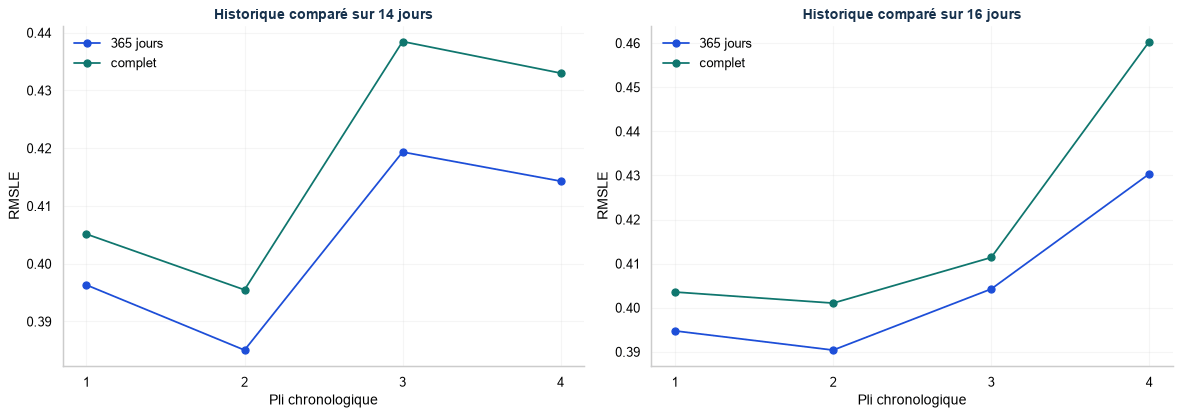

In [52]:
# Les horizons couvrent des périodes différentes : on compare les historiques
# à horizon identique. Le test Kaggle et son score ne participent pas au choix.
predictions_experiences = {(14, "365 jours"): predictions_modele}
for horizon, historique, etiquette in [(14, None, "complet"), (16, 365, "365 jours"), (16, None, "complet")]:
    predictions, _, _ = executer_backtest(horizon, historique)
    predictions_experiences[(horizon, etiquette)] = predictions

lignes_experiences = []
for (horizon, historique), predictions in predictions_experiences.items():
    for pli, frame in predictions.groupby("pli"):
        for methode, colonne in METHODES.items():
            lignes_experiences.append({
                "horizon_jours": horizon, "historique": historique, "pli": pli, "methode": methode,
                **calculer_metriques(frame, colonne),
            })
scores_experiences = pd.DataFrame(lignes_experiences)
resume_experiences = (
    scores_experiences.groupby(["horizon_jours", "historique", "methode"], as_index=False)
    .agg(RMSLE=("RMSLE", "mean"), RMSLE_ecart_type=("RMSLE", "std"),
         MAE=("MAE", "mean"), WAPE=("WAPE", "mean"))
)
afficher_tableau(resume_experiences.round(4))
comparaison_historiques = (
    scores_experiences.loc[scores_experiences["methode"].eq("LightGBM récursif")]
    .pivot(index=["horizon_jours", "pli"], columns="historique", values="RMSLE")
)
comparaison_historiques["ecart_complet_moins_recent"] = (
    comparaison_historiques["complet"] - comparaison_historiques["365 jours"]
)
afficher_tableau(comparaison_historiques.round(4))

# Choix fondé sur l'horizon métier de 14 jours ; 16 jours sert de contrôle complémentaire.
classement_14j = resume_experiences.loc[
    resume_experiences["horizon_jours"].eq(14)
    & resume_experiences["methode"].eq("LightGBM récursif")
].sort_values(["RMSLE", "historique"])
HISTORIQUE_RETENU = classement_14j.iloc[0]["historique"]
print(f"Historique retenu par le RMSLE moyen local à 14 jours : {HISTORIQUE_RETENU}")
print("Le réentraînement final utilisera automatiquement cet historique et les mêmes variables.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, horizon in zip(axes, (14, 16)):
    vue = scores_experiences.loc[
        scores_experiences["horizon_jours"].eq(horizon)
        & scores_experiences["methode"].eq("LightGBM récursif")
    ]
    for historique, frame in vue.groupby("historique"):
        ax.plot(frame["pli"], frame["RMSLE"], marker="o", label=historique)
    ax.set_title(f"Historique comparé sur {horizon} jours", color=BLEU, fontweight="bold")
    ax.set_xlabel("Pli chronologique")
    ax.set_ylabel("RMSLE")
    ax.set_xticks(range(1, N_FOLDS + 1))
    ax.legend()
plt.tight_layout()
plt.show()


In [53]:
HISTORIQUE_JOURS_FINAL = 365 if HISTORIQUE_RETENU == "365 jours" else None
score_recent = classement_14j.loc[classement_14j["historique"].eq("365 jours"), "RMSLE"].iloc[0]
score_complet = classement_14j.loc[classement_14j["historique"].eq("complet"), "RMSLE"].iloc[0]
lecture(f"À 14 jours, le RMSLE moyen vaut {score_recent:.4f} pour 365 jours et {score_complet:.4f} pour l’historique complet. La fenêtre retenue est {HISTORIQUE_RETENU}. La comparaison par pli ci-dessus indique la stabilité de ce choix ; le score Kaggle ne participe pas à la sélection.")
# Si les données évoluent et qu’un autre historique gagne, toutes les analyses suivantes suivent ce choix.
predictions_modele = predictions_experiences[(14, HISTORIQUE_RETENU)].copy()
scores_selection = scores_experiences.loc[scores_experiences["horizon_jours"].eq(14) & scores_experiences["historique"].eq(HISTORIQUE_RETENU)]
scores_par_pli = scores_selection.rename(columns={"methode": "méthode"})
scores_moyens = scores_par_pli.groupby("méthode", as_index=False)[["MAE", "RMSLE", "WAPE"]].mean()


<a id="section-19"></a>

<h2 style="color:#2563EB; font-weight:700;">19. Évaluation et analyse des erreurs</h2>

**Question :** Où le modèle progresse-t-il et où reste-t-il moins précis ?

<h3 style="color:#2563EB; font-weight:700;">19.1. Comparaison globale et importance des variables</h3>

**Question :** Les scores et les variables utiles sont-ils cohérents avec le problème ?

<h3 style="color:#2563EB; font-weight:700;">Vue de synthèse · Précision et choix de l’historique</h3>

Cette figure résume les points de lecture ; les analyses détaillées suivent.

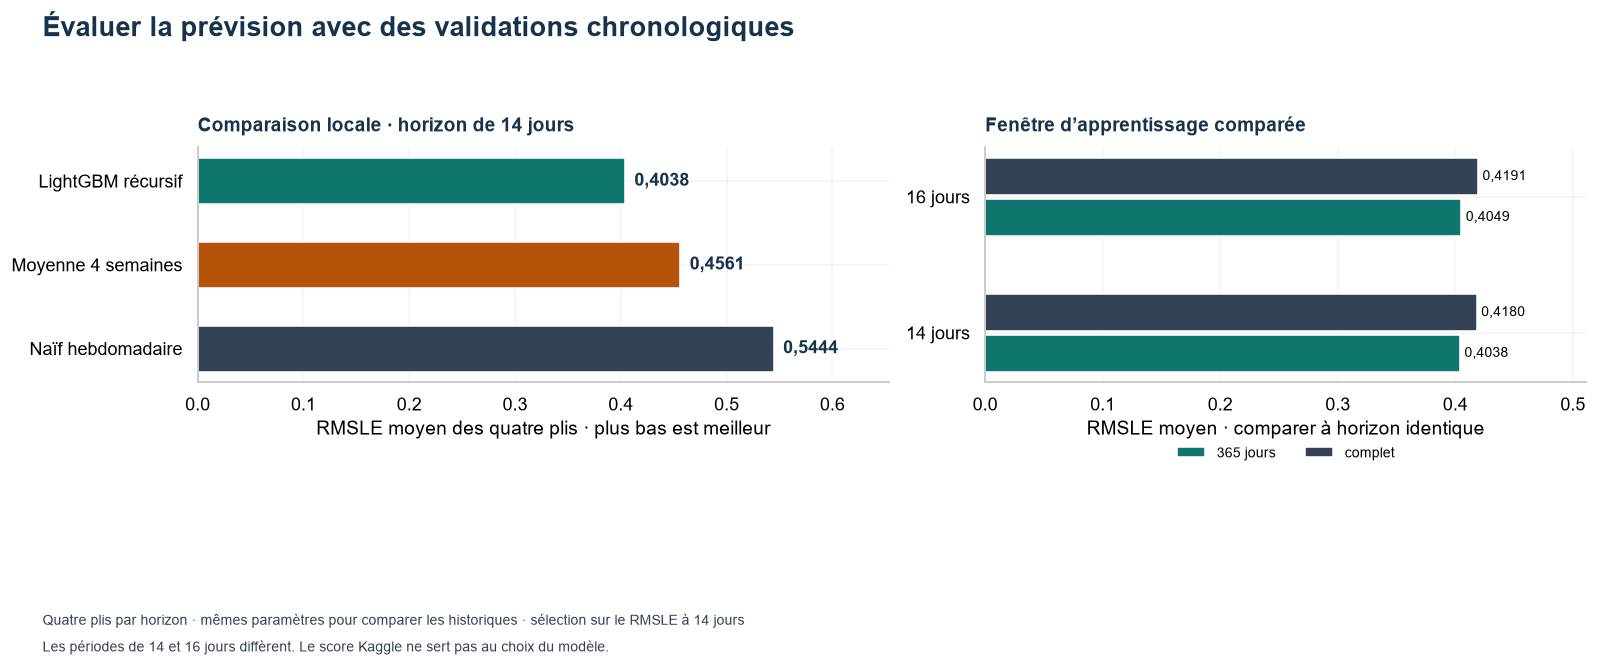

In [54]:
scores_synthese = scores_moyens.sort_values("RMSLE", ascending=False)
libelles_methodes = {"Naïf saisonnier hebdomadaire": "Naïf hebdomadaire", "Moyenne des 4 semaines par jour": "Moyenne 4 semaines", "LightGBM récursif": "LightGBM récursif"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), dpi=115, gridspec_kw={"width_ratios": [1.15, 1]})
axes[0].barh(scores_synthese["méthode"].map(libelles_methodes), scores_synthese["RMSLE"], color=scores_synthese["méthode"].map(PALETTE), height=.55)
axes[0].set_xlim(0, scores_synthese["RMSLE"].max() * 1.2)
for pos, value in enumerate(scores_synthese["RMSLE"]):
    axes[0].text(value + .009, pos, f"{value:.4f}".replace(".", ","), va="center", fontsize=11, fontweight="bold", color="#17324D")
titre_visuel(axes[0], "Comparaison locale · horizon de 14 jours", "RMSLE moyen des quatre plis · plus bas est meilleur")
hist_synthese = resume_experiences.loc[resume_experiences["methode"].eq("LightGBM récursif")]
for offset, historique, color in [(-.15, "365 jours", COULEURS["prevision"]), (.15, "complet", COULEURS["baseline"])]:
    values = hist_synthese.loc[hist_synthese["historique"].eq(historique)].set_index("horizon_jours")["RMSLE"].reindex([14, 16])
    axes[1].barh(np.arange(2) + offset, values, height=.27, color=color, label=historique)
    for pos, value in zip(np.arange(2) + offset, values):
        axes[1].text(value + .004, pos, f"{value:.4f}".replace(".", ","), va="center", fontsize=9)
axes[1].set_yticks(range(2), ["14 jours", "16 jours"])
axes[1].set_xlim(0, hist_synthese["RMSLE"].max() * 1.22)
axes[1].legend(loc="upper center", bbox_to_anchor=(.5, -.22), ncol=2, fontsize=9)
titre_visuel(axes[1], "Fenêtre d’apprentissage comparée", "RMSLE moyen · comparer à horizon identique")
fig.suptitle("Évaluer la prévision avec des validations chronologiques", color=COULEUR_TITRES, fontweight="bold", fontsize=17, x=.03, ha="left", y=.99)
fig.tight_layout(rect=(0, .19, 1, .93))
fig.text(.03, .07, "Quatre plis par horizon · mêmes paramètres pour comparer les historiques · sélection sur le RMSLE à 14 jours", fontsize=9, color="#334155")
fig.text(.03, .03, "Les périodes de 14 et 16 jours diffèrent. Le score Kaggle ne sert pas au choix du modèle.", fontsize=9, color="#334155")
plt.show()
plt.close(fig)
lecture("La comparaison sépare le gain face aux baselines du choix de l’historique. Le contrôle sur 16 jours apprécie la stabilité sur d’autres dates ; il ne transforme pas la validation ayant servi au choix en test final indépendant.")


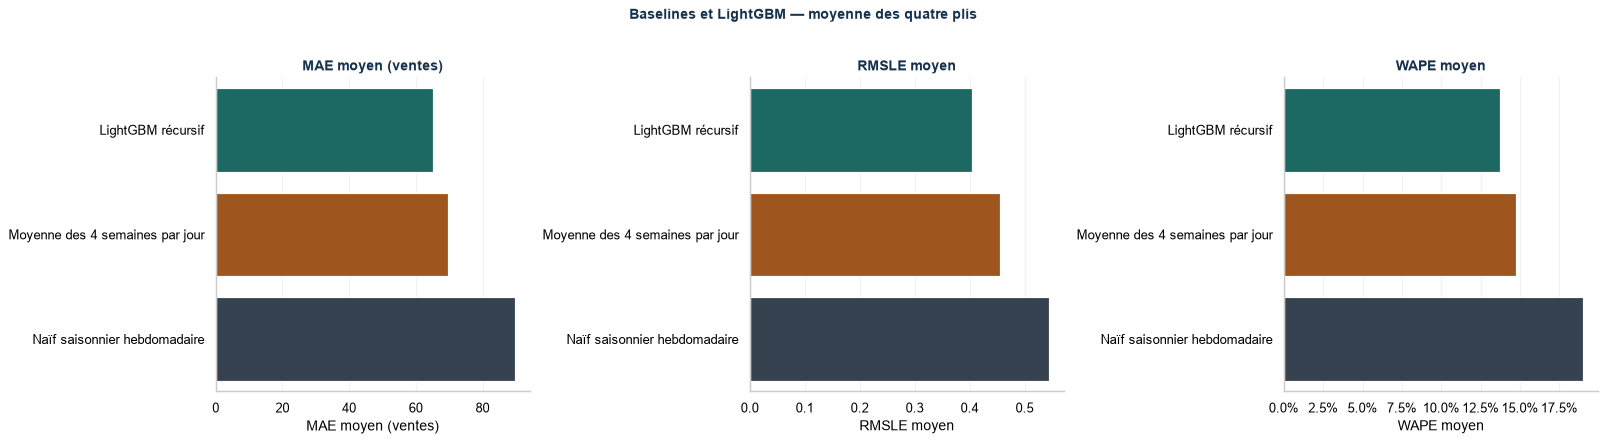

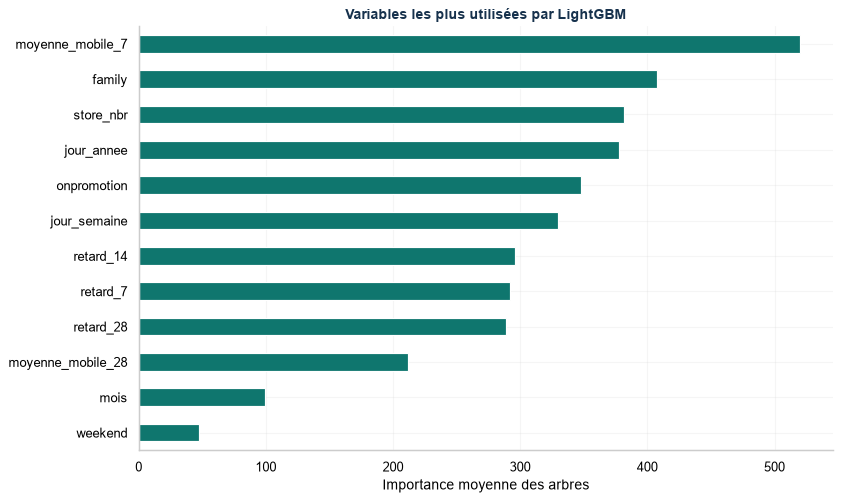

In [55]:
COULEUR_METRIQUES = {
    "Naïf saisonnier hebdomadaire": "#334155",
    "Moyenne des 4 semaines par jour": "#B45309",
    "LightGBM récursif": "#0F766E",
}
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for axe, (metrique, titre) in zip(axes, [("MAE", "MAE moyen (ventes)"), ("RMSLE", "RMSLE moyen"), ("WAPE", "WAPE moyen")]):
    sns.barplot(
        data=scores_moyens, x=metrique, y="méthode", hue="méthode",
        palette=COULEUR_METRIQUES, legend=False, ax=axe,
    )
    axe.set_title(titre, color=BLEU, fontweight="bold")
    axe.set_xlabel(titre)
    axe.set_ylabel("")
    if metrique == "WAPE":
        axe.xaxis.set_major_formatter(PercentFormatter(1))
    axe.grid(axis="x", alpha=0.25)
    axe.grid(axis="y", visible=False)
fig.suptitle("Baselines et LightGBM — moyenne des quatre plis", color=BLEU, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

importance_top = importance_moyenne.head(12).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
importance_top.plot.barh(ax=ax, color="#0F766E")
ax.set_title("Variables les plus utilisées par LightGBM", color=BLEU, fontweight="bold")
ax.set_xlabel("Importance moyenne des arbres")
ax.set_ylabel("")
sns.despine()
plt.tight_layout()
plt.show()


L’importance représente le nombre de divisions utilisées par les arbres, moyenné sur les quatre modèles récents à 14 jours. Elle ne mesure ni un effet causal ni une importance indépendante des corrélations entre variables.

<h3 style="color:#2563EB; font-weight:700;">19.2. Exemple sur une série</h3>

**Question :** Comment se comparent les prévisions à la trajectoire observée ?

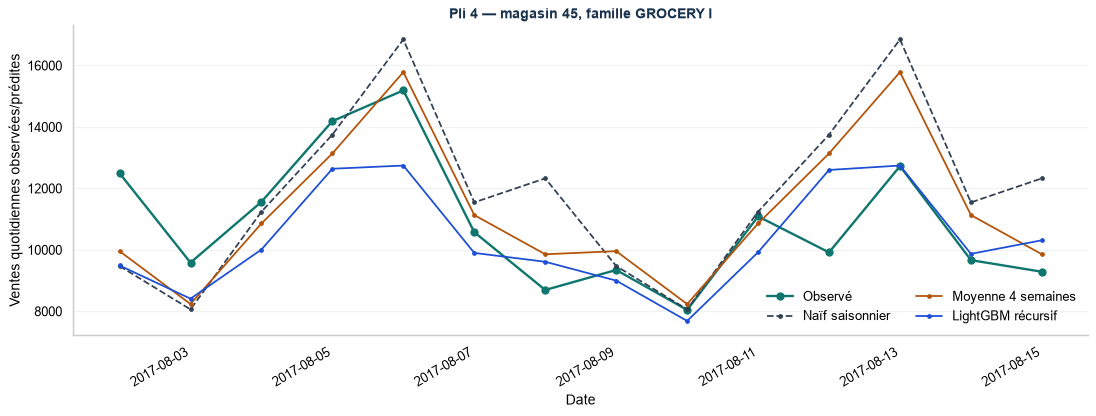

Exemple sélectionné par volume observé : magasin 45, famille GROCERY I.


In [56]:
dernier_pli = predictions_modele.loc[predictions_modele["pli"].eq(N_FOLDS)].copy()
volume_serie = dernier_pli.groupby(CLES_SERIE, observed=True)["ventes_reelles"].sum().sort_values(ascending=False)
magasin_exemple, famille_exemple = volume_serie.index[0]
serie_exemple = dernier_pli.loc[
    dernier_pli["store_nbr"].eq(magasin_exemple) & dernier_pli["family"].eq(famille_exemple)
].sort_values("date")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(serie_exemple["date"], serie_exemple["ventes_reelles"], color="#0F766E", marker="o", linewidth=2, label="Observé")
ax.plot(serie_exemple["date"], serie_exemple["pred_saisonnier"], color="#334155", linestyle="--", marker=".", label="Naïf saisonnier")
ax.plot(serie_exemple["date"], serie_exemple["pred_moyenne_4_semaines"], color="#B45309", linestyle="-", marker=".", label="Moyenne 4 semaines")
ax.plot(serie_exemple["date"], serie_exemple["pred_lightgbm"], color="#1D4ED8", linestyle="-", marker=".", label="LightGBM récursif")
ax.set_title(f"Pli {N_FOLDS} — magasin {magasin_exemple}, famille {famille_exemple}", color=BLEU, fontweight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Ventes quotidiennes observées/prédites")
ax.legend(frameon=False, ncol=2)
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
print(f"Exemple sélectionné par volume observé : magasin {magasin_exemple}, famille {famille_exemple}.")


<h3 style="color:#2563EB; font-weight:700;">19.3. Erreurs par horizon, famille et magasin</h3>

**Question :** Quels groupes concentrent les erreurs et avec quels volumes ?

Erreurs par jour dans l'horizon récursif :


jour_horizon,MAE,biais_moyen,volume_reel,observations,WAPE
1,"60,667","-32,799","3 343 151,500",7 128,"12,9%"
2,"47,658","-7,848","2 726 497,500",7 128,"12,5%"
3,"53,591","-2,484","3 177 036,000",7 128,"12,0%"
4,"55,955","5,263","3 860 211,000",7 128,"10,3%"
5,"75,428","-10,591","4 267 292,000",7 128,"12,6%"
6,"49,608","-9,301","3 173 556,000",7 128,"11,1%"
7,"52,073","13,211","2 844 101,250",7 128,"13,1%"
8,"48,377","9,093","2 955 489,750",7 128,"11,7%"
9,"55,745","12,634","2 571 700,000",7 128,"15,4%"
10,"64,999","-14,765","3 229 236,250",7 128,"14,3%"


Familles avec les WAPE les plus élevés :


,MAE,biais_moyen,volume_reel,observations,WAPE
family,,,,,
BOOKS,"0,148","0,112","67,000",3 024,"669,0%"
BABY CARE,"0,308","0,004","593,000",3 024,"156,9%"
HOME APPLIANCES,"0,470","-0,021","1 129,000",3 024,"126,0%"
HARDWARE,"1,082","-0,444","4 421,000",3 024,"74,0%"
SCHOOL AND OFFICE SUPPLIES,"12,602","-11,217","59 649,000",3 024,"63,9%"
LINGERIE,"3,433","-1,553","20 917,000",3 024,"49,6%"
MAGAZINES,"2,712","-1,099","18 978,000",3 024,"43,2%"
AUTOMOTIVE,"2,860","-1,057","21 937,000",3 024,"39,4%"
CELEBRATION,"5,184","-2,159","40 109,000",3 024,"39,1%"


Magasins avec les WAPE les plus élevés :


,MAE,biais_moyen,volume_reel,observations,WAPE
store_nbr,,,,,
32,"45,065","-22,232","271 165,062",1 848,"30,7%"
30,"59,507","-22,759","375 421,875",1 848,"29,3%"
54,"75,274","-25,209","578 279,938",1 848,"24,1%"
16,"46,258","-4,178","357 864,625",1 848,"23,9%"
26,"35,549","2,380","282 297,188",1 848,"23,3%"
14,"50,343","-5,513","452 625,719",1 848,"20,5%"
40,"101,185","-38,803","916 730,750",1 848,"20,4%"
38,"81,457","-3,662","744 734,312",1 848,"20,2%"
25,"49,564","-34,477","461 811,031",1 848,"19,8%"


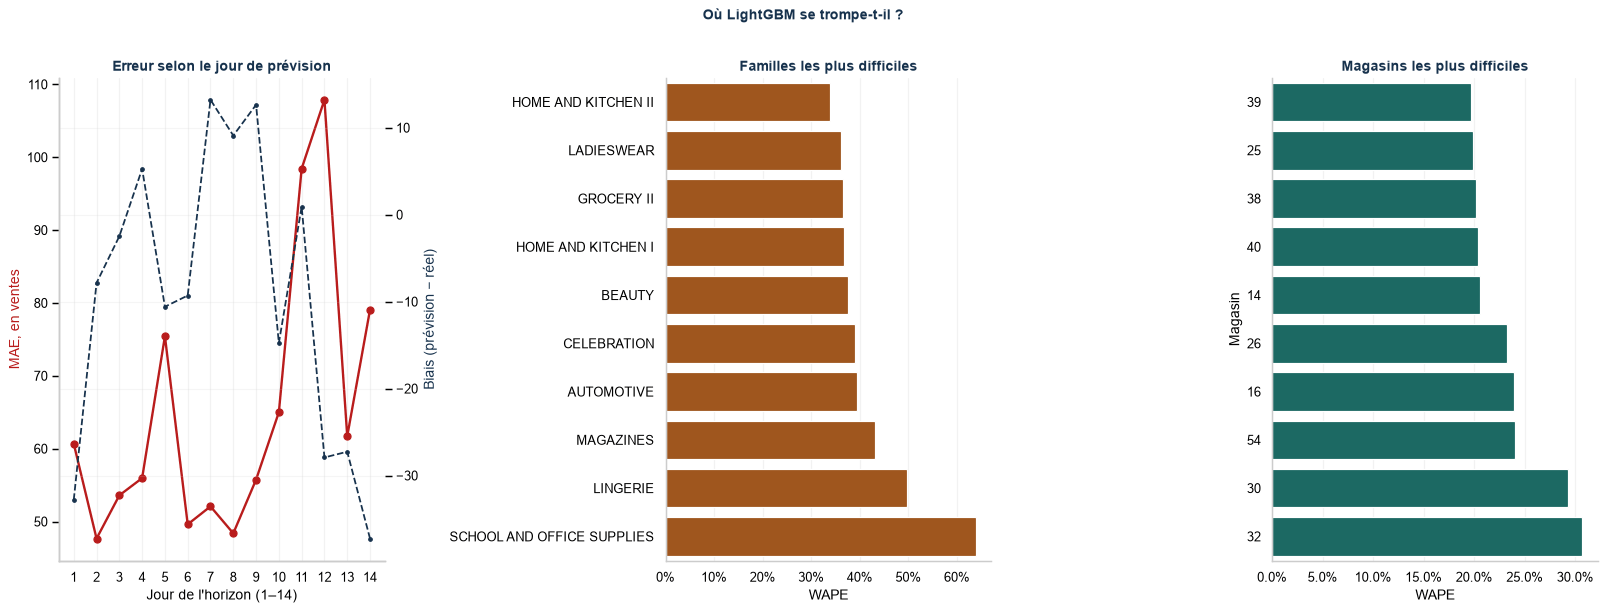

In [57]:
erreurs = predictions_modele.copy()
debut_par_pli = {pli["pli"]: pli["debut"] for pli in plis}
erreurs["debut_pli"] = erreurs["pli"].map(debut_par_pli)
erreurs["jour_horizon"] = (erreurs["date"] - erreurs["debut_pli"]).dt.days + 1
erreurs["erreur_signee"] = erreurs["pred_lightgbm"] - erreurs["ventes_reelles"]
erreurs["erreur_absolue"] = erreurs["erreur_signee"].abs()


def resume_erreurs(frame, groupe):
    resume = frame.groupby(groupe, observed=True).agg(
        MAE=("erreur_absolue", "mean"),
        biais_moyen=("erreur_signee", "mean"),
        volume_reel=("ventes_reelles", "sum"),
        observations=("ventes_reelles", "size"),
        somme_erreurs_absolues=("erreur_absolue", "sum"),
    )
    resume["WAPE"] = resume["somme_erreurs_absolues"] / resume["volume_reel"].replace(0, np.nan)
    return resume.drop(columns="somme_erreurs_absolues")


erreurs_horizon = resume_erreurs(erreurs, "jour_horizon").reset_index()
erreurs_famille = resume_erreurs(erreurs, "family").sort_values("WAPE", ascending=False)
erreurs_magasin = resume_erreurs(erreurs, "store_nbr").sort_values("WAPE", ascending=False)

print("Erreurs par jour dans l'horizon récursif :")
afficher_tableau(erreurs_horizon.round(4))
print("Familles avec les WAPE les plus élevés :")
afficher_tableau(erreurs_famille.head(10).round(4))
print("Magasins avec les WAPE les plus élevés :")
afficher_tableau(erreurs_magasin.head(10).round(4))

fig, axes = plt.subplots(1, 3, figsize=(19, 7))
axe_horizon = axes[0]
axe_horizon.plot(
    erreurs_horizon["jour_horizon"],
    erreurs_horizon["MAE"],
    color="#B91C1C",
    marker="o",
    linewidth=2,
    label="MAE",
)
axe_horizon.set_title("Erreur selon le jour de prévision", color=BLEU, fontweight="bold")
axe_horizon.set_xlabel("Jour de l'horizon (1–14)")
axe_horizon.set_ylabel("MAE, en ventes", color="#B91C1C")
axe_horizon.set_xticks(range(1, HORIZON_JOURS + 1))
axe_horizon.grid(axis="y", alpha=0.25)
axe_biais = axe_horizon.twinx()
axe_biais.plot(
    erreurs_horizon["jour_horizon"],
    erreurs_horizon["biais_moyen"],
    color=BLEU,
    linestyle="--",
    marker=".",
    label="Biais moyen",
)
axe_biais.set_ylabel("Biais (prévision − réel)", color=BLEU)

SEUIL_VOLUME_GRAPHIQUE = 10_000
familles_a_tracer = (
    erreurs_famille.loc[erreurs_famille["volume_reel"].ge(SEUIL_VOLUME_GRAPHIQUE)]
    .head(10)
    .sort_values("WAPE")
    .reset_index()
)
magasins_a_tracer = (
    erreurs_magasin.loc[erreurs_magasin["volume_reel"].ge(SEUIL_VOLUME_GRAPHIQUE)]
    .head(10)
    .sort_values("WAPE")
    .reset_index()
)

# Convertir les catégories en texte évite d'afficher les niveaux exclus du filtrage.
familles_a_tracer["family"] = familles_a_tracer["family"].astype(str)
magasins_a_tracer["store_nbr"] = magasins_a_tracer["store_nbr"].astype(str)

sns.barplot(
    data=familles_a_tracer,
    x="WAPE",
    y="family",
    color="#B45309",
    ax=axes[1],
)
axes[1].set_title("Familles les plus difficiles", color=BLEU, fontweight="bold")
axes[1].set_xlabel("WAPE")
axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(PercentFormatter(1))

sns.barplot(
    data=magasins_a_tracer,
    x="WAPE",
    y="store_nbr",
    color="#0F766E",
    ax=axes[2],
)
axes[2].set_title("Magasins les plus difficiles", color=BLEU, fontweight="bold")
axes[2].set_xlabel("WAPE")
axes[2].set_ylabel("Magasin")
axes[2].xaxis.set_major_formatter(PercentFormatter(1))

for axe in axes:
    axe.grid(axis="x", alpha=0.25)
    axe.grid(axis="y", visible=False)
fig.suptitle("Où LightGBM se trompe-t-il ?", color=BLEU, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


Comparaison par jour_horizon — écart négatif : amélioration sur la baseline


,jour_horizon,methode,volume_reel,observations,biais_moyen,MAE,RMSLE,WAPE,MAE_baseline,RMSLE_baseline,WAPE_baseline,ecart_MAE_baseline,ecart_RMSLE_baseline,ecart_WAPE_baseline
35,12,LightGBM récursif,"4 386 575,000",7 128,"-27,925","107,881","0,4257","17,5%","98,998","0,4601","0,161","8,883","-0,0344","1,4%"
41,14,LightGBM récursif,"3 313 682,500",7 128,"-37,253","79,072","0,4350","17,0%","79,214","0,4752","0,170","-0,142","-0,0402","-0,0%"
14,5,LightGBM récursif,"4 267 292,000",7 128,"-10,591","75,428","0,3823","12,6%","78,135","0,4249","0,131","-2,708","-0,0426","-0,4%"
17,6,LightGBM récursif,"3 173 556,000",7 128,"-9,301","49,608","0,3954","11,1%","56,919","0,4396","0,128","-7,311","-0,0442","-1,6%"
38,13,LightGBM récursif,"3 390 248,250",7 128,"-27,265","61,695","0,4182","13,0%","65,739","0,4630","0,138","-4,044","-0,0448","-0,9%"
20,7,LightGBM récursif,"2 844 101,250",7 128,"13,211","52,073","0,3976","13,1%","60,450","0,4435","0,151","-8,377","-0,0459","-2,1%"
32,11,LightGBM récursif,"4 001 548,500",7 128,"0,923","98,429","0,4111","17,5%","100,427","0,4615","0,179","-1,998","-0,0503","-0,4%"
11,4,LightGBM récursif,"3 860 211,000",7 128,"5,263","55,955","0,3716","10,3%","71,607","0,4224","0,132","-15,652","-0,0509","-2,9%"
8,3,LightGBM récursif,"3 177 036,000",7 128,"-2,484","53,591","0,3976","12,0%","61,371","0,4574","0,138","-7,780","-0,0598","-1,8%"
29,10,LightGBM récursif,"3 229 236,000",7 128,"-14,765","64,999","0,4197","14,3%","71,552","0,4800","0,158","-6,553","-0,0603","-1,5%"


Comparaison par family — écart négatif : amélioration sur la baseline


,family,methode,volume_reel,observations,biais_moyen,MAE,RMSLE,WAPE,MAE_baseline,RMSLE_baseline,WAPE_baseline,ecart_MAE_baseline,ecart_RMSLE_baseline,ecart_WAPE_baseline
14,BOOKS,LightGBM récursif,"67,000",3 024,"0,112","0,148","0,1533","669,0%","0,050","0,1339","2,239","0,099","0,0194","445,2%"
23,CLEANING,LightGBM récursif,"3 925 203,000",3 024,"-59,862","286,270","0,3610","22,1%","307,411","0,3531","0,237","-21,141","0,0079","-1,6%"
74,MEATS,LightGBM récursif,"1 144 508,750",3 024,"-15,327","51,376","0,2034","13,6%","49,770","0,1960","0,132","1,606","0,0074","0,4%"
86,POULTRY,LightGBM récursif,"1 175 467,250",3 024,"-14,540","51,437","0,2125","13,2%","50,937","0,2092","0,131","0,500","0,0034","0,1%"
92,PRODUCE,LightGBM récursif,"7 108 087,000",3 024,"-30,343","212,525","0,1411","9,0%","209,582","0,1420","0,089","2,943","-0,0009","0,1%"
17,BREAD/BAKERY,LightGBM récursif,"1 653 049,750",3 024,"-12,543","60,723","0,1664","11,1%","64,005","0,1675","0,117","-3,282","-0,0011","-0,6%"
26,DAIRY,LightGBM récursif,"2 645 348,000",3 024,"25,799","89,056","0,1481","10,2%","97,671","0,1517","0,112","-8,615","-0,0037","-1,0%"
89,PREPARED FOODS,LightGBM récursif,"270 078,500",3 024,"-4,863","15,415","0,2786","17,3%","15,630","0,2823","0,175","-0,215","-0,0037","-0,2%"
29,DELI,LightGBM récursif,"944 691,125",3 024,"1,732","41,790","0,1852","13,4%","44,176","0,1898","0,141","-2,386","-0,0047","-0,8%"
32,EGGS,LightGBM récursif,"597 606,000",3 024,"-6,400","36,783","0,3130","18,6%","36,056","0,3178","0,182","0,727","-0,0048","0,4%"


Comparaison par store_nbr — écart négatif : amélioration sur la baseline


,store_nbr,methode,volume_reel,observations,biais_moyen,MAE,RMSLE,WAPE,MAE_baseline,RMSLE_baseline,WAPE_baseline,ecart_MAE_baseline,ecart_RMSLE_baseline,ecart_WAPE_baseline
74,25,LightGBM récursif,"461 811,062",1 848,"-34,477","49,564","0,4626","19,8%","50,421","0,4519","0,202","-0,857","0,0107","-0,3%"
155,52,LightGBM récursif,"1 267 779,500",1 848,"-37,444","80,077","0,3743","11,7%","81,807","0,3770","0,119","-1,730","-0,0027","-0,2%"
2,1,LightGBM récursif,"577 143,125",1 848,"8,380","39,322","0,3999","12,6%","34,661","0,4054","0,111","4,661","-0,0055","1,5%"
17,6,LightGBM récursif,"968 708,438",1 848,"10,788","54,256","0,3316","10,3%","60,228","0,3494","0,115","-5,972","-0,0178","-1,1%"
125,42,LightGBM récursif,"712 662,625",1 848,"11,345","54,272","0,3598","14,1%","59,663","0,3797","0,155","-5,391","-0,0199","-1,4%"
8,3,LightGBM récursif,"2 018 203,000",1 848,"5,408","95,409","0,3104","8,7%","102,681","0,3304","0,094","-7,272","-0,0200","-0,7%"
158,53,LightGBM récursif,"654 359,438",1 848,"-0,047","43,089","0,3994","12,2%","45,011","0,4214","0,127","-1,923","-0,0220","-0,5%"
80,27,LightGBM récursif,"851 018,438",1 848,"-0,466","58,089","0,3753","12,6%","53,795","0,3979","0,117","4,294","-0,0226","0,9%"
122,41,LightGBM récursif,"755 054,188",1 848,"0,082","77,115","0,3935","18,9%","85,095","0,4174","0,208","-7,979","-0,0239","-1,9%"
119,40,LightGBM récursif,"916 730,750",1 848,"-38,803","101,185","0,4178","20,4%","106,596","0,4430","0,215","-5,411","-0,0253","-1,1%"


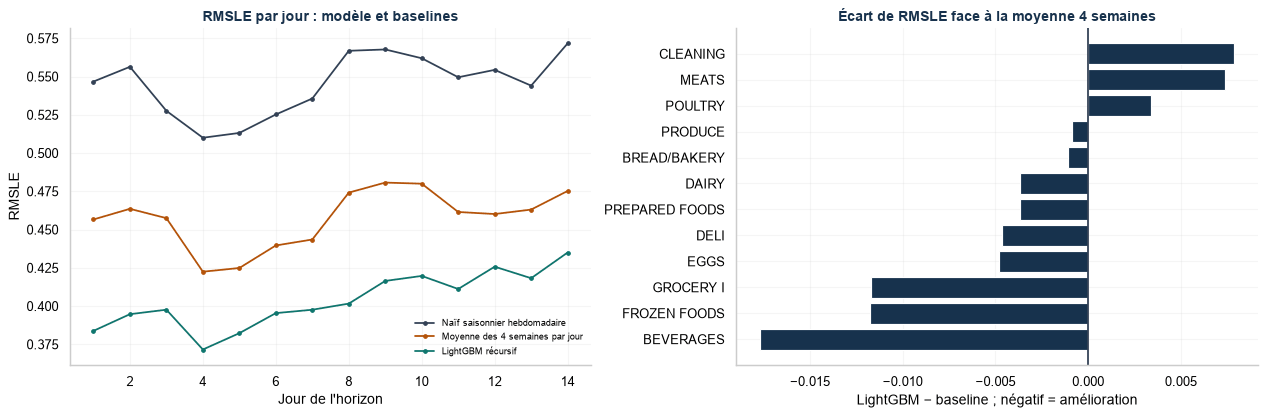

In [58]:
comparaisons_groupes = {}
for groupe in ("jour_horizon", "family", "store_nbr"):
    lignes = []
    for valeur, frame in erreurs.groupby(groupe, observed=True):
        for methode, colonne in METHODES.items():
            lignes.append({
                groupe: valeur, "methode": methode,
                "volume_reel": float(frame["ventes_reelles"].sum()),
                "observations": len(frame),
                "biais_moyen": float((frame[colonne] - frame["ventes_reelles"]).mean()),
                **calculer_metriques(frame, colonne),
            })
    comparaison = pd.DataFrame(lignes)
    reference = comparaison.loc[
        comparaison["methode"].eq("Moyenne des 4 semaines par jour"),
        [groupe, "MAE", "RMSLE", "WAPE"],
    ].rename(columns={m: f"{m}_baseline" for m in ("MAE", "RMSLE", "WAPE")})
    comparaison = comparaison.merge(reference, on=groupe, validate="many_to_one")
    for m in ("MAE", "RMSLE", "WAPE"):
        comparaison[f"ecart_{m}_baseline"] = comparaison[m] - comparaison[f"{m}_baseline"]
    comparaisons_groupes[groupe] = comparaison
    print(f"Comparaison par {groupe} — écart négatif : amélioration sur la baseline")
    vue = comparaison.loc[comparaison["methode"].eq("LightGBM récursif")]
    afficher_tableau(vue.sort_values("ecart_RMSLE_baseline", ascending=False).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for methode, frame in comparaisons_groupes["jour_horizon"].groupby("methode", sort=False):
    axes[0].plot(frame["jour_horizon"], frame["RMSLE"], marker=".", label=methode, color=PALETTE[methode])
axes[0].set_title("RMSLE par jour : modèle et baselines", color=BLEU, fontweight="bold")
axes[0].set_xlabel("Jour de l'horizon")
axes[0].set_ylabel("RMSLE")
axes[0].legend(fontsize=8)
vue_familles = comparaisons_groupes["family"]
vue_familles = vue_familles.loc[
    vue_familles["methode"].eq("LightGBM récursif")
    & vue_familles["volume_reel"].ge(SEUIL_VOLUME_GRAPHIQUE)
].sort_values("ecart_RMSLE_baseline", ascending=False).head(12)
axes[1].barh(vue_familles["family"].astype(str), vue_familles["ecart_RMSLE_baseline"], color=BLEU)
axes[1].axvline(0, color="#334155")
axes[1].invert_yaxis()
axes[1].set_title("Écart de RMSLE face à la moyenne 4 semaines", color=BLEU, fontweight="bold")
axes[1].set_xlabel("LightGBM − baseline ; négatif = amélioration")
plt.tight_layout()
plt.show()


In [59]:
if "BOOKS" in erreurs_famille.index:
    print("Famille BOOKS : lire la métrique avec son volume")
    afficher_tableau(erreurs_famille.loc[["BOOKS"]])
lecture("Un WAPE très élevé peut provenir d’un volume réel très faible. Les tableaux conservent les volumes, les effectifs, la MAE et le RMSLE. Les écarts négatifs face à la baseline indiquent une amélioration sur la métrique concernée, pas une supériorité universelle.")


Famille BOOKS : lire la métrique avec son volume


,MAE,biais_moyen,volume_reel,observations,WAPE
family,,,,,
BOOKS,"0,148","0,112","67,000",3 024,"669,0%"


<hr>

<p style="color:#2563EB; font-size:13px; letter-spacing:1px;"><strong>PARTIE 05 · SIMULER</strong></p>

Relier les prévisions à un compromis de service et de stock sous hypothèses.

<a id="section-20"></a>

<h2 style="color:#2563EB; font-weight:700;">20. Simulation de stock</h2>

**Question :** Comment les prévisions se traduisent-elles en service et stock dans un scénario hypothétique ?

Aucun stock réel, rupture observée, délai fournisseur ou coût réel n’est disponible. Les ventes observées servent de proxy de demande ; aucune économie réelle ne peut être affirmée.


<table style="border-collapse:collapse; width:100%; background-color:#F3F4F6; color:#000000;">
<thead>
<tr>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Hypothèse</th>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Fonctionnement</th>
</tr>
</thead>
<tbody>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Stock initial</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Ventes moyennes des 28 jours précédents × couverture initiale × facteur</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Commande</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Une commande décidée à l’origine, selon les prévisions disponibles</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Livraison</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Au début du jour d’indice <code style="background-color:transparent; color:#000000;">delai_jours</code> : un délai de 7 jours arrive au huitième jour de l’horizon</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Ventes non servies</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Perdues dans le scénario ; aucun report de demande</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Comparaison</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Mêmes ventes, stock initial et délai pour les trois méthodes</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Stock moyen</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Mesuré à la fin de chaque journée</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Sensibilité</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Délais de 5, 7 et 10 jours ; facteurs de stock initial ; comparaison à stock initial fixé à 7 jours</td>
</tr>
</tbody>
</table>

Chaque pli repart de son propre stock initial. Les assertions vérifient la conservation des quantités et l’absence de stock négatif.

In [60]:
METHODES_STOCK = {
    "Naïf saisonnier hebdomadaire": "pred_saisonnier",
    "Moyenne des 4 semaines par jour": "pred_moyenne_4_semaines",
    "LightGBM récursif": "pred_lightgbm",
}
SCENARIOS_STOCK = [
    ("Stock proportionnel au délai", delai, facteur, delai)
    for delai, facteur in [(5, 1.0), (7, 0.75), (7, 1.0), (7, 1.25), (10, 1.0)]
] + [("Stock initial fixe à 7 jours", delai, 1.0, 7) for delai in (5, 7, 10)]
COLONNES_JOURS = range(1, HORIZON_JOURS + 1)
DEBUTS_PLIS = {pli["pli"]: pli["debut"] for pli in plis}

predictions_simulation = predictions_modele.copy()
predictions_simulation["jour_horizon"] = (
    predictions_simulation["date"]
    - predictions_simulation["pli"].map(DEBUTS_PLIS)
).dt.days + 1
assert predictions_simulation["jour_horizon"].between(1, HORIZON_JOURS).all()

resultats_simulation = []
for numero_pli, frame_pli in predictions_simulation.groupby("pli", sort=True):
    debut_pli = DEBUTS_PLIS[numero_pli]
    historique_28j = donnees.loc[
        donnees["date"].ge(debut_pli - pd.Timedelta(days=28))
        & donnees["date"].lt(debut_pli)
    ]
    series = frame_pli[CLES_SERIE].drop_duplicates().sort_values(CLES_SERIE)
    index_series = pd.MultiIndex.from_frame(series)
    stock_reference = (
        historique_28j.groupby(CLES_SERIE, observed=True)["sales"]
        .mean()
        .reindex(index_series)
        .to_numpy(dtype=float)
    )
    if np.isnan(stock_reference).any():
        raise ValueError(f"Stock initial de référence absent pour le pli {numero_pli}.")

    reel = (
        frame_pli.pivot(index=CLES_SERIE, columns="jour_horizon", values="ventes_reelles")
        .reindex(index=index_series, columns=COLONNES_JOURS)
        .to_numpy(dtype=float)
    )

    for nom_methode, colonne_prediction in METHODES_STOCK.items():
        previsions = (
            frame_pli.pivot(index=CLES_SERIE, columns="jour_horizon", values=colonne_prediction)
            .reindex(index=index_series, columns=COLONNES_JOURS)
            .to_numpy(dtype=float)
        )
        if np.isnan(previsions).any():
            raise ValueError(f"Prévisions manquantes : pli {numero_pli}, méthode {nom_methode}.")

        for protocole_stock, delai_jours, facteur_stock, couverture_initiale_jours in SCENARIOS_STOCK:
            stock_initial = stock_reference * couverture_initiale_jours * facteur_stock
            demande_prevue_avant_livraison = previsions[:, :delai_jours].sum(axis=1)
            demande_prevue_apres_livraison = previsions[:, delai_jours:].sum(axis=1)
            stock_restant_prevu = np.maximum(stock_initial - demande_prevue_avant_livraison, 0)
            quantite_commandee = np.maximum(demande_prevue_apres_livraison - stock_restant_prevu, 0)

            stock = stock_initial.copy()
            demande_totale = 0.0
            ventes_servies = 0.0
            ventes_non_servies = 0.0
            stock_jours = 0.0
            for jour_index in range(HORIZON_JOURS):
                if jour_index == delai_jours:
                    stock += quantite_commandee
                demande_jour = reel[:, jour_index]
                servi_jour = np.minimum(stock, demande_jour)
                demande_totale += demande_jour.sum()
                ventes_servies += servi_jour.sum()
                ventes_non_servies += (demande_jour - servi_jour).sum()
                stock -= servi_jour
                stock_jours += stock.sum()

            assert np.all(stock >= -1e-8), "Stock négatif."
            assert np.isclose(ventes_servies + ventes_non_servies, demande_totale)
            assert np.isclose(stock_initial.sum() + quantite_commandee.sum() - ventes_servies, stock.sum())
            resultats_simulation.append(
                {
                    "pli": numero_pli,
                    "protocole_stock": protocole_stock,
                    "methode": nom_methode,
                    "delai_jours": delai_jours,
                    "facteur_stock_initial": facteur_stock,
                    "couverture_initiale_jours": couverture_initiale_jours,
                    "demande_observee": demande_totale,
                    "ventes_servies": ventes_servies,
                    "ventes_non_servies": ventes_non_servies,
                    "taux_service": ventes_servies / demande_totale if demande_totale else np.nan,
                    "quantite_commandee": quantite_commandee.sum(),
                    "stock_moyen_fin_jour_par_serie": stock_jours / (len(series) * HORIZON_JOURS),
                    "stock_final": stock.sum(),
                }
            )

resultats_stock = pd.DataFrame(resultats_simulation)
print(f"Scénarios évalués : {len(resultats_stock):,} (méthode × pli × hypothèse)")
print("Résultats détaillés, par pli :")
afficher_tableau(resultats_stock)


Scénarios évalués : 96 (méthode × pli × hypothèse)
Résultats détaillés, par pli :


pli,protocole_stock,methode,delai_jours,facteur_stock_initial,couverture_initiale_jours,demande_observee,ventes_servies,ventes_non_servies,taux_service,quantite_commandee,stock_moyen_fin_jour_par_serie,stock_final
1,Stock proportionnel au délai,Naïf saisonnier hebdomadaire,5,"100,0%",5,"12 056 936,748","11 464 131,528","592 805,221","95,1%","7 306 646,121","1 724,175","237 078,570"
1,Stock proportionnel au délai,Naïf saisonnier hebdomadaire,7,"75,0%",7,"12 056 936,748","10 432 375,225","1 624 561,523","86,5%","5 917 798,199","1 185,539","99 715,150"
1,Stock proportionnel au délai,Naïf saisonnier hebdomadaire,7,"100,0%",7,"12 056 936,748","11 506 516,137","550 420,611","95,4%","5 611 258,510","1 631,221","257 131,941"
1,Stock proportionnel au délai,Naïf saisonnier hebdomadaire,7,"125,0%",7,"12 056 936,748","11 521 298,697","535 638,052","95,6%","4 148 293,431","2 073,859","317 481,695"
1,Stock proportionnel au délai,Naïf saisonnier hebdomadaire,10,"100,0%",10,"12 056 936,748","11 501 595,599","555 341,149","95,4%","2 967 238,984","2 007,098","254 771,339"
1,Stock initial fixe à 7 jours,Naïf saisonnier hebdomadaire,5,"100,0%",7,"12 056 936,748","11 520 062,928","536 873,821","95,5%","5 681 706,805","2 096,551","314 033,445"
1,Stock initial fixe à 7 jours,Naïf saisonnier hebdomadaire,7,"100,0%",7,"12 056 936,748","11 506 516,137","550 420,611","95,4%","5 611 258,510","1 631,221","257 131,941"
1,Stock initial fixe à 7 jours,Naïf saisonnier hebdomadaire,10,"100,0%",7,"12 056 936,748","9 739 453,003","2 317 483,745","80,8%","3 637 157,563","1 010,289","50 094,129"
1,Stock proportionnel au délai,Moyenne des 4 semaines par jour,5,"100,0%",5,"12 056 936,748","11 730 032,306","326 904,442","97,3%","7 702 545,960","1 850,196","367 077,631"
1,Stock proportionnel au délai,Moyenne des 4 semaines par jour,7,"75,0%",7,"12 056 936,748","10 656 625,600","1 400 311,148","88,4%","6 152 389,583","1 238,155","110 056,158"


Résumé par hypothèse et méthode :


scenario,methode,taux_service,ventes_non_servies,quantite_commandee,stock_moyen_fin_jour_par_serie,stock_final
Stock initial fixe à 7 jours | délai 5 j | stock initial 100%,LightGBM récursif,"95,5%","2 124 067,091","22 298 001,698","1 932,115","1 216 661,585"
Stock initial fixe à 7 jours | délai 5 j | stock initial 100%,Moyenne des 4 semaines par jour,"97,2%","1 304 681,787","24 034 918,284","2 076,340","2 134 192,867"
Stock initial fixe à 7 jours | délai 5 j | stock initial 100%,Naïf saisonnier hebdomadaire,"96,7%","1 553 804,910","24 668 522,318","2 137,215","3 016 920,023"
Stock initial fixe à 7 jours | délai 7 j | stock initial 100%,LightGBM récursif,"95,2%","2 288 061,170","22 160 739,279","1 514,951","1 243 393,245"
Stock initial fixe à 7 jours | délai 7 j | stock initial 100%,Moyenne des 4 semaines par jour,"97,0%","1 437 864,293","24 034 917,976","1 634,282","2 267 375,065"
Stock initial fixe à 7 jours | délai 7 j | stock initial 100%,Naïf saisonnier hebdomadaire,"95,8%","1 962 674,275","23 689 378,105","1 618,428","2 446 645,176"
Stock initial fixe à 7 jours | délai 10 j | stock initial 100%,LightGBM récursif,"80,0%","9 464 610,479","14 429 203,290","968,965","688 406,565"
Stock initial fixe à 7 jours | délai 10 j | stock initial 100%,Moyenne des 4 semaines par jour,"80,6%","9 162 774,057","15 001 493,474","987,971","958 860,327"
Stock initial fixe à 7 jours | délai 10 j | stock initial 100%,Naïf saisonnier hebdomadaire,"80,2%","9 352 166,264","15 538 623,779","1 012,480","1 685 382,839"
Stock proportionnel au délai | délai 5 j | stock initial 100%,LightGBM récursif,"94,7%","2 485 268,205","28 837 345,553","1 632,115","1 250 087,064"


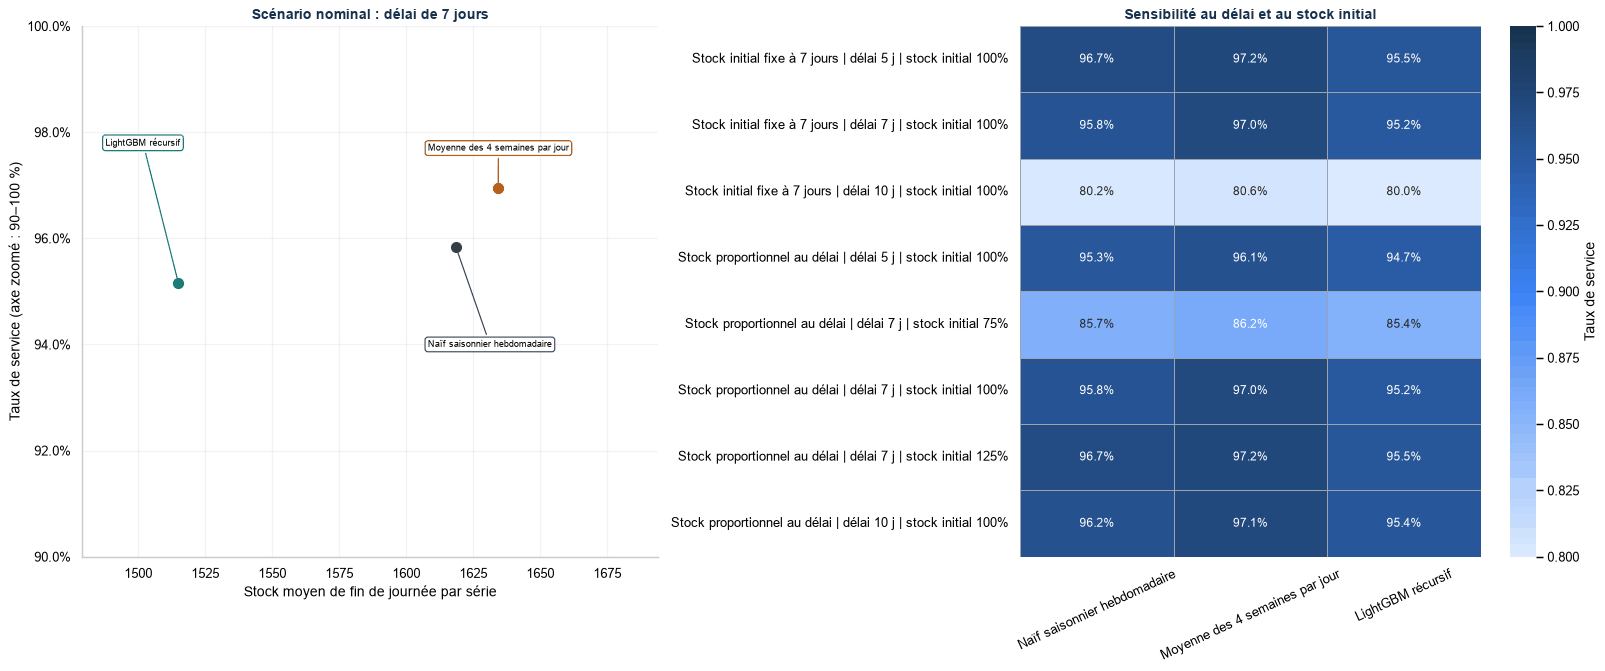

Service nominal simulé : baseline 97.0%, LightGBM 95.2%.
Commande totale : baseline 24,034,918, LightGBM 22,160,739.
Stock moyen de fin de journée : baseline 1,634.3, LightGBM 1,515.0.
Le service doit être lu avec les commandes et le stock : aucun classement opérationnel général n'en découle.


In [61]:
resume_scenarios = (
    resultats_stock.groupby(
        ["protocole_stock", "delai_jours", "facteur_stock_initial", "methode"],
        as_index=False,
        observed=True,
    )
    .agg(
        demande_observee=("demande_observee", "sum"),
        ventes_servies=("ventes_servies", "sum"),
        ventes_non_servies=("ventes_non_servies", "sum"),
        quantite_commandee=("quantite_commandee", "sum"),
        stock_moyen_fin_jour_par_serie=("stock_moyen_fin_jour_par_serie", "mean"),
        stock_final=("stock_final", "sum"),
    )
)
resume_scenarios["taux_service"] = (
    resume_scenarios["ventes_servies"] / resume_scenarios["demande_observee"]
)
resume_scenarios["scenario"] = resume_scenarios.apply(
    lambda ligne: f"{ligne['protocole_stock']} | délai {ligne['delai_jours']} j | stock initial {ligne['facteur_stock_initial']:.0%}",
    axis=1,
)
print("Résumé par hypothèse et méthode :")
afficher_tableau(
    resume_scenarios[
        [
            "scenario",
            "methode",
            "taux_service",
            "ventes_non_servies",
            "quantite_commandee",
            "stock_moyen_fin_jour_par_serie",
            "stock_final",
        ]
    ].round(3)
)

SCENARIO_NOMINAL = resume_scenarios.loc[
    resume_scenarios["protocole_stock"].eq("Stock proportionnel au délai")
    & resume_scenarios["delai_jours"].eq(7)
    & resume_scenarios["facteur_stock_initial"].eq(1.0)
].copy()

fig, axes = plt.subplots(1, 2, figsize=(19, 8))
positions_etiquettes = {
    "LightGBM récursif": (0.04, 0.78),
    "Naïf saisonnier hebdomadaire": (0.60, 0.40),
    "Moyenne des 4 semaines par jour": (0.60, 0.77),
}
for ligne in SCENARIO_NOMINAL.itertuples(index=False):
    couleur = PALETTE[ligne.methode]
    axes[0].scatter(
        ligne.stock_moyen_fin_jour_par_serie,
        ligne.taux_service,
        color=couleur,
        s=110,
        edgecolor="white",
        linewidth=1,
        zorder=3,
    )
    axes[0].annotate(
        ligne.methode,
        xy=(ligne.stock_moyen_fin_jour_par_serie, ligne.taux_service),
        xycoords="data",
        xytext=positions_etiquettes[ligne.methode],
        textcoords="axes fraction",
        fontsize=8,
        ha="left",
        va="center",
        bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": couleur, "alpha": 0.95},
        arrowprops={"arrowstyle": "-", "color": couleur, "lw": 1},
    )
axes[0].set_title("Scénario nominal : délai de 7 jours", color=BLEU, fontweight="bold")
axes[0].set_xlabel("Stock moyen de fin de journée par série")
axes[0].set_ylabel("Taux de service (axe zoomé : 90–100 %)")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylim(min(0.90, SCENARIO_NOMINAL["taux_service"].min() - 0.02), 1.0)
valeurs_stock = SCENARIO_NOMINAL["stock_moyen_fin_jour_par_serie"]
amplitude = max(valeurs_stock.max() - valeurs_stock.min(), 1)
axes[0].set_xlim(valeurs_stock.min() - 0.3 * amplitude, valeurs_stock.max() + 0.5 * amplitude)
axes[0].grid(alpha=0.25)

sensibilite = resume_scenarios.pivot(
    index="scenario", columns="methode", values="taux_service"
)
ordre_scenarios = resume_scenarios.drop_duplicates("scenario")["scenario"].tolist()
sensibilite = sensibilite.reindex(index=ordre_scenarios)
sensibilite = sensibilite[[nom for nom in METHODES_STOCK if nom in sensibilite.columns]]
sns.heatmap(
    sensibilite,
    annot=True,
    fmt=".1%",
    cmap=CMAP_SEQUENTIELLE, linecolor="#9CA3AF",
    vmin=0.8,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Taux de service"},
    ax=axes[1],
)
axes[1].set_title("Sensibilité au délai et au stock initial", color=BLEU, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

baseline_stock = SCENARIO_NOMINAL.loc[
    SCENARIO_NOMINAL["methode"].eq("Moyenne des 4 semaines par jour")
].iloc[0]
modele_stock = SCENARIO_NOMINAL.loc[SCENARIO_NOMINAL["methode"].eq("LightGBM récursif")].iloc[0]
print(f"Service nominal simulé : baseline {baseline_stock['taux_service']:.1%}, LightGBM {modele_stock['taux_service']:.1%}.")
print(f"Commande totale : baseline {baseline_stock['quantite_commandee']:,.0f}, LightGBM {modele_stock['quantite_commandee']:,.0f}.")
print(f"Stock moyen de fin de journée : baseline {baseline_stock['stock_moyen_fin_jour_par_serie']:,.1f}, LightGBM {modele_stock['stock_moyen_fin_jour_par_serie']:,.1f}.")
print("Le service doit être lu avec les commandes et le stock : aucun classement opérationnel général n'en découle.")


<h3 style="color:#2563EB; font-weight:700;">Vue de synthèse · Lire service, commande et stock ensemble</h3>

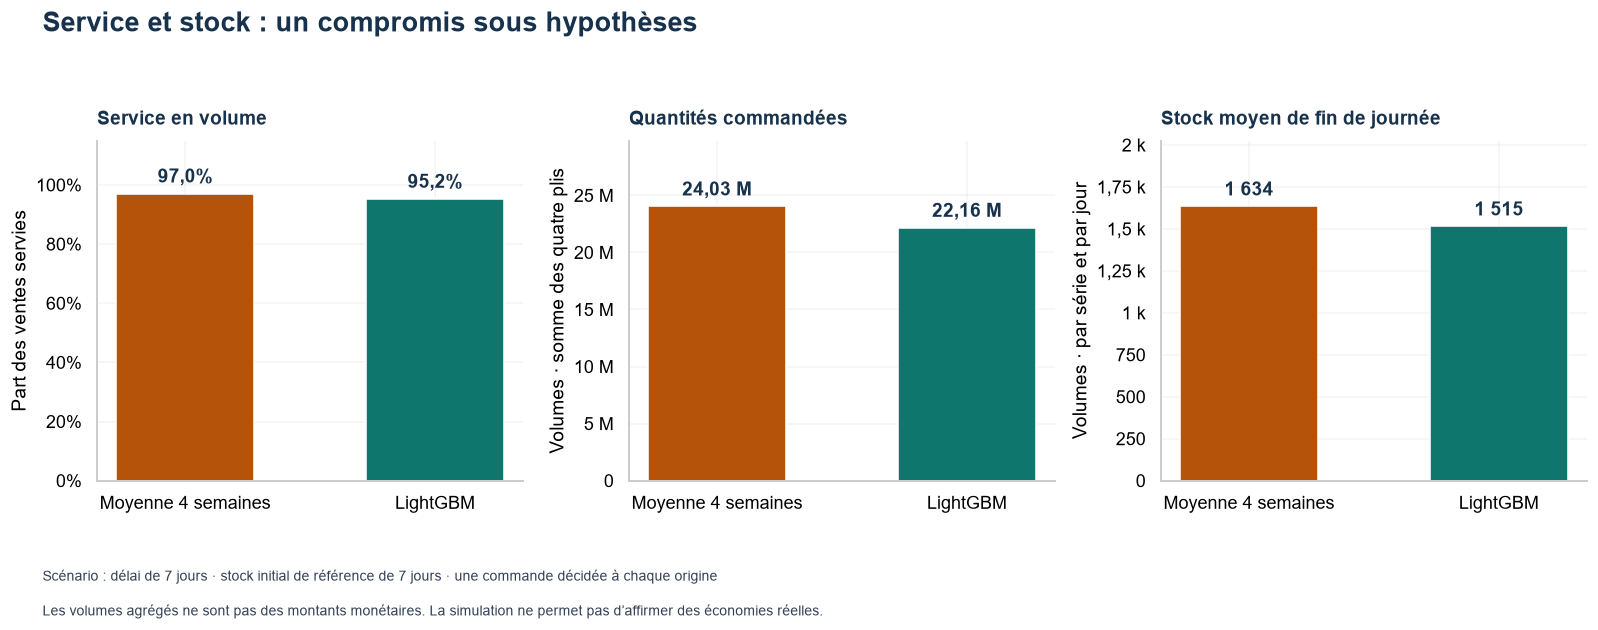

In [62]:
comparaison_stock_synthese = SCENARIO_NOMINAL.loc[SCENARIO_NOMINAL["methode"].isin(["Moyenne des 4 semaines par jour", "LightGBM récursif"])].set_index("methode").reindex(["Moyenne des 4 semaines par jour", "LightGBM récursif"])
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5), dpi=115)
short_names = ["Moyenne 4 semaines", "LightGBM"]
for ax, variable, title, ylabel in zip(axes, ["taux_service", "quantite_commandee", "stock_moyen_fin_jour_par_serie"], ["Service en volume", "Quantités commandées", "Stock moyen de fin de journée"], ["Part des ventes servies", "Volumes · somme des quatre plis", "Volumes · par série et par jour"]):
    values = comparaison_stock_synthese[variable]
    ax.bar(short_names, values, color=[COULEURS["promotion"], COULEURS["prevision"]], width=.55)
    if variable == "taux_service":
        ax.set_ylim(0, 1.15)
        ax.set_yticks(np.arange(0, 1.01, .2))
        ax.yaxis.set_major_formatter(PercentFormatter(1))
    else:
        ax.set_ylim(0, values.max() * 1.24)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(formater_volume))
    for pos, value in enumerate(values):
        label = f"{value:.1%}" if variable == "taux_service" else (f"{value / 1e6:.2f} M" if variable == "quantite_commandee" else f"{value:,.0f}".replace(",", " "))
        ax.text(pos, value + values.max() * .04, label.replace(".", ","), ha="center", fontsize=12, fontweight="bold", color="#17324D")
    titre_visuel(ax, title, ylabel=ylabel)
fig.suptitle("Service et stock : un compromis sous hypothèses", color=COULEUR_TITRES, fontweight="bold", fontsize=17, x=.03, ha="left", y=.99)
fig.tight_layout(rect=(0, .17, 1, .93))
fig.text(.03, .09, "Scénario : délai de 7 jours · stock initial de référence de 7 jours · une commande décidée à chaque origine", fontsize=9, color="#334155")
fig.text(.03, .035, "Les volumes agrégés ne sont pas des montants monétaires. La simulation ne permet pas d’affirmer des économies réelles.", fontsize=9, color="#334155")
plt.show()
plt.close(fig)
lecture("Dans le scénario de référence, LightGBM commande et conserve moins de stock, avec un service simulé légèrement inférieur. La décision dépendrait de délais, de stocks et de coûts réels qui ne sont pas disponibles ici.")


Le service doit être lu avec la quantité commandée et le stock restant. Une méthode commandant davantage peut obtenir un meilleur service dans ce scénario. Les unités agrégées de familles différentes ne sont ni des euros ni une mesure de capacité d’entrepôt.

<hr>

<p style="color:#2563EB; font-size:13px; letter-spacing:1px;"><strong>PARTIE 06 · RESTITUER</strong></p>

Contrôler la soumission et distinguer résultats, limites et pistes futures.

<a id="section-21"></a>

<h2 style="color:#2563EB; font-weight:700;">21. Prévisions finales et soumission Kaggle</h2>

**Question :** Comment produire une soumission conforme sans utiliser les ventes inconnues du test ?

Le modèle final est entraîné sur la fenêtre choisie localement. Le notebook contrôle les identifiants et les prévisions, mais il ne contacte pas Kaggle et ne mesure aucune erreur individuelle sur le test.

<h3 style="color:#2563EB; font-weight:700;">21.1. Contrôles du test et du gabarit</h3>

**Question :** Les 16 jours et les identifiants attendus sont-ils cohérents ?

In [63]:
assert list(sample_submission.columns) == ["id", "sales"]
assert test["id"].is_unique and sample_submission["id"].is_unique
assert len(test) == len(sample_submission) == 28_512
assert test["date"].nunique() == 16
assert test["date"].min() == train["date"].max() + pd.Timedelta(days=1)
assert pd.date_range(test["date"].min(), test["date"].max(), freq="D").isin(test["date"]).all()
assert np.array_equal(test["id"].to_numpy(), sample_submission["id"].to_numpy())
assert test.groupby("date").size().eq(NB_SERIES).all()
test["store_nbr"] = pd.Categorical(test["store_nbr"], categories=donnees["store_nbr"].cat.categories)
test["family"] = pd.Categorical(test["family"], categories=donnees["family"].cat.categories)
assert test[["store_nbr", "family", "onpromotion"]].notna().all().all()
print(f"Test : {len(test):,} lignes ; {test['date'].min().date()} à {test['date'].max().date()} ; cible inconnue")


Test : 28,512 lignes ; 2017-08-16 à 2017-08-31 ; cible inconnue


<h3 style="color:#2563EB; font-weight:700;">21.2. Réentraînement sur la fenêtre retenue</h3>

**Question :** Le modèle final reprend-il les mêmes variables et paramètres ?

In [64]:
features_train = features_historiques
origine_prevision = test["date"].min()
masque_apprentissage = features_train["date"].lt(origine_prevision)
if HISTORIQUE_JOURS_FINAL is not None:
    masque_apprentissage &= features_train["date"].ge(origine_prevision - pd.Timedelta(days=HISTORIQUE_JOURS_FINAL))
train_modele = features_train.loc[masque_apprentissage].dropna(subset=FEATURES + ["sales"])
assert train_modele["date"].max() < origine_prevision
print("Historique retenu :", "complet" if HISTORIQUE_JOURS_FINAL is None else f"{HISTORIQUE_JOURS_FINAL} jours")
print(f"Lignes utilisables après création des retards : {len(train_modele):,}")

modele_final = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=120,
    learning_rate=0.05,
    num_leaves=31,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)
modele_final.fit(train_modele[FEATURES], np.log1p(train_modele["sales"]))
print("LightGBM final entraîné sur la fenêtre retenue par le backtest local.")
del features_train, train_modele


Historique retenu : 365 jours
Lignes utilisables après création des retards : 598,752


LightGBM final entraîné sur la fenêtre retenue par le backtest local.


<h3 style="color:#2563EB; font-weight:700;">21.3. Prévision récursive des 16 jours</h3>

**Question :** Les journées suivantes réutilisent-elles uniquement les prévisions déjà produites ?

In [65]:
historique = donnees.loc[
    donnees["date"].ge(test["date"].min() - pd.Timedelta(days=28)),
    ["date", *CLES_SERIE, "sales"],
].copy()
predictions_test = []
for date_future in sorted(test["date"].unique()):
    date_future = pd.Timestamp(date_future)
    futur = construire_features_future(date_future, test, historique)
    futur["sales"] = np.maximum(np.expm1(modele_final.predict(futur[FEATURES])), 0)
    predictions_test.append(futur[["id", "sales"]].copy())
    nouvelles_lignes = futur[["date", *CLES_SERIE, "sales"]].copy()
    historique = pd.concat([historique, nouvelles_lignes], ignore_index=True)
    historique = historique.loc[historique["date"].ge(date_future - pd.Timedelta(days=27))]
    print(f"Prévisions produites pour {date_future.date()}")

predictions_test = pd.concat(predictions_test, ignore_index=True)
print(f"Prévisions calculées : {len(predictions_test):,}")


Prévisions produites pour 2017-08-16
Prévisions produites pour 2017-08-17


Prévisions produites pour 2017-08-18
Prévisions produites pour 2017-08-19


Prévisions produites pour 2017-08-20
Prévisions produites pour 2017-08-21


Prévisions produites pour 2017-08-22
Prévisions produites pour 2017-08-23


Prévisions produites pour 2017-08-24
Prévisions produites pour 2017-08-25


Prévisions produites pour 2017-08-26


Prévisions produites pour 2017-08-27


Prévisions produites pour 2017-08-28
Prévisions produites pour 2017-08-29
Prévisions produites pour 2017-08-30


Prévisions produites pour 2017-08-31
Prévisions calculées : 28,512


<h3 style="color:#2563EB; font-weight:700;">21.4. Contrôles de soumission et export</h3>

**Question :** Le CSV respecte-t-il le format, l’ordre des identifiants et la non-négativité ?

In [66]:
soumission = sample_submission[["id"]].merge(
    predictions_test,
    on="id",
    how="left",
    validate="one_to_one",
)[["id", "sales"]]

assert list(soumission.columns) == ["id", "sales"]
assert len(soumission) == len(sample_submission) == 28_512
assert soumission["id"].is_unique
assert np.array_equal(soumission["id"].to_numpy(), sample_submission["id"].to_numpy())
assert soumission["sales"].notna().all()
assert np.isfinite(soumission["sales"]).all()
assert soumission["sales"].ge(0).all()

exporter_csv_controle(soumission, SORTIE)
print("Soumission contrôlée en mémoire.")
print(f"Lignes : {len(soumission):,} | colonnes : {list(soumission.columns)}")
print(f"Ventes prédites : minimum {soumission['sales'].min():.3f} | médiane {soumission['sales'].median():.3f} | maximum {soumission['sales'].max():.3f}")


Export désactivé : data/processed/submission.csv ; résultat disponible en mémoire.
Soumission contrôlée en mémoire.
Lignes : 28,512 | colonnes : ['id', 'sales']
Ventes prédites : minimum 0.000 | médiane 26.672 | maximum 12573.937


<h3 style="color:#2563EB; font-weight:700;">21.5. Contrôle visuel des prévisions</h3>

**Question :** La transition entre historique et prévision paraît-elle cohérente ?

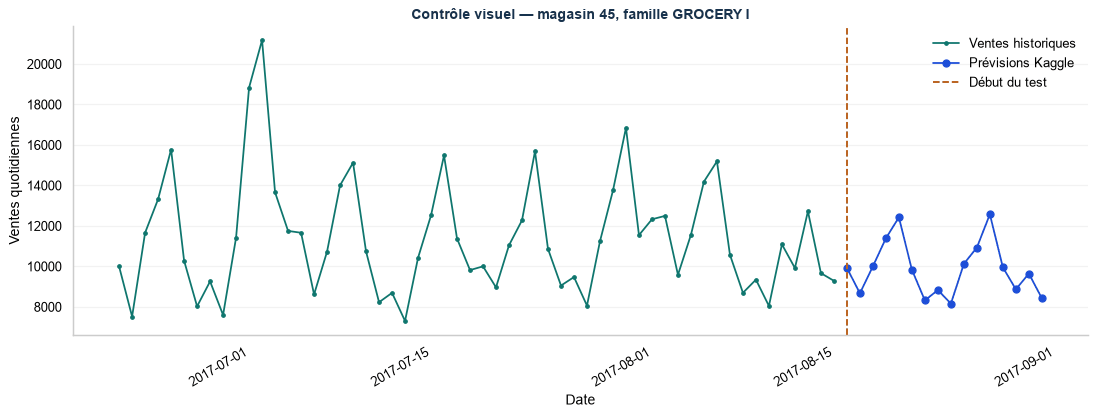

In [67]:
date_fin_train = train["date"].max()
ventes_recentes = train.loc[train["date"].ge(date_fin_train - pd.Timedelta(days=27))]
serie_volume = ventes_recentes.groupby(CLES_SERIE, observed=True)["sales"].sum().sort_values(ascending=False)
magasin_exemple, famille_exemple = serie_volume.index[0]
historique_exemple = train.loc[
    train["store_nbr"].eq(magasin_exemple)
    & train["family"].eq(famille_exemple)
    & train["date"].ge(date_fin_train - pd.Timedelta(days=55))
].sort_values("date")
futur_exemple = test[["id", "date", *CLES_SERIE]].merge(
    soumission, on="id", how="left", validate="one_to_one"
)
futur_exemple = futur_exemple.loc[
    futur_exemple["store_nbr"].eq(magasin_exemple)
    & futur_exemple["family"].eq(famille_exemple)
].sort_values("date")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(historique_exemple["date"], historique_exemple["sales"], color="#0F766E", marker=".", label="Ventes historiques")
ax.plot(futur_exemple["date"], futur_exemple["sales"], color="#1D4ED8", marker="o", label="Prévisions Kaggle")
ax.axvline(test["date"].min(), color="#B45309", linestyle="--", label="Début du test")
ax.set_title(f"Contrôle visuel — magasin {magasin_exemple}, famille {famille_exemple}", color=BLEU, fontweight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Ventes quotidiennes")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


<h3 style="color:#2563EB; font-weight:700;">21.6. Historique des soumissions acceptées</h3>

Ces scores sont ceux attribués par Kaggle aux soumissions déjà acceptées. Le calcul ci-dessus n’ajoute pas une nouvelle soumission et ne garantit pas automatiquement un nouveau score.


<table style="border-collapse:collapse; width:100%; background-color:#F3F4F6; color:#000000;">
<thead>
<tr>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Version soumise</th>
  <th style="background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">Configuration</th>
  <th  style="text-align:right;background-color:#D1D5DB; color:#000000; font-weight:700; padding:10px 12px; border-bottom:2px solid #9CA3AF;">RMSLE Kaggle</th>
</tr>
</thead>
<tbody>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Première version</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Historique complet et variables avant correction du calendrier</td>
  <td  style="text-align:right;background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">0,60824</td>
</tr>
<tr>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">Deuxième version</td>
  <td style="background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;">365 jours et retards corrigés en jours calendaires</td>
  <td  style="text-align:right;background-color:#F3F4F6; color:#000000; padding:9px 12px; border-bottom:1px solid #CBD5E1;"><strong>0,58880</strong></td>
</tr>
</tbody>
</table>

La diminution est de **0,01944**, soit environ **3,2 %**. Elle concerne la configuration dans son ensemble et ne permet pas d’isoler les effets des différentes corrections. Les scores locaux et Kaggle ne portent pas sur les mêmes périodes ; ils ne sont pas directement comparables.

Pour exporter : activer `EXPORTER_FICHIERS` dans la configuration, puis relancer les cellules d’export. `ECRASER_EXPORTS` reste désactivé par défaut. Les CSV sont des fichiers locaux exclus de Git.

<a id="section-22"></a>

<h2 style="color:#2563EB; font-weight:700;">22. Conclusion et perspectives</h2>

**Question :** Que permettent de conclure les résultats, et quelles améliorations tester ensuite ?

In [68]:
score_final_local = scores_moyens.loc[scores_moyens["méthode"].eq("LightGBM récursif"), "RMSLE"].iloc[0]
score_baseline_local = scores_moyens.loc[scores_moyens["méthode"].eq("Moyenne des 4 semaines par jour"), "RMSLE"].iloc[0]
tableau_bilan = pd.DataFrame([
    ("Données", f"{len(train_clean):,} lignes ; {NB_SERIES:,} séries ; {len(dates_absentes)} dates absentes conservées comme inconnues"),
    ("Baseline, RMSLE local 14 jours", f"{score_baseline_local:.4f}"),
    ("LightGBM, RMSLE local 14 jours", f"{score_final_local:.4f} ; historique {HISTORIQUE_RETENU}"),
    ("Soumission Kaggle déjà acceptée", "0,58880 ; score global attribué par Kaggle"),
    ("Service nominal simulé", f"Baseline {baseline_stock['taux_service']:.1%} ; LightGBM {modele_stock['taux_service']:.1%}"),
    ("CSV final contrôlé", f"{len(soumission):,} lignes ; id,sales ; aucune cible réelle du test disponible"),
], columns=["élément", "résultat / portée"])
afficher_tableau(tableau_bilan)
lecture(f"Le modèle réduit le RMSLE local de {score_baseline_local:.4f} à {score_final_local:.4f}. La simulation compare un compromis entre service et quantités sous des hypothèses données ; elle ne permet pas d’annoncer des économies réelles.")


élément,résultat / portée
Données,"3,000,888 lignes ; 1,782 séries ; 4 dates absentes conservées comme inconnues"
"Baseline, RMSLE local 14 jours",0.4561
"LightGBM, RMSLE local 14 jours",0.4038 ; historique 365 jours
Soumission Kaggle déjà acceptée,"0,58880 ; score global attribué par Kaggle"
Service nominal simulé,Baseline 97.0% ; LightGBM 95.2%
CSV final contrôlé,"28,512 lignes ; id,sales ; aucune cible réelle du test disponible"


**Limites à conserver dans la présentation**

- Les ventes observées ne reconstituent pas une demande non contrainte par les stocks.
- La comparaison locale porte sur quatre plis récents ; la fenêtre choisie a été sélectionnée sur ces validations. Ce résultat n’est pas une estimation indépendante après sélection.
- L’horizon de 16 jours est un contrôle complémentaire sur d’autres dates, pas un réglage à partir du score Kaggle.
- Les promotions futures sont fournies par le concours ; en production, elles exigeraient un plan disponible à l’origine.
- Les importances et associations graphiques ne démontrent pas de causalité.
- Aucune incertitude calibrée, aucun coût réel ni économie réelle n’est estimé ici.

**Pistes d’amélioration à évaluer séparément sur des validations chronologiques**

1. Mesurer l’apport des événements connus à l’avance et des caractéristiques des magasins.
2. Comparer prévision récursive et prévision directe par horizon.
3. Évaluer la stabilité sur d’autres périodes et réserver une période finale distincte après sélection.
4. Calibrer une incertitude de prévision avec des erreurs disponibles avant l’origine.
5. Étudier un stock de sécurité ; confronter ensuite le scénario à des stocks, délais et coûts réels s’ils deviennent disponibles.

**Sources du projet :** [compétition Kaggle Store Sales](https://www.kaggle.com/competitions/store-sales-time-series-forecasting), [instructions d’accès et références](../LIENS.md), [décisions méthodologiques](../DECISIONS.md). Les fichiers bruts et traités sont exclus du dépôt.

---

**Auteur : Abdoulaye KONE**  
*Portfolio Data Science — Prévision des ventes et simulation de stock*